In [15]:

import os
import sys
import subprocess
from pathlib import Path

# --------------------------------------------------
# STEP 1: ENVIRONMENT AND PROJECT INSPECTION
# --------------------------------------------------

PROJECTS = {
    "CMX_Original": Path("/home/cse-sdpl/Downloads/CMX_Original"),
    "CMX_E5": Path("/home/cse-sdpl/Downloads/CMX_E5"),
}

print("=" * 75)
print("STEP 1: CRD-NET ENVIRONMENT INSPECTION")
print("=" * 75)

print("\n[1] Python")
print("Executable:", sys.executable)
print("Version:", sys.version)

print("\n[2] Project directories")
for name, path in PROJECTS.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Contains:")
        for item in sorted(path.iterdir(), key=lambda x: x.name)[:30]:
            suffix = "/" if item.is_dir() else ""
            print("  ", item.name + suffix)

print("\n[3] PyTorch and CUDA")
try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory (GB):",
            round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
        )
except Exception as e:
    print("PyTorch inspection failed:", repr(e))

print("\n[4] NVIDIA GPU status")
try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=15
    )
    print(result.stdout if result.returncode == 0 else result.stderr)
except Exception as e:
    print("nvidia-smi failed:", repr(e))

print("\n[5] Key files")
relative_files = [
    "config.py",
    "train.py",
    "eval.py",
    "builder.py",
    "models",
    "datasets",
]

for project_name, project_path in PROJECTS.items():
    print(f"\n--- {project_name} ---")
    if not project_path.exists():
        continue

    for rel in relative_files:
        path = project_path / rel
        print(f"{rel}: {'EXISTS' if path.exists() else 'MISSING'}")

print("\n[6] E5 checkpoint files")
e5_checkpoint_dir = (
    PROJECTS["CMX_E5"]
    / "log_TDD_mit_b2_e5"
    / "checkpoint"
)

if e5_checkpoint_dir.exists():
    for checkpoint in sorted(e5_checkpoint_dir.glob("*.pth")):
        print(
            checkpoint.name,
            f"{checkpoint.stat().st_size / (1024**2):.2f} MB"
        )
else:
    print("Checkpoint directory not found:", e5_checkpoint_dir)

print("\n" + "=" * 75)
print("STEP 1 COMPLETE")
print("=" * 75)


STEP 1: CRD-NET ENVIRONMENT INSPECTION

[1] Python
Executable: /home/cse-sdpl/miniconda3/envs/cmx/bin/python
Version: 3.10.21 (main, Aug 27 2026, 14:42:07) [GCC 14.3.0]

[2] Project directories

CMX_Original
Path: /home/cse-sdpl/Downloads/CMX_Original
Exists: True
Contains:
   .git/
   .gitignore
   .ipynb_checkpoints/
   .venv/
   CMX_Official_Baseline_Comparison.ipynb
   CMX_Original_Test.ipynb
   LICENSE
   README.md
   SCR_CMX_Development.ipynb
   __pycache__/
   cmx_e0_e1_class_comparison.csv
   cmx_e0_e1_confusion_matrices.npz
   config.py
   dataloader/
   datasets/
   engine/
   eval.ipynb
   eval.py
   eval.py.bak
   log_TDD_mit_b2/
   models/
   official_checkpoints/
   predictions_E0_test/
   predictions_E0_test_color/
   predictions_E0_train/
   predictions_E0_train_color/
   predictions_E0_val/
   predictions_E0_val_color/
   predictions_TDD_epoch100/
   predictions_TDD_epoch100_color/

CMX_E5
Path: /home/cse-sdpl/Downloads/CMX_E5
Exists: True
Contains:
   .gitignore
   .i

In [16]:

from pathlib import Path
import re

# --------------------------------------------------
# STEP 2: INSPECT E5 ARCHITECTURE AND CODE STRUCTURE
# --------------------------------------------------

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

print("=" * 80)
print("STEP 2: E5 ARCHITECTURE AND CRD-NET INSPECTION")
print("=" * 80)

# 1. Important configuration values
print("\n[1] CONFIGURATION")
config_path = ROOT / "config.py"

if config_path.exists():
    lines = config_path.read_text(errors="replace").splitlines()

    keywords = [
        "backbone", "num_classes", "image_height", "image_width",
        "batch_size", "lr =", "weight_decay", "nepochs",
        "niters_per_epoch", "dataset", "data_dir", "train_source",
        "eval_source", "counterfactual", "reliability", "pretrained"
    ]

    for i, line in enumerate(lines, start=1):
        if any(k in line.lower() for k in keywords):
            print(f"{i:4}: {line[:220]}")
else:
    print("config.py not found")

# 2. Model files
print("\n[2] MODEL FILES")

for folder in ["models", "engine", "dataloader"]:
    base = ROOT / folder
    print(f"\n{folder}/")

    if not base.exists():
        print("  Directory missing")
        continue

    files = sorted(
        p for p in base.rglob("*")
        if p.is_file() and "__pycache__" not in str(p)
    )

    for p in files[:100]:
        print(" ", p.relative_to(ROOT))

    if len(files) > 100:
        print(f"  ... plus {len(files) - 100} more files")

# 3. Find model classes and CRD-related definitions
print("\n[3] MODEL CLASSES AND CRD-RELATED SYMBOLS")

search_terms = [
    r"^\s*class\s+",
    r"CRD",
    r"counterfactual",
    r"reliability",
    r"FeatureRectifyModule",
    r"FeatureFusionModule",
    r"def build",
    r"def get_model",
]

search_dirs = ["models", "engine", "dataloader"]
matched_files = 0

for folder in search_dirs:
    base = ROOT / folder
    if not base.exists():
        continue

    for path in sorted(base.rglob("*.py")):
        if "__pycache__" in str(path):
            continue

        try:
            file_lines = path.read_text(errors="replace").splitlines()
        except Exception:
            continue

        matches = []
        for i, line in enumerate(file_lines, start=1):
            if any(re.search(pattern, line, re.IGNORECASE)
                   for pattern in search_terms):
                matches.append((i, line.strip()))

        if matches:
            matched_files += 1
            print(f"\n--- {path.relative_to(ROOT)} ---")
            for line_no, content in matches[:30]:
                print(f"{line_no:4}: {content[:200]}")
            if len(matches) > 30:
                print(f"  ... {len(matches) - 30} additional matches")

# 4. Training entry-point imports and model construction
print("\n[4] TRAIN.PY IMPORTANT LINES")

train_path = ROOT / "train.py"

if train_path.exists():
    train_lines = train_path.read_text(errors="replace").splitlines()

    patterns = [
        r"^import ",
        r"^from ",
        r"builder",
        r"model\s*=",
        r"DataLoader",
        r"get_model",
        r"build_model",
        r"optimizer",
        r"load_state_dict",
        r"checkpoint",
        r"train_one_epoch",
        r"criterion",
    ]

    for i, line in enumerate(train_lines, start=1):
        if any(re.search(pattern, line, re.IGNORECASE)
               for pattern in patterns):
            print(f"{i:4}: {line[:220]}")
else:
    print("train.py not found")

# 5. Existing CRD notebook presence
print("\n[5] EXISTING CRD NOTEBOOKS")

for path in sorted(ROOT.glob("*CRD*.ipynb")):
    print(path.name, f"({path.stat().st_size / 1024:.1f} KB)")

# 6. Dataset configuration clues
print("\n[6] DATASET PATHS IN CONFIGURATION")

if config_path.exists():
    for i, line in enumerate(lines, start=1):
        if re.search(r"dataset|data_dir|train_source|eval_source|test_source|TDD",
                     line, re.IGNORECASE):
            print(f"{i:4}: {line[:220]}")

print("\n" + "=" * 80)
print("STEP 2 COMPLETE")
print("Matched model files:", matched_files)
print("No files were modified and no training was started.")
print("=" * 80)


STEP 2: E5 ARCHITECTURE AND CRD-NET INSPECTION

[1] CONFIGURATION
  23: # DATASET CONFIGURATION: TDD RGB-THERMAL
  25: C.dataset_name = 'TDD'
  26: C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
  38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
  42: # Dataset split files
  43: C.train_source = osp.join(C.dataset_path, 'train.txt')
  44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
  45: C.test_source = osp.join(C.dataset_path, 'test.txt')
  48: # Dataset sizes
  53: C.num_classes = 9
  70: C.image_height = 480
  71: C.image_width = 640
  81: C.backbone = 'mit_b2_e5'
  83: C.pretrained_model = '/home/cse-sdpl/Downloads/CMX_Original/pretrained/segformer/mit_b2.pth'
  91: C.lr = 6e-5
  94: C.weight_decay = 0.01
  98: C.batch_size = 2
  99: C.nepochs = 100
 100: C.niters_per_epoch = C.num_train_imgs // C.batch_size + 1
 138:     'log_

In [17]:

from pathlib import Path
import json
import re

# --------------------------------------------------
# STEP 3: REVIEW EXISTING CRD-NET NOTEBOOK
# --------------------------------------------------

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
NOTEBOOK = ROOT / "CRD_Net_Implementation.ipynb"

print("=" * 80)
print("STEP 3: EXISTING CRD-NET NOTEBOOK REVIEW")
print("=" * 80)

if not NOTEBOOK.exists():
    print("ERROR: Notebook not found:", NOTEBOOK)
else:
    with NOTEBOOK.open("r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])
    print("Notebook:", NOTEBOOK.name)
    print("Total cells:", len(cells))
    print("Code cells:", sum(c.get("cell_type") == "code" for c in cells))
    print("Markdown cells:", sum(c.get("cell_type") == "markdown" for c in cells))

    keywords = re.compile(
        r"CRD|reliability|counterfactual|fusion|contrastive|"
        r"loss|checkpoint|backbone|forward|TODO|FIXME|train|"
        r"architecture|temperature|prototype|distill",
        re.IGNORECASE
    )

    for idx, cell in enumerate(cells):
        cell_type = cell.get("cell_type", "unknown")
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)

        lines = source.splitlines()
        matches = [
            (line_no, line)
            for line_no, line in enumerate(lines, start=1)
            if keywords.search(line)
        ]

        # Show headings and compact summaries of each cell.
        print(f"\n{'-' * 70}")
        print(f"CELL {idx} | Type: {cell_type} | Lines: {len(lines)}")

        if cell_type == "markdown":
            shown = lines[:10]
            for line in shown:
                print(line[:200])
            if len(lines) > 10:
                print(f"... ({len(lines) - 10} more lines)")
        else:
            # Show initial lines plus relevant implementation lines.
            shown_indices = set(range(min(8, len(lines))))
            for line_no, _ in matches[:12]:
                for nearby in range(max(1, line_no - 1),
                                    min(len(lines), line_no + 1) + 1):
                    shown_indices.add(nearby)

            for line_no in sorted(shown_indices)[:35]:
                print(f"{line_no:4}: {lines[line_no - 1][:200]}")

            if len(shown_indices) > 35:
                print("... additional matching lines omitted")

        outputs = cell.get("outputs", [])
        if outputs:
            print("Stored outputs:", len(outputs), "(not executed)")

    print("\n" + "=" * 80)
    print("STEP 3 COMPLETE")
    print("Notebook was read only; no code was executed.")
    print("=" * 80)


STEP 3: EXISTING CRD-NET NOTEBOOK REVIEW
Notebook: CRD_Net_Implementation.ipynb
Total cells: 3
Code cells: 3
Markdown cells: 0

----------------------------------------------------------------------
CELL 0 | Type: code | Lines: 101
   0: print("=" * 75)
   1: 
   2: import os
   3: import sys
   4: import subprocess
   5: from pathlib import Path
   6: 
   7: # --------------------------------------------------
  16: print("=" * 75)
  17: print("STEP 1: CRD-NET ENVIRONMENT INSPECTION")
  18: print("=" * 75)
  66:     "config.py",
  67:     "train.py",
  68:     "eval.py",
  82: 
  83: print("\n[6] E5 checkpoint files")
  84: e5_checkpoint_dir = (
  85:     PROJECTS["CMX_E5"]
  86:     / "log_TDD_mit_b2_e5"
  87:     / "checkpoint"
  88: )
  89: 
  90: if e5_checkpoint_dir.exists():
  91:     for checkpoint in sorted(e5_checkpoint_dir.glob("*.pth")):
  92:         print(
  93:             checkpoint.name,
  94:             f"{checkpoint.stat().st_size / (1024**2):.2f} MB"
  95:         

In [18]:

from pathlib import Path

# --------------------------------------------------
# STEP 4: INSPECT E5 MODEL BUILDING AND FORWARD PASS
# --------------------------------------------------

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

FILES = {
    "MODEL BUILDER": (
        ROOT / "models" / "builder.py",
        [(1, 155), (330, 375)]
    ),
    "E5 ENCODER": (
        ROOT / "models" / "encoders" / "dual_segformer_e5.py",
        [(220, 280), (340, 465), (485, 535)]
    ),
    "E5 RELIABILITY MODULES": (
        ROOT / "models" / "net_utils_e5.py",
        [(1, 110)]
    ),
    "E3 FUSION MODULE USED BY E5": (
        ROOT / "models" / "net_utils_e3.py",
        [(1, 100)]
    ),
}

print("=" * 80)
print("STEP 4: E5 MODEL CONSTRUCTION INSPECTION")
print("=" * 80)

for title, (path, ranges) in FILES.items():
    print(f"\n\n{'=' * 30} {title} {'=' * 30}")
    print("File:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    lines = path.read_text(errors="replace").splitlines()

    for start, end in ranges:
        if start > len(lines):
            continue

        actual_end = min(end, len(lines))
        print(f"\n--- Lines {start}-{actual_end} ---")

        for line_number in range(start, actual_end + 1):
            print(f"{line_number:4}: {lines[line_number - 1]}")

print("\n\n" + "=" * 80)
print("STEP 4 COMPLETE")
print("Read-only inspection: no checkpoint loaded, no training started.")
print("=" * 80)


STEP 4: E5 MODEL CONSTRUCTION INSPECTION


============================== MODEL BUILDER ==============================
File: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py
Exists: True

--- Lines 1-155 ---
   1: import torch
   2: import torch.nn as nn
   3: import torch.nn.functional as F
   4: 
   5: from utils.init_func import init_weight
   6: from utils.load_utils import load_pretrain
   7: from functools import partial
   8: 
   9: from engine.logger import get_logger
  10: 
  11: logger = get_logger()
  12: 
  13: class EncoderDecoder(nn.Module):
  14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
  15:         super(EncoderDecoder, self).__init__()
  16:         self.channels = [64, 128, 320, 512]
  17:         self.norm_layer = norm_layer
  18:         # import backbone and decoder
  19:         if cfg.backbone == 'swin_s':
  20:             logger.info('Using backbone: Swin-Transformer-small'

In [19]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

def show_section(title, path, start, end):
    file_path = ROOT / path
    print("\n" + "=" * 90)
    print(f"{title}\nFile: {file_path}\nExists: {file_path.exists()}")
    print("=" * 90)

    if not file_path.exists():
        return

    lines = file_path.read_text(errors="replace").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

# 1. Counterfactual corruption, reliability loss, and forward logic
show_section(
    "E5 COUNTERFACTUAL LOSS",
    "models/builder.py",
    145,
    367
)

# 2. Locate E5's FRM/FFM construction and module wiring
encoder_path = ROOT / "models/encoders/dual_segformer_e5.py"
print("\n" + "=" * 90)
print("E5 MODULE CONSTRUCTION LOCATIONS")
print("=" * 90)

if encoder_path.exists():
    lines = encoder_path.read_text(errors="replace").splitlines()
    patterns = re.compile(
        r"FRMs|FFMs|ReliabilityGatedFeatureRectifyModule|"
        r"ReliabilityGuidedFusionModule|last_reliabilities|"
        r"net_utils_e[345]"
    )
    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if patterns.search(line)
    ]
    for line_no, line in matches:
        print(f"{line_no:4}: {line}")

# 3. Inspect training checkpoint loading and saving
train_path = ROOT / "train.py"
print("\n" + "=" * 90)
print(f"TRAIN.PY CHECKPOINT REFERENCES\nFile: {train_path}\nExists: {train_path.exists()}")
print("=" * 90)

if train_path.exists():
    lines = train_path.read_text(errors="replace").splitlines()
    pattern = re.compile(
        r"resume|checkpoint|load_state_dict|state_dict|torch\.load|"
        r"torch\.save|pretrained|epoch"
    )
    matching_lines = [
        i for i, line in enumerate(lines)
        if pattern.search(line)
    ]

    shown = set()
    for i in matching_lines:
        # Show a small context around each match, without repeating lines.
        for j in range(max(0, i - 2), min(len(lines), i + 3)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        print("-" * 45)

# 4. Print relevant E5 configuration values
show_section(
    "E5 CONFIGURATION",
    "config.py",
    45,
    135
)

print("\n" + "=" * 90)
print("STEP 5 INSPECTION COMPLETE")
print("Read-only inspection only: no checkpoint loaded, no training started.")
print("=" * 90)



E5 COUNTERFACTUAL LOSS
File: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py
Exists: True
 145:             aux_fm = self.aux_head(x[self.aux_index])
 146:             aux_fm = F.interpolate(aux_fm, size=orisize[2:], mode='bilinear', align_corners=False)
 147:             return out, aux_fm
 148:         return out
 149: 
 150:     def _e5_corrupt_modality(self, image):
 151:         """Mask one random rectangle per image after normalization."""
 152:         import math
 153: 
 154:         batch, channels, height, width = image.shape
 155:         fraction = min(max(self.e5_corruption_fraction, 0.01), 0.90)
 156:         block_h = max(1, min(height, int(height * math.sqrt(fraction))))
 157:         block_w = max(1, min(width, int(width * math.sqrt(fraction))))
 158: 
 159:         corrupted = image.clone()
 160:         for b in range(batch):
 161:             y0 = int(torch.randint(
 162:                 0, height - block_h + 1, (1,), device=image.device
 163:             ).item(

In [20]:

from pathlib import Path
import gc
import torch

CHECKPOINTS = {
    "E4": Path(
        "/home/cse-sdpl/Downloads/CMX_E4/"
        "log_TDD_mit_b2_e4/checkpoint/epoch-100.pth"
    ),
    "E5": Path(
        "/home/cse-sdpl/Downloads/CMX_E5/"
        "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
    ),
}

def inspect_checkpoint(name, path):
    print("\n" + "=" * 80)
    print(f"{name} CHECKPOINT")
    print(f"Path: {path}")
    print(f"Exists: {path.exists()}")

    if not path.exists():
        return None

    print(f"Size: {path.stat().st_size / (1024**3):.3f} GiB")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print(f"Top-level type: {type(checkpoint).__name__}")

        if isinstance(checkpoint, dict):
            print(f"Top-level keys: {list(checkpoint.keys())[:30]}")

            state = checkpoint.get("model", checkpoint.get("state_dict"))

            if state is None and checkpoint and all(
                isinstance(v, torch.Tensor) for v in checkpoint.values()
            ):
                state = checkpoint

            if state is not None:
                keys = {
                    k: tuple(v.shape)
                    for k, v in state.items()
                    if isinstance(v, torch.Tensor)
                }
                print(f"Model tensor count: {len(keys)}")
                print("First 12 model tensors:")
                for key in list(keys)[:12]:
                    print(f"  {key}: {keys[key]}")

                result = {
                    "keys": keys,
                    "metadata": {
                        k: v for k, v in checkpoint.items()
                        if k != "model" and k != "state_dict"
                        and not isinstance(v, torch.Tensor)
                        and isinstance(v, (int, float, str, bool, type(None)))
                    }
                }
                print(f"Simple metadata: {result['metadata']}")
            else:
                print("WARNING: Could not identify a model state dictionary.")
                result = None
        else:
            result = None

        del checkpoint
        gc.collect()
        return result

    except Exception as exc:
        print(f"CHECKPOINT INSPECTION ERROR: {type(exc).__name__}: {exc}")
        gc.collect()
        return None

results = {}
for name, path in CHECKPOINTS.items():
    results[name] = inspect_checkpoint(name, path)

print("\n" + "=" * 80)
print("E4 vs E5 CHECKPOINT COMPATIBILITY")
print("=" * 80)

e4 = results.get("E4")
e5 = results.get("E5")

if e4 is None or e5 is None:
    print("Comparison unavailable: one or both checkpoints could not be inspected.")
else:
    k4 = e4["keys"]
    k5 = e5["keys"]

    only_e4 = sorted(set(k4) - set(k5))
    only_e5 = sorted(set(k5) - set(k4))
    common = set(k4) & set(k5)
    shape_mismatches = sorted(
        (key, k4[key], k5[key])
        for key in common if k4[key] != k5[key]
    )

    print(f"E4 tensor keys: {len(k4)}")
    print(f"E5 tensor keys: {len(k5)}")
    print(f"Common tensor keys: {len(common)}")
    print(f"Keys only in E4: {len(only_e4)}")
    print(f"Keys only in E5: {len(only_e5)}")
    print(f"Common keys with shape mismatch: {len(shape_mismatches)}")

    if only_e4:
        print("\nFirst E4-only keys:")
        for key in only_e4[:20]:
            print(f"  {key}")

    if only_e5:
        print("\nFirst E5-only keys:")
        for key in only_e5[:20]:
            print(f"  {key}")

    if shape_mismatches:
        print("\nFirst shape mismatches:")
        for key, shape4, shape5 in shape_mismatches[:20]:
            print(f"  {key}: E4={shape4}, E5={shape5}")

    if not only_e4 and not only_e5 and not shape_mismatches:
        print("All model tensor names and shapes match.")
    else:
        print("Differences identified; do not assume strict loading is compatible.")

print("\nInspection complete. No model was instantiated and no files were modified.")



E4 CHECKPOINT
Path: /home/cse-sdpl/Downloads/CMX_E4/log_TDD_mit_b2_e4/checkpoint/epoch-100.pth
Exists: True
Size: 0.747 GiB
Top-level type: dict
Top-level keys: ['model', 'optimizer', 'epoch', 'iteration']
Model tensor count: 869
First 12 model tensors:
  backbone.patch_embed1.proj.weight: (64, 3, 7, 7)
  backbone.patch_embed1.proj.bias: (64,)
  backbone.patch_embed1.norm.weight: (64,)
  backbone.patch_embed1.norm.bias: (64,)
  backbone.patch_embed2.proj.weight: (128, 64, 3, 3)
  backbone.patch_embed2.proj.bias: (128,)
  backbone.patch_embed2.norm.weight: (128,)
  backbone.patch_embed2.norm.bias: (128,)
  backbone.patch_embed3.proj.weight: (320, 128, 3, 3)
  backbone.patch_embed3.proj.bias: (320,)
  backbone.patch_embed3.norm.weight: (320,)
  backbone.patch_embed3.norm.bias: (320,)
Simple metadata: {'epoch': 100, 'iteration': 784}

E5 CHECKPOINT
Path: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
Exists: True
Size: 0.747 GiB
Top-level type: dict
Top-level 

In [21]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

def inspect_matches(path, patterns, context=3, max_sections=35):
    print(f"\nFile: {path}")
    print(f"Exists: {path.exists()}")

    if not path.exists():
        return

    lines = path.read_text(errors="replace").splitlines()
    regex = re.compile(patterns, re.IGNORECASE)
    matches = [i for i, line in enumerate(lines) if regex.search(line)]

    shown = set()
    sections = 0

    for i in matches:
        if sections >= max_sections:
            print("... additional matches omitted ...")
            break

        new_lines = [
            j for j in range(max(0, i - context), min(len(lines), i + context + 1))
            if j not in shown
        ]

        if not new_lines:
            continue

        for j in new_lines:
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)

        print("-" * 50)
        sections += 1

print("=" * 85)
print("STEP 7: EVALUATION PIPELINE INSPECTION")
print("=" * 85)

inspect_matches(
    ROOT / "eval.py",
    r"ArgumentParser|add_argument|checkpoint|torch\.load|load_state_dict|"
    r"dataset|split|test_source|val_source|mean_IoU|freq_IoU|"
    r"mean_pixel_acc|pixel_acc|prediction|argmax|model\.eval|no_grad",
    context=2,
    max_sections=35
)

print("\n" + "=" * 85)
print("DATASET CONFIGURATION")
print("=" * 85)

inspect_matches(
    ROOT / "config.py",
    r"dataset_path|train_source|eval_source|test_source|"
    r"num_eval_imgs|num_train_imgs|num_classes|image_height|image_width|"
    r"eval_crop_size|eval_scale_array|eval_flip|is_test",
    context=1,
    max_sections=20
)

print("\n" + "=" * 85)
print("TEST SPLIT FILE")
print("=" * 85)

config_path = ROOT / "config.py"
if config_path.exists():
    config_text = config_path.read_text(errors="replace")
    match = re.search(r"C\.test_source\s*=\s*([^\n]+)", config_text)

    if match:
        print("Configured test_source:", match.group(1).strip())
    else:
        print("Could not identify test_source in config.py.")

print("\nInspection complete. No inference, training, or file changes performed.")


STEP 7: EVALUATION PIPELINE INSPECTION

File: /home/cse-sdpl/Downloads/CMX_E5/eval.py
Exists: True
  14: from engine.logger import get_logger
  15: from utils.metric import hist_info, compute_score
  16: from dataloader.RGBXDataset import RGBXDataset
  17: from models.builder import EncoderDecoder as segmodel
  18: from dataloader.dataloader import ValPre
--------------------------------------------------
  43: 
  44:         if self.show_image:
  45:             colors = self.dataset.get_class_colors
  46:             image = img
  47:             clean = np.zeros(label.shape)
--------------------------------------------------
  65:             count += 1
  66: 
  67:         iou, mean_IoU, _, freq_IoU, mean_pixel_acc, pixel_acc = compute_score(hist, correct, labeled)
  68:         result_line = print_iou(iou, freq_IoU, mean_pixel_acc, pixel_acc,
  69:                                 dataset.class_names, show_no_back=False)
--------------------------------------------------
  70:     

In [22]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

patterns = re.compile(
    r"class SegEvaluator|def run\(|torch\.load|load_state_dict|"
    r"checkpoint_dir|model\.eval|compute_score|hist_info|"
    r"argmax|interpolate|save_path|strict\s*=",
    re.IGNORECASE
)

candidate_files = [
    ROOT / "eval.py",
    ROOT / "engine" / "evaluator.py",
    ROOT / "engine" / "evaluator_seg.py",
    ROOT / "utils" / "metric.py",
    ROOT / "models" / "builder.py",
]

# Also locate other Python files that define SegEvaluator or load checkpoints.
for folder in [ROOT / "engine", ROOT / "utils"]:
    if folder.exists():
        for path in folder.rglob("*.py"):
            if path not in candidate_files:
                try:
                    content = path.read_text(errors="replace")
                    if re.search(
                        r"class SegEvaluator|torch\.load|load_state_dict",
                        content,
                        re.IGNORECASE
                    ):
                        candidate_files.append(path)
                except OSError:
                    pass

seen = set()

for path in candidate_files:
    if path in seen or not path.exists():
        continue
    seen.add(path)

    lines = path.read_text(errors="replace").splitlines()
    hits = [i for i, line in enumerate(lines) if patterns.search(line)]

    if not hits:
        continue

    print("\n" + "=" * 85)
    print("FILE:", path)
    print("=" * 85)

    shown = set()
    for i in hits:
        for j in range(max(0, i - 4), min(len(lines), i + 6)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        print("-" * 55)

print("\nInspection complete. No model loaded, inference run, or files modified.")



FILE: /home/cse-sdpl/Downloads/CMX_E5/eval.py
  11: from utils.pyt_utils import ensure_dir, link_file, load_model, parse_devices
  12: from utils.visualize import print_iou, show_img
  13: from engine.evaluator import Evaluator
  14: from engine.logger import get_logger
  15: from utils.metric import hist_info, compute_score
  16: from dataloader.RGBXDataset import RGBXDataset
  17: from models.builder import EncoderDecoder as segmodel
  18: from dataloader.dataloader import ValPre
  19: 
  20: logger = get_logger()
-------------------------------------------------------
  21: 
  22: class SegEvaluator(Evaluator):
  23:     def func_per_iteration(self, data, device):
  24:         img = data['data']
  25:         label = data['label']
  26:         modal_x = data['modal_x']
  27:         name = data['fn']
-------------------------------------------------------
  28:         pred = self.sliding_eval_rgbX(img, modal_x, config.eval_crop_size, config.eval_stride_rate, device)
  29:       

In [23]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    ROOT / "engine" / "evaluator.py": [(42, 115), (260, 355)],
    ROOT / "eval.py": [(82, 110)],
    ROOT / "config.py": [(75, 90), (105, 122)],
}

for path, ranges in sections.items():
    print("\n" + "=" * 90)
    print("FILE:", path)
    print("=" * 90)

    if not path.exists():
        print("File not found.")
        continue

    lines = path.read_text(errors="replace").splitlines()

    for start, end in ranges:
        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No checkpoint loaded, inference run, or files modified.")



FILE: /home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py

--- Lines 42-115 ---
  42:     def run(self, model_path, model_indice, log_file, log_file_link):
  43:         """There are four evaluation modes:
  44:             1.only eval a .pth model: -e *.pth
  45:             2.only eval a certain epoch: -e epoch
  46:             3.eval all epochs in a given section: -e start_epoch-end_epoch
  47:             4.eval all epochs from a certain started epoch: -e start_epoch-
  48:             """
  49:         if '.pth' in model_indice:
  50:             models = [model_indice, ]
  51:         elif "-" in model_indice:
  52:             start_epoch = int(model_indice.split("-")[0])
  53:             end_epoch = model_indice.split("-")[1]
  54: 
  55:             models = os.listdir(model_path)
  56:             models.remove("epoch-last.pth")
  57:             sorted_models = [None] * len(models)
  58:             model_idx = [0] * len(models)
  59: 
  60:             for idx, m in enum

In [24]:

from pathlib import Path
import subprocess

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT = ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
PREDICTIONS = ROOT / "predictions_E5_test_baseline_verify"

assert CHECKPOINT.is_file(), f"Checkpoint not found: {CHECKPOINT}"

print("E5 baseline verification")
print("Checkpoint:", CHECKPOINT)
print(f"Checkpoint size: {CHECKPOINT.stat().st_size / (1024**3):.3f} GiB")
print("Split: test")
print("Expected images: 393")
print("Prediction output:", PREDICTIONS)
print("\nStarting evaluation; no training will be performed...\n")

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "eval.py",
    "-e", "100",
    "-d", "0",
    "--split", "test",
    "-p", str(PREDICTIONS),
]

result = subprocess.run(
    command,
    cwd=str(ROOT),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout)
print("\nEvaluation process exit code:", result.returncode)

if result.returncode != 0:
    print("Evaluation failed. Share the output above before proceeding.")
else:
    print("Evaluation command completed. Next, we will verify the prediction count and metrics.")


E5 baseline verification
Checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
Checkpoint size: 0.747 GiB
Split: test
Expected images: 393
Prediction output: /home/cse-sdpl/Downloads/CMX_E5/predictions_E5_test_baseline_verify

Starting evaluation; no training will be performed...

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 15:55:17 using devices 0
24 15:55:17 Using E5: SegFormer-B2 with counterfactual reliability
24 15:55:18 Using MLP Decoder
24 15:55:20 Load Model: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
24 15:55:20 Load model, Time usage:
	IO: 0.662700891494751, initialize parameters: 0.0419154167175293
24 15:55:20 GPU 0 handle 393 data.

  0%|          | 0/393 [

In [25]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
PREDICTIONS = ROOT / "predictions_E5_test_baseline_verify"
TEST_LIST = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt")

print("=" * 75)
print("STEP 11: E5 BASELINE PREDICTION VERIFICATION")
print("=" * 75)

assert PREDICTIONS.is_dir(), f"Prediction directory missing: {PREDICTIONS}"
assert TEST_LIST.is_file(), f"Test split file missing: {TEST_LIST}"

prediction_files = sorted(PREDICTIONS.glob("*.png"))
prediction_names = [p.name for p in prediction_files]

test_lines = [
    line.strip()
    for line in TEST_LIST.read_text(errors="replace").splitlines()
    if line.strip()
]

print("Expected test entries:", len(test_lines))
print("Raw prediction PNGs:", len(prediction_files))
print("Unique prediction filenames:", len(set(prediction_names)))
print("Prediction directory:", PREDICTIONS)

print("\nFirst five prediction filenames:")
for name in prediction_names[:5]:
    print(" ", name)

print("\nFirst five test-list entries:")
for entry in test_lines[:5]:
    print(" ", entry)

print("\nBaseline metrics reproduced:")
print("  mean_IoU       : 58.379%")
print("  freq_IoU       : 96.795%")
print("  mean_pixel_acc : 67.820%")
print("  pixel_acc      : 98.250%")

if len(prediction_files) == 393 and len(set(prediction_names)) == 393:
    print("\nPASS: 393 unique raw prediction masks are present.")
else:
    print("\nCHECK REQUIRED: prediction count or filename uniqueness differs from expectation.")

print("Verification only; no training or file modifications performed.")


STEP 11: E5 BASELINE PREDICTION VERIFICATION
Expected test entries: 393
Raw prediction PNGs: 393
Unique prediction filenames: 393
Prediction directory: /home/cse-sdpl/Downloads/CMX_E5/predictions_E5_test_baseline_verify

First five prediction filenames:
  01189N.png
  01190N.png
  01191N.png
  01192N.png
  01193N.png

First five test-list entries:
  01402D
  01403D
  01404D
  01405D
  01406D

Baseline metrics reproduced:
  mean_IoU       : 58.379%
  freq_IoU       : 96.795%
  mean_pixel_acc : 67.820%
  pixel_acc      : 98.250%

PASS: 393 unique raw prediction masks are present.
Verification only; no training or file modifications performed.


In [26]:

from pathlib import Path
import re

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
DATASET = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
PREDICTIONS = ROOT / "predictions_E5_test_baseline_verify"
LOADER = ROOT / "dataloader" / "RGBXDataset.py"

print("=" * 75)
print("STEP 12: TEST ID AND PREDICTION FILENAME MAPPING")
print("=" * 75)

test_ids = [
    line.strip()
    for line in (DATASET / "test.txt").read_text(errors="replace").splitlines()
    if line.strip()
]

pred_names = sorted(p.stem for p in PREDICTIONS.glob("*.png"))

# Compare the ID sets directly.
test_set = set(test_ids)
pred_set = set(pred_names)

print("Test-list entries:", len(test_ids))
print("Unique test-list IDs:", len(test_set))
print("Prediction stems:", len(pred_names))
print("Unique prediction stems:", len(pred_set))
print("Exact filename-set match:", test_set == pred_set)
print("Test IDs without a matching prediction:", len(test_set - pred_set))
print("Prediction stems not present in test list:", len(pred_set - test_set))

print("\nExamples of test IDs without matching predictions:")
for name in sorted(test_set - pred_set)[:10]:
    print(" ", name)

print("\nExamples of prediction stems absent from test list:")
for name in sorted(pred_set - test_set)[:10]:
    print(" ", name)

print("\n" + "=" * 75)
print("DATASET LOADER FILENAME LOGIC")
print("=" * 75)

if LOADER.is_file():
    lines = LOADER.read_text(errors="replace").splitlines()
    pattern = re.compile(
        r"def __init__|def __getitem__|test_source|eval_source|"
        r"train_source|split|self\.files|self\.fn|['\"]fn['\"]|"
        r"basename|splitext|readlines|line\.split",
        re.IGNORECASE,
    )

    shown = set()
    for i, line in enumerate(lines):
        if pattern.search(line):
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)
            print("-" * 45)
else:
    print("Dataset loader not found:", LOADER)

print("\nRead-only check complete. No inference, training, or file changes.")


STEP 12: TEST ID AND PREDICTION FILENAME MAPPING
Test-list entries: 393
Unique test-list IDs: 393
Prediction stems: 393
Unique prediction stems: 393
Exact filename-set match: True
Test IDs without a matching prediction: 0
Prediction stems not present in test list: 0

Examples of test IDs without matching predictions:

Examples of prediction stems absent from test list:

DATASET LOADER FILENAME LOGIC
   9: 
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  12:         super(RGBXDataset, self).__init__()
  13:         self._split_name = split_name
  14:         self._rgb_path = setting['rgb_root']
---------------------------------------------
  15:         self._rgb_format = setting['rgb_format']
  16:         self._gt_path = setting['gt_root']
---------------------------------------------
  20:         self._x_format = setting['x_format']
  21:         self._x_single_channel = setting['x_single_channel']
  22: 

In [27]:

from pathlib import Path
import hashlib
import json
import subprocess
import sys

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
ORIGINAL_ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
PREDICTIONS = E5_ROOT / "predictions_E5_test_baseline_verify"

FILES_TO_FINGERPRINT = [
    E5_ROOT / "config.py",
    E5_ROOT / "eval.py",
    E5_ROOT / "train.py",
    E5_ROOT / "models/builder.py",
    E5_ROOT / "models/encoders/dual_segformer_e5.py",
    E5_ROOT / "models/net_utils_e5.py",
    E5_ROOT / "models/net_utils_e3.py",
    E5_ROOT / "dataloader/RGBXDataset.py",
    ORIGINAL_ROOT / "datasets/TDD/train.txt",
    ORIGINAL_ROOT / "datasets/TDD/val.txt",
    ORIGINAL_ROOT / "datasets/TDD/test.txt",
]

def sha256_file(path, chunk_size=8 * 1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("=" * 75)
print("STEP 13: READ-ONLY E5 BASELINE FINGERPRINT")
print("=" * 75)

assert CHECKPOINT.is_file(), f"Checkpoint missing: {CHECKPOINT}"
assert PREDICTIONS.is_dir(), f"Predictions missing: {PREDICTIONS}"

print("\nCHECKPOINT")
print("Path:", CHECKPOINT)
print("Size (MiB):", round(CHECKPOINT.stat().st_size / (1024**2), 2))
print("SHA-256:", sha256_file(CHECKPOINT))

print("\nSOURCE AND DATASET FILES")
for path in FILES_TO_FINGERPRINT:
    if path.is_file():
        print(f"\n{path}")
        print("  Size (bytes):", path.stat().st_size)
        print("  SHA-256:", sha256_file(path))
    else:
        print(f"\nMISSING: {path}")

prediction_files = sorted(PREDICTIONS.glob("*.png"))
names_digest = hashlib.sha256()
for path in prediction_files:
    names_digest.update(path.name.encode("utf-8"))
    names_digest.update(b"\n")

print("\nPREDICTION DIRECTORY")
print("PNG count:", len(prediction_files))
print("Filename-list SHA-256:", names_digest.hexdigest())

print("\nBASELINE METRICS")
print(json.dumps({
    "mean_IoU_percent": 58.379,
    "freq_IoU_percent": 96.795,
    "mean_pixel_acc_percent": 67.820,
    "pixel_acc_percent": 98.250,
}, indent=2))

print("\nFingerprinting complete. No files were written or modified.")


STEP 13: READ-ONLY E5 BASELINE FINGERPRINT

CHECKPOINT
Path: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
Size (MiB): 764.97
SHA-256: 67f328ca00ad5db43a754180dcef6e78a0912c75ff06f45d60513248772d9265

SOURCE AND DATASET FILES

/home/cse-sdpl/Downloads/CMX_E5/config.py
  Size (bytes): 5051
  SHA-256: be42c9a9eefe410e33dce1e4979f8cfdf2289e6bee5dc859f8ee27ff44732dba

/home/cse-sdpl/Downloads/CMX_E5/eval.py
  Size (bytes): 4342
  SHA-256: bce4d01b5193c298157b57dd78207a302ae90b713d0de4e17e35eecf331e5f70

/home/cse-sdpl/Downloads/CMX_E5/train.py
  Size (bytes): 12521
  SHA-256: eb15665e91adacc2ea7276048f1c0922b08481afc0cf76ba31aa2d94c802d232

/home/cse-sdpl/Downloads/CMX_E5/models/builder.py
  Size (bytes): 14811
  SHA-256: fd2d40d225ed0bd90732cf40e4298164cc143a0e8e55f303f85da0def0ca4201

/home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py
  Size (bytes): 22237
  SHA-256: bbf8456a19300176012f14bdb362afd3b29ccde6a6de4c039ab70cbb2f2858e2

/home/cse

In [28]:

from pathlib import Path
import shutil

BASE = Path("/home/cse-sdpl/Downloads")
E5_ROOT = BASE / "CMX_E5"
CRD_ROOT = BASE / "CRD_Net"
NOTEBOOK_CANDIDATES = [
    BASE / "CRD_Net_Implementation.ipynb",
    E5_ROOT / "CRD_Net_Implementation.ipynb",
    Path.cwd() / "CRD_Net_Implementation.ipynb",
]

print("=" * 75)
print("STEP 14: ISOLATED CRD-NET WORKSPACE CHECK")
print("=" * 75)

print("\nE5 baseline:")
print("Directory exists:", E5_ROOT.is_dir())
print("Checkpoint exists:", (
    E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
).is_file())

print("\nProposed isolated workspace:")
print("Path:", CRD_ROOT)
print("Already exists:", CRD_ROOT.exists())

if CRD_ROOT.is_dir():
    print("\nExisting workspace contents (first 40 entries):")
    entries = sorted(CRD_ROOT.iterdir(), key=lambda p: p.name.lower())
    for item in entries[:40]:
        print(" ", "[DIR]" if item.is_dir() else "[FILE]", item.name)
    if len(entries) > 40:
        print(" ...", len(entries) - 40, "additional entries")
else:
    print("No CRD_Net directory exists at the proposed path.")

print("\nImplementation notebook candidates:")
found_notebook = False
for path in NOTEBOOK_CANDIDATES:
    if path.is_file():
        found_notebook = True
        print("FOUND:", path, f"({path.stat().st_size:,} bytes)")
if not found_notebook:
    print("No notebook found at the checked locations.")

usage = shutil.disk_usage(BASE)
print("\nDisk space for", BASE)
print("Total GiB:", round(usage.total / (1024**3), 2))
print("Used GiB:", round((usage.total - usage.free) / (1024**3), 2))
print("Free GiB:", round(usage.free / (1024**3), 2))

print("\nRead-only check complete. No files changed.")


STEP 14: ISOLATED CRD-NET WORKSPACE CHECK

E5 baseline:
Directory exists: True
Checkpoint exists: True

Proposed isolated workspace:
Path: /home/cse-sdpl/Downloads/CRD_Net
Already exists: True

Existing workspace contents (first 40 entries):
  [DIR] checkpoints
  [DIR] configs
  [DIR] logs
  [DIR] models
  [DIR] predictions
  [DIR] reliability_maps
  [DIR] scripts
  [DIR] visualizations

Implementation notebook candidates:
FOUND: /home/cse-sdpl/Downloads/CMX_E5/CRD_Net_Implementation.ipynb (248,716 bytes)

Disk space for /home/cse-sdpl/Downloads
Total GiB: 437.93
Used GiB: 414.89
Free GiB: 23.04

Read-only check complete. No files changed.


In [29]:

from pathlib import Path
import json

BASE = Path("/home/cse-sdpl/Downloads")
CRD_ROOT = BASE / "CRD_Net"
NOTEBOOK = Path("/home/cse-sdpl/Downloads/CMX_E5/CRD_Net_Implementation.ipynb")

print("=" * 75)
print("STEP 15A: EXISTING CRD-NET FILE INVENTORY")
print("=" * 75)

all_files = sorted(
    (p for p in CRD_ROOT.rglob("*") if p.is_file()),
    key=lambda p: str(p).lower()
)

print("Total files:", len(all_files))
total_bytes = sum(p.stat().st_size for p in all_files)
print("Total existing file size (MiB):", round(total_bytes / (1024**2), 2))

for path in all_files:
    relative = path.relative_to(CRD_ROOT)
    size_mib = path.stat().st_size / (1024**2)
    print(f"{relative} | {size_mib:.2f} MiB")

print("\n" + "=" * 75)
print("STEP 15B: NOTEBOOK STRUCTURE")
print("=" * 75)

if not NOTEBOOK.is_file():
    print("Notebook not found:", NOTEBOOK)
else:
    with NOTEBOOK.open("r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])
    print("Notebook:", NOTEBOOK)
    print("Notebook format:", notebook.get("nbformat"), notebook.get("nbformat_minor"))
    print("Total cells:", len(cells))

    for index, cell in enumerate(cells):
        cell_type = cell.get("cell_type", "unknown")
        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        print(f"\n--- Cell {index} | type={cell_type} | lines={len(lines)} ---")
        for line in lines[:12]:
            print(line[:220])
        if len(lines) > 12:
            print(f"... ({len(lines) - 12} more lines)")

        if cell_type == "code":
            outputs = cell.get("outputs", [])
            print("Execution count:", cell.get("execution_count"))
            print("Stored outputs:", len(outputs))

print("\n" + "=" * 75)
print("Read-only inspection complete. No files changed.")


STEP 15A: EXISTING CRD-NET FILE INVENTORY
Total files: 0
Total existing file size (MiB): 0.0

STEP 15B: NOTEBOOK STRUCTURE
Notebook: /home/cse-sdpl/Downloads/CMX_E5/CRD_Net_Implementation.ipynb
Notebook format: 4 5
Total cells: 15

--- Cell 0 | type=code | lines=101 ---

import os
import sys
import subprocess
from pathlib import Path

# --------------------------------------------------
# STEP 1: ENVIRONMENT AND PROJECT INSPECTION
# --------------------------------------------------

PROJECTS = {
    "CMX_Original": Path("/home/cse-sdpl/Downloads/CMX_Original"),
... (89 more lines)
Execution count: 15
Stored outputs: 1

--- Cell 1 | type=code | lines=151 ---

from pathlib import Path
import re

# --------------------------------------------------
# STEP 2: INSPECT E5 ARCHITECTURE AND CODE STRUCTURE
# --------------------------------------------------

ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

print("=" * 80)
print("STEP 2: E5 ARCHITECTURE AND CRD-NET INSPECTION")
... (139 more li

In [30]:

from pathlib import Path
import json

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CONFIG_DIR = CRD_ROOT / "configs"
DESIGN_FILE = CONFIG_DIR / "crd_net_design.json"

assert CRD_ROOT.is_dir(), f"CRD-Net workspace missing: {CRD_ROOT}"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

if DESIGN_FILE.exists():
    raise FileExistsError(
        f"Refusing to overwrite an existing design file: {DESIGN_FILE}"
    )

design = {
    "project": "CRD-Net",
    "full_name": "Causal Reliability Distillation Network",
    "task": "RGB-Thermal Semantic Segmentation",
    "status": "design_contract",
    "baseline": {
        "project": "CMX_E5",
        "checkpoint": (
            "/home/cse-sdpl/Downloads/CMX_E5/"
            "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
        ),
        "reference_test_mIoU_percent": 58.379,
        "reference_test_pixel_accuracy_percent": 98.250,
        "must_remain_unchanged": True
    },
    "dataset": {
        "name": "TDD",
        "root": "/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD",
        "classes": [
            "unlabeled", "car", "person", "bike", "curve",
            "car_stop", "guardrail", "color_cone", "bump"
        ],
        "num_classes": 9,
        "height": 480,
        "width": 640,
        "train_images": 1568,
        "validation_images": 392,
        "test_images": 393,
        "reuse_existing_splits": True
    },
    "initial_architecture": {
        "rgb_encoder": "SegFormer MiT-B2",
        "thermal_encoder": "SegFormer MiT-B2",
        "counterfactual_views": [
            "clean_rgb_thermal",
            "rgb_perturbed_or_suppressed",
            "thermal_perturbed_or_suppressed"
        ],
        "reliability": "spatial modality reliability distilled from counterfactual prediction changes",
        "fusion": "reliability-controlled cross-modal feature fusion",
        "decoder": "MLP segmentation decoder",
        "output_classes": 9
    },
    "initial_losses": {
        "segmentation": "L_seg",
        "reliability": "L_rel",
        "distillation": "L_distill",
        "total": "L_seg + lambda_r * L_rel + lambda_d * L_distill"
    },
    "deferred_extensions": [
        "class-conditional modality reliability",
        "consistency loss",
        "reliability calibration loss",
        "boundary refinement head"
    ],
    "experimental_rules": [
        "Do not modify E0-E5 source files or checkpoints.",
        "Keep CRD-Net implementation and checkpoints in the isolated CRD_Net workspace.",
        "Verify tensor shapes and gradients before training.",
        "Run a small-batch smoke test before any full training.",
        "Use validation for development and the test split for final comparison.",
        "Compare using the same TDD splits and evaluation protocol as the E5 reference.",
        "Monitor disk space before creating checkpoints or prediction copies."
    ]
}

DESIGN_FILE.write_text(json.dumps(design, indent=2) + "\n", encoding="utf-8")

print("CRD-Net design contract created.")
print("File:", DESIGN_FILE)
print("Architecture:", design["initial_architecture"])
print("Initial losses:", design["initial_losses"])
print("Deferred extensions:", len(design["deferred_extensions"]))
print("E5 baseline checkpoint untouched.")


CRD-Net design contract created.
File: /home/cse-sdpl/Downloads/CRD_Net/configs/crd_net_design.json
Architecture: {'rgb_encoder': 'SegFormer MiT-B2', 'thermal_encoder': 'SegFormer MiT-B2', 'counterfactual_views': ['clean_rgb_thermal', 'rgb_perturbed_or_suppressed', 'thermal_perturbed_or_suppressed'], 'reliability': 'spatial modality reliability distilled from counterfactual prediction changes', 'fusion': 'reliability-controlled cross-modal feature fusion', 'decoder': 'MLP segmentation decoder', 'output_classes': 9}
Initial losses: {'segmentation': 'L_seg', 'reliability': 'L_rel', 'distillation': 'L_distill', 'total': 'L_seg + lambda_r * L_rel + lambda_d * L_distill'}
Deferred extensions: 4
E5 baseline checkpoint untouched.


In [31]:

from pathlib import Path
import subprocess
import textwrap

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
MODELS_DIR = CRD_ROOT / "models"
MODULE_FILE = MODELS_DIR / "reliability_fusion.py"

assert CRD_ROOT.is_dir(), f"Workspace not found: {CRD_ROOT}"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

if MODULE_FILE.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing module: {MODULE_FILE}"
    )

module_source = r'''
import torch
import torch.nn as nn


class ReliabilityGuidedFusion(nn.Module):
    """
    Spatial reliability-guided fusion for paired RGB and thermal features.

    Inputs:
        rgb_features:     [B, C, H, W]
        thermal_features: [B, C, H, W]

    Returns:
        fused_features: [B, C, H, W]
        reliability:    [B, 2, H, W]
                        channel 0 = RGB reliability
                        channel 1 = thermal reliability

    Reliability is normalized across the two modalities at each pixel.
    """

    def __init__(self, channels: int, hidden_channels: int = None):
        super().__init__()

        if channels < 1:
            raise ValueError("channels must be >= 1")

        if hidden_channels is None:
            hidden_channels = max(channels // 4, 16)

        self.channels = channels

        self.reliability_head = nn.Sequential(
            nn.Conv2d(channels * 2, hidden_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(hidden_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_channels, 2, kernel_size=1)
        )

        # Start with equal RGB and thermal reliability at every pixel.
        final_conv = self.reliability_head[-1]
        nn.init.zeros_(final_conv.weight)
        nn.init.zeros_(final_conv.bias)

    def forward(self, rgb_features, thermal_features):
        if rgb_features.ndim != 4 or thermal_features.ndim != 4:
            raise ValueError("Both inputs must have shape [B, C, H, W]")

        if rgb_features.shape != thermal_features.shape:
            raise ValueError(
                "RGB and thermal feature shapes must match; got "
                f"{tuple(rgb_features.shape)} and "
                f"{tuple(thermal_features.shape)}"
            )

        if rgb_features.shape[1] != self.channels:
            raise ValueError(
                f"Expected {self.channels} channels, "
                f"received {rgb_features.shape[1]}"
            )

        joint_features = torch.cat(
            [rgb_features, thermal_features], dim=1
        )

        reliability_logits = self.reliability_head(joint_features)
        reliability = torch.softmax(reliability_logits, dim=1)

        rgb_weight = reliability[:, 0:1]
        thermal_weight = reliability[:, 1:2]

        fused_features = (
            rgb_weight * rgb_features
            + thermal_weight * thermal_features
        )

        return fused_features, reliability
'''

MODULE_FILE.write_text(
    textwrap.dedent(module_source).lstrip(),
    encoding="utf-8"
)

print("Created module:", MODULE_FILE)
print("Running isolated shape and gradient tests with conda environment 'cmx'...")

test_code = r'''
import torch
from models.reliability_fusion import ReliabilityGuidedFusion

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size, channels, height, width = 2, 64, 32, 40

model = ReliabilityGuidedFusion(channels=channels).to(device)
rgb = torch.randn(
    batch_size, channels, height, width,
    device=device, requires_grad=True
)
thermal = torch.randn(
    batch_size, channels, height, width,
    device=device, requires_grad=True
)

fused, reliability = model(rgb, thermal)

assert fused.shape == (batch_size, channels, height, width)
assert reliability.shape == (batch_size, 2, height, width)
assert torch.isfinite(fused).all()
assert torch.isfinite(reliability).all()
assert torch.allclose(
    reliability.sum(dim=1),
    torch.ones_like(reliability[:, 0]),
    atol=1e-6
)
assert torch.allclose(
    reliability[:, 0],
    torch.full_like(reliability[:, 0], 0.5),
    atol=1e-6
)

loss = fused.square().mean()
loss.backward()

assert rgb.grad is not None and torch.isfinite(rgb.grad).all()
assert thermal.grad is not None and torch.isfinite(thermal.grad).all()

trainable_grads = [
    p.grad for p in model.parameters()
    if p.requires_grad and p.grad is not None
]
assert trainable_grads, "No gradients reached module parameters"
assert all(torch.isfinite(g).all() for g in trainable_grads)

print("Device:", device)
print("Input shape:", tuple(rgb.shape))
print("Fused shape:", tuple(fused.shape))
print("Reliability shape:", tuple(reliability.shape))
print("Initial mean RGB reliability:", reliability[:, 0].mean().item())
print("Initial mean thermal reliability:", reliability[:, 1].mean().item())
print("Reliability sum min/max:",
      reliability.sum(dim=1).min().item(),
      reliability.sum(dim=1).max().item())
print("Input gradients: PASS")
print("Module parameter gradients: PASS")
print("All module tests: PASS")
'''

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output", "-n", "cmx",
        "python", "-c", test_code
    ],
    cwd=str(CRD_ROOT),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    timeout=120
)

print(result.stdout)
print("Test process exit code:", result.returncode)

if result.returncode != 0:
    print(
        "\nThe module test failed. Keep the output for diagnosis; "
        "do not start training."
    )


Created module: /home/cse-sdpl/Downloads/CRD_Net/models/reliability_fusion.py
Running isolated shape and gradient tests with conda environment 'cmx'...
Device: cuda
Input shape: (2, 64, 32, 40)
Fused shape: (2, 64, 32, 40)
Reliability shape: (2, 2, 32, 40)
Initial mean RGB reliability: 0.5
Initial mean thermal reliability: 0.5
Reliability sum min/max: 1.0 1.0
Input gradients: PASS
Module parameter gradients: PASS
All module tests: PASS

Test process exit code: 0


In [32]:

from pathlib import Path
import re

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

FILES = [
    E5_ROOT / "models/encoders/dual_segformer_e5.py",
    E5_ROOT / "models/builder.py",
    E5_ROOT / "models/net_utils_e5.py",
    CRD_ROOT / "models/reliability_fusion.py",
]

PATTERNS = re.compile(
    r"^\s*class\s+|^\s*def\s+__init__|^\s*def\s+forward|"
    r"self\.channels|self\.embed_dims|embed_dims|"
    r"self\.decode_head|self\.backbone|"
    r"return\s+|reliability_maps|last_reliabilities|"
    r"MLPDecoder|decoder_embed_dim|num_classes|"
    r"feature_strides|in_channels",
    re.IGNORECASE,
)

print("=" * 75)
print("STEP 18: ENCODER / FUSION / DECODER INTERFACE INSPECTION")
print("=" * 75)

for path in FILES:
    print("\n" + "=" * 75)
    print("FILE:", path)
    print("EXISTS:", path.is_file())
    print("=" * 75)

    if not path.is_file():
        continue

    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if PATTERNS.search(line)
    ]

    # Print concise context around matching definitions and interface lines.
    shown = set()
    for i in matches:
        for j in range(max(0, i - 1), min(len(lines), i + 2)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        if len(shown) >= 180:
            print("... output capped for readability ...")
            break

print("\n" + "=" * 75)
print("Read-only inspection complete. No source files modified.")



STEP 18: ENCODER / FUSION / DECODER INTERFACE INSPECTION

FILE: /home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py
EXISTS: True
  15: 
  16: class DWConv(nn.Module):
  17:     """
  19:     """
  20:     def __init__(self, dim=768):
  21:         super(DWConv, self).__init__()
  23: 
  24:     def forward(self, x, H, W):
  25:         B, N, C = x.shape
  29: 
  30:         return x
  31: 
  32: 
  33: class Mlp(nn.Module):
  34:     def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
  35:         super().__init__()
  63: 
  64:     def forward(self, x, H, W):
  65:         x = self.fc1(x)
  70:         x = self.drop(x)
  71:         return x
  72: 
  73: 
  74: class Attention(nn.Module):
  75:     def __init__(self, dim, num_heads=8, qkv_bias=False, qk_scale=None, attn_drop=0., proj_drop=0., sr_ratio=1):
  76:         super().__init__()
 112: 
 113:     def forward(self, x, H, W):
 114:         B, N, C = x.shape
 134

In [33]:

from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    "models/encoders/dual_segformer_e5.py": [
        (350, 455),
        (500, 530),
    ],
    "models/decoders/MLPDecoder.py": [
        (1, 180),
    ],
    "models/builder.py": [
        (13, 110),
        (135, 150),
    ],
    "config.py": [
        (75, 90),
        (100, 125),
    ],
}

for relative_path, ranges in sections.items():
    path = E5 / relative_path
    print("\n" + "=" * 80)
    print("FILE:", path)
    print("EXISTS:", path.is_file())
    print("=" * 80)

    if not path.is_file():
        continue

    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

    for start, end in ranges:
        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")
        for index in range(start - 1, min(end, len(lines))):
            print(f"{index + 1:4}: {lines[index]}")

print("\nRead-only inspection complete. No files modified.")



FILE: /home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py
EXISTS: True

--- Lines 350-455 ---
 350:         if isinstance(pretrained, str):
 351:             load_dualpath_model(self, pretrained)
 352:         else:
 353:             raise TypeError('pretrained must be a str or None')
 354: 
 355:     def forward_features(self, x_rgb, x_e):
 356:         """
 357:         x_rgb: B x N x H x W
 358:         """
 359:         B = x_rgb.shape[0]
 360:         outs = []
 361:         outs_fused = []
 362:         reliability_maps = []
 363: 
 364:         # stage 1
 365:         x_rgb, H, W = self.patch_embed1(x_rgb)
 366:         # B H*W/16 C
 367:         x_e, _, _ = self.extra_patch_embed1(x_e)
 368:         for i, blk in enumerate(self.block1):
 369:             x_rgb = blk(x_rgb, H, W)
 370:         for i, blk in enumerate(self.extra_block1):
 371:             x_e = blk(x_e, H, W)
 372:         x_rgb = self.norm1(x_rgb)
 373:         x_e = self.extra_norm1(x_e)
 374:

In [34]:
from pathlib import Path
import ast
import torch

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT = E5 / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

print("=" * 80)
print("1. CONFIGURATION SYMBOLS")
print("=" * 80)

config_path = E5 / "config.py"
config_tree = ast.parse(config_path.read_text(encoding="utf-8"))

for node in config_tree.body:
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        print(f"{type(node).__name__}: {node.name}")
    elif isinstance(node, ast.Assign):
        names = [
            target.id for target in node.targets
            if isinstance(target, ast.Name)
        ]
        if names:
            print("Assignment:", ", ".join(names))

print("\n" + "=" * 80)
print("2. CHECKPOINT METADATA")
print("=" * 80)

print("Checkpoint exists:", CHECKPOINT.is_file())

if CHECKPOINT.is_file():
    checkpoint = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    print("Top-level type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if isinstance(value, dict):
                print(f"\n{key}: dictionary with {len(value)} entries")
                print("First keys:", list(value.keys())[:12])
            elif isinstance(value, (int, float, str, bool, type(None))):
                print(f"{key}: {value}")
            else:
                print(f"{key}: {type(value).__name__}")

    del checkpoint

print("\n" + "=" * 80)
print("3. MODEL INITIALIZATION AND CHECKPOINT LOADING")
print("=" * 80)

for relative_path in ["models/builder.py", "train.py", "eval.py"]:
    path = E5 / relative_path
    print(f"\n--- {relative_path} ---")

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()

    terms = (
        "EncoderDecoder(",
        "torch.load(",
        "load_state_dict(",
        "pretrained_model",
        "config.py",
        "config import",
        "C.backbone",
    )

    matches = [
        index for index, line in enumerate(lines)
        if any(term in line for term in terms)
    ]

    shown = set()
    for index in matches:
        start = max(0, index - 2)
        end = min(len(lines), index + 4)

        if any(i in shown for i in range(start, end)):
            continue

        for i in range(start, end):
            print(f"{i + 1:4}: {lines[i]}")
            shown.add(i)

print("\nRead-only inspection complete. No files modified.")

1. CONFIGURATION SYMBOLS
Assignment: C
Assignment: config
Assignment: cfg
FunctionDef: add_path
Assignment: exp_time

2. CHECKPOINT METADATA
Checkpoint exists: True
Top-level type: dict
Top-level keys: ['model', 'optimizer', 'epoch', 'iteration']

model: dictionary with 869 entries
First keys: ['backbone.patch_embed1.proj.weight', 'backbone.patch_embed1.proj.bias', 'backbone.patch_embed1.norm.weight', 'backbone.patch_embed1.norm.bias', 'backbone.patch_embed2.proj.weight', 'backbone.patch_embed2.proj.bias', 'backbone.patch_embed2.norm.weight', 'backbone.patch_embed2.norm.bias', 'backbone.patch_embed3.proj.weight', 'backbone.patch_embed3.proj.bias', 'backbone.patch_embed3.norm.weight', 'backbone.patch_embed3.norm.bias']

optimizer: dictionary with 2 entries
First keys: ['state', 'param_groups']
epoch: 100
iteration: 784

3. MODEL INITIALIZATION AND CHECKPOINT LOADING

--- models/builder.py ---
  11: logger = get_logger()
  12: 
  13: class EncoderDecoder(nn.Module):
  14:     def __init_

In [35]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    "models/builder.py": [(105, 135), (136, 160)],
    "train.py": [(45, 90), (95, 140), (150, 190)],
    "config.py": [(1, 35), (125, 155)],
}

for relative_path, ranges in sections.items():
    path = E5 / relative_path

    print("\n" + "=" * 85)
    print("FILE:", path)
    print("=" * 85)

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for start, end in ranges:
        if start > len(lines):
            continue

        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")

        for index in range(start - 1, min(end, len(lines))):
            print(f"{index + 1:4}: {lines[index]}")

print("\nInspection complete. No files modified.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py

--- Lines 105-135 ---
 105:         self.criterion = criterion
 106: 
 107:         # E5-only counterfactual reliability supervision.
 108:         self.e5_counterfactual = (
 109:             getattr(cfg, "backbone", "") == "mit_b2_e5"
 110:         )
 111:         self.e5_reliability_loss_weight = float(
 112:             getattr(cfg, "e5_reliability_loss_weight", 0.1)
 113:         )
 114:         self.e5_corruption_fraction = float(
 115:             getattr(cfg, "e5_corruption_fraction", 0.25)
 116:         )
 117:         self.e5_counterfactual_temperature = max(
 118:             float(getattr(cfg, "e5_counterfactual_temperature", 1.0)),
 119:             1e-6,
 120:         )
 121:         if self.criterion:
 122:             self.init_weights(cfg, pretrained=cfg.pretrained_model)
 123:     
 124:     def init_weights(self, cfg, pretrained=None):
 125:         if pretrained:
 126:             logger.info('Loading pretrai

In [36]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    "models/builder.py": [(190, 285)],
    "eval.py": [(1, 90), (90, 155)],
}

for relative_path, ranges in sections.items():
    path = E5 / relative_path

    print("\n" + "=" * 80)
    print("FILE:", path)
    print("=" * 80)

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for start, end in ranges:
        if start > len(lines):
            continue

        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")

        for index in range(start - 1, min(end, len(lines))):
            print(f"{index + 1:4}: {lines[index]}")

print("\nRead-only inspection complete. No files modified.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py

--- Lines 190-285 ---
 190:                     rgb_logits = rgb_logits[0]
 191: 
 192:                 thermal_logits = self.encode_decode(
 193:                     rgb, self._e5_corrupt_modality(modal_x)
 194:                 )
 195:                 if isinstance(thermal_logits, tuple):
 196:                     thermal_logits = thermal_logits[0]
 197: 
 198:                 labels = label.long()
 199:                 valid = labels != 255
 200: 
 201:                 clean_loss = F.cross_entropy(
 202:                     clean_logits, labels,
 203:                     ignore_index=255, reduction="none"
 204:                 )
 205:                 rgb_loss = F.cross_entropy(
 206:                     rgb_logits, labels,
 207:                     ignore_index=255, reduction="none"
 208:                 )
 209:                 thermal_loss = F.cross_entropy(
 210:                     thermal_logits, labels,
 211:             

In [37]:
from pathlib import Path

E5 = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    "models/encoders/dual_segformer_e5.py": [(220, 355)],
    "models/net_utils_e3.py": [(1, 180)],
}

for relative_path, ranges in sections.items():
    path = E5 / relative_path

    print("\n" + "=" * 80)
    print("FILE:", path)
    print("=" * 80)

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for start, end in ranges:
        print(f"\n--- Lines {start}-{min(end, len(lines))} ---")

        for index in range(start - 1, min(end, len(lines))):
            print(f"{index + 1:4}: {lines[index]}")

print("\nRead-only inspection complete. No files modified.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py

--- Lines 220-355 ---
 220:         x = self.norm(x)
 221: 
 222:         return x, H, W
 223: 
 224: 
 225: class RGBXTransformer(nn.Module):
 226:     def __init__(self, img_size=224, patch_size=16, in_chans=3, num_classes=1000, embed_dims=[64, 128, 256, 512], 
 227:                  num_heads=[1, 2, 4, 8], mlp_ratios=[4, 4, 4, 4], qkv_bias=False, qk_scale=None, drop_rate=0.,
 228:                  attn_drop_rate=0., drop_path_rate=0., norm_layer=nn.LayerNorm, norm_fuse=nn.BatchNorm2d,
 229:                  depths=[3, 4, 6, 3], sr_ratios=[8, 4, 2, 1]):
 230:         super().__init__()
 231:         self.num_classes = num_classes
 232:         self.depths = depths
 233: 
 234:         # patch_embed
 235:         self.patch_embed1 = OverlapPatchEmbed(img_size=img_size, patch_size=7, stride=4, in_chans=in_chans,
 236:                                               embed_dim=embed_dims[0])
 237:         self.pat

In [38]:
from pathlib import Path

CRD = Path("/home/cse-sdpl/Downloads/CRD_Net")
models_dir = CRD / "models"
models_dir.mkdir(parents=True, exist_ok=True)

integration_code = r'''
from pathlib import Path
import sys

import torch
import torch.nn as nn


E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

if str(E5_ROOT) not in sys.path:
    sys.path.insert(0, str(E5_ROOT))

# Load CRD-Net's independent fusion module directly by file path.
import importlib.util

_fusion_path = CRD_ROOT / "models" / "reliability_fusion.py"
_spec = importlib.util.spec_from_file_location(
    "crd_reliability_fusion",
    _fusion_path,
)
_fusion_module = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_fusion_module)

ReliabilityGuidedFusion = _fusion_module.ReliabilityGuidedFusion


def replace_fusion_modules(model):
    """
    Replace the four E5 fusion modules with CRD-Net fusion modules.
    The original E5 model instance is not modified on disk.
    """
    if not hasattr(model, "backbone"):
        raise AttributeError("Expected model.backbone was not found.")

    backbone = model.backbone

    if not hasattr(backbone, "FFMs"):
        raise AttributeError("Expected backbone.FFMs was not found.")

    channels = [64, 128, 320, 512]

    if len(backbone.FFMs) != 4:
        raise RuntimeError(
            f"Expected 4 fusion stages, found {len(backbone.FFMs)}."
        )

    device = next(backbone.parameters()).device
    dtype = next(backbone.parameters()).dtype

    new_modules = nn.ModuleList([
        ReliabilityGuidedFusion(channels=c)
        for c in channels
    ]).to(device=device, dtype=dtype)

    backbone.FFMs = new_modules

    # Used by CRD-Net reliability-distillation training.
    backbone.crd_fusion_channels = channels

    return model


def load_e5_weights_into_crd(model, checkpoint_path, map_location="cpu"):
    """
    Load all shape-compatible E5 weights while intentionally excluding
    the old E5 fusion-module parameters. New CRD fusion layers remain
    independently initialized.

    This function expects replace_fusion_modules(model) to be called first.
    """
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"E5 checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=map_location,
        weights_only=False,
    )

    if not isinstance(checkpoint, dict) or "model" not in checkpoint:
        raise RuntimeError(
            "Expected a training checkpoint containing the 'model' key."
        )

    source_state = checkpoint["model"]
    target_state = model.state_dict()

    # E5 fusion parameters are deliberately not reused by CRD-Net.
    filtered_state = {
        key: value
        for key, value in source_state.items()
        if ".FFMs." not in key
        and key in target_state
        and target_state[key].shape == value.shape
    }

    incompatible = model.load_state_dict(filtered_state, strict=False)

    loaded_numel = sum(
        target_state[key].numel()
        for key in filtered_state
    )

    return {
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_iteration": checkpoint.get("iteration"),
        "loaded_tensor_count": len(filtered_state),
        "loaded_parameter_elements": loaded_numel,
        "missing_keys": incompatible.missing_keys,
        "unexpected_keys": incompatible.unexpected_keys,
        "skipped_source_keys": [
            key for key in source_state
            if key not in filtered_state
        ],
    }
'''

output_path = models_dir / "crd_integration.py"
output_path.write_text(integration_code, encoding="utf-8")

print("Created:", output_path)
print("File size:", output_path.stat().st_size, "bytes")
print("E5 source/checkpoint modified: No")
print("Training started: No")

Created: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py
File size: 3485 bytes
E5 source/checkpoint modified: No
Training started: No


In [39]:
from pathlib import Path
import sys
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

# Ensure Python imports the original E5 architecture.
if str(E5_ROOT) in sys.path:
    sys.path.remove(str(E5_ROOT))
sys.path.insert(0, str(E5_ROOT))

import config as e5_config
from models.builder import segmodel

# Import the CRD integration helper.
helper_path = CRD_ROOT / "models" / "crd_integration.py"
import importlib.util

spec = importlib.util.spec_from_file_location(
    "crd_integration_test", helper_path
)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

print("=" * 65)
print("STEP 1: Instantiate E5 architecture")
print("=" * 65)

model = segmodel(
    cfg=e5_config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)

print("Model instantiated:", type(model).__name__)

print("\n" + "=" * 65)
print("STEP 2: Replace E5 fusion stages with CRD-Net fusion")
print("=" * 65)

model = integration.replace_fusion_modules(model)

print("Fusion stages:", len(model.backbone.FFMs))
for i, module in enumerate(model.backbone.FFMs):
    print(f"Stage {i + 1}: {type(module).__name__}")

assert len(model.backbone.FFMs) == 4
assert all(
    type(module).__name__ == "ReliabilityGuidedFusion"
    for module in model.backbone.FFMs
)

print("\n" + "=" * 65)
print("STEP 3: Load compatible E5 checkpoint weights")
print("=" * 65)

report = integration.load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint epoch:", report["checkpoint_epoch"])
print("Checkpoint iteration:", report["checkpoint_iteration"])
print("Loaded tensors:", report["loaded_tensor_count"])
print("Loaded parameter elements:", f'{report["loaded_parameter_elements"]:,}')
print("Missing keys:", len(report["missing_keys"]))
print("Unexpected keys:", len(report["unexpected_keys"]))

print("\nMissing-key examples:")
for key in report["missing_keys"][:12]:
    print(" ", key)

print("\nSkipped checkpoint-key examples:")
for key in report["skipped_source_keys"][:12]:
    print(" ", key)

print("\n" + "=" * 65)
print("STEP 4: Verify CRD fusion parameters")
print("=" * 65)

for i, module in enumerate(model.backbone.FFMs):
    param_count = sum(p.numel() for p in module.parameters())
    print(f"Stage {i + 1}: {param_count:,} parameters")

print("\nSetup test completed.")
print("Training started: No")
print("Original E5 checkpoint modified: No")

ImportError: cannot import name 'segmodel' from 'models.builder' (/home/cse-sdpl/Downloads/CMX_E5/models/builder.py)

In [40]:
from pathlib import Path
import ast

builder_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/builder.py"
)

source = builder_path.read_text(encoding="utf-8")
tree = ast.parse(source)

print("=" * 70)
print("MODEL CLASSES AND FUNCTIONS IN builder.py")
print("=" * 70)

for node in tree.body:
    if isinstance(node, (ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
        print(f"{type(node).__name__}: {node.name} (line {node.lineno})")

print("\n" + "=" * 70)
print("IMPORTS AND MODEL CONSTRUCTION REFERENCES")
print("=" * 70)

lines = source.splitlines()

for i, line in enumerate(lines):
    if (
        line.startswith("import ")
        or line.startswith("from ")
        or "class " in line
        or "def __init__" in line
        or "def forward" in line
        or "def encode_decode" in line
    ):
        print(f"{i + 1:4}: {line}")

print("\nInspection only; no files modified.")

MODEL CLASSES AND FUNCTIONS IN builder.py
ClassDef: EncoderDecoder (line 13)

IMPORTS AND MODEL CONSTRUCTION REFERENCES
   1: import torch
   2: import torch.nn as nn
   3: import torch.nn.functional as F
   5: from utils.init_func import init_weight
   6: from utils.load_utils import load_pretrain
   7: from functools import partial
   9: from engine.logger import get_logger
  13: class EncoderDecoder(nn.Module):
  14:     def __init__(self, cfg=None, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255), norm_layer=nn.BatchNorm2d):
 137:     def encode_decode(self, rgb, modal_x):
 334:     def forward(self, rgb, modal_x, label=None):

Inspection only; no files modified.


In [41]:
from pathlib import Path
import sys
import torch
import torch.nn as nn
import importlib.util

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = (
    E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)

if str(E5_ROOT) in sys.path:
    sys.path.remove(str(E5_ROOT))
sys.path.insert(0, str(E5_ROOT))

import config as e5_config
from models.builder import EncoderDecoder

helper_path = CRD_ROOT / "models" / "crd_integration.py"
spec = importlib.util.spec_from_file_location(
    "crd_integration_test", helper_path
)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

print("=" * 65)
print("STEP 1: Instantiate E5 architecture")
print("=" * 65)

model = EncoderDecoder(
    cfg=e5_config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)
print("Model instantiated:", type(model).__name__)

print("\n" + "=" * 65)
print("STEP 2: Replace four fusion stages")
print("=" * 65)

model = integration.replace_fusion_modules(model)

for i, module in enumerate(model.backbone.FFMs):
    print(f"Stage {i + 1}: {type(module).__name__}")

assert len(model.backbone.FFMs) == 4
assert all(
    type(module).__name__ == "ReliabilityGuidedFusion"
    for module in model.backbone.FFMs
)

print("\n" + "=" * 65)
print("STEP 3: Load compatible E5 checkpoint weights")
print("=" * 65)

report = integration.load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint epoch:", report["checkpoint_epoch"])
print("Checkpoint iteration:", report["checkpoint_iteration"])
print("Loaded tensors:", report["loaded_tensor_count"])
print(
    "Loaded parameter elements:",
    f'{report["loaded_parameter_elements"]:,}',
)
print("Missing keys:", len(report["missing_keys"]))
print("Unexpected keys:", len(report["unexpected_keys"]))

print("\nMissing-key examples:")
for key in report["missing_keys"][:12]:
    print(" ", key)

print("\nSkipped checkpoint-key examples:")
for key in report["skipped_source_keys"][:12]:
    print(" ", key)

print("\n" + "=" * 65)
print("STEP 4: Verify fusion parameter counts")
print("=" * 65)

for i, module in enumerate(model.backbone.FFMs):
    count = sum(p.numel() for p in module.parameters())
    print(f"Stage {i + 1}: {count:,} parameters")

print("\nSetup test completed.")
print("Training started: No")
print("Original E5 checkpoint modified: No")

STEP 1: Instantiate E5 architecture


AttributeError: module 'config' has no attribute 'backbone'

In [42]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = (
    E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)

# Put E5 first in the import path.
if str(E5_ROOT) in sys.path:
    sys.path.remove(str(E5_ROOT))
sys.path.insert(0, str(E5_ROOT))

# Explicitly load E5's config.py, avoiding a previously cached config module.
config_path = E5_ROOT / "config.py"
config_spec = importlib.util.spec_from_file_location(
    "cmx_e5_config",
    config_path,
)
e5_config = importlib.util.module_from_spec(config_spec)
config_spec.loader.exec_module(e5_config)

print("Configuration loaded from:", config_path)
print("Backbone:", getattr(e5_config, "backbone", "<missing>"))
print("Number of classes:", getattr(e5_config, "num_classes", "<missing>"))

assert hasattr(e5_config, "backbone"), (
    "E5 config.py does not expose the expected backbone attribute."
)

# Import the actual E5 model constructor.
from models.builder import EncoderDecoder

# Load the CRD-Net integration helper.
helper_path = CRD_ROOT / "models" / "crd_integration.py"
helper_spec = importlib.util.spec_from_file_location(
    "crd_integration_test",
    helper_path,
)
integration = importlib.util.module_from_spec(helper_spec)
helper_spec.loader.exec_module(integration)

print("\nInstantiating E5 architecture...")
model = EncoderDecoder(
    cfg=e5_config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)
print("Model instantiated:", type(model).__name__)

print("\nReplacing the four fusion stages...")
model = integration.replace_fusion_modules(model)

for i, module in enumerate(model.backbone.FFMs):
    print(f"Stage {i + 1}: {type(module).__name__}")

assert len(model.backbone.FFMs) == 4

print("\nLoading compatible E5 checkpoint weights...")
report = integration.load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint epoch:", report["checkpoint_epoch"])
print("Checkpoint iteration:", report["checkpoint_iteration"])
print("Loaded tensors:", report["loaded_tensor_count"])
print("Loaded parameter elements:", f'{report["loaded_parameter_elements"]:,}')
print("Missing keys:", len(report["missing_keys"]))
print("Unexpected keys:", len(report["unexpected_keys"]))

print("\nMissing-key examples:")
for key in report["missing_keys"][:10]:
    print(" ", key)

print("\nSkipped checkpoint-key examples:")
for key in report["skipped_source_keys"][:10]:
    print(" ", key)

print("\nSetup test completed. Training has NOT started.")
print("Original E5 source and checkpoint remain unchanged.")

Configuration loaded from: /home/cse-sdpl/Downloads/CMX_E5/config.py
Backbone: <missing>
Number of classes: <missing>


AssertionError: E5 config.py does not expose the expected backbone attribute.

In [43]:
from pathlib import Path
import ast

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_check = [
    E5_ROOT / "config.py",
    E5_ROOT / "train.py",
    E5_ROOT / "eval.py",
]

for path in files_to_check:
    print("\n" + "=" * 75)
    print("FILE:", path)
    print("=" * 75)

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(
        encoding="utf-8",
        errors="replace",
    ).splitlines()

    if path.name == "config.py":
        # Show the configuration structure and assignments.
        for i, line in enumerate(lines[:180], start=1):
            print(f"{i:4}: {line}")

    else:
        # Show imports, configuration creation, and model initialization.
        for i, line in enumerate(lines, start=1):
            lower = line.lower()
            if any(term in lower for term in [
                "config", "encoderdecoder", "build_model",
                "parse_args", "get_config", "cfg.backbone",
                "backbone =", "load_state_dict",
            ]):
                start = max(1, i - 2)
                end = min(len(lines), i + 3)
                print(f"\n--- Lines {start}-{end} ---")
                for j in range(start - 1, end):
                    print(f"{j + 1:4}: {lines[j]}")

print("\nRead-only inspection complete; no files modified.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/config.py
   1: 
   2: import os
   3: import os.path as osp
   4: import sys
   5: import time
   6: import numpy as np
   7: from easydict import EasyDict as edict
   8: import argparse
   9: 
  10: C = edict()
  11: config = C
  12: cfg = C
  13: 
  14: C.seed = 12345
  15: 
  16: # ============================================================
  17: # ROOT DIRECTORY
  18: # ============================================================
  19: C.root_dir = os.path.abspath(os.getcwd())
  20: C.abs_dir = osp.realpath(".")
  21: 
  22: # ============================================================
  23: # DATASET CONFIGURATION: TDD RGB-THERMAL
  24: # ============================================================
  25: C.dataset_name = 'TDD'
  26: C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
  27: 
  28: # RGB images
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  30: C.rgb_format = '.png'
  31: 
  32: # Ground-truth 

In [44]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = (
    E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)

# Ensure E5's imports resolve from the intended source tree.
if str(E5_ROOT) in sys.path:
    sys.path.remove(str(E5_ROOT))
sys.path.insert(0, str(E5_ROOT))

# Load E5 configuration from its actual file.
config_spec = importlib.util.spec_from_file_location(
    "cmx_e5_config",
    E5_ROOT / "config.py",
)
e5_config = importlib.util.module_from_spec(config_spec)
config_spec.loader.exec_module(e5_config)

cfg = e5_config.C

print("Backbone:", cfg.backbone)
print("Classes:", cfg.num_classes)
print("Image size:", cfg.image_height, "x", cfg.image_width)

from models.builder import EncoderDecoder

# Load the isolated CRD integration helper.
helper_spec = importlib.util.spec_from_file_location(
    "crd_integration_test",
    CRD_ROOT / "models" / "crd_integration.py",
)
integration = importlib.util.module_from_spec(helper_spec)
helper_spec.loader.exec_module(integration)

print("\nInstantiating E5 architecture...")
model = EncoderDecoder(
    cfg=cfg,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)
print("Model instantiated:", type(model).__name__)

print("\nReplacing four fusion stages with CRD-Net fusion...")
model = integration.replace_fusion_modules(model)

for i, module in enumerate(model.backbone.FFMs):
    print(f"Stage {i + 1}: {type(module).__name__}")

assert len(model.backbone.FFMs) == 4

print("\nLoading compatible E5 checkpoint weights...")
report = integration.load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

print("Checkpoint epoch:", report["checkpoint_epoch"])
print("Checkpoint iteration:", report["checkpoint_iteration"])
print("Loaded tensors:", report["loaded_tensor_count"])
print("Loaded parameter elements:", f'{report["loaded_parameter_elements"]:,}')
print("Missing keys:", len(report["missing_keys"]))
print("Unexpected keys:", len(report["unexpected_keys"]))

print("\nMissing-key examples:")
for key in report["missing_keys"][:10]:
    print(" ", key)

print("\nSkipped checkpoint-key examples:")
for key in report["skipped_source_keys"][:10]:
    print(" ", key)

print("\nInitialization test complete; training has NOT started.")
print("Original E5 files and checkpoint remain unchanged.")

24 16:15:49 Using E5: SegFormer-B2 with counterfactual reliability


Backbone: mit_b2_e5
Classes: 9
Image size: 480 x 640

Instantiating E5 architecture...


/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:15:51 Using MLP Decoder


Model instantiated: EncoderDecoder

Replacing four fusion stages with CRD-Net fusion...
Stage 1: ReliabilityGuidedFusion
Stage 2: ReliabilityGuidedFusion
Stage 3: ReliabilityGuidedFusion
Stage 4: ReliabilityGuidedFusion

Loading compatible E5 checkpoint weights...
Checkpoint epoch: 100
Checkpoint iteration: 784
Loaded tensors: 729
Loaded parameter elements: 60,091,162
Missing keys: 32
Unexpected keys: 0

Missing-key examples:
  backbone.FFMs.0.reliability_head.0.weight
  backbone.FFMs.0.reliability_head.0.bias
  backbone.FFMs.0.reliability_head.1.weight
  backbone.FFMs.0.reliability_head.1.bias
  backbone.FFMs.0.reliability_head.1.running_mean
  backbone.FFMs.0.reliability_head.1.running_var
  backbone.FFMs.0.reliability_head.3.weight
  backbone.FFMs.0.reliability_head.3.bias
  backbone.FFMs.1.reliability_head.0.weight
  backbone.FFMs.1.reliability_head.0.bias

Skipped checkpoint-key examples:
  backbone.FFMs.0.cross.channel_proj1.weight
  backbone.FFMs.0.cross.channel_proj1.bias
  bac

In [45]:
from pathlib import Path

helper_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py"
)

source = helper_path.read_text(encoding="utf-8")

adapter_code = '''

class CRDFusionAdapter(nn.Module):
    """
    Adapt CRD fusion output to the tensor-only interface expected by
    the existing E5 encoder. Reliability maps remain accessible.
    """
    def __init__(self, channels):
        super().__init__()
        self.fusion = ReliabilityGuidedFusion(channels=channels)
        self.last_reliability = None

    def forward(self, x_rgb, x_thermal):
        fused, reliability = self.fusion(x_rgb, x_thermal)
        self.last_reliability = reliability
        return fused
'''

# Avoid duplicate definitions if the cell is run again.
if "class CRDFusionAdapter" not in source:
    source += adapter_code

source = source.replace(
    "ReliabilityGuidedFusion(c)",
    "CRDFusionAdapter(c)",
)

helper_path.write_text(source, encoding="utf-8")

print("Updated:", helper_path)
print("Adapter added:", "class CRDFusionAdapter" in source)
print("Fusion replacement now uses adapter:", "CRDFusionAdapter(c)" in source)
print("E5 files/checkpoint modified: No")
print("Training started: No")

Updated: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py
Adapter added: True
Fusion replacement now uses adapter: False
E5 files/checkpoint modified: No
Training started: No


In [46]:
from pathlib import Path

helper_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py"
)
source = helper_path.read_text(encoding="utf-8")

old = "ReliabilityGuidedFusion(channels=c)"
new = "CRDFusionAdapter(channels=c)"

if old in source:
    source = source.replace(old, new)
elif new in source:
    print("Adapter replacement is already present.")
else:
    print("Could not find the expected constructor expression.")
    print("\nRelevant lines:")
    for line in source.splitlines():
        if "ReliabilityGuidedFusion" in line or "ModuleList" in line:
            print(line)

helper_path.write_text(source, encoding="utf-8")

print("\nVerification:")
for line in source.splitlines():
    if "CRDFusionAdapter" in line or "ReliabilityGuidedFusion(channels=c)" in line:
        print(line)

print(
    "\nAdapter used by replacement:",
    "CRDFusionAdapter(channels=c)" in source
)
print("E5 files/checkpoint modified: No")
print("Training started: No")


Verification:
        CRDFusionAdapter(channels=c)
class CRDFusionAdapter(nn.Module):

Adapter used by replacement: True
E5 files/checkpoint modified: No
Training started: No


In [47]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

assert E5_ROOT.exists(), f"E5 root missing: {E5_ROOT}"
assert CRD_ROOT.exists(), f"CRD root missing: {CRD_ROOT}"
assert CHECKPOINT.exists(), f"E5 checkpoint missing: {CHECKPOINT}"

# Ensure E5 modules are importable without modifying their source.
sys.path.insert(0, str(E5_ROOT))
sys.path.insert(0, str(CRD_ROOT))

# Load E5 config explicitly.
config_spec = importlib.util.spec_from_file_location(
    "crd_e5_config", E5_ROOT / "config.py"
)
e5_config = importlib.util.module_from_spec(config_spec)
config_spec.loader.exec_module(e5_config)
cfg = e5_config.C

# Import E5 model builder.
from models.builder import EncoderDecoder

# Load the isolated CRD integration helper.
helper_spec = importlib.util.spec_from_file_location(
    "crd_integration_test", CRD_ROOT / "models/crd_integration.py"
)
crd_helper = importlib.util.module_from_spec(helper_spec)
helper_spec.loader.exec_module(crd_helper)

# Construct E5 architecture and replace its fusion modules with CRD adapters.
model = EncoderDecoder(
    cfg=cfg,
    criterion=None,
    norm_layer=nn.BatchNorm2d
)

crd_helper.replace_fusion_modules(model)

# Load compatible E5 weights, leaving the new CRD fusion modules freshly initialized.
load_report = crd_helper.load_e5_weights_into_crd(
    model,
    str(CHECKPOINT),
    map_location="cpu"
)

print("Checkpoint epoch:", load_report["epoch"])
print("Checkpoint iteration:", load_report["iteration"])
print("Loaded tensors:", load_report["loaded_tensors"])
print("Missing CRD parameters:", len(load_report["missing_keys"]))
print("Unexpected keys:", len(load_report["unexpected_keys"]))

# Check that the four stages now use the adapter.
assert len(model.backbone.FFMs) == 4, "Expected four fusion stages"
for i, fusion in enumerate(model.backbone.FFMs):
    assert hasattr(fusion, "fusion"), f"Stage {i} is not using CRDFusionAdapter"
    assert hasattr(fusion, "last_reliability")

print("All four CRD fusion adapters installed.")

# Infer input channel counts from the first RGB and thermal patch embeddings.
rgb_channels = model.backbone.patch_embed1.proj.in_channels
thermal_channels = model.backbone.extra_patch_embed1.proj.in_channels

print("RGB input channels:", rgb_channels)
print("Thermal input channels:", thermal_channels)

# Run a small forward/backward smoke test.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.train()

height, width = 128, 160
rgb = torch.randn(1, rgb_channels, height, width, device=device)
thermal = torch.randn(1, thermal_channels, height, width, device=device)
labels = torch.randint(0, cfg.num_classes, (1, height, width), device=device)

model.zero_grad(set_to_none=True)

with torch.enable_grad():
    logits = model.encode_decode(rgb, thermal)

    print("Logits shape:", tuple(logits.shape))
    assert logits.shape == (1, cfg.num_classes, height, width), (
        f"Unexpected logits shape: {tuple(logits.shape)}"
    )

    loss = nn.functional.cross_entropy(logits, labels)
    loss.backward()

print("Smoke-test loss:", float(loss.detach().cpu()))

# Verify each fusion stage produced normalized spatial reliability maps.
for i, fusion in enumerate(model.backbone.FFMs):
    reliability = fusion.last_reliability
    assert reliability is not None, f"No reliability map produced at stage {i}"
    assert reliability.shape[1] == 2, (
        f"Stage {i} should have RGB and thermal reliability channels"
    )

    sums = reliability.sum(dim=1)
    max_error = (sums - 1.0).abs().max().item()

    print(
        f"Stage {i + 1}: reliability shape={tuple(reliability.shape)}, "
        f"max sum-to-one error={max_error:.6f}"
    )
    assert max_error < 1e-4, f"Reliability normalization failed at stage {i}"

# Verify gradient flow reaches the new CRD fusion parameters.
fusion_grad = model.backbone.FFMs[0].fusion.reliability_head[0].weight.grad
assert fusion_grad is not None, "No gradient reached the CRD reliability head"
assert torch.isfinite(fusion_grad).all(), "Non-finite CRD fusion gradients detected"

print("CRD fusion gradient flow: PASS")
print("Forward/backward smoke test: PASS")
print("Training loop started: No")
print("E5 source/checkpoint modified: No")

24 16:17:33 Using E5: SegFormer-B2 with counterfactual reliability
24 16:17:34 Using MLP Decoder


KeyError: 'epoch'

In [48]:
from pathlib import Path
import inspect

helper_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py"
)

print("=== Checkpoint loading function ===")
print(inspect.getsource(crd_helper.load_e5_weights_into_crd))

print("\n=== Actual return value ===")
print("Type:", type(load_report))
print("Value:", repr(load_report))

if isinstance(load_report, dict):
    print("\nAvailable keys:", list(load_report.keys()))

print("\n=== Model status ===")
print("Model instantiated:", model is not None)
print("Fusion stages:", len(model.backbone.FFMs))
print("Checkpoint exists:", CHECKPOINT.exists())
print("E5 source/checkpoint modified: No")
print("Training started: No")


=== Checkpoint loading function ===
def load_e5_weights_into_crd(model, checkpoint_path, map_location="cpu"):
    """
    Load all shape-compatible E5 weights while intentionally excluding
    the old E5 fusion-module parameters. New CRD fusion layers remain
    independently initialized.

    This function expects replace_fusion_modules(model) to be called first.
    """
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"E5 checkpoint not found: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=map_location,
        weights_only=False,
    )

    if not isinstance(checkpoint, dict) or "model" not in checkpoint:
        raise RuntimeError(
            "Expected a training checkpoint containing the 'model' key."
        )

    source_state = checkpoint["model"]
    target_state = model.state_dict()

    # E5 fusion parameters are deliberately not reused b

In [49]:
import torch
import torch.nn as nn

print("Checkpoint epoch:", load_report["checkpoint_epoch"])
print("Checkpoint iteration:", load_report["checkpoint_iteration"])
print("Loaded tensors:", load_report["loaded_tensor_count"])
print("Loaded parameter elements:", load_report["loaded_parameter_elements"])
print("Missing keys:", len(load_report["missing_keys"]))
print("Unexpected keys:", len(load_report["unexpected_keys"]))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.train()

# Infer the expected input channels from the existing model.
rgb_channels = model.backbone.patch_embed1.proj.in_channels
thermal_channels = model.backbone.extra_patch_embed1.proj.in_channels

height, width = 128, 160
rgb = torch.randn(1, rgb_channels, height, width, device=device)
thermal = torch.randn(1, thermal_channels, height, width, device=device)
labels = torch.randint(
    0, cfg.num_classes, (1, height, width), device=device
)

model.zero_grad(set_to_none=True)

# Forward pass through the model's segmentation inference path.
logits = model.encode_decode(rgb, thermal)

print("\nLogits shape:", tuple(logits.shape))
assert logits.shape == (1, cfg.num_classes, height, width), (
    f"Expected (1, {cfg.num_classes}, {height}, {width}), "
    f"got {tuple(logits.shape)}"
)

# Synthetic segmentation loss for gradient-flow testing only.
loss = nn.functional.cross_entropy(logits, labels)
loss.backward()

print("Smoke-test loss:", round(loss.item(), 6))

# Verify spatial reliability outputs from all four CRD fusion stages.
for i, fusion in enumerate(model.backbone.FFMs):
    reliability = fusion.last_reliability

    assert reliability is not None, f"Stage {i + 1}: reliability map missing"
    assert reliability.ndim == 4 and reliability.shape[1] == 2, (
        f"Stage {i + 1}: unexpected reliability shape "
        f"{tuple(reliability.shape)}"
    )

    normalization_error = (
        reliability.sum(dim=1) - 1.0
    ).abs().max().item()

    print(
        f"Stage {i + 1}: reliability shape={tuple(reliability.shape)}, "
        f"normalization error={normalization_error:.7f}"
    )
    assert normalization_error < 1e-4

# Check that gradients reach the new reliability-fusion module.
gradient = model.backbone.FFMs[0].fusion.reliability_head[0].weight.grad

assert gradient is not None, "CRD reliability-head gradient is missing"
assert torch.isfinite(gradient).all(), "CRD reliability-head gradient is non-finite"

print("\nCRD fusion gradient flow: PASS")
print("Forward/backward smoke test: PASS")
print("Optimizer steps taken: 0")
print("E5 checkpoint modified: No")

Checkpoint epoch: 100
Checkpoint iteration: 784
Loaded tensors: 729
Loaded parameter elements: 60091162
Missing keys: 32
Unexpected keys: 0

Logits shape: (1, 9, 128, 160)
Smoke-test loss: 17.201973
Stage 1: reliability shape=(1, 2, 32, 40), normalization error=0.0000000
Stage 2: reliability shape=(1, 2, 16, 20), normalization error=0.0000000
Stage 3: reliability shape=(1, 2, 8, 10), normalization error=0.0000000
Stage 4: reliability shape=(1, 2, 4, 5), normalization error=0.0000000

CRD fusion gradient flow: PASS
Forward/backward smoke test: PASS
Optimizer steps taken: 0
E5 checkpoint modified: No


In [50]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_check = [
    root / "train.py",
    root / "dataloader/RGBXDataset.py",
    root / "models/encoders/dual_segformer_e5.py",
]

terms = [
    "counterfactual",
    "corrupt",
    "x_is_single_channel",
    "modal_x",
    "forward_features",
    "last_reliabilities",
    "return_reliability",
]

for path in files_to_check:
    print(f"\n{'=' * 80}\nFILE: {path}\n{'=' * 80}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    shown = set()
    for i in matches:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        if any(j in shown for j in range(start, end)):
            continue

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)
        print("-" * 40)


FILE: /home/cse-sdpl/Downloads/CMX_E5/train.py
 296:             minibatch = next(dataloader)
 297:             imgs = minibatch['data']
 298:             gts = minibatch['label']
 299:             modal_xs = minibatch['modal_x']
 300: 
 301:             imgs = imgs.cuda(non_blocking=True)
 302:             gts = gts.cuda(non_blocking=True)
 303:             modal_xs = modal_xs.cuda(non_blocking=True)
----------------------------------------

FILE: /home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py
  58:             rgb, gt, x = self.preprocess(rgb, gt, x)
  59: 
  60: 
  61:         output_dict = dict(data=rgb, label=gt, modal_x=x, fn=str(item_name), n=len(self._file_names))
  62: 
  63:         return output_dict
  64: 
  65:     def _get_file_names(self, split_name):
----------------------------------------

FILE: /home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py
 352:         else:
 353:             raise TypeError('pretrained must be a str or None')
 354

In [51]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

checks = {
    "dataloader/RGBXDataset.py": [
        (1, 120),
    ],
    "train.py": [
        (1, 180),
        (180, 290),
        (290, 390),
    ],
}

for relative_path, ranges in checks.items():
    path = root / relative_path
    lines = path.read_text(encoding="utf-8").splitlines()

    print(f"\n{'=' * 90}")
    print(f"FILE: {path}")
    print(f"{'=' * 90}")

    for start, end in ranges:
        start = max(1, start)
        end = min(len(lines), end)

        print(f"\n--- Lines {start}-{end} ---")
        for line_number in range(start, end + 1):
            print(f"{line_number:4}: {lines[line_number - 1]}")


FILE: /home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py

--- Lines 1-120 ---
   1: import os
   2: from pickletools import uint8
   3: import cv2
   4: import torch
   5: import numpy as np
   6: 
   7: import torch.utils.data as data
   8: 
   9: 
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  12:         super(RGBXDataset, self).__init__()
  13:         self._split_name = split_name
  14:         self._rgb_path = setting['rgb_root']
  15:         self._rgb_format = setting['rgb_format']
  16:         self._gt_path = setting['gt_root']
  17:         self._gt_format = setting['gt_format']
  18:         self._transform_gt = setting['transform_gt']
  19:         self._x_path = setting['x_root']
  20:         self._x_format = setting['x_format']
  21:         self._x_single_channel = setting['x_single_channel']
  22:         self._train_source = setting['train_source']
  23:         self._eval_source 

In [52]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_inspect = [
    root / "dataloader/dataloader.py",
    root / "config.py",
]

keywords = [
    "preprocess",
    "Normalize",
    "normalize",
    "mean",
    "std",
    "random",
    "flip",
    "resize",
    "x_single_channel",
    "transform",
    "counterfactual",
    "corrupt",
    "reliability_loss",
]

for path in files_to_inspect:
    print(f"\n{'=' * 85}")
    print(f"FILE: {path}")
    print(f"{'=' * 85}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]

    printed = set()

    for i in matches:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        if any(j in printed for j in range(start, end)):
            continue

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            printed.add(j)

        print("-" * 40)


FILE: /home/cse-sdpl/Downloads/CMX_E5/dataloader/dataloader.py
   2: import torch
   3: import numpy as np
   4: from torch.utils import data
   5: import random
   6: from config import config
   7: from utils.transforms import generate_random_crop_pos, random_crop_pad_to_shape, normalize
   8: 
   9: def random_mirror(rgb, gt, modal_x):
----------------------------------------
  10:     if random.random() >= 0.5:
  11:         rgb = cv2.flip(rgb, 1)
  12:         gt = cv2.flip(gt, 1)
  13:         modal_x = cv2.flip(modal_x, 1)
  14: 
  15:     return rgb, gt, modal_x
  16: 
  17: def random_scale(rgb, gt, modal_x, scales):
----------------------------------------
  18:     scale = random.choice(scales)
  19:     sh = int(rgb.shape[0] * scale)
  20:     sw = int(rgb.shape[1] * scale)
  21:     rgb = cv2.resize(rgb, (sw, sh), interpolation=cv2.INTER_LINEAR)
  22:     gt = cv2.resize(gt, (sw, sh), interpolation=cv2.INTER_NEAREST)
  23:     modal_x = cv2.resize(modal_x, (sw, sh), inter

In [53]:
from pathlib import Path

train_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/train.py"
)
lines = train_path.read_text(encoding="utf-8").splitlines()

start_line = 350
end_line = min(len(lines), 494)

print(f"File: {train_path}")
print(f"Inspecting lines {start_line}-{end_line}")
print("=" * 85)

for line_number in range(start_line, end_line + 1):
    print(f"{line_number:4}: {lines[line_number - 1]}")

File: /home/cse-sdpl/Downloads/CMX_E5/train.py
Inspecting lines 350-349


In [54]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

search_terms = [
    "counterfactual",
    "corruption_fraction",
    "counterfactual_temperature",
    "reliability_loss",
    "last_reliabilities",
    "reliability_targets",
]

files_to_search = [
    root / "train.py",
    root / "models/builder.py",
    root / "models/encoders/dual_segformer_e5.py",
    root / "models/net_utils_e5.py",
]

for path in files_to_search:
    print(f"\n{'=' * 80}")
    print(f"FILE: {path}")
    print(f"{'=' * 80}")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()
    found = False

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in search_terms):
            found = True
            start = max(0, i - 3)
            end = min(len(lines), i + 5)

            print(f"\n--- Match near line {i + 1} ---")
            for j in range(start, end):
                print(f"{j + 1:4}: {lines[j]}")

    if not found:
        print("No matching terms found.")

print("\nRead-only inspection complete. Training not started.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/train.py
No matching terms found.

FILE: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py

--- Match near line 46 ---
  43:             from .encoders.dual_segformer_e4 import mit_b2 as backbone
  44:             self.backbone = backbone(norm_fuse=norm_layer)
  45:         elif cfg.backbone == 'mit_b2_e5':
  46:             logger.info('Using E5: SegFormer-B2 with counterfactual reliability')
  47:             from .encoders.dual_segformer_e5 import mit_b2 as backbone
  48:             self.backbone = backbone(norm_fuse=norm_layer)
  49:         elif cfg.backbone == 'mit_b2_e2':
  50:             logger.info('Using E2: SegFormer-B2 with FRM and weighted cross-attention fusion')

--- Match near line 107 ---
 104: 
 105:         self.criterion = criterion
 106: 
 107:         # E5-only counterfactual reliability supervision.
 108:         self.e5_counterfactual = (
 109:             getattr(cfg, "backbone", "") == "mit_b2_e5"
 110:         )
 111: 

In [55]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
lines = path.read_text(encoding="utf-8").splitlines()

start_line = 140
end_line = min(len(lines), 310)

print(f"File: {path}")
print(f"Inspecting lines {start_line}-{end_line}")
print("=" * 90)

for line_number in range(start_line, end_line + 1):
    print(f"{line_number:4}: {lines[line_number - 1]}")

File: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py
Inspecting lines 140-310
 140:         orisize = rgb.shape
 141:         x = self.backbone(rgb, modal_x)
 142:         out = self.decode_head.forward(x)
 143:         out = F.interpolate(out, size=orisize[2:], mode='bilinear', align_corners=False)
 144:         if self.aux_head:
 145:             aux_fm = self.aux_head(x[self.aux_index])
 146:             aux_fm = F.interpolate(aux_fm, size=orisize[2:], mode='bilinear', align_corners=False)
 147:             return out, aux_fm
 148:         return out
 149: 
 150:     def _e5_corrupt_modality(self, image):
 151:         """Mask one random rectangle per image after normalization."""
 152:         import math
 153: 
 154:         batch, channels, height, width = image.shape
 155:         fraction = min(max(self.e5_corruption_fraction, 0.01), 0.90)
 156:         block_h = max(1, min(height, int(height * math.sqrt(fraction))))
 157:         block_w = max(1, min(width, int(width * math

In [56]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/models/builder.py")
lines = path.read_text(encoding="utf-8").splitlines()

start_line = 293
end_line = min(len(lines), 365)

print(f"File: {path}")
print(f"Inspecting lines {start_line}-{end_line}")
print("=" * 90)

for line_number in range(start_line, end_line + 1):
    print(f"{line_number:4}: {lines[line_number - 1]}")

File: /home/cse-sdpl/Downloads/CMX_E5/models/builder.py
Inspecting lines 293-365
 293:         losses = []
 294: 
 295:         for reliability in reliability_maps:
 296:             target = F.interpolate(
 297:                 targets,
 298:                 size=reliability.shape[-2:],
 299:                 mode="bilinear",
 300:                 align_corners=False,
 301:             )
 302:             target = target / target.sum(
 303:                 dim=1, keepdim=True
 304:             ).clamp_min(1e-6)
 305: 
 306:             confidence_stage = F.interpolate(
 307:                 confidence.unsqueeze(1),
 308:                 size=reliability.shape[-2:],
 309:                 mode="bilinear",
 310:                 align_corners=False,
 311:             ).squeeze(1)
 312: 
 313:             valid_stage = F.interpolate(
 314:                 valid.unsqueeze(1).float(),
 315:                 size=reliability.shape[-2:],
 316:                 mode="nearest",
 317:             ).

In [57]:
from pathlib import Path
import subprocess
import textwrap

project = Path("/home/cse-sdpl/Downloads/CRD_Net")
module_path = project / "models" / "counterfactual_reliability.py"
module_path.parent.mkdir(parents=True, exist_ok=True)

source = r'''
import torch
import torch.nn.functional as F


def build_counterfactual_targets(
    clean_logits,
    rgb_corrupted_logits,
    thermal_corrupted_logits,
    labels,
    temperature=0.5,
    ignore_index=255,
):
    """
    Build detached RGB/thermal reliability targets from counterfactual
    segmentation losses, following the E5 target-generation approach.
    Logits have shape [B, classes, H, W]; labels have shape [B, H, W].
    """
    if clean_logits.shape != rgb_corrupted_logits.shape:
        raise ValueError("Clean and RGB-corrupted logits must match.")
    if clean_logits.shape != thermal_corrupted_logits.shape:
        raise ValueError("Clean and thermal-corrupted logits must match.")
    if labels.shape != clean_logits.shape[:1] + clean_logits.shape[2:]:
        raise ValueError("Labels must have shape [B, H, W].")

    labels = labels.long()
    valid = labels != ignore_index

    with torch.no_grad():
        clean_loss = F.cross_entropy(
            clean_logits, labels, ignore_index=ignore_index, reduction="none"
        )
        rgb_loss = F.cross_entropy(
            rgb_corrupted_logits, labels,
            ignore_index=ignore_index, reduction="none"
        )
        thermal_loss = F.cross_entropy(
            thermal_corrupted_logits, labels,
            ignore_index=ignore_index, reduction="none"
        )

        delta_rgb = (rgb_loss - clean_loss).clamp_min(0)
        delta_thermal = (thermal_loss - clean_loss).clamp_min(0)

        def robust_normalize(delta):
            normalized = torch.zeros_like(delta)

            for b in range(delta.shape[0]):
                values = delta[b][valid[b]].float()
                if values.numel() == 0:
                    continue

                q25, median, q75 = torch.quantile(
                    values,
                    torch.tensor(
                        [0.25, 0.50, 0.75],
                        device=values.device,
                        dtype=values.dtype,
                    ),
                ).unbind()

                scale = q75 - q25
                if scale.item() < 1e-6:
                    positive = values[values > 1e-8]
                    scale = (
                        torch.quantile(positive, 0.90).clamp_min(1e-6)
                        if positive.numel()
                        else values.new_tensor(1.0)
                    )

                normalized[b] = (
                    (delta[b] - median) / scale
                ).clamp(-3.0, 3.0)

            return normalized

        norm_rgb = robust_normalize(delta_rgb)
        norm_thermal = robust_normalize(delta_thermal)

        evidence_difference = (delta_rgb - delta_thermal).abs()
        confidence = torch.sigmoid((evidence_difference - 0.02) / 0.01)
        confidence = confidence * valid.float()

        normalized_deltas = torch.stack([norm_rgb, norm_thermal], dim=1)
        informative_target = torch.softmax(
            normalized_deltas / max(float(temperature), 1e-6), dim=1
        )

        uniform_prior = torch.full_like(informative_target, 0.5)
        targets = (
            (1.0 - confidence.unsqueeze(1)) * uniform_prior
            + confidence.unsqueeze(1) * informative_target
        ).detach()

    return targets, confidence.detach(), valid


def counterfactual_reliability_loss(
    targets, confidence, valid, reliability_maps, ignore_index=255
):
    """Confidence-weighted reliability cross-entropy across feature stages."""
    if not reliability_maps or len(reliability_maps) != 4:
        raise ValueError("Expected four reliability maps.")

    stage_losses = []

    for reliability in reliability_maps:
        if reliability.ndim != 4 or reliability.shape[1] != 2:
            raise ValueError("Each reliability map must have shape [B, 2, H, W].")

        target = F.interpolate(
            targets, size=reliability.shape[-2:],
            mode="bilinear", align_corners=False
        )
        target = target / target.sum(dim=1, keepdim=True).clamp_min(1e-6)

        confidence_stage = F.interpolate(
            confidence.unsqueeze(1), size=reliability.shape[-2:],
            mode="bilinear", align_corners=False
        ).squeeze(1)

        valid_stage = F.interpolate(
            valid.unsqueeze(1).float(), size=reliability.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        pixel_loss = -(
            target * reliability.clamp_min(1e-6).log()
        ).sum(dim=1)

        weights = confidence_stage * valid_stage
        stage_loss = (
            (pixel_loss * weights).sum() / weights.sum().clamp_min(1e-6)
        )
        stage_losses.append(stage_loss)

    return torch.stack(stage_losses).mean()
'''

module_path.write_text(textwrap.dedent(source), encoding="utf-8")
print("Created:", module_path)

test_code = r'''
import sys
import torch

sys.path.insert(0, "/home/cse-sdpl/Downloads/CRD_Net")
from models.counterfactual_reliability import (
    build_counterfactual_targets,
    counterfactual_reliability_loss,
)

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

B, K, H, W = 2, 9, 64, 80
labels = torch.randint(0, K, (B, H, W), device=device)
labels[:, :3, :5] = 255

# Synthetic predictions only; no dataset or model checkpoint is loaded.
clean_logits = torch.randn(B, K, H, W, device=device)
rgb_corrupted_logits = clean_logits + 0.35 * torch.randn_like(clean_logits)
thermal_corrupted_logits = clean_logits + 0.45 * torch.randn_like(clean_logits)

targets, confidence, valid = build_counterfactual_targets(
    clean_logits, rgb_corrupted_logits, thermal_corrupted_logits,
    labels, temperature=0.5
)

reliability_maps = []
for h, w in [(16, 20), (8, 10), (4, 5), (2, 3)]:
    raw = torch.randn(B, 2, h, w, device=device, requires_grad=True)
    reliability = torch.softmax(raw, dim=1)
    reliability.retain_grad()
    reliability_maps.append(reliability)

loss = counterfactual_reliability_loss(
    targets, confidence, valid, reliability_maps
)
loss.backward()

print("Device:", device)
print("Target shape:", tuple(targets.shape))
print("Target finite:", bool(torch.isfinite(targets).all()))
print("Target minimum:", float(targets.min()))
print("Target maximum:", float(targets.max()))
print("Target normalization max error:",
      float((targets.sum(dim=1) - 1).abs().max()))
print("Confidence range:", float(confidence.min()), float(confidence.max()))
print("Loss:", float(loss.detach()))
print("Loss finite:", bool(torch.isfinite(loss)))
print("Stage gradient checks:",
      [m.grad is not None and bool(torch.isfinite(m.grad).all())
       for m in reliability_maps])

assert targets.shape == (B, 2, H, W)
assert torch.isfinite(targets).all()
assert torch.allclose(
    targets.sum(dim=1), torch.ones_like(confidence), atol=1e-5
)
assert torch.isfinite(loss)
assert all(m.grad is not None for m in reliability_maps)

print("PASS: synthetic target, loss, normalization, and gradient checks.")
'''

result = subprocess.run(
    ["conda", "run", "--no-capture-output", "-n", "cmx", "python", "-c", test_code],
    capture_output=True, text=True, timeout=120
)
print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr[-5000:])
print("Exit code:", result.returncode)

Created: /home/cse-sdpl/Downloads/CRD_Net/models/counterfactual_reliability.py
Device: cuda
Target shape: (2, 2, 64, 80)
Target finite: True
Target minimum: 0.0016827414510771632
Target maximum: 0.9983172416687012
Target normalization max error: 1.1920928955078125e-07
Confidence range: 0.0 1.0
Loss: 0.8894287347793579
Loss finite: True
Stage gradient checks: [True, True, True, True]
PASS: synthetic target, loss, normalization, and gradient checks.

Exit code: 0


In [58]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn
import torch.nn.functional as F

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

assert CHECKPOINT.is_file(), f"Checkpoint missing: {CHECKPOINT}"

# Import the E5 model and config from their original project.
sys.path.insert(0, str(E5_ROOT))
import config as e5_config
from models.builder import EncoderDecoder

# Load CRD integration helpers from the isolated CRD-Net workspace.
integration_path = CRD_ROOT / "models" / "crd_integration.py"
spec = importlib.util.spec_from_file_location("crd_integration_local", integration_path)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

# Import the separately implemented CRD objective.
objective_path = CRD_ROOT / "models" / "counterfactual_reliability.py"
obj_spec = importlib.util.spec_from_file_location("crd_objective_local", objective_path)
objective = importlib.util.module_from_spec(obj_spec)
obj_spec.loader.exec_module(objective)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(7)

model = EncoderDecoder(
    cfg=e5_config.C,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)
integration.replace_fusion_modules(model)
load_report = integration.load_e5_weights_into_crd(
    model, str(CHECKPOINT), map_location="cpu"
)
model = model.to(device)
model.train()

# Synthetic inputs at reduced resolution; no TDD images are read.
B, H, W = 1, 128, 160
rgb = torch.randn(B, 3, H, W, device=device)
thermal = torch.randn(B, 3, H, W, device=device)
labels = torch.randint(0, 9, (B, H, W), device=device)
labels[:, :4, :4] = 255

# Gradient-enabled clean forward.
clean_logits = model.encode_decode(rgb, thermal)
if isinstance(clean_logits, tuple):
    clean_logits = clean_logits[0]

# Capture the reliability maps produced by the four CRD fusion adapters.
reliability_maps = [
    stage.last_reliability for stage in model.backbone.FFMs
]
assert len(reliability_maps) == 4
assert all(r is not None for r in reliability_maps)

# Counterfactual forwards: evaluation mode and no gradients.
was_training = model.training
model.eval()
try:
    with torch.no_grad():
        rgb_corrupted = rgb.clone()
        thermal_corrupted = thermal.clone()

        # Mask a central rectangle in one modality at a time.
        y0, y1 = H // 4, 3 * H // 4
        x0, x1 = W // 4, 3 * W // 4
        rgb_corrupted[:, :, y0:y1, x0:x1] = 0
        thermal_corrupted[:, :, y0:y1, x0:x1] = 0

        rgb_cf_logits = model.encode_decode(rgb_corrupted, thermal)
        thermal_cf_logits = model.encode_decode(rgb, thermal_corrupted)

        if isinstance(rgb_cf_logits, tuple):
            rgb_cf_logits = rgb_cf_logits[0]
        if isinstance(thermal_cf_logits, tuple):
            thermal_cf_logits = thermal_cf_logits[0]
finally:
    model.train(was_training)

targets, confidence, valid = objective.build_counterfactual_targets(
    clean_logits.detach(),
    rgb_cf_logits,
    thermal_cf_logits,
    labels,
    temperature=0.5,
)

seg_loss = F.cross_entropy(clean_logits, labels, ignore_index=255)
rel_loss = objective.counterfactual_reliability_loss(
    targets, confidence, valid, reliability_maps
)
total_loss = seg_loss + 0.1 * rel_loss
total_loss.backward()

print("Device:", device)
print("Loaded E5 checkpoint epoch:", load_report["checkpoint_epoch"])
print("Clean logits shape:", tuple(clean_logits.shape))
print("Segmentation loss:", float(seg_loss.detach()))
print("Reliability loss:", float(rel_loss.detach()))
print("Combined loss:", float(total_loss.detach()))
print("Target normalization error:",
      float((targets.sum(dim=1) - 1).abs().max()))
print("Reliability map shapes:",
      [tuple(r.shape) for r in reliability_maps])
print("Fusion gradient checks:",
      [any(p.grad is not None and torch.isfinite(p.grad).all()
           for p in stage.parameters())
       for stage in model.backbone.FFMs])

assert clean_logits.shape == (B, 9, H, W)
assert torch.isfinite(total_loss)
assert all(any(
    p.grad is not None and bool(torch.isfinite(p.grad).all())
    for p in stage.parameters()
) for stage in model.backbone.FFMs)

print("PASS: CRD-Net architecture + counterfactual objective forward/backward.")
print("No optimizer step performed; no checkpoint saved.")

24 16:22:57 Using E5: SegFormer-B2 with counterfactual reliability
24 16:22:58 Using MLP Decoder


Device: cuda
Loaded E5 checkpoint epoch: 100
Clean logits shape: (1, 9, 128, 160)
Segmentation loss: 18.117868423461914
Reliability loss: 0.6931471824645996
Combined loss: 18.187183380126953
Target normalization error: 5.960464477539063e-08
Reliability map shapes: [(1, 2, 32, 40), (1, 2, 16, 20), (1, 2, 8, 10), (1, 2, 4, 5)]
Fusion gradient checks: [True, True, True, True]
PASS: CRD-Net architecture + counterfactual objective forward/backward.
No optimizer step performed; no checkpoint saved.


In [59]:
from pathlib import Path
import re

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_check = [
    root / "config.py",
    root / "train.py",
    root / "dataloader" / "dataloader.py",
    root / "dataloader" / "RGBXDataset.py",
]

patterns = re.compile(
    r"dataset_path|data_dir|data_root|train_source|val_source|"
    r"RGBXDataset|TrainPre|ValPre|DataLoader|"
    r"dataset_name|list_path|split",
    re.IGNORECASE,
)

for path in files_to_check:
    print("\n" + "=" * 88)
    print("FILE:", path)
    print("=" * 88)

    if not path.is_file():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    matches = [
        i for i, line in enumerate(lines)
        if patterns.search(line)
    ]

    shown = set()
    for i in matches:
        for j in range(max(0, i - 2), min(len(lines), i + 3)):
            if j not in shown:
                print(f"{j + 1:4}: {lines[j]}")
                shown.add(j)
        print("---")


FILE: /home/cse-sdpl/Downloads/CMX_E5/config.py
  23: # DATASET CONFIGURATION: TDD RGB-THERMAL
  24: # ============================================================
  25: C.dataset_name = 'TDD'
  26: C.dataset_path = '/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD'
  27: 
---
  28: # RGB images
---
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  30: C.rgb_format = '.png'
  31: 
---
  32: # Ground-truth segmentation labels
  33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
  34: C.gt_format = '.png'
  35: C.gt_transform = True
---
  36: 
  37: # Thermal images
  38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
  39: C.x_format = '.png'
  40: C.x_is_single_channel = True
---
  41: 
  42: # Dataset split files
  43: C.train_source = osp.join(C.dataset_path, 'train.txt')
  44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
---
  45: C.test_source = osp.join(C.dataset_path, 'test.txt')
---
  46: C.is_test = False
---
  47: 
---
 136: # =================

In [60]:
from pathlib import Path
import sys
import importlib.util
import numpy as np
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

sys.path.insert(0, str(E5_ROOT))
import config as e5_config
from dataloader.RGBXDataset import RGBXDataset
from dataloader.dataloader import TrainPre
from models.builder import EncoderDecoder

def load_local_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

integration = load_local_module(
    "crd_integration_diagnostic",
    CRD_ROOT / "models" / "crd_integration.py"
)
objective = load_local_module(
    "crd_objective_diagnostic",
    CRD_ROOT / "models" / "counterfactual_reliability.py"
)

cfg = e5_config.C
dataset_root = Path(cfg.dataset_path)

data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_is_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

# Use the original training preprocessing, but request only one sample.
dataset = RGBXDataset(
    data_setting,
    "train",
    preprocess=TrainPre(cfg.norm_mean, cfg.norm_std),
    file_length=None,
)
sample = dataset[0]

rgb_np = sample["data"]
label_np = sample["label"]
thermal_np = sample.get("modal_x", sample.get("modal"))
if thermal_np is None:
    raise KeyError(f"Could not find thermal tensor. Sample keys: {list(sample.keys())}")

def as_tensor_image(value):
    tensor = torch.as_tensor(np.asarray(value) if not torch.is_tensor(value) else value)
    if tensor.ndim == 3 and tensor.shape[-1] in (1, 3):
        tensor = tensor.permute(2, 0, 1)
    if tensor.ndim == 2:
        tensor = tensor.unsqueeze(0)
    if tensor.shape[0] == 1:
        tensor = tensor.repeat(3, 1, 1)
    return tensor.float()

rgb = as_tensor_image(rgb_np).unsqueeze(0)
thermal = as_tensor_image(thermal_np).unsqueeze(0)
labels = torch.as_tensor(
    np.asarray(label_np) if not torch.is_tensor(label_np) else label_np
).long()
if labels.ndim == 3 and labels.shape[0] == 1:
    labels = labels.squeeze(0)
if labels.ndim == 3 and labels.shape[-1] == 1:
    labels = labels.squeeze(-1)
labels = labels.unsqueeze(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rgb, thermal, labels = rgb.to(device), thermal.to(device), labels.to(device)

print("Dataset root exists:", dataset_root.is_dir())
print("Sample keys:", list(sample.keys()))
print("RGB shape:", tuple(rgb.shape))
print("Thermal shape:", tuple(thermal.shape))
print("Label shape:", tuple(labels.shape))
print("Unique label IDs:", torch.unique(labels).detach().cpu().tolist())

checkpoint = E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
integration.replace_fusion_modules(model)
report = integration.load_e5_weights_into_crd(
    model, str(checkpoint), map_location="cpu"
)
model = model.to(device).eval()

# Controlled rectangular corruption, as in the E5 counterfactual approach.
rgb_corrupted = rgb.clone()
thermal_corrupted = thermal.clone()
_, _, h, w = rgb.shape
y0, y1 = h // 4, 3 * h // 4
x0, x1 = w // 4, 3 * w // 4
rgb_corrupted[:, :, y0:y1, x0:x1] = 0
thermal_corrupted[:, :, y0:y1, x0:x1] = 0

with torch.no_grad():
    clean_logits = model.encode_decode(rgb, thermal)
    rgb_cf_logits = model.encode_decode(rgb_corrupted, thermal)
    thermal_cf_logits = model.encode_decode(rgb, thermal_corrupted)

    if isinstance(clean_logits, tuple):
        clean_logits = clean_logits[0]
    if isinstance(rgb_cf_logits, tuple):
        rgb_cf_logits = rgb_cf_logits[0]
    if isinstance(thermal_cf_logits, tuple):
        thermal_cf_logits = thermal_cf_logits[0]

    targets, confidence, valid = objective.build_counterfactual_targets(
        clean_logits,
        rgb_cf_logits,
        thermal_cf_logits,
        labels,
        temperature=0.5,
    )

    rel_maps = [
        stage.last_reliability for stage in model.backbone.FFMs
    ]
    rel_loss = objective.counterfactual_reliability_loss(
        targets, confidence, valid, rel_maps
    )

    rgb_mean = targets[:, 0][valid].mean().item()
    thermal_mean = targets[:, 1][valid].mean().item()
    rgb_fraction = (targets[:, 0][valid] > 0.6).float().mean().item()
    thermal_fraction = (targets[:, 1][valid] > 0.6).float().mean().item()
    confident_fraction = (confidence[valid] > 0.5).float().mean().item()

    clean_ce = torch.nn.functional.cross_entropy(
        clean_logits, labels, ignore_index=255
    ).item()
    rgb_ce = torch.nn.functional.cross_entropy(
        rgb_cf_logits, labels, ignore_index=255
    ).item()
    thermal_ce = torch.nn.functional.cross_entropy(
        thermal_cf_logits, labels, ignore_index=255
    ).item()

print("\n--- REAL-SAMPLE COUNTERFACTUAL DIAGNOSTIC ---")
print("Checkpoint epoch:", report["checkpoint_epoch"])
print("Clean CE:", clean_ce)
print("RGB-corrupted CE:", rgb_ce)
print("Thermal-corrupted CE:", thermal_ce)
print("Reliability loss:", float(rel_loss))
print("Mean RGB target:", rgb_mean)
print("Mean thermal target:", thermal_mean)
print("Pixels with RGB target > 0.6:", rgb_fraction)
print("Pixels with thermal target > 0.6:", thermal_fraction)
print("Valid pixels with confidence > 0.5:", confident_fraction)
print("Target normalization error:",
      float((targets.sum(dim=1) - 1).abs().max()))
print("Reliability map shapes:", [tuple(r.shape) for r in rel_maps])

assert torch.isfinite(targets).all()
assert torch.isfinite(rel_loss)
assert torch.allclose(
    targets.sum(dim=1), torch.ones_like(confidence), atol=1e-5
)
print("\nPASS: real-sample diagnostic completed; no training or checkpoint writes.")

KeyError: 'transform_gt'

In [61]:
import sys
import numpy as np
import torch
from pathlib import Path

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
sys.path.insert(0, str(E5_ROOT))

import config as e5_config
from dataloader.RGBXDataset import RGBXDataset
from dataloader.dataloader import TrainPre

cfg = e5_config.C

data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "transform_gt": cfg.gt_transform,  # Fix: required by RGBXDataset
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_is_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

dataset = RGBXDataset(
    data_setting,
    "train",
    preprocess=TrainPre(cfg.norm_mean, cfg.norm_std),
    file_length=None,
)

sample = dataset[0]

print("Dataset size:", len(dataset))
print("Sample keys:", list(sample.keys()))

for key, value in sample.items():
    if torch.is_tensor(value):
        print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
    elif isinstance(value, np.ndarray):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key}: type={type(value).__name__}")

print("Sample loaded successfully.")

Dataset size: 1568
Sample keys: ['data', 'label', 'modal_x', 'fn', 'n']
data: shape=(3, 480, 640), dtype=float32
label: shape=(480, 640), dtype=uint8
modal_x: shape=(3, 480, 640), dtype=float32
fn: type=str
n: type=int
Sample loaded successfully.


In [62]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn
import torch.nn.functional as F

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
sys.path.insert(0, str(E5_ROOT))

import config as e5_config
from dataloader.RGBXDataset import RGBXDataset
from dataloader.dataloader import TrainPre
from models.builder import EncoderDecoder

def load_local_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

integration = load_local_module(
    "crd_integration_real_diag",
    CRD_ROOT / "models" / "crd_integration.py"
)
objective = load_local_module(
    "crd_objective_real_diag",
    CRD_ROOT / "models" / "counterfactual_reliability.py"
)

cfg = e5_config.C
data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "transform_gt": cfg.gt_transform,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_is_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

dataset = RGBXDataset(
    data_setting, "train",
    preprocess=TrainPre(cfg.norm_mean, cfg.norm_std),
    file_length=None,
)
sample = dataset[0]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rgb = torch.as_tensor(sample["data"]).float().unsqueeze(0).to(device)
thermal = torch.as_tensor(sample["modal_x"]).float().unsqueeze(0).to(device)
labels = torch.as_tensor(sample["label"]).long().unsqueeze(0).to(device)

checkpoint = (
    E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)
model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
integration.replace_fusion_modules(model)
report = integration.load_e5_weights_into_crd(
    model, str(checkpoint), map_location="cpu"
)
model = model.to(device).eval()

# Corrupt one modality at a time with the same spatial mask.
rgb_corrupted = rgb.clone()
thermal_corrupted = thermal.clone()
_, _, h, w = rgb.shape
y0, y1 = h // 4, 3 * h // 4
x0, x1 = w // 4, 3 * w // 4
rgb_corrupted[:, :, y0:y1, x0:x1] = 0
thermal_corrupted[:, :, y0:y1, x0:x1] = 0

with torch.no_grad():
    clean_logits = model.encode_decode(rgb, thermal)
    rgb_cf_logits = model.encode_decode(rgb_corrupted, thermal)
    thermal_cf_logits = model.encode_decode(rgb, thermal_corrupted)

    if isinstance(clean_logits, tuple):
        clean_logits = clean_logits[0]
    if isinstance(rgb_cf_logits, tuple):
        rgb_cf_logits = rgb_cf_logits[0]
    if isinstance(thermal_cf_logits, tuple):
        thermal_cf_logits = thermal_cf_logits[0]

    targets, confidence, valid = objective.build_counterfactual_targets(
        clean_logits,
        rgb_cf_logits,
        thermal_cf_logits,
        labels,
        temperature=0.5,
    )

    reliability_maps = [
        stage.last_reliability for stage in model.backbone.FFMs
    ]
    reliability_loss = objective.counterfactual_reliability_loss(
        targets, confidence, valid, reliability_maps
    )

    clean_ce = F.cross_entropy(
        clean_logits, labels, ignore_index=255
    ).item()
    rgb_ce = F.cross_entropy(
        rgb_cf_logits, labels, ignore_index=255
    ).item()
    thermal_ce = F.cross_entropy(
        thermal_cf_logits, labels, ignore_index=255
    ).item()

    valid_rgb_targets = targets[:, 0][valid]
    valid_thermal_targets = targets[:, 1][valid]
    valid_confidence = confidence[valid]

    print("Sample ID:", sample["fn"])
    print("Checkpoint epoch:", report["checkpoint_epoch"])
    print("Clean CE:", clean_ce)
    print("RGB-corrupted CE:", rgb_ce)
    print("Thermal-corrupted CE:", thermal_ce)
    print("Reliability loss:", float(reliability_loss))
    print("Mean RGB target:", float(valid_rgb_targets.mean()))
    print("Mean thermal target:", float(valid_thermal_targets.mean()))
    print("RGB target std:", float(valid_rgb_targets.std()))
    print("Thermal target std:", float(valid_thermal_targets.std()))
    print("Fraction RGB target > 0.6:",
          float((valid_rgb_targets > 0.6).float().mean()))
    print("Fraction thermal target > 0.6:",
          float((valid_thermal_targets > 0.6).float().mean()))
    print("Fraction confidence > 0.5:",
          float((valid_confidence > 0.5).float().mean()))
    print("Target normalization error:",
          float((targets.sum(dim=1) - 1).abs().max()))
    print("Reliability map shapes:",
          [tuple(r.shape) for r in reliability_maps])

    assert torch.isfinite(targets).all()
    assert torch.isfinite(reliability_loss)
    assert torch.allclose(
        targets.sum(dim=1), torch.ones_like(confidence), atol=1e-5
    )

print("PASS: real TDD counterfactual diagnostic completed.")
print("No optimizer step performed; no checkpoint saved.")

24 16:25:21 Using E5: SegFormer-B2 with counterfactual reliability
24 16:25:22 Using MLP Decoder


Sample ID: 00001D
Checkpoint epoch: 100
Clean CE: 2.3982222080230713
RGB-corrupted CE: 2.5153183937072754
Thermal-corrupted CE: 2.4833638668060303
Reliability loss: 0.6931471824645996
Mean RGB target: 0.4307095408439636
Mean thermal target: 0.5692904591560364
RGB target std: 0.17668338119983673
Thermal target std: 0.17668339610099792
Fraction RGB target > 0.6: 0.01934244856238365
Fraction thermal target > 0.6: 0.14245767891407013
Fraction confidence > 0.5: 0.16099609434604645
Target normalization error: 1.1920928955078125e-07
Reliability map shapes: [(1, 2, 120, 160), (1, 2, 60, 80), (1, 2, 30, 40), (1, 2, 15, 20)]
PASS: real TDD counterfactual diagnostic completed.
No optimizer step performed; no checkpoint saved.


In [66]:
import importlib.util
from pathlib import Path
import torch
import numpy as np

# Load the counterfactual reliability module explicitly.
helper_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/counterfactual_reliability.py"
)
assert helper_path.exists(), f"Helper file not found: {helper_path}"

spec = importlib.util.spec_from_file_location("crd_cf_module", helper_path)
cf_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cf_module)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

rgb = torch.from_numpy(np.asarray(sample["data"])).unsqueeze(0).to(device).float()
thermal = torch.from_numpy(np.asarray(sample["modal_x"])).unsqueeze(0).to(device).float()
label = torch.from_numpy(np.asarray(sample["label"])).unsqueeze(0).to(device).long()

model.eval()

def corrupt_center(image, fraction=0.25):
    corrupted = image.clone()
    _, _, height, width = corrupted.shape
    rect_h = max(1, int(height * fraction**0.5))
    rect_w = max(1, int(width * fraction**0.5))
    top = (height - rect_h) // 2
    left = (width - rect_w) // 2
    corrupted[:, :, top:top + rect_h, left:left + rect_w] = 0
    return corrupted

with torch.no_grad():
    # Capture reliability maps from the clean input.
    clean_logits = model.encode_decode(rgb, thermal)
    clean_reliability_maps = [
        adapter.last_reliability.detach().clone()
        for adapter in model.backbone.FFMs
    ]

    rgb_corrupted_logits = model.encode_decode(corrupt_center(rgb), thermal)
    thermal_corrupted_logits = model.encode_decode(rgb, corrupt_center(thermal))

    targets, confidence, valid = cf_module.build_counterfactual_targets(
        clean_logits=clean_logits,
        rgb_corrupted_logits=rgb_corrupted_logits,
        thermal_corrupted_logits=thermal_corrupted_logits,
        labels=label,
        temperature=0.5,
        ignore_index=255,
    )

    reliability_loss = cf_module.counterfactual_reliability_loss(
        targets=targets,
        confidence=confidence,
        valid=valid,
        reliability_maps=clean_reliability_maps,
        ignore_index=255,
    )

print("Sample ID:", sample["fn"])
print("Device:", device)
print("Clean reliability map shapes:",
      [tuple(x.shape) for x in clean_reliability_maps])
print("Reliability loss using clean maps:", float(reliability_loss))
print("Target normalization error:",
      float((targets.sum(dim=1) - 1).abs().max()))
print("Loss finite:", bool(torch.isfinite(reliability_loss)))

assert torch.isfinite(reliability_loss)
assert all(torch.isfinite(x).all() for x in clean_reliability_maps)
assert torch.allclose(
    targets.sum(dim=1),
    torch.ones_like(targets[:, 0]),
    atol=1e-5,
)

print("PASS: clean-pass reliability supervision verified.")
print("No optimizer step performed; no checkpoint saved.")

Sample ID: 00001D
Device: cuda
Clean reliability map shapes: [(1, 2, 120, 160), (1, 2, 60, 80), (1, 2, 30, 40), (1, 2, 15, 20)]
Reliability loss using clean maps: 0.6931471824645996
Target normalization error: 1.1920928955078125e-07
Loss finite: True
PASS: clean-pass reliability supervision verified.
No optimizer step performed; no checkpoint saved.


In [67]:
import torch
import torch.nn.functional as F

model.train()
model.zero_grad(set_to_none=True)

device = next(model.parameters()).device

rgb = rgb.to(device)
thermal = thermal.to(device)
label = label.to(device).long()

# Generate clean predictions and retain clean-pass reliability maps.
clean_logits = model.encode_decode(rgb, thermal)
clean_reliability_maps = [
    adapter.last_reliability
    for adapter in model.backbone.FFMs
]

# Generate detached counterfactual targets.
with torch.no_grad():
    rgb_corrupted_logits = model.encode_decode(corrupt_center(rgb), thermal)
    thermal_corrupted_logits = model.encode_decode(rgb, corrupt_center(thermal))

    targets, confidence, valid = cf_module.build_counterfactual_targets(
        clean_logits=clean_logits.detach(),
        rgb_corrupted_logits=rgb_corrupted_logits,
        thermal_corrupted_logits=thermal_corrupted_logits,
        labels=label,
        temperature=0.5,
        ignore_index=255,
    )

# Segmentation objective.
segmentation_loss = F.cross_entropy(
    clean_logits,
    label,
    ignore_index=255,
)

# Reliability objective uses maps from the clean forward pass.
reliability_loss = cf_module.counterfactual_reliability_loss(
    targets=targets,
    confidence=confidence,
    valid=valid,
    reliability_maps=clean_reliability_maps,
    ignore_index=255,
)

combined_loss = segmentation_loss + 0.1 * reliability_loss
combined_loss.backward()

print("Segmentation loss:", float(segmentation_loss.detach()))
print("Reliability loss:", float(reliability_loss.detach()))
print("Combined loss:", float(combined_loss.detach()))

all_finite = True
nonzero_grad_stages = 0

for i, adapter in enumerate(model.backbone.FFMs):
    stage_grad_norm = 0.0

    for parameter in adapter.parameters():
        if parameter.grad is not None:
            if not torch.isfinite(parameter.grad).all():
                all_finite = False
            stage_grad_norm += parameter.grad.detach().norm().item() ** 2

    stage_grad_norm = stage_grad_norm ** 0.5

    if stage_grad_norm > 0:
        nonzero_grad_stages += 1

    print(f"Stage {i + 1} fusion gradient norm: {stage_grad_norm:.8f}")

print("All gradients finite:", all_finite)
print("Stages with nonzero fusion gradients:", nonzero_grad_stages, "/ 4")

assert torch.isfinite(combined_loss)
assert all_finite
assert nonzero_grad_stages == 4

model.zero_grad(set_to_none=True)
model.eval()

print("PASS: combined-objective gradient flow verified.")
print("No optimizer step performed; no checkpoint saved.")

Segmentation loss: 6.332760334014893
Reliability loss: 0.6931471824645996
Combined loss: 6.402074813842773
Stage 1 fusion gradient norm: 0.05758883
Stage 2 fusion gradient norm: 0.08421430
Stage 3 fusion gradient norm: 0.34135124
Stage 4 fusion gradient norm: 1.77320652
All gradients finite: True
Stages with nonzero fusion gradients: 4 / 4
PASS: combined-objective gradient flow verified.
No optimizer step performed; no checkpoint saved.


In [68]:
import torch
import torch.nn.functional as F

device = next(model.parameters()).device
model.train()
model.zero_grad(set_to_none=True)

# Save copies of the CRD fusion parameters before the update.
fusion_params = [
    parameter
    for adapter in model.backbone.FFMs
    for parameter in adapter.parameters()
    if parameter.requires_grad
]
before = [parameter.detach().clone() for parameter in fusion_params]

# One real TDD sample.
rgb = rgb.to(device)
thermal = thermal.to(device)
label = label.to(device).long()

# Use a temporary optimizer; this is NOT the full training configuration.
smoke_optimizer = torch.optim.SGD(fusion_params, lr=1e-4)

# Forward pass and capture clean-input reliability maps.
clean_logits = model.encode_decode(rgb, thermal)
clean_reliability_maps = [
    adapter.last_reliability
    for adapter in model.backbone.FFMs
]

# Generate counterfactual targets without building gradients for target creation.
with torch.no_grad():
    rgb_corrupted_logits = model.encode_decode(corrupt_center(rgb), thermal)
    thermal_corrupted_logits = model.encode_decode(rgb, corrupt_center(thermal))

    targets, confidence, valid = cf_module.build_counterfactual_targets(
        clean_logits=clean_logits.detach(),
        rgb_corrupted_logits=rgb_corrupted_logits,
        thermal_corrupted_logits=thermal_corrupted_logits,
        labels=label,
        temperature=0.5,
        ignore_index=255,
    )

segmentation_loss = F.cross_entropy(
    clean_logits, label, ignore_index=255
)

reliability_loss = cf_module.counterfactual_reliability_loss(
    targets=targets,
    confidence=confidence,
    valid=valid,
    reliability_maps=clean_reliability_maps,
    ignore_index=255,
)

combined_loss = segmentation_loss + 0.1 * reliability_loss

assert torch.isfinite(combined_loss), "Combined loss is not finite"

combined_loss.backward()

for parameter in fusion_params:
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), "Non-finite gradient found"

smoke_optimizer.step()

parameter_changes = [
    (parameter.detach() - original).abs().max().item()
    for parameter, original in zip(fusion_params, before)
]

changed_count = sum(change > 0 for change in parameter_changes)

print("Segmentation loss:", float(segmentation_loss.detach()))
print("Reliability loss:", float(reliability_loss.detach()))
print("Combined loss:", float(combined_loss.detach()))
print("Fusion parameter tensors:", len(fusion_params))
print("Parameter tensors changed:", changed_count)
print("Maximum parameter change:", max(parameter_changes, default=0.0))

assert changed_count > 0, "No CRD fusion parameters changed after optimizer update"
assert max(parameter_changes, default=0.0) > 0

model.zero_grad(set_to_none=True)
model.eval()

print("PASS: one-batch CRD optimizer smoke test.")
print("Only the in-memory CRD model was updated.")
print("No checkpoint saved; E5 baseline remains untouched.")

Segmentation loss: 5.780434608459473
Reliability loss: 0.6931471824645996
Combined loss: 5.849749565124512
Fusion parameter tensors: 24
Parameter tensors changed: 8
Maximum parameter change: 1.1663975783449132e-05
PASS: one-batch CRD optimizer smoke test.
Only the in-memory CRD model was updated.
No checkpoint saved; E5 baseline remains untouched.


In [69]:
from pathlib import Path
import ast

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_audit = [
    CRD_ROOT / "models" / "crd_integration.py",
    CRD_ROOT / "models" / "reliability_fusion.py",
    CRD_ROOT / "models" / "counterfactual_reliability.py",
    E5_ROOT / "train.py",
    E5_ROOT / "models" / "builder.py",
    E5_ROOT / "config.py",
]

print("=" * 76)
print("CRD-Net TRAINING INTEGRATION AUDIT — READ ONLY")
print("=" * 76)

for path in files_to_audit:
    print(f"\nFILE: {path}")
    print("Exists:", path.exists())

    if not path.exists():
        continue

    print("Size:", path.stat().st_size, "bytes")

    try:
        source = path.read_text()
        ast.parse(source)
        print("Python syntax: PASS")
    except SyntaxError as exc:
        print("Python syntax: FAIL:", exc)
        continue

    # Print only relevant integration lines, not entire large source files.
    keywords = (
        "def train", "def main", "def forward", "def encode_decode",
        "def replace_fusion_modules", "def load_e5_weights_into_crd",
        "def build_counterfactual_targets",
        "def counterfactual_reliability_loss",
        "def __init__", "optimizer", "optim.", "backward",
        "criterion", "e5_counterfactual", "reliability_loss",
        "counterfactual", "backbone.FFMs", "model.parameters",
        "train_source", "eval_source", "nepochs", "niters_per_epoch",
        "save_checkpoint", "torch.save", "load_state_dict",
    )

    matches = []
    for line_number, line in enumerate(source.splitlines(), start=1):
        if any(keyword in line for keyword in keywords):
            matches.append((line_number, line.rstrip()))

    for line_number, line in matches[:65]:
        print(f"{line_number:4}: {line}")

    if len(matches) > 65:
        print(f"... {len(matches) - 65} additional matching lines omitted.")

print("\n" + "=" * 76)
print("AUDIT SNAPSHOT COMPLETE")
print("No source files were changed.")
print("No model training or checkpoint writes were performed.")
print("=" * 76)

CRD-Net TRAINING INTEGRATION AUDIT — READ ONLY

FILE: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py
Exists: True
Size: 3994 bytes
Python syntax: PASS
  29: def replace_fusion_modules(model):
  40:         raise AttributeError("Expected backbone.FFMs was not found.")
  44:     if len(backbone.FFMs) != 4:
  46:             f"Expected 4 fusion stages, found {len(backbone.FFMs)}."
  57:     backbone.FFMs = new_modules
  65: def load_e5_weights_into_crd(model, checkpoint_path, map_location="cpu"):
 103:     incompatible = model.load_state_dict(filtered_state, strict=False)
 129:     def __init__(self, channels):
 134:     def forward(self, x_rgb, x_thermal):

FILE: /home/cse-sdpl/Downloads/CRD_Net/models/reliability_fusion.py
Exists: True
Size: 2458 bytes
Python syntax: PASS
  22:     def __init__(self, channels: int, hidden_channels: int = None):
  45:     def forward(self, rgb_features, thermal_features):

FILE: /home/cse-sdpl/Downloads/CRD_Net/models/counterfactual_reliabili

In [70]:
from pathlib import Path

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

def show_section(path, start_line, end_line):
    print(f"\n{'=' * 80}")
    print(f"FILE: {path}")
    print(f"LINES: {start_line}-{end_line}")
    print("=" * 80)

    lines = path.read_text().splitlines()
    for i in range(start_line, min(end_line, len(lines)) + 1):
        print(f"{i:4}: {lines[i - 1]}")

# Existing E5 training setup, optimizer, and training loop.
show_section(E5_ROOT / "train.py", 1, 75)
show_section(E5_ROOT / "train.py", 185, 265)
show_section(E5_ROOT / "train.py", 270, 355)

# CRD checkpoint loading and fusion replacement.
show_section(CRD_ROOT / "models" / "crd_integration.py", 1, 150)

print("\nREAD-ONLY INSPECTION COMPLETE")
print("No training, parameter updates, or file modifications performed.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/train.py
LINES: 1-75
   1: import os.path as osp
   2: import os
   3: import sys
   4: import time
   5: import argparse
   6: from tqdm import tqdm
   7: 
   8: import torch
   9: import torch.nn as nn
  10: import torch.distributed as dist
  11: import torch.backends.cudnn as cudnn
  12: from torch.nn.parallel import DistributedDataParallel
  13: 
  14: from config import config
  15: from dataloader.dataloader import get_train_loader
  16: from models.builder import EncoderDecoder as segmodel
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from utils.init_func import init_weight, group_weight
  19: from utils.lr_policy import WarmUpPolyLR
  20: from engine.engine import Engine
  21: from engine.logger import get_logger
  22: from utils.pyt_utils import all_reduce_tensor
  23: 
  24: from tensorboardX import SummaryWriter
  25: 
  26: parser = argparse.ArgumentParser()
  27: logger = get_logger()
  28: 
  29: os.environ['MASTER_PORT'

In [71]:
from pathlib import Path

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

sections = [
    (E5_ROOT / "train.py", 130, 190),
    (E5_ROOT / "config.py", 30, 110),
    (E5_ROOT / "config.py", 110, 165),
    (E5_ROOT / "dataloader" / "dataloader.py", 1, 140),
    (CRD_ROOT / "models" / "counterfactual_reliability.py", 1, 150),
]

for path, start, end in sections:
    print("\n" + "=" * 88)
    print(f"FILE: {path}")
    print(f"LINES: {start}-{end}")
    print("=" * 88)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text().splitlines()
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i - 1]}")

print("\n" + "=" * 88)
print("READ-ONLY CONFIGURATION REVIEW COMPLETE")
print("No model updates, training, or checkpoint writes performed.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/train.py
LINES: 130-190
 130: 
 131:         # Only the four E4 FRM reliability heads should be new.
 132:         expected_missing = {
 133:             f"backbone.FRMs.{stage}.reliability_head.{layer}.{param}"
 134:             for stage in range(4)
 135:             for layer in (0, 2)
 136:             for param in ("weight", "bias")
 137:         }
 138: 
 139:         actual_missing = set(result.missing_keys)
 140: 
 141:         assert not result.unexpected_keys, result.unexpected_keys
 142:         assert actual_missing == expected_missing, (
 143:             "Unexpected E4 missing keys. Check architecture and checkpoint. "
 144:             f"Missing: {sorted(actual_missing)}"
 145:         )
 146: 
 147:         # Start new reliability heads with equal modality weights.
 148:         for module in model.backbone.FRMs:
 149:             final_conv = module.reliability_head[-1]
 150:             torch.nn.init.zeros_(final_conv.weight)
 15

In [72]:
from pathlib import Path

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = [
    (E5_ROOT / "train.py", 1, 130),
    (E5_ROOT / "train.py", 185, 330),
    (E5_ROOT / "dataloader" / "RGBXDataset.py", 1, 180),
]

for path, start, end in sections:
    print("\n" + "=" * 88)
    print(f"FILE: {path}")
    print(f"LINES: {start}-{end}")
    print("=" * 88)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text().splitlines()
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i - 1]}")

print("\n" + "=" * 88)
print("READ-ONLY TRAINING-LOOP AND DATASET AUDIT COMPLETE")
print("No training, optimizer steps, or checkpoint writes performed.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/train.py
LINES: 1-130
   1: import os.path as osp
   2: import os
   3: import sys
   4: import time
   5: import argparse
   6: from tqdm import tqdm
   7: 
   8: import torch
   9: import torch.nn as nn
  10: import torch.distributed as dist
  11: import torch.backends.cudnn as cudnn
  12: from torch.nn.parallel import DistributedDataParallel
  13: 
  14: from config import config
  15: from dataloader.dataloader import get_train_loader
  16: from models.builder import EncoderDecoder as segmodel
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from utils.init_func import init_weight, group_weight
  19: from utils.lr_policy import WarmUpPolyLR
  20: from engine.engine import Engine
  21: from engine.logger import get_logger
  22: from utils.pyt_utils import all_reduce_tensor
  23: 
  24: from tensorboardX import SummaryWriter
  25: 
  26: parser = argparse.ArgumentParser()
  27: logger = get_logger()
  28: 
  29: os.environ['MASTER_PORT

In [73]:
from pathlib import Path
import py_compile

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
SCRIPT_PATH = CRD_ROOT / "scripts" / "train_crd.py"
SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import os
import sys
import argparse
import random
import importlib.util
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
E5_CHECKPOINT = (
    E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
)

# Keep the original CMX imports available, without editing E5 files.
sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import TrainPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module_from_path(
    "crd_integration_module",
    CRD_ROOT / "models" / "crd_integration.py",
)
counterfactual = load_module_from_path(
    "crd_counterfactual_module",
    CRD_ROOT / "models" / "counterfactual_reliability.py",
)

replace_fusion_modules = integration.replace_fusion_modules
load_e5_weights_into_crd = integration.load_e5_weights_into_crd
build_counterfactual_targets = counterfactual.build_counterfactual_targets
counterfactual_reliability_loss = counterfactual.counterfactual_reliability_loss


def make_data_loader(batch_size, steps, workers):
    setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }
    preprocess = TrainPre(cfg.norm_mean, cfg.norm_std)
    dataset = RGBXDataset(
        setting,
        "train",
        preprocess,
        file_length=batch_size * steps,
    )
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=workers,
        drop_last=True,
        pin_memory=torch.cuda.is_available(),
    )
    return loader


def corrupt_modality(images, fraction=0.25):
    """Mask one random rectangle per image; inputs are already normalized."""
    corrupted = images.clone()
    batch, _, height, width = corrupted.shape
    ratio = float(fraction) ** 0.5
    rect_h = max(1, min(height, int(height * ratio)))
    rect_w = max(1, min(width, int(width * ratio)))

    for b in range(batch):
        top = random.randint(0, max(0, height - rect_h))
        left = random.randint(0, max(0, width - rect_w))
        corrupted[b, :, top:top + rect_h, left:left + rect_w] = 0

    return corrupted


def compute_batch_losses(model, rgb, thermal, labels, temperature=0.5):
    # Train-mode clean pass supplies segmentation gradients and reliability maps.
    model.train()
    clean_logits = model.encode_decode(rgb, thermal)
    reliability_maps = [
        module.last_reliability for module in model.backbone.FFMs
    ]
    if any(item is None for item in reliability_maps):
        raise RuntimeError("A CRD fusion stage did not produce reliability maps.")

    seg_loss = F.cross_entropy(
        clean_logits, labels.long(), ignore_index=cfg.background
    )

    # Counterfactual targets are generated without gradients and without
    # updating BatchNorm running statistics.
    was_training = model.training
    model.eval()
    with torch.no_grad():
        clean_cf_logits = model.encode_decode(rgb, thermal)
        rgb_cf_logits = model.encode_decode(
            corrupt_modality(rgb), thermal
        )
        thermal_cf_logits = model.encode_decode(
            rgb, corrupt_modality(thermal)
        )
    model.train(was_training)

    targets, confidence, valid = build_counterfactual_targets(
        clean_cf_logits,
        rgb_cf_logits,
        thermal_cf_logits,
        labels,
        temperature=temperature,
        ignore_index=cfg.background,
    )
    rel_loss = counterfactual_reliability_loss(
        targets,
        confidence,
        valid,
        reliability_maps,
        ignore_index=cfg.background,
    )

    # Current implemented CRD objective: segmentation + reliability supervision.
    # A separate distillation loss is not added because it is not implemented yet.
    total_loss = seg_loss + 0.1 * rel_loss
    return total_loss, seg_loss.detach(), rel_loss.detach()


def main():
    parser = argparse.ArgumentParser(description="Isolated CRD-Net training")
    parser.add_argument(
        "--run",
        action="store_true",
        help="Perform optimizer updates and save CRD checkpoints.",
    )
    parser.add_argument("--epochs", type=int, default=1)
    parser.add_argument("--steps-per-epoch", type=int, default=1)
    parser.add_argument("--batch-size", type=int, default=2)
    parser.add_argument("--workers", type=int, default=2)
    parser.add_argument("--lr", type=float, default=6e-5)
    parser.add_argument("--temperature", type=float, default=0.5)
    args = parser.parse_args()

    if args.epochs < 1 or args.steps_per_epoch < 1:
        raise ValueError("epochs and steps-per-epoch must be positive.")
    if not E5_CHECKPOINT.is_file():
        raise FileNotFoundError(f"E5 initialization checkpoint missing: {E5_CHECKPOINT}")

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Keep all CRD outputs separate from E5.
    for folder in ("checkpoints", "logs"):
        (CRD_ROOT / folder).mkdir(parents=True, exist_ok=True)

    cfg.backbone = "mit_b2_e5"
    cfg.batch_size = args.batch_size
    criterion = None
    model = EncoderDecoder(cfg=cfg, criterion=criterion, norm_layer=nn.BatchNorm2d)
    replace_fusion_modules(model)
    load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))
    model.to(device)

    print("CRD-Net initialization")
    print("  Device:", device)
    print("  E5 checkpoint:", E5_CHECKPOINT)
    print("  Checkpoint epoch:", load_info["checkpoint_epoch"])
    print("  Loaded tensors:", load_info["loaded_tensor_count"])
    print("  Missing keys (new CRD fusion parameters):", len(load_info["missing_keys"]))
    print("  Unexpected keys:", len(load_info["unexpected_keys"]))

    if load_info["unexpected_keys"]:
        raise RuntimeError(f"Unexpected checkpoint keys: {load_info['unexpected_keys']}")

    loader = make_data_loader(args.batch_size, args.steps_per_epoch, args.workers)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=args.lr, weight_decay=cfg.weight_decay
    )

    if not args.run:
        print("\nSAFE DIAGNOSTIC MODE: no optimizer step and no checkpoint write.")
        model.train()
        batch = next(iter(loader))
        rgb = batch["data"].to(device, dtype=torch.float32, non_blocking=True)
        labels = batch["label"].to(device, dtype=torch.long, non_blocking=True)
        thermal = batch["modal_x"].to(device, dtype=torch.float32, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        total_loss, seg_loss, rel_loss = compute_batch_losses(
            model, rgb, thermal, labels, temperature=args.temperature
        )
        if not torch.isfinite(total_loss):
            raise RuntimeError("Diagnostic total loss is not finite.")
        total_loss.backward()

        grad_stages = [
            any(
                p.grad is not None and torch.isfinite(p.grad).all()
                and p.grad.abs().sum().item() > 0
                for p in module.parameters()
            )
            for module in model.backbone.FFMs
        ]
        print("  Batch RGB shape:", tuple(rgb.shape))
        print("  Batch label shape:", tuple(labels.shape))
        print("  Segmentation loss:", float(seg_loss))
        print("  Reliability loss:", float(rel_loss))
        print("  Total loss:", float(total_loss.detach()))
        print("  Fusion stages with nonzero gradients:", grad_stages)
        if not all(grad_stages):
            raise RuntimeError("Gradient check failed for one or more CRD fusion stages.")
        print("DIAGNOSTIC PASS")
        return

    print("\nTRAINING MODE ENABLED: CRD outputs only.")
    log_path = CRD_ROOT / "logs" / "train_crd.log"
    checkpoint_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"

    with log_path.open("a", buffering=1) as log:
        for epoch in range(1, args.epochs + 1):
            model.train()
            running_total = 0.0
            running_seg = 0.0
            running_rel = 0.0
            completed = 0

            for step, batch in enumerate(loader):
                if step >= args.steps_per_epoch:
                    break

                rgb = batch["data"].to(device, dtype=torch.float32, non_blocking=True)
                labels = batch["label"].to(device, dtype=torch.long, non_blocking=True)
                thermal = batch["modal_x"].to(device, dtype=torch.float32, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)
                total_loss, seg_loss, rel_loss = compute_batch_losses(
                    model, rgb, thermal, labels, temperature=args.temperature
                )
                if not torch.isfinite(total_loss):
                    raise RuntimeError(
                        f"Non-finite loss at epoch {epoch}, step {step + 1}"
                    )
                total_loss.backward()
                optimizer.step()

                running_total += float(total_loss.detach())
                running_seg += float(seg_loss)
                running_rel += float(rel_loss)
                completed += 1

            if completed == 0:
                raise RuntimeError("No training batches were completed.")

            metrics = {
                "epoch": epoch,
                "steps": completed,
                "total_loss": running_total / completed,
                "seg_loss": running_seg / completed,
                "reliability_loss": running_rel / completed,
            }
            message = (
                f"Epoch {epoch}/{args.epochs} | steps={completed} | "
                f"total={metrics['total_loss']:.6f} | "
                f"seg={metrics['seg_loss']:.6f} | "
                f"reliability={metrics['reliability_loss']:.6f}"
            )
            print(message)
            log.write(message + "\n")

            # One rolling checkpoint to limit disk consumption.
            torch.save(
                {
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "metrics": metrics,
                    "source_checkpoint": str(E5_CHECKPOINT),
                },
                checkpoint_path,
            )

    print("Training finished. Rolling CRD checkpoint:", checkpoint_path)


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(script)
py_compile.compile(str(SCRIPT_PATH), doraise=True)

print("Created:", SCRIPT_PATH)
print("Size:", SCRIPT_PATH.stat().st_size, "bytes")
print("Python syntax: PASS")
print("Default behavior: one-batch diagnostic only")
print("Training requires the explicit --run argument")
print("No training or checkpoint writes were performed by this cell.")

Created: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py
Size: 11399 bytes
Python syntax: PASS
Default behavior: one-batch diagnostic only
Training requires the explicit --run argument
No training or checkpoint writes were performed by this cell.


In [74]:
import subprocess
import sys

script_path = "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output", "-n", "cmx",
        "python", "-u", script_path
    ],
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout)
print("\nProcess exit code:", result.returncode)

if result.returncode != 0:
    print("DIAGNOSTIC FAILED — do not start training; inspect the error above.")
else:
    print("Diagnostic process completed. Check for 'DIAGNOSTIC PASS' above.")

24 16:34:09 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:34:10 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 729
  Missing keys (new CRD fusion parameters): 32
  Unexpected keys: 0

SAFE DIAGNOSTIC MODE: no optimizer step and no checkpoint write.
  Batch RGB shape: (2, 3, 480, 640)
  Batch label shape: (2, 480, 640)
  Segmentation loss: 1.6805872917175293
  Reliability loss: 0.6931471824645996
  Total loss: 1.7499020099639893
  Fusion stages with nonzero gradients: [True, True, True, True]
DIAGNOSTIC PASS


Process exit code: 0
Diagnos

In [75]:
from pathlib import Path
import hashlib
import shutil

e5_checkpoint = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
)
crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")

expected_sha256 = (
    "67f328ca00ad5db43a754180dcef6e78"
    "a0912c75ff06f45d60513248772d9265"
)

hasher = hashlib.sha256()
with e5_checkpoint.open("rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        hasher.update(chunk)

actual_sha256 = hasher.hexdigest()
disk = shutil.disk_usage(crd_root)

print("E5 checkpoint exists:", e5_checkpoint.is_file())
print("Expected SHA-256:", expected_sha256)
print("Current  SHA-256:", actual_sha256)
print("E5 checkpoint unchanged:", actual_sha256 == expected_sha256)
print(f"Disk free: {disk.free / (1024**3):.2f} GiB")
print(f"CRD-Net directory: {crd_root}")
print("Checkpoint integrity:", "PASS" if actual_sha256 == expected_sha256 else "CHECK REQUIRED")

E5 checkpoint exists: True
Expected SHA-256: 67f328ca00ad5db43a754180dcef6e78a0912c75ff06f45d60513248772d9265
Current  SHA-256: 67f328ca00ad5db43a754180dcef6e78a0912c75ff06f45d60513248772d9265
E5 checkpoint unchanged: True
Disk free: 23.04 GiB
CRD-Net directory: /home/cse-sdpl/Downloads/CRD_Net
Checkpoint integrity: PASS


In [76]:
from pathlib import Path

script_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)

lines = script_path.read_text().splitlines()

keywords = [
    "ArgumentParser",
    "add_argument",
    "args.run",
    "DataLoader",
    "optimizer",
    "AdamW",
    "zero_grad",
    "backward",
    "optimizer.step",
    "torch.save",
    "checkpoint",
    "epoch",
    "for batch",
    "for iteration",
    "file_length",
    "lr_scheduler",
    "scheduler",
    "validation",
    "model.train",
    "model.eval",
]

print("Training-script safeguards review")
print("=" * 72)

for i, line in enumerate(lines, start=1):
    if any(keyword.lower() in line.lower() for keyword in keywords):
        print(f"{i:4}: {line.rstrip()}")

print("\nReview complete — read-only inspection; no training performed.")

Training-script safeguards review
  13: from torch.utils.data import DataLoader
  17: E5_CHECKPOINT = (
  18:     E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
  25: from dataloader.dataloader import TrainPre
  26: from dataloader.RGBXDataset import RGBXDataset
  75:         file_length=batch_size * steps,
  77:     loader = DataLoader(
 106:     model.train()
 120:     was_training = model.training
 121:     model.eval()
 130:     model.train(was_training)
 155:     parser = argparse.ArgumentParser(description="Isolated CRD-Net training")
 156:     parser.add_argument(
 159:         help="Perform optimizer updates and save CRD checkpoints.",
 161:     parser.add_argument("--epochs", type=int, default=1)
 162:     parser.add_argument("--steps-per-epoch", type=int, default=1)
 163:     parser.add_argument("--batch-size", type=int, default=2)
 164:     parser.add_argument("--workers", type=int, default=2)
 165:     parser.add_argument("--lr", type=float, default=6e-5)
 1

In [77]:
from pathlib import Path

script_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)

lines = script_path.read_text().splitlines()

start_line = 185
end_line = min(315, len(lines))

print(f"Training logic: lines {start_line}-{end_line}")
print("=" * 80)

for i in range(start_line - 1, end_line):
    print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No training or file changes performed.")

Training logic: lines 185-315
 185:     cfg.backbone = "mit_b2_e5"
 186:     cfg.batch_size = args.batch_size
 187:     criterion = None
 188:     model = EncoderDecoder(cfg=cfg, criterion=criterion, norm_layer=nn.BatchNorm2d)
 189:     replace_fusion_modules(model)
 190:     load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))
 191:     model.to(device)
 192: 
 193:     print("CRD-Net initialization")
 194:     print("  Device:", device)
 195:     print("  E5 checkpoint:", E5_CHECKPOINT)
 196:     print("  Checkpoint epoch:", load_info["checkpoint_epoch"])
 197:     print("  Loaded tensors:", load_info["loaded_tensor_count"])
 198:     print("  Missing keys (new CRD fusion parameters):", len(load_info["missing_keys"]))
 199:     print("  Unexpected keys:", len(load_info["unexpected_keys"]))
 200: 
 201:     if load_info["unexpected_keys"]:
 202:         raise RuntimeError(f"Unexpected checkpoint keys: {load_info['unexpected_keys']}")
 203: 
 204:     loader = make_data_load

In [78]:
from pathlib import Path
import shutil

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")
checkpoint_path = crd_root / "checkpoints" / "crd_epoch-last.pth"
log_path = crd_root / "logs" / "train_crd.log"

disk = shutil.disk_usage(crd_root)

print("CRD checkpoint exists:", checkpoint_path.is_file())
if checkpoint_path.is_file():
    print(f"Existing checkpoint size: {checkpoint_path.stat().st_size / (1024**2):.2f} MiB")

print("Training log exists:", log_path.is_file())
if log_path.is_file():
    print(f"Existing log size: {log_path.stat().st_size / 1024:.2f} KiB")

print(f"Free disk space: {disk.free / (1024**3):.2f} GiB")
print("E5 baseline path:", "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth")
print("\nRead-only check complete. No training or file changes performed.")

CRD checkpoint exists: False
Training log exists: False
Free disk space: 23.04 GiB
E5 baseline path: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth

Read-only check complete. No training or file changes performed.


In [79]:
import subprocess
from pathlib import Path

script_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)
checkpoint_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth"
)

if checkpoint_path.exists():
    raise RuntimeError(
        f"Refusing to overwrite existing CRD checkpoint: {checkpoint_path}"
    )

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u", str(script_path),
    "--run",
    "--epochs", "1",
    "--steps-per-epoch", "1",
    "--batch-size", "2",
    "--workers", "2",
]

print("Starting controlled CRD-Net test: 1 epoch, 1 batch.")
print("This performs an optimizer update and writes a CRD-only checkpoint.")
print("Command:", " ".join(command))

result = subprocess.run(
    command,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(result.stdout)
print("Process exit code:", result.returncode)

if result.returncode != 0:
    print("TEST FAILED. Do not start further training; inspect the error first.")
else:
    print("Controlled run process completed. Verify the checkpoint and E5 hash next.")

Starting controlled CRD-Net test: 1 epoch, 1 batch.
This performs an optimizer update and writes a CRD-only checkpoint.
Command: conda run --no-capture-output -n cmx python -u /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --epochs 1 --steps-per-epoch 1 --batch-size 2 --workers 2
24 16:36:35 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:36:36 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 729
  Missing keys (new CRD fusion parameters): 32
  Unexpected keys: 0

TRAINING MODE ENABLED: CRD outputs only.
Epoch 1/1 | steps=1 | to

In [80]:
from pathlib import Path
import hashlib
import torch

e5_checkpoint = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/"
    "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
)
crd_checkpoint = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth"
)

expected_e5_hash = (
    "67f328ca00ad5db43a754180dcef6e78"
    "a0912c75ff06f45d60513248772d9265"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("CRD checkpoint exists:", crd_checkpoint.is_file())

if not crd_checkpoint.is_file():
    raise FileNotFoundError(f"CRD checkpoint not found: {crd_checkpoint}")

print(f"CRD checkpoint size: {crd_checkpoint.stat().st_size / (1024**2):.2f} MiB")

checkpoint = torch.load(
    crd_checkpoint,
    map_location="cpu",
    weights_only=False,
)

print("CRD checkpoint keys:", list(checkpoint.keys()))
print("Saved epoch:", checkpoint.get("epoch"))
print("Saved metrics:", checkpoint.get("metrics"))
print("Saved model tensors:", len(checkpoint.get("model", {})))
print("Saved optimizer state:", "optimizer" in checkpoint)

actual_e5_hash = sha256_file(e5_checkpoint)
print("\nE5 checkpoint hash matches baseline:", actual_e5_hash == expected_e5_hash)
print("E5 checkpoint integrity:", "PASS" if actual_e5_hash == expected_e5_hash else "CHECK REQUIRED")
print("CRD checkpoint verification:", "PASS" if checkpoint.get("epoch") == 1 and "model" in checkpoint and "optimizer" in checkpoint else "CHECK REQUIRED")

CRD checkpoint exists: True
CRD checkpoint size: 708.43 MiB
CRD checkpoint keys: ['epoch', 'model', 'optimizer', 'metrics', 'source_checkpoint']
Saved epoch: 1
Saved metrics: {'epoch': 1, 'steps': 1, 'total_loss': 1.7499020099639893, 'seg_loss': 1.6805872917175293, 'reliability_loss': 0.6931471824645996}
Saved model tensors: 765
Saved optimizer state: True

E5 checkpoint hash matches baseline: True
E5 checkpoint integrity: PASS
CRD checkpoint verification: PASS


In [81]:
from pathlib import Path

eval_path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/eval.py"
)
lines = eval_path.read_text().splitlines()

keywords = [
    "torch.load",
    "load_state_dict",
    "EncoderDecoder",
    "segmodel",
    "RGBXDataset",
    "TrainPre",
    "split",
    "val",
    "test",
    "mean_IoU",
    "mean_pixel_acc",
    "pixel_acc",
    "confusion",
    "argparse",
    "predictions",
]

print("E5 evaluation code locations")
print("=" * 72)

matches = [
    i for i, line in enumerate(lines)
    if any(keyword.lower() in line.lower() for keyword in keywords)
]

shown = set()
for i in matches:
    start = max(0, i - 2)
    end = min(len(lines), i + 3)
    for j in range(start, end):
        if j not in shown:
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)
    print("-" * 40)

print("Read-only inspection complete.")

E5 evaluation code locations
   2: import os
   3: import cv2
   4: import argparse
   5: import numpy as np
   6: 
----------------------------------------
  11: from utils.pyt_utils import ensure_dir, link_file, load_model, parse_devices
  12: from utils.visualize import print_iou, show_img
  13: from engine.evaluator import Evaluator
  14: from engine.logger import get_logger
  15: from utils.metric import hist_info, compute_score
----------------------------------------
  16: from dataloader.RGBXDataset import RGBXDataset
  17: from models.builder import EncoderDecoder as segmodel
  18: from dataloader.dataloader import ValPre
----------------------------------------
  19: 
----------------------------------------
  20: logger = get_logger()
----------------------------------------
  21: 
  22: class SegEvaluator(Evaluator):
  23:     def func_per_iteration(self, data, device):
  24:         img = data['data']
----------------------------------------
  26:         modal_x = data['m

In [82]:
from pathlib import Path

files_to_inspect = [
    (
        Path("/home/cse-sdpl/Downloads/CMX_E5/eval.py"),
        [(72, 125)],
    ),
    (
        Path("/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py"),
        [(1, 180)],
    ),
    (
        Path("/home/cse-sdpl/Downloads/CMX_E5/utils/pyt_utils.py"),
        [],
    ),
]

for file_path, ranges in files_to_inspect:
    print("\n" + "=" * 88)
    print("FILE:", file_path)
    print("=" * 88)

    if not file_path.is_file():
        print("File not found.")
        continue

    lines = file_path.read_text().splitlines()

    if ranges:
        for start, end in ranges:
            for i in range(start - 1, min(end, len(lines))):
                print(f"{i + 1:4}: {lines[i]}")
    else:
        keywords = ["def load_model", "def load_model_weight", "torch.load", "load_state_dict"]
        matches = [
            i for i, line in enumerate(lines)
            if any(key in line for key in keywords)
        ]
        shown = set()
        for i in matches:
            for j in range(max(0, i - 3), min(len(lines), i + 12)):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)
            print("-" * 40)

print("\nRead-only inspection complete; no models evaluated or files changed.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/eval.py
  72: if __name__ == "__main__":
  73:     parser = argparse.ArgumentParser()
  74:     parser.add_argument('-e', '--epochs', default='last', type=str)
  75:     parser.add_argument('-d', '--devices', default='0', type=str)
  76:     parser.add_argument('-v', '--verbose', default=False, action='store_true')
  77:     parser.add_argument('--show_image', '-s', default=False,
  78:                         action='store_true')
  79:     parser.add_argument('--save_path', '-p', default=None)
  80: 
  81:     parser.add_argument('--split', choices=['train', 'val', 'test'], default='val')
  82:     args = parser.parse_args()
  83:     all_dev = parse_devices(args.devices)
  84: 
  85:     network = segmodel(cfg=config, criterion=None, norm_layer=nn.BatchNorm2d)
  86:     data_setting = {'rgb_root': config.rgb_root_folder,
  87:                     'rgb_format': config.rgb_format,
  88:                     'gt_root': config.gt_root_folder,
  89:  

In [83]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")

sections = {
    root / "eval.py": [(20, 71)],
    root / "engine/evaluator.py": [(168, 302)],
    root / "utils/pyt_utils.py": [(155, 195)],
}

for path, ranges in sections.items():
    print("\n" + "=" * 88)
    print("FILE:", path)
    print("=" * 88)

    if not path.is_file():
        print("File not found.")
        continue

    lines = path.read_text().splitlines()
    for start, end in ranges:
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No evaluation or file changes performed.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/eval.py
  20: logger = get_logger()
  21: 
  22: class SegEvaluator(Evaluator):
  23:     def func_per_iteration(self, data, device):
  24:         img = data['data']
  25:         label = data['label']
  26:         modal_x = data['modal_x']
  27:         name = data['fn']
  28:         pred = self.sliding_eval_rgbX(img, modal_x, config.eval_crop_size, config.eval_stride_rate, device)
  29:         hist_tmp, labeled_tmp, correct_tmp = hist_info(config.num_classes, pred, label)
  30:         results_dict = {'hist': hist_tmp, 'labeled': labeled_tmp, 'correct': correct_tmp}
  31: 
  32:         if self.save_path is not None:
  33:             ensure_dir(self.save_path)
  34:             ensure_dir(self.save_path+'_color')
  35: 
  36:             fn = name + '.png'
  37: 
  38:             # save colored result
  39: 
  40:             # save raw result
  41:             cv2.imwrite(os.path.join(self.save_path, fn), pred)
  42:             logger.in

In [84]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py"
)
lines = path.read_text().splitlines()

print("Dual-modal evaluator implementation")
print("=" * 80)

for i, line in enumerate(lines, start=1):
    if "sliding_eval_rgbX" in line or "scale_process_rgbX" in line:
        start = max(1, i - 8)
        end = min(len(lines), i + 75)
        for j in range(start, end + 1):
            print(f"{j:4}: {lines[j - 1]}")
        print("-" * 80)

print("Read-only inspection complete. No evaluation or file changes performed.")

Dual-modal evaluator implementation
 298:             return p_img, margin
 299: 
 300:         p_img = p_img.transpose(2, 0, 1)
 301: 
 302:         return p_img
 303: 
 304:     
 305:     # add new funtion for rgb and modal X segmentation
 306:     def sliding_eval_rgbX(self, img, modal_x, crop_size, stride_rate, device=None):
 307:         crop_size = to_2tuple(crop_size)
 308:         ori_rows, ori_cols, _ = img.shape
 309:         processed_pred = np.zeros((ori_rows, ori_cols, self.class_num))
 310: 
 311:         for s in self.multi_scales:
 312:             img_scale = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
 313:             if len(modal_x.shape) == 2:
 314:                 modal_x_scale = cv2.resize(modal_x, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
 315:             else:
 316:                 modal_x_scale = cv2.resize(modal_x, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
 317: 
 318:             new_rows, new_cols, _ = img_scale.shap

In [85]:
from pathlib import Path
import re

config_path = Path("/home/cse-sdpl/Downloads/CMX_E5/config.py")
lines = config_path.read_text().splitlines()

patterns = [
    r"num_classes",
    r"class_names",
    r"eval_crop_size",
    r"eval_stride_rate",
    r"eval_scale_array",
    r"eval_flip",
    r"norm_mean",
    r"norm_std",
    r"eval_source",
    r"val_log_file",
    r"gt_transform",
    r"rgb_root_folder",
    r"x_root_folder",
    r"gt_root_folder",
]

print("E5 validation configuration")
print("=" * 72)

for i, line in enumerate(lines, start=1):
    if any(re.search(pattern, line) for pattern in patterns):
        print(f"{i:4}: {line}")

print("\nRead-only inspection complete.")

E5 validation configuration
  29: C.rgb_root_folder = osp.join(C.dataset_path, 'RGB')
  33: C.gt_root_folder = osp.join(C.dataset_path, 'Label')
  35: C.gt_transform = True
  38: C.x_root_folder = osp.join(C.dataset_path, 'Thermal')
  44: C.eval_source = osp.join(C.dataset_path, 'val.txt')
  53: C.num_classes = 9
  54: C.class_names = [
  74: C.norm_mean = np.array([0.485, 0.456, 0.406])
  75: C.norm_std = np.array([0.229, 0.224, 0.225])
 114: C.eval_stride_rate = 2 / 3
 115: C.eval_scale_array = [1]
 116: C.eval_flip = False
 117: C.eval_crop_size = [480, 640]
 152: C.val_log_file = osp.join(
 155: C.link_val_log_file = osp.join(C.log_dir, 'val_last.log')
 165:     print('Number of classes:', C.num_classes)

Read-only inspection complete.


In [86]:
from pathlib import Path
import inspect
import sys

e5_root = Path("/home/cse-sdpl/Downloads/CMX_E5")
sys.path.insert(0, str(e5_root))

from dataloader.RGBXDataset import ValPre, RGBXDataset

print("ValPre implementation")
print("=" * 72)
print(inspect.getsource(ValPre))

print("\nRGBXDataset initialization and sample loading")
print("=" * 72)
print(inspect.signature(RGBXDataset.__init__))
print(inspect.getsource(RGBXDataset.__getitem__))

print("\nRead-only inspection complete.")

ImportError: cannot import name 'ValPre' from 'dataloader.RGBXDataset' (/home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py)

In [87]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py")
source = path.read_text()
tree = ast.parse(source)

print("Classes and methods defined in RGBXDataset.py")
print("=" * 72)

for node in tree.body:
    if isinstance(node, ast.ClassDef):
        print(f"\nClass: {node.name} (line {node.lineno})")
        for item in node.body:
            if isinstance(item, (ast.FunctionDef, ast.AsyncFunctionDef)):
                print(f"  Method: {item.name} (line {item.lineno})")

print("\nPreprocessing-related references")
print("=" * 72)

for i, line in enumerate(source.splitlines(), start=1):
    if any(term in line.lower() for term in (
        "preprocess", "transform", "normalize", "def __getitem__",
        "def __init__", "class "
    )):
        print(f"{i:4}: {line}")

print("\nRead-only inspection complete.")

Classes and methods defined in RGBXDataset.py

Class: RGBXDataset (line 10)
  Method: __init__ (line 11)
  Method: __len__ (line 30)
  Method: __getitem__ (line 35)
  Method: _get_file_names (line 65)
  Method: _construct_new_file_names (line 83)
  Method: get_length (line 95)
  Method: _open_image (line 99)
  Method: _gt_transform (line 104)
  Method: get_class_colors (line 108)

Preprocessing-related references
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  18:         self._transform_gt = setting['transform_gt']
  28:         self.preprocess = preprocess
  35:     def __getitem__(self, index):
  48:         if self._transform_gt:
  49:             gt = self._gt_transform(gt) 
  57:         if self.preprocess is not None:
  58:             rgb, gt, x = self.preprocess(rgb, gt, x)
 104:     def _gt_transform(gt):

Read-only inspection complete.


In [88]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/dataloader/RGBXDataset.py")
lines = path.read_text().splitlines()

# Print dataset initialization, sample loading, image loading,
# and ground-truth transformation implementations.
ranges = [(10, 64), (95, 108)]

for start, end in ranges:
    print(f"\n{'=' * 24} Lines {start}-{end} {'=' * 24}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

print("\nDataset preprocessing inspection complete.")


======================== Lines 10-64 ========================
  10: class RGBXDataset(data.Dataset):
  11:     def __init__(self, setting, split_name, preprocess=None, file_length=None):
  12:         super(RGBXDataset, self).__init__()
  13:         self._split_name = split_name
  14:         self._rgb_path = setting['rgb_root']
  15:         self._rgb_format = setting['rgb_format']
  16:         self._gt_path = setting['gt_root']
  17:         self._gt_format = setting['gt_format']
  18:         self._transform_gt = setting['transform_gt']
  19:         self._x_path = setting['x_root']
  20:         self._x_format = setting['x_format']
  21:         self._x_single_channel = setting['x_single_channel']
  22:         self._train_source = setting['train_source']
  23:         self._eval_source = setting['eval_source']
  24:         self._test_source = setting['test_source']
  25:         self.class_names = setting['class_names']
  26:         self._file_names = self._get_file_names(spl

In [89]:
from pathlib import Path
import re

e5_root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_check = [
    e5_root / "eval.py",
    e5_root / "engine" / "evaluator.py",
]

patterns = [
    r"ValPre",
    r"process_image_rgbX",
    r"norm_mean",
    r"norm_std",
    r"def sliding_eval_rgbX",
    r"def val_func_process_rgbX",
]

for path in files_to_check:
    print(f"\n{'=' * 80}\nFILE: {path}\n{'=' * 80}")
    if not path.exists():
        print("File not found.")
        continue

    lines = path.read_text().splitlines()
    matched = set()

    for i, line in enumerate(lines):
        if any(re.search(pattern, line) for pattern in patterns):
            matched.update(range(max(0, i - 3), min(len(lines), i + 7)))

    if not matched:
        print("No matching lines found.")
    else:
        previous = -2
        for i in sorted(matched):
            if i > previous + 1:
                print("...")
            print(f"{i + 1:4}: {lines[i]}")
            previous = i

print("\nEvaluation preprocessing inspection complete.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/eval.py
...
  15: from utils.metric import hist_info, compute_score
  16: from dataloader.RGBXDataset import RGBXDataset
  17: from models.builder import EncoderDecoder as segmodel
  18: from dataloader.dataloader import ValPre
  19: 
  20: logger = get_logger()
  21: 
  22: class SegEvaluator(Evaluator):
  23:     def func_per_iteration(self, data, device):
  24:         img = data['data']
...
  96:                     'eval_source': config.eval_source,
  97:                     'test_source': config.test_source,
  98:                     'class_names': config.class_names}
  99:     val_pre = ValPre()
 100:     dataset = RGBXDataset(data_setting, args.split, val_pre)
 101:  
 102:     with torch.no_grad():
 103:         segmentor = SegEvaluator(dataset, config.num_classes, config.norm_mean,
 104:                                  config.norm_std, network,
 105:                                  config.eval_scale_array, config.eval_flip,
 106:      

In [90]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
source = path.read_text()
tree = ast.parse(source)

print("CRD-Net training script")
print("=" * 72)
print("File exists:", path.exists())
print("File size:", path.stat().st_size, "bytes")

for node in ast.walk(tree):
    if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute):
        if node.func.attr == "add_argument":
            try:
                print(ast.unparse(node))
            except Exception:
                pass

print("\nValidation/checkpoint references:")
for i, line in enumerate(source.splitlines(), start=1):
    if any(term in line.lower() for term in (
        "validation", "val.txt", "save_checkpoint",
        "torch.save", "epoch-last", "optimizer.step"
    )):
        print(f"{i:4}: {line}")

print("\nRead-only inspection complete.")

CRD-Net training script
File exists: True
File size: 11399 bytes
parser.add_argument('--run', action='store_true', help='Perform optimizer updates and save CRD checkpoints.')
parser.add_argument('--epochs', type=int, default=1)
parser.add_argument('--steps-per-epoch', type=int, default=1)
parser.add_argument('--batch-size', type=int, default=2)
parser.add_argument('--workers', type=int, default=2)
parser.add_argument('--lr', type=float, default=6e-05)
parser.add_argument('--temperature', type=float, default=0.5)

Validation/checkpoint references:
 246:     checkpoint_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
 273:                 optimizer.step()
 300:             torch.save(

Read-only inspection complete.


In [91]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
lines = path.read_text().splitlines()

ranges = [(1, 100), (200, 320)]

for start, end in ranges:
    print(f"\n{'=' * 24} Lines {start}-{end} {'=' * 24}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete.")


======================== Lines 1-100 ========================
   1: 
   2: import os
   3: import sys
   4: import argparse
   5: import random
   6: import importlib.util
   7: from pathlib import Path
   8: 
   9: import numpy as np
  10: import torch
  11: import torch.nn as nn
  12: import torch.nn.functional as F
  13: from torch.utils.data import DataLoader
  14: 
  15: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  16: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  17: E5_CHECKPOINT = (
  18:     E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
  19: )
  20: 
  21: # Keep the original CMX imports available, without editing E5 files.
  22: sys.path.insert(0, str(E5_ROOT))
  23: 
  24: from config import config as cfg
  25: from dataloader.dataloader import TrainPre
  26: from dataloader.RGBXDataset import RGBXDataset
  27: from models.builder import EncoderDecoder
  28: 
  29: 
  30: def load_module_from_path(module_name, path):
  31:     spec = importl

In [92]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
lines = path.read_text().splitlines()

start, end = 145, 208
for i in range(start - 1, min(end, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

print("\nMain setup inspection complete.")

 145:         ignore_index=cfg.background,
 146:     )
 147: 
 148:     # Current implemented CRD objective: segmentation + reliability supervision.
 149:     # A separate distillation loss is not added because it is not implemented yet.
 150:     total_loss = seg_loss + 0.1 * rel_loss
 151:     return total_loss, seg_loss.detach(), rel_loss.detach()
 152: 
 153: 
 154: def main():
 155:     parser = argparse.ArgumentParser(description="Isolated CRD-Net training")
 156:     parser.add_argument(
 157:         "--run",
 158:         action="store_true",
 159:         help="Perform optimizer updates and save CRD checkpoints.",
 160:     )
 161:     parser.add_argument("--epochs", type=int, default=1)
 162:     parser.add_argument("--steps-per-epoch", type=int, default=1)
 163:     parser.add_argument("--batch-size", type=int, default=2)
 164:     parser.add_argument("--workers", type=int, default=2)
 165:     parser.add_argument("--lr", type=float, default=6e-5)
 166:     parser.add_argum

In [93]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py")
source = path.read_text()
tree = ast.parse(source)

for node in tree.body:
    if isinstance(node, ast.ClassDef) and node.name == "Evaluator":
        for item in node.body:
            if isinstance(item, ast.FunctionDef) and item.name in (
                "__init__", "run", "compute_metric"
            ):
                print(f"\n{'=' * 20} {item.name} {'=' * 20}")
                print(ast.unparse(item.args))
                if item.name == "run":
                    print("\nRun implementation:")
                    print(ast.unparse(item))

print("\nEvaluator interface inspection complete.")


==================== __init__ ====================
self, dataset, class_num, norm_mean, norm_std, network, multi_scales, is_flip, devices, verbose=False, save_path=None, show_image=False

==================== run ====================
self, model_path, model_indice, log_file, log_file_link

Run implementation:
def run(self, model_path, model_indice, log_file, log_file_link):
    """There are four evaluation modes:
            1.only eval a .pth model: -e *.pth
            2.only eval a certain epoch: -e epoch
            3.eval all epochs in a given section: -e start_epoch-end_epoch
            4.eval all epochs from a certain started epoch: -e start_epoch-
            """
    if '.pth' in model_indice:
        models = [model_indice]
    elif '-' in model_indice:
        start_epoch = int(model_indice.split('-')[0])
        end_epoch = model_indice.split('-')[1]
        models = os.listdir(model_path)
        models.remove('epoch-last.pth')
        sorted_models = [None] * len(models)

In [94]:
from pathlib import Path

script_path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
script_path.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module_from_path(
    "crd_validation_integration",
    CRD_ROOT / "models" / "crd_integration.py",
)


class CRDValidationEvaluator(Evaluator):
    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        prediction = self.sliding_eval_rgbX(
            image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
        )

        hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
        self.results.append((hist, labeled, correct))

    def compute_metric(self, results):
        hist = sum((item[0] for item in results))
        labeled = sum((item[1] for item in results))
        correct = sum((item[2] for item in results))

        score = compute_score(hist, correct, labeled)
        if isinstance(score, dict):
            metric_text = "\n".join(f"{key}: {value}" for key, value in score.items())
        else:
            metric_text = str(score)

        print("\nCRD-Net validation metrics")
        print(metric_text)
        return metric_text + "\n"


def main():
    if not CRD_CHECKPOINT.is_file():
        raise FileNotFoundError(f"CRD checkpoint not found: {CRD_CHECKPOINT}")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cfg.backbone = "mit_b2_e5"

    setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }

    dataset = RGBXDataset(setting, "val", ValPre())
    model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
    integration.replace_fusion_modules(model)
    model.to(device)

    # Verify CRD checkpoint structure before evaluation.
    checkpoint = torch.load(CRD_CHECKPOINT, map_location="cpu", weights_only=False)
    state = checkpoint["model"]
    incompatible = model.load_state_dict(state, strict=True)
    if incompatible.missing_keys or incompatible.unexpected_keys:
        raise RuntimeError(f"Checkpoint mismatch: {incompatible}")

    print("CRD-Net validation setup")
    print("  Device:", device)
    print("  Checkpoint:", CRD_CHECKPOINT)
    print("  Checkpoint epoch:", checkpoint.get("epoch"))
    print("  Validation images:", len(dataset))
    print("  Evaluation scales:", cfg.eval_scale_array)
    print("  Flip inference:", cfg.eval_flip)
    print("  Crop size:", cfg.eval_crop_size)
    print("  Sliding stride rate:", cfg.eval_stride_rate)

    evaluator = CRDValidationEvaluator(
        dataset,
        cfg.num_classes,
        cfg.norm_mean,
        cfg.norm_std,
        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )

    log_path = CRD_ROOT / "logs" / "crd_validation.log"
    link_path = CRD_ROOT / "logs" / "crd_validation_last.log"
    log_path.parent.mkdir(parents=True, exist_ok=True)

    evaluator.run(
        str(CRD_CHECKPOINT.parent),
        str(CRD_CHECKPOINT),
        str(log_path),
        str(link_path),
    )

    print("\nValidation complete.")
    print("Validation log:", log_path)


if __name__ == "__main__":
    main()
'''

script_path.write_text(script)
compile(script, str(script_path), "exec")

print("Created:", script_path)
print("File size:", script_path.stat().st_size, "bytes")
print("Python syntax: PASS")

Created: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py
File size: 4512 bytes
Python syntax: PASS


In [95]:
import subprocess
import sys

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py",
]

print("Running CRD-Net validation on the 392-image validation split...")
print("Command:", " ".join(command))
print("=" * 80)

result = subprocess.run(command, text=True, capture_output=True)

print(result.stdout[-16000:] if result.stdout else "(No standard output)")

if result.stderr:
    print("\nSTDERR:")
    print(result.stderr[-10000:])

print("\nExit code:", result.returncode)

if result.returncode == 0:
    print("VALIDATION SCRIPT FINISHED")
else:
    print("Validation encountered an error. No training was started.")

Running CRD-Net validation on the 392-image validation split...
Command: conda run --no-capture-output -n cmx python -u /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py
CRD-Net validation setup
  Device: cuda
  Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
  Checkpoint epoch: 1
  Validation images: 392
  Evaluation scales: [1]
  Flip inference: False
  Crop size: [480, 640]
  Sliding stride rate: 0.6666666666666666


STDERR:
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:44:11 Using E5: SegFormer-B2 with counterfactual reliability
24 16:44:12 Using MLP Decoder
24 16:44:12 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 16:44:13 Load model, Time usage:
	IO: 0.498566

In [96]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py")
lines = path.read_text().splitlines()

for start, end in [(95, 145), (145, 205)]:
    print(f"\n{'=' * 20} Lines {start}-{end} {'=' * 20}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")

print("\nEvaluator result-collection inspection complete.")


==================== Lines 95-145 ====================
  95:             results.write('\n')
  96:             results.flush()
  97: 
  98:         results.close()
  99: 
 100: 
 101:     def single_process_evalutation(self):
 102:         start_eval_time = time.perf_counter()
 103: 
 104:         logger.info('GPU %s handle %d data.' % (self.devices[0], self.ndata))
 105:         all_results = []
 106:         for idx in tqdm(range(self.ndata)):
 107:             dd = self.dataset[idx]
 108:             results_dict = self.func_per_iteration(dd,self.devices[0])
 109:             all_results.append(results_dict)
 110:         result_line = self.compute_metric(all_results)
 111:         logger.info(
 112:             'Evaluation Elapsed Time: %.2fs' % (
 113:                     time.perf_counter() - start_eval_time))
 114:         return result_line
 115: 
 116: 
 117:     def multi_process_evaluation(self):
 118:         start_eval_time = time.perf_counter()
 119:         nr_devices =

In [97]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
source = path.read_text()

old_func = '''    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        prediction = self.sliding_eval_rgbX(
            image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
        )

        hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
        self.results.append((hist, labeled, correct))

    def compute_metric(self, results):
        hist = sum((item[0] for item in results))
        labeled = sum((item[1] for item in results))
        correct = sum((item[2] for item in results))

        score = compute_score(hist, correct, labeled)
        if isinstance(score, dict):
            metric_text = "\\\\n".join(f"{key}: {value}" for key, value in score.items())
        else:
            metric_text = str(score)

        print("\\\\nCRD-Net validation metrics")
        print(metric_text)
        return metric_text + "\\\\n"
'''

new_func = '''    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        prediction = self.sliding_eval_rgbX(
            image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
        )

        hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
        return hist, labeled, correct

    def compute_metric(self, results):
        hist = sum((item[0] for item in results))
        labeled = sum((item[1] for item in results))
        correct = sum((item[2] for item in results))

        score = compute_score(hist, correct, labeled)
        if isinstance(score, dict):
            metric_text = "\\\\n".join(f"{key}: {value}" for key, value in score.items())
        else:
            metric_text = str(score)

        print("\\\\nCRD-Net validation metrics")
        print(metric_text)
        return metric_text + "\\\\n"
'''

if old_func not in source:
    print("Expected original block was not found. No changes made.")
else:
    updated = source.replace(old_func, new_func, 1)
    ast.parse(updated)
    path.write_text(updated)
    print("Patched:", path)
    print("Python syntax: PASS")
    print("func_per_iteration now returns per-image metrics.")

Expected original block was not found. No changes made.


In [98]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
source = path.read_text()
tree = ast.parse(source)

evaluator_class = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "CRDValidationEvaluator"
)

print("Current evaluator methods:")
for node in evaluator_class.body:
    if isinstance(node, ast.FunctionDef):
        print(f"\n--- {node.name}: lines {node.lineno}-{node.end_lineno} ---")
        for line_no in range(node.lineno, node.end_lineno + 1):
            print(f"{line_no:4}: {source.splitlines()[line_no - 1]}")

print("\nInspection only. No file changes made.")

Current evaluator methods:

--- func_per_iteration: lines 40-50 ---
  40:     def func_per_iteration(self, data, device):
  41:         image = data["data"]
  42:         label = data["label"]
  43:         thermal = data["modal_x"]
  44: 
  45:         prediction = self.sliding_eval_rgbX(
  46:             image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
  47:         )
  48: 
  49:         hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
  50:         self.results.append((hist, labeled, correct))

--- compute_metric: lines 52-65 ---
  52:     def compute_metric(self, results):
  53:         hist = sum((item[0] for item in results))
  54:         labeled = sum((item[1] for item in results))
  55:         correct = sum((item[2] for item in results))
  56: 
  57:         score = compute_score(hist, correct, labeled)
  58:         if isinstance(score, dict):
  59:             metric_text = "\n".join(f"{key}: {value}" for key, value in score.items())


In [99]:
from pathlib import Path
import ast

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
source = path.read_text()

old_line = '        self.results.append((hist, labeled, correct))'
new_line = '        return hist, labeled, correct'

if source.count(old_line) != 1:
    raise RuntimeError(
        f"Expected exactly one occurrence of the broken line, found {source.count(old_line)}. No changes made."
    )

updated = source.replace(old_line, new_line, 1)
ast.parse(updated)
path.write_text(updated)

print("Patch applied successfully.")
print("Changed: self.results.append((hist, labeled, correct))")
print("To:      return hist, labeled, correct")
print("Python syntax: PASS")

Patch applied successfully.
Changed: self.results.append((hist, labeled, correct))
To:      return hist, labeled, correct
Python syntax: PASS


In [100]:
import subprocess

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py"
]

result = subprocess.run(command, text=True)

print("\nValidation process exit code:", result.returncode)

if result.returncode == 0:
    print("VALIDATION COMPLETED")
else:
    print("Validation encountered an error. Share the output so we can fix it.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:46:09 Using E5: SegFormer-B2 with counterfactual reliability
24 16:46:10 Using MLP Decoder


CRD-Net validation setup
  Device: cuda
  Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
  Checkpoint epoch: 1
  Validation images: 392
  Evaluation scales: [1]
  Flip inference: False
  Crop size: [480, 640]
  Sliding stride rate: 0.6666666666666666


24 16:46:11 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 16:46:11 Load model, Time usage:
	IO: 0.5220985412597656, initialize parameters: 0.012184858322143555
24 16:46:11 GPU 0 handle 392 data.
100%|██████████| 392/392 [00:37<00:00, 10.39it/s]
24 16:46:49 Evaluation Elapsed Time: 37.73s



CRD-Net validation metrics
(array([0.92030466, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        ]), np.float64(0.1022560738171843), np.float64(0.0), np.float64(0.8469547569345527), np.float64(0.11111100082665419), np.float64(0.9202973200999149))

Validation complete.
Validation log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_validation.log

Validation process exit code: 0
VALIDATION COMPLETED


In [101]:
from pathlib import Path
import ast

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
metric_file = root / "utils" / "metric.py"

print("Metric file:", metric_file)
print("Exists:", metric_file.exists())

if metric_file.exists():
    source = metric_file.read_text()
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name in {
            "compute_score", "hist_info", "print_iou"
        }:
            print(f"\n{'=' * 20} {node.name} {'=' * 20}")
            print("\n".join(source.splitlines()[node.lineno - 1:node.end_lineno]))
else:
    print("Could not find metric.py at the expected path.")

Metric file: /home/cse-sdpl/Downloads/CMX_E5/utils/metric.py
Exists: True

==================== hist_info ====================
def hist_info(n_cl, pred, gt):
    assert (pred.shape == gt.shape)
    k = (gt >= 0) & (gt < n_cl)
    labeled = np.sum(k)
    correct = np.sum((pred[k] == gt[k]))
    confusionMatrix = np.bincount(n_cl * gt[k].astype(int) + pred[k].astype(int),
                        minlength=n_cl ** 2).reshape(n_cl, n_cl)
    return confusionMatrix, labeled, correct

==================== compute_score ====================
def compute_score(hist, correct, labeled):
    iou = np.diag(hist) / (hist.sum(1) + hist.sum(0) - np.diag(hist))
    mean_IoU = np.nanmean(iou)
    mean_IoU_no_back = np.nanmean(iou[1:]) # useless for NYUDv2

    freq = hist.sum(1) / hist.sum()
    freq_IoU = (iou[freq > 0] * freq[freq > 0]).sum()

    classAcc = np.diag(hist) / hist.sum(axis=1)
    mean_pixel_acc = np.nanmean(classAcc)

    pixel_acc = correct / labeled

    return iou, mean_IoU, mean_IoU

In [102]:
from pathlib import Path
import subprocess

script = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
source = script.read_text()

for term in [
    "func_per_iteration",
    "sliding_eval_rgbX",
    "hist_info",
    "compute_metric",
]:
    print(f"\n{'=' * 20} {term} {'=' * 20}")
    for i, line in enumerate(source.splitlines(), start=1):
        if term in line:
            start = max(1, i - 3)
            end = min(len(source.splitlines()), i + 8)
            lines = source.splitlines()
            for j in range(start, end + 1):
                print(f"{j:4}: {lines[j-1]}")
            break

print("\nInspection complete. No files modified.")


==================== func_per_iteration ====================
  37: 
  38: 
  39: class CRDValidationEvaluator(Evaluator):
  40:     def func_per_iteration(self, data, device):
  41:         image = data["data"]
  42:         label = data["label"]
  43:         thermal = data["modal_x"]
  44: 
  45:         prediction = self.sliding_eval_rgbX(
  46:             image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
  47:         )
  48: 

==================== sliding_eval_rgbX ====================
  42:         label = data["label"]
  43:         thermal = data["modal_x"]
  44: 
  45:         prediction = self.sliding_eval_rgbX(
  46:             image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
  47:         )
  48: 
  49:         hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
  50:         return hist, labeled, correct
  51: 
  52:     def compute_metric(self, results):
  53:         hist = sum((item[0] for item in results))

=========

In [103]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
lines = path.read_text().splitlines()

print("===== EVALUATOR SETUP =====")
for start, end in [(1, 38), (65, min(150, len(lines)))]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start, end + 1):
        print(f"{i:4}: {lines[i - 1]}")

print("\nInspection only: no files modified.")

===== EVALUATOR SETUP =====

--- Lines 1-38 ---
   1: 
   2: import sys
   3: import importlib.util
   4: from pathlib import Path
   5: 
   6: import torch
   7: import torch.nn as nn
   8: 
   9: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  10: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
  12: 
  13: sys.path.insert(0, str(E5_ROOT))
  14: 
  15: from config import config as cfg
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from models.builder import EncoderDecoder
  19: from engine.evaluator import Evaluator
  20: from utils.metric import hist_info, compute_score
  21: 
  22: 
  23: def load_module_from_path(module_name, path):
  24:     spec = importlib.util.spec_from_file_location(module_name, str(path))
  25:     if spec is None or spec.loader is None:
  26:         raise RuntimeError(f"Cannot import module from {path}")
  27:     module

In [106]:
from pathlib import Path
import ast

script_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py"
)

source = r'''
import sys
import importlib.util
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CHECKPOINT_PATH = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, str(path))
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module(
    "crd_diagnostic_integration",
    CRD_ROOT / "models" / "crd_integration.py",
)


class DiagnosticEvaluator(Evaluator):
    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        prediction = self.sliding_eval_rgbX(
            image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
        )

        pred = np.asarray(prediction).astype(np.int64)
        gt = np.asarray(label).astype(np.int64)

        valid_gt = (gt >= 0) & (gt < cfg.num_classes)
        valid_pred = (pred >= 0) & (pred < cfg.num_classes)

        gt_counts = np.bincount(
            gt[valid_gt], minlength=cfg.num_classes
        )
        pred_counts = np.bincount(
            pred[valid_pred], minlength=cfg.num_classes
        )

        valid_pixels = int(valid_gt.sum())
        correct_pixels = int(((pred == gt) & valid_gt).sum())
        return gt_counts, pred_counts, valid_pixels, correct_pixels

    def compute_metric(self, results):
        gt_counts = np.sum([r[0] for r in results], axis=0)
        pred_counts = np.sum([r[1] for r in results], axis=0)
        valid_pixels = sum(r[2] for r in results)
        correct_pixels = sum(r[3] for r in results)

        print("\nCRD-Net validation prediction distribution")
        print("-" * 88)
        print(
            f"{'Class ID':<10}{'Class name':<18}"
            f"{'GT pixels %':>15}{'Pred pixels %':>17}{'Pred pixel count':>20}"
        )
        print("-" * 88)

        names = list(cfg.class_names)
        for i in range(cfg.num_classes):
            name = names[i] if i < len(names) else f"class_{i}"
            gt_pct = 100.0 * gt_counts[i] / max(valid_pixels, 1)
            pred_pct = 100.0 * pred_counts[i] / max(pred_counts.sum(), 1)
            print(
                f"{i:<10}{name:<18}{gt_pct:>14.3f}%"
                f"{pred_pct:>16.3f}%{int(pred_counts[i]):>20,}"
            )

        foreground_gt = gt_counts[1:].sum()
        foreground_pred = pred_counts[1:].sum()

        print("-" * 88)
        print(f"Total valid GT pixels:       {valid_pixels:,}")
        print(f"Total predicted valid pixels: {int(pred_counts.sum()):,}")
        print(f"Overall pixel accuracy:       {100.0 * correct_pixels / max(valid_pixels, 1):.3f}%")
        print(f"Ground-truth foreground:      {100.0 * foreground_gt / max(valid_pixels, 1):.3f}%")
        print(f"Predicted foreground:         {100.0 * foreground_pred / max(pred_counts.sum(), 1):.3f}%")
        print("\nInterpretation: compare the predicted foreground percentage")
        print("against the ground-truth foreground percentage.")
        return "Prediction distribution diagnostic complete.\n"


def main():
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(CHECKPOINT_PATH)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cfg.backbone = "mit_b2_e5"

    setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }

    dataset = RGBXDataset(setting, "val", ValPre())
    model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
    integration.replace_fusion_modules(model)
    model.to(device)

    checkpoint = torch.load(
        CHECKPOINT_PATH, map_location="cpu", weights_only=False
    )
    model.load_state_dict(checkpoint["model"], strict=True)
    model.eval()

    print("Checkpoint epoch:", checkpoint.get("epoch"))
    print("Validation images:", len(dataset))
    print("Running read-only prediction distribution diagnostic...")

    evaluator = DiagnosticEvaluator(
        dataset,
        cfg.num_classes,
        cfg.norm_mean,
        cfg.norm_std,
        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )

    evaluator.single_process_evalutation()


if __name__ == "__main__":
    main()
'''

ast.parse(source)
script_path.write_text(source)

print("Created:", script_path)
print("Python syntax: PASS")
print("E5 source and checkpoint: unchanged")
print("No training or optimizer updates performed.")


ast.parse(source)
script_path.write_text(source)

print("Created:", script_path)
print("Python syntax: PASS")
print("No model weights or checkpoints modified.") 

Created: /home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py
Python syntax: PASS
E5 source and checkpoint: unchanged
No training or optimizer updates performed.
Created: /home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py
Python syntax: PASS
No model weights or checkpoints modified.


In [107]:
import subprocess

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py"
]

result = subprocess.run(command, text=True)

print("\nExit code:", result.returncode)

if result.returncode == 0:
    print("Prediction distribution diagnostic completed.")
else:
    print("Diagnostic failed. Share the complete error output.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:50:20 Using E5: SegFormer-B2 with counterfactual reliability
24 16:50:20 Using MLP Decoder


Checkpoint epoch: 1
Validation images: 392
Running read-only prediction distribution diagnostic...


24 16:50:21 GPU 0 handle 392 data.
  0%|          | 0/392 [00:00<?, ?it/s]
Traceback (most recent call last):
  File "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py", line 157, in <module>
    main()
  File "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py", line 153, in main
    evaluator.single_process_evalutation()
  File "/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py", line 108, in single_process_evalutation
    results_dict = self.func_per_iteration(dd,self.devices[0])
  File "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py", line 43, in func_per_iteration
    prediction = self.sliding_eval_rgbX(
  File "/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py", line 319, in sliding_eval_rgbX
    processed_pred += self.scale_process_rgbX(img_scale, modal_x_scale, (ori_rows, ori_cols),
  File "/home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py", line 332, in scale_process_rgbX
    score = self.val_func_process_rgbX(in


Exit code: 1
Diagnostic failed. Share the complete error output.


ERROR conda.cli.main_run:execute(148): `conda run python -u /home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py` failed. (See above for error)


In [108]:
from pathlib import Path
import ast

path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py"
)
source = path.read_text()

old = '''        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )

    evaluator.single_process_evalutation()
'''

new = '''        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )
    evaluator.val_func = model

    evaluator.single_process_evalutation()
'''

if source.count(old) != 1:
    raise RuntimeError(
        f"Expected exactly one matching evaluator block; found {source.count(old)}. "
        "No changes made."
    )

updated = source.replace(old, new, 1)
ast.parse(updated)
path.write_text(updated)

print("Diagnostic evaluator patch applied.")
print("Set evaluator.val_func = model")
print("Python syntax: PASS")
print("Checkpoint and E5 source remain unchanged.")

Diagnostic evaluator patch applied.
Set evaluator.val_func = model
Python syntax: PASS
Checkpoint and E5 source remain unchanged.


In [109]:
import subprocess

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py"
]

result = subprocess.run(command, text=True)

print("\nExit code:", result.returncode)

if result.returncode == 0:
    print("Prediction distribution diagnostic completed successfully.")
else:
    print("Diagnostic failed. Share the complete output.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 16:51:19 Using E5: SegFormer-B2 with counterfactual reliability
24 16:51:20 Using MLP Decoder


Checkpoint epoch: 1
Validation images: 392
Running read-only prediction distribution diagnostic...


24 16:51:21 GPU 0 handle 392 data.
100%|██████████| 392/392 [00:38<00:00, 10.29it/s]
24 16:51:59 Evaluation Elapsed Time: 38.09s



CRD-Net validation prediction distribution
----------------------------------------------------------------------------------------
Class ID  Class name            GT pixels %    Pred pixels %    Pred pixel count
----------------------------------------------------------------------------------------
0         unlabeled                 92.030%          99.999%         120,421,329
1         car                        3.504%           0.001%                 953
2         person                     0.918%           0.000%                   0
3         bike                       1.762%           0.000%                  79
4         curve                      0.569%           0.000%                   0
5         car_stop                   0.415%           0.000%                   0
6         guardrail                  0.063%           0.000%                   0
7         color_cone                 0.300%           0.000%                  39
8         bump                       0.440%      

In [110]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py"
)
source = path.read_text()
lines = source.splitlines()

terms = [
    "class ReliabilityGuidedFusionModule",
    "class FeatureFusionModule",
]

for term in terms:
    matches = [
        i for i, line in enumerate(lines)
        if term in line
    ]

    for idx in matches:
        start = idx
        end = min(idx + 100, len(lines))
        print(f"\n{'=' * 24}\n{term} — lines {start + 1}-{end}\n")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")

print("\nRead-only inspection complete. No files modified.")


class ReliabilityGuidedFusionModule — lines 7-53

   7: class ReliabilityGuidedFusionModule(FeatureFusionModule):
   8:     """
   9:     E3 prototype:
  10:     Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
  11:     varying RGB/thermal fusion weights after cross-modal interaction.
  12:     """
  13: 
  14:     def __init__(self, dim, reduction=1, num_heads=None,
  15:                  norm_layer=nn.BatchNorm2d):
  16:         super().__init__(
  17:             dim=dim,
  18:             reduction=reduction,
  19:             num_heads=num_heads,
  20:             norm_layer=norm_layer,
  21:         )
  22: 
  23:         hidden = max(dim // 8, 8)
  24:         self.reliability_head = nn.Sequential(
  25:             nn.Conv2d(dim * 2, hidden, kernel_size=1),
  26:             nn.ReLU(inplace=True),
  27:             nn.Conv2d(hidden, 2, kernel_size=1),
  28:         )
  29: 
  30:     def forward(self, x1, x2):
  31:         B, C, H, W = x1.shape
  32: 
  33:   

In [111]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py"
)
lines = path.read_text().splitlines()

matches = [
    i for i, line in enumerate(lines)
    if line.startswith("class FeatureFusionModule")
]

if not matches:
    print("FeatureFusionModule not found in net_utils_e3.py")
else:
    start = matches[0]
    end = min(start + 110, len(lines))
    print(f"FeatureFusionModule — lines {start + 1}-{end}\n")
    for i in range(start, end):
        print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No files modified.")

FeatureFusionModule not found in net_utils_e3.py

Read-only inspection complete. No files modified.


In [112]:
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
matches = []

for path in root.rglob("*.py"):
    # Skip generated caches and unrelated output folders.
    if "__pycache__" in path.parts:
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()
    except OSError:
        continue

    for i, line in enumerate(lines):
        if line.strip().startswith("class FeatureFusionModule"):
            matches.append((path, i, lines))

if not matches:
    print("FeatureFusionModule class definition not found in CMX_E5.")
else:
    for path, idx, lines in matches:
        start = max(0, idx - 5)
        end = min(len(lines), idx + 100)
        print(f"\nFile: {path}")
        print(f"Lines {start + 1}-{end}\n")
        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")

print("\nSearch complete. No files modified.")


File: /home/cse-sdpl/Downloads/CMX_E5/models/net_utils.py
Lines 154-227

 154:         x = self.channel_embed(x)
 155:         out = self.norm(residual + x)
 156:         return out
 157: 
 158: 
 159: class FeatureFusionModule(nn.Module):
 160:     def __init__(self, dim, reduction=1, num_heads=None, norm_layer=nn.BatchNorm2d):
 161:         super().__init__()
 162:         self.cross = CrossPath(dim=dim, reduction=reduction, num_heads=num_heads)
 163:         self.channel_emb = ChannelEmbed(in_channels=dim*2, out_channels=dim, reduction=reduction, norm_layer=norm_layer)
 164:         self.apply(self._init_weights)
 165: 
 166:     def _init_weights(self, m):
 167:         if isinstance(m, nn.Linear):
 168:             trunc_normal_(m.weight, std=.02)
 169:             if isinstance(m, nn.Linear) and m.bias is not None:
 170:                 nn.init.constant_(m.bias, 0)
 171:         elif isinstance(m, nn.LayerNorm):
 172:             nn.init.constant_(m.bias, 0)
 173:             nn

In [113]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e5.py"
)
lines = path.read_text().splitlines()

terms = [
    "class ReliabilityGuidedFusionModule",
    "class FeatureFusionModule",
]

found = False

for term in terms:
    matches = [
        i for i, line in enumerate(lines)
        if line.strip().startswith(term)
    ]

    for idx in matches:
        found = True
        start = max(0, idx - 3)
        end = min(len(lines), idx + 90)

        print(f"\n{'=' * 70}")
        print(f"{term} — lines {start + 1}-{end}")
        print("=" * 70)

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")

if not found:
    print("No matching fusion class definitions found in net_utils_e5.py.")

print("\nRead-only inspection complete. No files modified.")

No matching fusion class definitions found in net_utils_e5.py.

Read-only inspection complete. No files modified.


In [114]:
from pathlib import Path
import ast

root = Path("/home/cse-sdpl/Downloads/CMX_E5/models")

for path in sorted(root.rglob("*.py")):
    if "__pycache__" in path.parts:
        continue

    try:
        source = path.read_text(errors="ignore")
        tree = ast.parse(source)
    except (OSError, SyntaxError):
        continue

    matches = []
    for node in ast.walk(tree):
        if isinstance(node, ast.ClassDef):
            class_source = ast.get_source_segment(source, node) or ""
            if (
                "Fusion" in node.name
                or "fusion" in node.name.lower()
                or "FeatureFusionModule" in class_source
                or "ReliabilityGuidedFusionModule" in class_source
            ):
                matches.append((node.name, node.lineno, node.end_lineno))

    if matches:
        print(f"\nFILE: {path}")
        for name, start, end in matches:
            print(f"  {name}: lines {start}-{end}")

print("\nSearch complete. No files modified.")


FILE: /home/cse-sdpl/Downloads/CMX_E5/models/net_utils.py
  FeatureFusionModule: lines 159-189
  WeightedFeatureFusionModule: lines 193-227

FILE: /home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py
  ReliabilityGuidedFusionModule: lines 7-53

Search complete. No files modified.


In [115]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/encoders/dual_segformer_e5.py"
)
lines = path.read_text().splitlines()

terms = [
    "FeatureFusionModule",
    "WeightedFeatureFusionModule",
    "ReliabilityGuidedFusionModule",
    "self.FFMs",
    "net_utils",
]

for term in terms:
    hits = [
        i for i, line in enumerate(lines)
        if term in line
    ]

    if hits:
        print(f"\n{'=' * 65}")
        print(f"Search term: {term}")
        print("=" * 65)

        shown = set()
        for idx in hits:
            start = max(0, idx - 5)
            end = min(len(lines), idx + 10)
            for j in range(start, end):
                if j not in shown:
                    print(f"{j + 1:4}: {lines[j]}")
                    shown.add(j)
            print()

print("\nRead-only inspection complete. No files modified.")


Search term: ReliabilityGuidedFusionModule
   2: import torch.nn as nn
   3: import torch.nn.functional as F
   4: from functools import partial
   5: 
   6: from timm.models.layers import DropPath, to_2tuple, trunc_normal_
   7: from ..net_utils_e3 import ReliabilityGuidedFusionModule as FFM
   8: from ..net_utils_e5 import ReliabilityGatedFeatureRectifyModule as FRM
   9: import math
  10: import time
  11: from engine.logger import get_logger
  12: 
  13: logger = get_logger()
  14: 
  15: 
  16: class DWConv(nn.Module):


Search term: self.FFMs
 321:                     FRM(dim=embed_dims[0], reduction=1),
 322:                     FRM(dim=embed_dims[1], reduction=1),
 323:                     FRM(dim=embed_dims[2], reduction=1),
 324:                     FRM(dim=embed_dims[3], reduction=1)])
 325: 
 326:         self.FFMs = nn.ModuleList([
 327:                     FFM(dim=embed_dims[0], reduction=1, num_heads=num_heads[0], norm_layer=norm_fuse),
 328:                     FFM(dim

In [116]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py"
)
lines = path.read_text().splitlines()

start, end = 1, 65

print(f"File: {path}")
print(f"Lines {start}-{min(end, len(lines))}")
print("=" * 75)

for i in range(start - 1, min(end, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No files modified.")

File: /home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py
Lines 1-53
   1: import torch
   2: import torch.nn as nn
   3: 
   4: from .net_utils import FeatureFusionModule
   5: 
   6: 
   7: class ReliabilityGuidedFusionModule(FeatureFusionModule):
   8:     """
   9:     E3 prototype:
  10:     Preserve CMX CrossPath and ChannelEmbed, but estimate spatially
  11:     varying RGB/thermal fusion weights after cross-modal interaction.
  12:     """
  13: 
  14:     def __init__(self, dim, reduction=1, num_heads=None,
  15:                  norm_layer=nn.BatchNorm2d):
  16:         super().__init__(
  17:             dim=dim,
  18:             reduction=reduction,
  19:             num_heads=num_heads,
  20:             norm_layer=norm_layer,
  21:         )
  22: 
  23:         hidden = max(dim // 8, 8)
  24:         self.reliability_head = nn.Sequential(
  25:             nn.Conv2d(dim * 2, hidden, kernel_size=1),
  26:             nn.ReLU(inplace=True),
  27:             nn.Conv2d(

In [117]:
from pathlib import Path
import torch

root = Path("/home/cse-sdpl/Downloads/CMX_E5")
checkpoint_path = root / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

state = checkpoint.get("model", checkpoint.get("state_dict", checkpoint))

print("Checkpoint:", checkpoint_path)
print("Total checkpoint tensors:", len(state))

print("\nFusion-related checkpoint keys:")
fusion_keys = [
    key for key in state
    if ".FFMs." in key or "FFMs." in key
]

for key in fusion_keys[:35]:
    value = state[key]
    print(f"{key:75} {tuple(value.shape) if hasattr(value, 'shape') else type(value)}")

print("\nTotal fusion-related tensors:", len(fusion_keys))
print("\nRead-only inspection complete. No files modified.")

Checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
Total checkpoint tensors: 869

Fusion-related checkpoint keys:
backbone.FFMs.0.cross.channel_proj1.weight                                  (128, 64)
backbone.FFMs.0.cross.channel_proj1.bias                                    (128,)
backbone.FFMs.0.cross.channel_proj2.weight                                  (128, 64)
backbone.FFMs.0.cross.channel_proj2.bias                                    (128,)
backbone.FFMs.0.cross.cross_attn.kv1.weight                                 (128, 64)
backbone.FFMs.0.cross.cross_attn.kv2.weight                                 (128, 64)
backbone.FFMs.0.cross.end_proj1.weight                                      (64, 128)
backbone.FFMs.0.cross.end_proj1.bias                                        (64,)
backbone.FFMs.0.cross.end_proj2.weight                                      (64, 128)
backbone.FFMs.0.cross.end_proj2.bias                                        (64,)
back

In [118]:
from pathlib import Path
import sys
import torch

e5_root = Path("/home/cse-sdpl/Downloads/CMX_E5")
sys.path.insert(0, str(e5_root))

from config import C
from models.builder import EncoderDecoder
from torch import nn

checkpoint_path = (
    e5_root
    / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"
)

print("Building original E5 architecture for compatibility inspection...")
model = EncoderDecoder(
    cfg=C,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)
state = checkpoint.get("model", checkpoint.get("state_dict", checkpoint))

model_keys = set(model.state_dict().keys())
checkpoint_keys = set(state.keys())

fusion_model_keys = {
    key for key in model_keys
    if "backbone.FFMs." in key
}
fusion_checkpoint_keys = {
    key for key in checkpoint_keys
    if "backbone.FFMs." in key
}

print("\n=== Original E5 fusion compatibility ===")
print("Model fusion tensors:", len(fusion_model_keys))
print("Checkpoint fusion tensors:", len(fusion_checkpoint_keys))
print("Missing fusion keys:", len(fusion_model_keys - fusion_checkpoint_keys))
print("Unexpected fusion keys:", len(fusion_checkpoint_keys - fusion_model_keys))

shape_mismatches = []
for key in sorted(fusion_model_keys & fusion_checkpoint_keys):
    if tuple(model.state_dict()[key].shape) != tuple(state[key].shape):
        shape_mismatches.append(
            (key, tuple(model.state_dict()[key].shape), tuple(state[key].shape))
        )

print("Fusion shape mismatches:", len(shape_mismatches))
for item in shape_mismatches[:10]:
    print(item)

print("\nRead-only compatibility inspection complete. No files modified.")

24 16:56:16 Using E5: SegFormer-B2 with counterfactual reliability


Building original E5 architecture for compatibility inspection...


24 16:56:17 Using MLP Decoder



=== Original E5 fusion compatibility ===
Model fusion tensors: 140
Checkpoint fusion tensors: 140
Missing fusion keys: 0
Unexpected fusion keys: 0
Fusion shape mismatches: 0

Read-only compatibility inspection complete. No files modified.


In [119]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py"
)

print(f"File: {path}")
print("=" * 80)

lines = path.read_text().splitlines()
for i, line in enumerate(lines, start=1):
    print(f"{i:4}: {line}")

print("\nRead-only inspection complete. No files modified.")

File: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py
   1: 
   2: from pathlib import Path
   3: import sys
   4: 
   5: import torch
   6: import torch.nn as nn
   7: 
   8: 
   9: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  10: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  11: 
  12: if str(E5_ROOT) not in sys.path:
  13:     sys.path.insert(0, str(E5_ROOT))
  14: 
  15: # Load CRD-Net's independent fusion module directly by file path.
  16: import importlib.util
  17: 
  18: _fusion_path = CRD_ROOT / "models" / "reliability_fusion.py"
  19: _spec = importlib.util.spec_from_file_location(
  20:     "crd_reliability_fusion",
  21:     _fusion_path,
  22: )
  23: _fusion_module = importlib.util.module_from_spec(_spec)
  24: _spec.loader.exec_module(_fusion_module)
  25: 
  26: ReliabilityGuidedFusion = _fusion_module.ReliabilityGuidedFusion
  27: 
  28: 
  29: def replace_fusion_modules(model):
  30:     """
  31:     Replace the four E5 fusion modules with 

In [120]:
from pathlib import Path

path = Path(
    "/home/cse-sdpl/Downloads/CMX_E5/models/net_utils_e3.py"
)
lines = path.read_text().splitlines()

start, end = 20, 60
for i in range(start - 1, min(end, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

print("\nRead-only inspection complete. No files modified.")

  20:             norm_layer=norm_layer,
  21:         )
  22: 
  23:         hidden = max(dim // 8, 8)
  24:         self.reliability_head = nn.Sequential(
  25:             nn.Conv2d(dim * 2, hidden, kernel_size=1),
  26:             nn.ReLU(inplace=True),
  27:             nn.Conv2d(hidden, 2, kernel_size=1),
  28:         )
  29: 
  30:     def forward(self, x1, x2):
  31:         B, C, H, W = x1.shape
  32: 
  33:         # Original CMX cross-modal interaction.
  34:         t1 = x1.flatten(2).transpose(1, 2)
  35:         t2 = x2.flatten(2).transpose(1, 2)
  36:         t1, t2 = self.cross(t1, t2)
  37: 
  38:         # Restore spatial maps for reliability estimation.
  39:         f1 = t1.transpose(1, 2).reshape(B, C, H, W).contiguous()
  40:         f2 = t2.transpose(1, 2).reshape(B, C, H, W).contiguous()
  41: 
  42:         # Two normalized weights per spatial location.
  43:         logits = self.reliability_head(torch.cat([f1, f2], dim=1))
  44:         weights = torch.soft

In [121]:
from pathlib import Path

paths = [
    Path("/home/cse-sdpl/Downloads/CRD_Net/models/reliability_fusion.py"),
    Path("/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py"),
]

for path in paths:
    print("\n" + "=" * 80)
    print(f"FILE: {path}")
    print("=" * 80)

    lines = path.read_text().splitlines()
    for i, line in enumerate(lines, start=1):
        print(f"{i:4}: {line}")

print("\nRead-only inspection complete. No files modified.")


FILE: /home/cse-sdpl/Downloads/CRD_Net/models/reliability_fusion.py
   1: import torch
   2: import torch.nn as nn
   3: 
   4: 
   5: class ReliabilityGuidedFusion(nn.Module):
   6:     """
   7:     Spatial reliability-guided fusion for paired RGB and thermal features.
   8: 
   9:     Inputs:
  10:         rgb_features:     [B, C, H, W]
  11:         thermal_features: [B, C, H, W]
  12: 
  13:     Returns:
  14:         fused_features: [B, C, H, W]
  15:         reliability:    [B, 2, H, W]
  16:                         channel 0 = RGB reliability
  17:                         channel 1 = thermal reliability
  18: 
  19:     Reliability is normalized across the two modalities at each pixel.
  20:     """
  21: 
  22:     def __init__(self, channels: int, hidden_channels: int = None):
  23:         super().__init__()
  24: 
  25:         if channels < 1:
  26:             raise ValueError("channels must be >= 1")
  27: 
  28:         if hidden_channels is None:
  29:             hid

In [122]:

from pathlib import Path
import shutil

path = Path("/home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py")
backup = path.with_name("crd_integration.py.before_fusion_fix.bak")

if not path.is_file():
    raise FileNotFoundError(path)

if not backup.exists():
    shutil.copy2(path, backup)

new_code = r'''
from pathlib import Path
import sys
from types import MethodType

import torch

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

if str(E5_ROOT) not in sys.path:
    sys.path.insert(0, str(E5_ROOT))


def _crd_reliability_forward(self, x1, x2):
    """
    Preserve the original E3/E5 fusion computation and additionally
    expose its spatial reliability weights for CRD supervision.
    No modules or parameters are replaced.
    """
    batch, channels, height, width = x1.shape

    t1 = x1.flatten(2).transpose(1, 2)
    t2 = x2.flatten(2).transpose(1, 2)

    # Original pretrained CMX cross-modal interaction.
    t1, t2 = self.cross(t1, t2)

    f1 = t1.transpose(1, 2).reshape(
        batch, channels, height, width
    ).contiguous()
    f2 = t2.transpose(1, 2).reshape(
        batch, channels, height, width
    ).contiguous()

    logits = self.reliability_head(torch.cat([f1, f2], dim=1))
    weights = torch.softmax(logits, dim=1)

    # Keep reliability maps available to the CRD training objective.
    self.last_reliability = weights

    w_rgb = weights[:, 0:1]
    w_thermal = weights[:, 1:2]

    t1 = (w_rgb * f1).flatten(2).transpose(1, 2)
    t2 = (w_thermal * f2).flatten(2).transpose(1, 2)

    merged = torch.cat([t1, t2], dim=-1)

    # Original pretrained CMX channel embedding.
    return self.channel_emb(merged, height, width)


def replace_fusion_modules(model):
    """
    Compatibility function retained for existing CRD scripts.
    It does NOT replace fusion modules; it only exposes their
    existing reliability weights during forward passes.
    """
    if not hasattr(model, "backbone"):
        raise AttributeError("Expected model.backbone was not found.")

    backbone = model.backbone

    if not hasattr(backbone, "FFMs") or len(backbone.FFMs) != 4:
        raise RuntimeError("Expected exactly four original fusion stages.")

    for module in backbone.FFMs:
        if not hasattr(module, "cross"):
            raise RuntimeError("Fusion module is missing its original CrossPath.")
        if not hasattr(module, "channel_emb"):
            raise RuntimeError("Fusion module is missing its original ChannelEmbed.")
        if not hasattr(module, "reliability_head"):
            raise RuntimeError("Fusion module is missing its reliability head.")

        # Keep the original module and parameter names intact.
        module.last_reliability = None
        module.forward = MethodType(_crd_reliability_forward, module)

    backbone.crd_fusion_channels = [64, 128, 320, 512]
    return model


def load_e5_weights_into_crd(model, checkpoint_path, map_location="cpu"):
    """
    Load the complete E5 checkpoint strictly. The model architecture
    remains unchanged, including all original pretrained fusion weights.
    """
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"E5 checkpoint not found: {checkpoint_path}")

    checkpoint = torch.load(
        checkpoint_path,
        map_location=map_location,
        weights_only=False,
    )

    if not isinstance(checkpoint, dict) or "model" not in checkpoint:
        raise RuntimeError("Expected a checkpoint containing the 'model' key.")

    state = checkpoint["model"]
    incompatible = model.load_state_dict(state, strict=True)

    return {
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_iteration": checkpoint.get("iteration"),
        "loaded_tensor_count": len(state),
        "loaded_parameter_elements": sum(
            value.numel() for value in state.values()
            if torch.is_tensor(value)
        ),
        "missing_keys": list(incompatible.missing_keys),
        "unexpected_keys": list(incompatible.unexpected_keys),
        "skipped_source_keys": [],
    }
'''

path.write_text(new_code)

# Syntax check without importing or training the model.
compile(new_code, str(path), "exec")

print("Updated:", path)
print("Backup:", backup)
print("Python syntax: PASS")
print("Original E5 source files modified: NO")
print("Original E5 checkpoint modified: NO")
print("Fusion modules replaced: NO")
print("Strict checkpoint loading enabled: YES")


Updated: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py
Backup: /home/cse-sdpl/Downloads/CRD_Net/models/crd_integration.py.before_fusion_fix.bak
Python syntax: PASS
Original E5 source files modified: NO
Original E5 checkpoint modified: NO
Fusion modules replaced: NO
Strict checkpoint loading enabled: YES


In [123]:
from pathlib import Path
import sys
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

sys.path.insert(0, str(E5_ROOT))
sys.path.insert(0, str(CRD_ROOT))

from config import C as e5_config
from models.builder import EncoderDecoder
from models.crd_integration import (
    replace_fusion_modules,
    load_e5_weights_into_crd,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EncoderDecoder(
    cfg=e5_config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)

# Preserve the original fusion modules and expose their reliability maps.
replace_fusion_modules(model)

# Require exact compatibility with the original E5 checkpoint.
load_info = load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

model = model.to(device)
model.train()

rgb = torch.randn(1, 3, 128, 160, device=device)
thermal = torch.randn(1, 3, 128, 160, device=device)
labels = torch.randint(0, 9, (1, 128, 160), device=device)

model.zero_grad(set_to_none=True)
logits = model(rgb, thermal, labels)

if isinstance(logits, (tuple, list)):
    segmentation_loss = logits[0]
else:
    segmentation_loss = logits

reliability_maps = [
    module.last_reliability
    for module in model.backbone.FFMs
]

print("Device:", device)
print("Checkpoint epoch:", load_info["checkpoint_epoch"])
print("Loaded checkpoint tensors:", load_info["loaded_tensor_count"])
print("Missing keys:", len(load_info["missing_keys"]))
print("Unexpected keys:", len(load_info["unexpected_keys"]))
print("Skipped source keys:", len(load_info["skipped_source_keys"]))
print("Output shape:", tuple(segmentation_loss.shape))

print("\nReliability maps:")
for i, reliability in enumerate(reliability_maps, start=1):
    assert reliability is not None, f"Stage {i}: reliability map missing"
    assert torch.isfinite(reliability).all(), f"Stage {i}: non-finite values"

    normalization_error = (
        reliability.sum(dim=1) - 1.0
    ).abs().max().item()

    print(
        f"Stage {i}: shape={tuple(reliability.shape)}, "
        f"normalization_error={normalization_error:.3e}"
    )

assert len(reliability_maps) == 4
assert not load_info["missing_keys"]
assert not load_info["unexpected_keys"]
assert not load_info["skipped_source_keys"]

segmentation_loss.mean().backward()

gradient_checks = []
for i, module in enumerate(model.backbone.FFMs, start=1):
    grad = module.reliability_head[-1].weight.grad
    has_gradient = grad is not None and torch.isfinite(grad).all().item()
    gradient_checks.append(has_gradient)
    print(f"Stage {i} reliability-head gradient finite: {has_gradient}")

assert all(gradient_checks), "Reliability-head gradient check failed"

print("\nPASS: strict checkpoint loading, four reliability maps, gradients.")
print("No optimizer step or checkpoint save performed.")

ModuleNotFoundError: No module named 'models.crd_integration'

In [124]:
from pathlib import Path
import sys
import importlib.util
import torch
import torch.nn as nn

E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CHECKPOINT = E5_ROOT / "log_TDD_mit_b2_e5/checkpoint/epoch-100.pth"

# Keep E5's package as the source of the original architecture.
if str(E5_ROOT) not in sys.path:
    sys.path.insert(0, str(E5_ROOT))

from config import C as e5_config
from models.builder import EncoderDecoder

# Import CRD integration directly by its exact file path.
integration_path = CRD_ROOT / "models" / "crd_integration.py"
spec = importlib.util.spec_from_file_location(
    "crd_integration_fixed",
    integration_path,
)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

replace_fusion_modules = integration.replace_fusion_modules
load_e5_weights_into_crd = integration.load_e5_weights_into_crd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EncoderDecoder(
    cfg=e5_config,
    criterion=None,
    norm_layer=nn.BatchNorm2d,
)

replace_fusion_modules(model)

load_info = load_e5_weights_into_crd(
    model,
    CHECKPOINT,
    map_location="cpu",
)

model = model.to(device)
model.train()

rgb = torch.randn(1, 3, 128, 160, device=device)
thermal = torch.randn(1, 3, 128, 160, device=device)
labels = torch.randint(0, 9, (1, 128, 160), device=device)

model.zero_grad(set_to_none=True)
loss = model(rgb, thermal, labels)

print("Device:", device)
print("Checkpoint epoch:", load_info["checkpoint_epoch"])
print("Loaded tensors:", load_info["loaded_tensor_count"])
print("Missing keys:", len(load_info["missing_keys"]))
print("Unexpected keys:", len(load_info["unexpected_keys"]))
print("Skipped checkpoint keys:", len(load_info["skipped_source_keys"]))
print("Output/loss shape:", tuple(loss.shape) if torch.is_tensor(loss) else type(loss))

reliability_maps = [
    module.last_reliability for module in model.backbone.FFMs
]

print("\nReliability maps:")
for i, reliability in enumerate(reliability_maps, 1):
    assert reliability is not None, f"Stage {i} reliability map missing"
    assert torch.isfinite(reliability).all(), f"Stage {i} contains non-finite values"

    error = (reliability.sum(dim=1) - 1).abs().max().item()
    print(f"Stage {i}: {tuple(reliability.shape)}, normalization error={error:.3e}")

assert len(reliability_maps) == 4
assert not load_info["missing_keys"]
assert not load_info["unexpected_keys"]
assert not load_info["skipped_source_keys"]

loss.mean().backward()

for i, module in enumerate(model.backbone.FFMs, 1):
    grad = module.reliability_head[-1].weight.grad
    valid = grad is not None and torch.isfinite(grad).all().item()
    print(f"Stage {i} reliability-head gradient finite: {valid}")
    assert valid, f"Stage {i} gradient check failed"

print("\nPASS: checkpoint compatibility, reliability maps, and gradients.")
print("No optimizer step or checkpoint save performed.")

24 17:00:26 Using E5: SegFormer-B2 with counterfactual reliability
24 17:00:27 Using MLP Decoder


TypeError: 'NoneType' object is not callable

In [125]:
import torch
import torch.nn.functional as F

model.eval()
model.zero_grad(set_to_none=True)

rgb = torch.randn(1, 3, 128, 160, device=device)
thermal = torch.randn(1, 3, 128, 160, device=device)

# Inference without labels: criterion=None is valid in this mode.
with torch.no_grad():
    logits = model(rgb, thermal, None)

    if isinstance(logits, (tuple, list)):
        logits = logits[0]

reliability_maps = [
    module.last_reliability for module in model.backbone.FFMs
]

print("Checkpoint epoch:", load_info["checkpoint_epoch"])
print("Loaded tensors:", load_info["loaded_tensor_count"])
print("Missing keys:", len(load_info["missing_keys"]))
print("Unexpected keys:", len(load_info["unexpected_keys"]))
print("Skipped checkpoint tensors:", len(load_info["skipped_source_keys"]))
print("Logits shape:", tuple(logits.shape))
print("Logits finite:", torch.isfinite(logits).all().item())

print("\nReliability maps:")
for i, reliability in enumerate(reliability_maps, start=1):
    assert reliability is not None, f"Stage {i}: missing reliability map"
    assert torch.isfinite(reliability).all(), f"Stage {i}: non-finite values"

    error = (reliability.sum(dim=1) - 1.0).abs().max().item()
    print(
        f"Stage {i}: shape={tuple(reliability.shape)}, "
        f"normalization error={error:.3e}"
    )

assert len(reliability_maps) == 4
assert not load_info["missing_keys"]
assert not load_info["unexpected_keys"]
assert not load_info["skipped_source_keys"]
assert torch.isfinite(logits).all()

print("\nPASS: strict checkpoint compatibility and inference.")
print("No optimizer step or checkpoint save performed.")

Checkpoint epoch: 100
Loaded tensors: 869
Missing keys: 0
Unexpected keys: 0
Skipped checkpoint tensors: 0
Logits shape: (1, 9, 128, 160)
Logits finite: True

Reliability maps:
Stage 1: shape=(1, 2, 32, 40), normalization error=5.960e-08
Stage 2: shape=(1, 2, 16, 20), normalization error=5.960e-08
Stage 3: shape=(1, 2, 8, 10), normalization error=5.960e-08
Stage 4: shape=(1, 2, 4, 5), normalization error=5.960e-08

PASS: strict checkpoint compatibility and inference.
No optimizer step or checkpoint save performed.


In [126]:
from pathlib import Path

script = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
lines = script.read_text().splitlines()

keywords = (
    "replace_fusion_modules",
    "load_e5_weights_into_crd",
    "last_reliabilities",
    "last_reliability",
    "reliability_maps",
    "counterfactual_reliability_loss",
    "model(rgb",
)

matched = set()
for i, line in enumerate(lines):
    if any(key in line for key in keywords):
        for j in range(max(0, i - 2), min(len(lines), i + 4)):
            matched.add(j)

for j in sorted(matched):
    print(f"{j + 1:4}: {lines[j]}")

print("\nInspection only — no training started and no files changed.")

  47: )
  48: 
  49: replace_fusion_modules = integration.replace_fusion_modules
  50: load_e5_weights_into_crd = integration.load_e5_weights_into_crd
  51: build_counterfactual_targets = counterfactual.build_counterfactual_targets
  52: counterfactual_reliability_loss = counterfactual.counterfactual_reliability_loss
  53: 
  54: 
  55: def make_data_loader(batch_size, steps, workers):
 106:     model.train()
 107:     clean_logits = model.encode_decode(rgb, thermal)
 108:     reliability_maps = [
 109:         module.last_reliability for module in model.backbone.FFMs
 110:     ]
 111:     if any(item is None for item in reliability_maps):
 112:         raise RuntimeError("A CRD fusion stage did not produce reliability maps.")
 113: 
 114:     seg_loss = F.cross_entropy(
 138:         ignore_index=cfg.background,
 139:     )
 140:     rel_loss = counterfactual_reliability_loss(
 141:         targets,
 142:         confidence,
 143:         valid,
 144:         reliability_maps,
 145:  

In [127]:
import subprocess
import sys

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py",
    "--run",
    "--epochs", "1",
    "--steps-per-epoch", "1",
    "--batch-size", "2",
    "--workers", "2",
]

result = subprocess.run(cmd, text=True)
print("\nExit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("CRD-Net one-step training failed. Share the error output.")

24 17:03:25 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:03:27 Using MLP Decoder


CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0

TRAINING MODE ENABLED: CRD outputs only.
Epoch 1/1 | steps=1 | total=0.074881 | seg=0.005375 | reliability=0.695062
Training finished. Rolling CRD checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth

Exit code: 0


In [128]:
import subprocess

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py",
]

result = subprocess.run(cmd, text=True)
print("\nValidation exit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Validation failed. Share the full error output.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:04:02 Using E5: SegFormer-B2 with counterfactual reliability
24 17:04:03 Using MLP Decoder


CRD-Net validation setup
  Device: cuda
  Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
  Checkpoint epoch: 1
  Validation images: 392
  Evaluation scales: [1]
  Flip inference: False
  Crop size: [480, 640]
  Sliding stride rate: 0.6666666666666666


24 17:04:04 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 17:04:04 Load model, Time usage:
	IO: 0.5468688011169434, initialize parameters: 0.013676643371582031
24 17:04:04 GPU 0 handle 392 data.
100%|██████████| 392/392 [00:40<00:00,  9.74it/s]
24 17:04:44 Evaluation Elapsed Time: 40.26s



CRD-Net validation metrics
(array([0.97777105, 0.86262525, 0.71990246, 0.72014282, 0.39115089,
       0.36337434, 0.47226891, 0.6131872 , 0.45216347]), np.float64(0.6191762649729802), np.float64(0.57435191716791), np.float64(0.9572241304486908), np.float64(0.7080493425156371), np.float64(0.9771203115035076))

Validation complete.
Validation log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_validation.log

Validation exit code: 0


In [129]:
from pathlib import Path

script = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)
lines = script.read_text().splitlines()

# Print the training-loss implementation only.
start, end = 85, 155

print(f"File: {script}")
print(f"Lines {start + 1}-{min(end, len(lines))}\n")

for i in range(start, min(end, len(lines))):
    print(f"{i + 1:4}: {lines[i]}")

File: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py
Lines 86-155

  86: 
  87: 
  88: def corrupt_modality(images, fraction=0.25):
  89:     """Mask one random rectangle per image; inputs are already normalized."""
  90:     corrupted = images.clone()
  91:     batch, _, height, width = corrupted.shape
  92:     ratio = float(fraction) ** 0.5
  93:     rect_h = max(1, min(height, int(height * ratio)))
  94:     rect_w = max(1, min(width, int(width * ratio)))
  95: 
  96:     for b in range(batch):
  97:         top = random.randint(0, max(0, height - rect_h))
  98:         left = random.randint(0, max(0, width - rect_w))
  99:         corrupted[b, :, top:top + rect_h, left:left + rect_w] = 0
 100: 
 101:     return corrupted
 102: 
 103: 
 104: def compute_batch_losses(model, rgb, thermal, labels, temperature=0.5):
 105:     # Train-mode clean pass supplies segmentation gradients and reliability maps.
 106:     model.train()
 107:     clean_logits = model.encode_decode(rgb, the

In [130]:
import subprocess

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py",
    "--run",
    "--epochs", "3",
    "--steps-per-epoch", "50",
    "--batch-size", "2",
    "--workers", "2",
]

result = subprocess.run(cmd, text=True)
print("\nExit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Controlled CRD-Net training failed. Share the error output.")

24 17:09:38 Using E5: SegFormer-B2 with counterfactual reliability
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:09:40 Using MLP Decoder


CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0

TRAINING MODE ENABLED: CRD outputs only.
Epoch 1/3 | steps=50 | total=0.079555 | seg=0.009991 | reliability=0.695636
Epoch 2/3 | steps=50 | total=0.080270 | seg=0.010967 | reliability=0.693029
Epoch 3/3 | steps=50 | total=0.079975 | seg=0.010751 | reliability=0.692239
Training finished. Rolling CRD checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth

Exit code: 0


In [131]:
import subprocess

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py",
]

result = subprocess.run(cmd, text=True)
print("\nValidation exit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError("Validation failed. Share the full error output.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:13:04 Using E5: SegFormer-B2 with counterfactual reliability
24 17:13:05 Using MLP Decoder


CRD-Net validation setup
  Device: cuda
  Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
  Checkpoint epoch: 3
  Validation images: 392
  Evaluation scales: [1]
  Flip inference: False
  Crop size: [480, 640]
  Sliding stride rate: 0.6666666666666666


24 17:13:05 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 17:13:06 Load model, Time usage:
	IO: 0.5465395450592041, initialize parameters: 0.013534784317016602
24 17:13:06 GPU 0 handle 392 data.
100%|██████████| 392/392 [00:40<00:00,  9.78it/s]
24 17:13:46 Evaluation Elapsed Time: 40.09s



CRD-Net validation metrics
(array([0.97707728, 0.85902848, 0.72041312, 0.7249062 , 0.37713814,
       0.36477956, 0.43838384, 0.6250217 , 0.41231798]), np.float64(0.6110073645565333), np.float64(0.5652486255117146), np.float64(0.9563135344697783), np.float64(0.6980427999728758), np.float64(0.9765437991602891))

Validation complete.
Validation log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_validation.log

Validation exit code: 0


In [132]:
from pathlib import Path

script = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/models/counterfactual_reliability.py"
)
lines = script.read_text().splitlines()

print(f"File: {script}\n")

for i, line in enumerate(lines, start=1):
    print(f"{i:4}: {line}")

print("\nInspection only: no training, optimizer steps, or checkpoint changes.")

File: /home/cse-sdpl/Downloads/CRD_Net/models/counterfactual_reliability.py

   1: 
   2: import torch
   3: import torch.nn.functional as F
   4: 
   5: 
   6: def build_counterfactual_targets(
   7:     clean_logits,
   8:     rgb_corrupted_logits,
   9:     thermal_corrupted_logits,
  10:     labels,
  11:     temperature=0.5,
  12:     ignore_index=255,
  13: ):
  14:     """
  15:     Build detached RGB/thermal reliability targets from counterfactual
  16:     segmentation losses, following the E5 target-generation approach.
  17:     Logits have shape [B, classes, H, W]; labels have shape [B, H, W].
  18:     """
  19:     if clean_logits.shape != rgb_corrupted_logits.shape:
  20:         raise ValueError("Clean and RGB-corrupted logits must match.")
  21:     if clean_logits.shape != thermal_corrupted_logits.shape:
  22:         raise ValueError("Clean and thermal-corrupted logits must match.")
  23:     if labels.shape != clean_logits.shape[:1] + clean_logits.shape[2:]:
  24:  

In [133]:
import sys
import torch
from pathlib import Path
from torch.utils.data import DataLoader

E5_ROOT = "/home/cse-sdpl/Downloads/CMX_E5"
CRD_ROOT = "/home/cse-sdpl/Downloads/CRD_Net"

if E5_ROOT not in sys.path:
    sys.path.insert(0, E5_ROOT)
if CRD_ROOT not in sys.path:
    sys.path.insert(0, CRD_ROOT)

from config import C as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.counterfactual_reliability import build_counterfactual_targets
import importlib.util

integration_path = Path(CRD_ROOT) / "models" / "crd_integration.py"
spec = importlib.util.spec_from_file_location("crd_integration_diag", integration_path)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

from models.builder import EncoderDecoder
import torch.nn as nn
import torch.nn.functional as F
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = Path(CRD_ROOT) / "checkpoints" / "crd_epoch-last.pth"

model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
integration.replace_fusion_modules(model)

checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
model.load_state_dict(checkpoint["model"], strict=True)
model.to(device).eval()

data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
    "gt_transform": cfg.gt_transform,
}
dataset = RGBXDataset(data_setting, "val", ValPre())
batch = next(iter(DataLoader(dataset, batch_size=2, shuffle=False, num_workers=0)))

def get_tensor(batch, key):
    value = batch[key]
    if not torch.is_tensor(value):
        value = torch.as_tensor(value)
    return value.to(device)

rgb = get_tensor(batch, "data").float()
thermal = get_tensor(batch, "modal_x").float()
labels = get_tensor(batch, "label").long()

def corrupt(images, fraction=0.25):
    result = images.clone()
    b, _, h, w = result.shape
    rh = max(1, int(h * fraction**0.5))
    rw = max(1, int(w * fraction**0.5))
    for i in range(b):
        top = random.randint(0, max(0, h-rh))
        left = random.randint(0, max(0, w-rw))
        result[i, :, top:top+rh, left:left+rw] = 0
    return result

with torch.no_grad():
    clean = model.encode_decode(rgb, thermal)
    rgb_bad = model.encode_decode(corrupt(rgb), thermal)
    thermal_bad = model.encode_decode(rgb, corrupt(thermal))

targets, confidence, valid = build_counterfactual_targets(
    clean, rgb_bad, thermal_bad, labels,
    temperature=cfg.e5_counterfactual_temperature,
    ignore_index=cfg.background,
)

valid_pixels = valid
target_rgb = targets[:, 0][valid_pixels]
conf = confidence[valid_pixels]

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Batch size:", rgb.shape[0])
print("Valid pixels:", int(valid_pixels.sum().item()))
print("Mean confidence:", float(conf.mean().item()))
print("Confidence > 0.5:", float((conf > 0.5).float().mean().item()))
print("Confidence > 0.9:", float((conf > 0.9).float().mean().item()))
print("Mean RGB target:", float(target_rgb.mean().item()))
print("Mean thermal target:", float((1 - target_rgb).mean().item()))
print("RGB target std:", float(target_rgb.std().item()))
print("RGB target in [0.45, 0.55]:",
      float(((target_rgb >= 0.45) & (target_rgb <= 0.55)).float().mean().item()))
print("RGB target < 0.2:", float((target_rgb < 0.2).float().mean().item()))
print("RGB target > 0.8:", float((target_rgb > 0.8).float().mean().item()))

print("\nDiagnostic only: no optimizer step or checkpoint save.")

ModuleNotFoundError: No module named 'models.counterfactual_reliability'

In [134]:
import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import DataLoader
import random

E5_ROOT = "/home/cse-sdpl/Downloads/CMX_E5"
CRD_ROOT = "/home/cse-sdpl/Downloads/CRD_Net"

if E5_ROOT not in sys.path:
    sys.path.insert(0, E5_ROOT)

from config import C as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder

def load_local_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

counterfactual = load_local_module(
    "crd_counterfactual_diag",
    Path(CRD_ROOT) / "models" / "counterfactual_reliability.py",
)
integration = load_local_module(
    "crd_integration_diag",
    Path(CRD_ROOT) / "models" / "crd_integration.py",
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = Path(CRD_ROOT) / "checkpoints" / "crd_epoch-last.pth"

model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
integration.replace_fusion_modules(model)

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
model.load_state_dict(checkpoint["model"], strict=True)
model.to(device).eval()

data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
    "gt_transform": cfg.gt_transform,
}

dataset = RGBXDataset(data_setting, "val", ValPre())
batch = next(iter(DataLoader(dataset, batch_size=2, shuffle=False, num_workers=0)))

def to_device(key):
    value = batch[key]
    if not torch.is_tensor(value):
        value = torch.as_tensor(value)
    return value.to(device)

rgb = to_device("data").float()
thermal = to_device("modal_x").float()
labels = to_device("label").long()

def corrupt(images, fraction=0.25):
    result = images.clone()
    b, _, h, w = result.shape
    rh = max(1, int(h * fraction**0.5))
    rw = max(1, int(w * fraction**0.5))
    for i in range(b):
        top = random.randint(0, max(0, h-rh))
        left = random.randint(0, max(0, w-rw))
        result[i, :, top:top+rh, left:left+rw] = 0
    return result

with torch.no_grad():
    clean = model.encode_decode(rgb, thermal)
    rgb_bad = model.encode_decode(corrupt(rgb), thermal)
    thermal_bad = model.encode_decode(rgb, corrupt(thermal))

targets, confidence, valid = counterfactual.build_counterfactual_targets(
    clean, rgb_bad, thermal_bad, labels,
    temperature=cfg.e5_counterfactual_temperature,
    ignore_index=cfg.background,
)

valid_pixels = valid
target_rgb = targets[:, 0][valid_pixels]
conf = confidence[valid_pixels]

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Batch size:", rgb.shape[0])
print("Valid pixels:", int(valid_pixels.sum().item()))
print("Mean confidence:", float(conf.mean().item()))
print("Confidence > 0.5:", float((conf > 0.5).float().mean().item()))
print("Confidence > 0.9:", float((conf > 0.9).float().mean().item()))
print("Mean RGB target:", float(target_rgb.mean().item()))
print("Mean thermal target:", float((1 - target_rgb).mean().item()))
print("RGB target std:", float(target_rgb.std().item()))
print("RGB target in [0.45, 0.55]:",
      float(((target_rgb >= 0.45) & (target_rgb <= 0.55)).float().mean().item()))
print("RGB target < 0.2:", float((target_rgb < 0.2).float().mean().item()))
print("RGB target > 0.8:", float((target_rgb > 0.8).float().mean().item()))

print("\nDiagnostic only: no optimizer step or checkpoint save.")

24 17:17:03 Using E5: SegFormer-B2 with counterfactual reliability
24 17:17:04 Using MLP Decoder


AttributeError: 'EasyDict' object has no attribute 'x_single_channel'

In [136]:
data_setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "transform_gt": cfg.gt_transform,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": getattr(cfg, "x_single_channel", False),
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

dataset = RGBXDataset(data_setting, "val", ValPre())
batch = next(iter(DataLoader(
    dataset, batch_size=2, shuffle=False, num_workers=0
)))

def to_device(key):
    value = batch[key]
    if not torch.is_tensor(value):
        value = torch.as_tensor(value)
    return value.to(device)

rgb = to_device("data").float()
thermal = to_device("modal_x").float()
labels = to_device("label").long()

print("RGB batch:", tuple(rgb.shape))
print("Thermal batch:", tuple(thermal.shape))
print("Label batch:", tuple(labels.shape))
print("Batch loaded successfully.")

RGB batch: (2, 480, 640, 3)
Thermal batch: (2, 480, 640)
Label batch: (2, 480, 640)
Batch loaded successfully.


In [137]:

from pathlib import Path

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")
files_to_review = [
    crd_root / "scripts" / "train_crd.py",
    crd_root / "scripts" / "evaluate_crd.py",
    crd_root / "models" / "crd_integration.py",
    crd_root / "models" / "counterfactual_reliability.py",
]

for path in files_to_review:
    print("\n" + "=" * 100)
    print(f"FILE: {path}")
    print("=" * 100)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text().splitlines()
    print(f"Total lines: {len(lines)}")

    # Print the training/evaluation implementation for safe targeted changes.
    if path.name in ("train_crd.py", "evaluate_crd.py"):
        for i, line in enumerate(lines, 1):
            print(f"{i:4}: {line}")
    else:
        # Show the model integration and loss implementation.
        for i, line in enumerate(lines, 1):
            print(f"{i:4}: {line}")



FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py
Total lines: 315
   1: 
   2: import os
   3: import sys
   4: import argparse
   5: import random
   6: import importlib.util
   7: from pathlib import Path
   8: 
   9: import numpy as np
  10: import torch
  11: import torch.nn as nn
  12: import torch.nn.functional as F
  13: from torch.utils.data import DataLoader
  14: 
  15: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  16: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  17: E5_CHECKPOINT = (
  18:     E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
  19: )
  20: 
  21: # Keep the original CMX imports available, without editing E5 files.
  22: sys.path.insert(0, str(E5_ROOT))
  23: 
  24: from config import config as cfg
  25: from dataloader.dataloader import TrainPre
  26: from dataloader.RGBXDataset import RGBXDataset
  27: from models.builder import EncoderDecoder
  28: 
  29: 
  30: def load_module_from_path(module_name, path):
  31:    

In [138]:
from pathlib import Path
import shutil

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = crd_root / "scripts" / "train_crd.py"
backup = crd_root / "scripts" / "train_crd_before_100_epoch_setup.py"

if not script.is_file():
    raise FileNotFoundError(f"Training script not found: {script}")

if backup.exists():
    print("Backup already exists; leaving it unchanged:", backup)
else:
    shutil.copy2(script, backup)
    print("Backup created:", backup)

print("Current training script:", script)
print("Existing CRD checkpoint:",
      crd_root / "checkpoints" / "crd_epoch-last.pth")
print("Original E5 checkpoint remains separate.")

Backup created: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_100_epoch_setup.py
Current training script: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py
Existing CRD checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
Original E5 checkpoint remains separate.


In [139]:

from pathlib import Path
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
checkpoint = root / "checkpoints" / "crd_epoch-last.pth"
checkpoint_backup = root / "checkpoints" / "crd_after_3_epochs_reference.pth"

source = script.read_text()

if not checkpoint.exists():
    raise FileNotFoundError(f"Existing CRD checkpoint not found: {checkpoint}")

# Preserve the current 3-epoch reference checkpoint.
if not checkpoint_backup.exists():
    shutil.copy2(checkpoint, checkpoint_backup)
    print("Preserved 3-epoch checkpoint:", checkpoint_backup)
else:
    print("3-epoch reference already exists:", checkpoint_backup)

# Apply only exact, verified changes; avoid silently duplicating patches.
changes = [
    (
        'parser.add_argument("--steps-per-epoch", type=int, default=1)',
        'parser.add_argument("--steps-per-epoch", type=int, default=784)'
    ),
    (
        'parser.add_argument("--temperature", type=float, default=0.5)',
        'parser.add_argument("--temperature", type=float, default=0.5)\n'
        '    parser.add_argument("--resume", action="store_true", '
        'help="Resume from the latest CRD checkpoint.")'
    ),
    (
        '    optimizer = torch.optim.AdamW(\n'
        '        model.parameters(), lr=args.lr, weight_decay=cfg.weight_decay\n'
        '    )',
        '    optimizer = torch.optim.AdamW(\n'
        '        model.parameters(), lr=args.lr, weight_decay=cfg.weight_decay\n'
        '    )\n'
        '    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(\n'
        '        optimizer, T_max=args.epochs, eta_min=args.lr * 0.01\n'
        '    )'
    ),
    (
        '    if not args.run:\n',
        '    start_epoch = 1\n'
        '    if args.resume:\n'
        '        resume_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"\n'
        '        if not resume_path.is_file():\n'
        '            raise FileNotFoundError(f"Cannot resume; checkpoint missing: {resume_path}")\n'
        '        saved = torch.load(resume_path, map_location="cpu", weights_only=False)\n'
        '        model.load_state_dict(saved["model"], strict=True)\n'
        '        if "optimizer" in saved:\n'
        '            optimizer.load_state_dict(saved["optimizer"])\n'
        '        if "scheduler" in saved:\n'
        '            scheduler.load_state_dict(saved["scheduler"])\n'
        '        start_epoch = int(saved.get("epoch", 0)) + 1\n'
        '        print(f"Resuming from epoch {start_epoch}; checkpoint: {resume_path}")\n'
        '\n'
        '    if not args.run:\n'
    ),
    (
        '        for epoch in range(1, args.epochs + 1):',
        '        for epoch in range(start_epoch, args.epochs + 1):'
    ),
    (
        '            message = (\n'
        '                f"Epoch {epoch}/{args.epochs} | steps={completed} | "',
        '            current_lr = optimizer.param_groups[0]["lr"]\n'
        '            message = (\n'
        '                f"Epoch {epoch}/{args.epochs} | lr={current_lr:.2e} | steps={completed} | "'
    ),
    (
        '            log.write(message + "\\n")\n',
        '            log.write(message + "\\n")\n'
        '            scheduler.step()\n'
    ),
    (
        '                    "optimizer": optimizer.state_dict(),\n'
        '                    "metrics": metrics,',
        '                    "optimizer": optimizer.state_dict(),\n'
        '                    "scheduler": scheduler.state_dict(),\n'
        '                    "metrics": metrics,'
    ),
]

for old, new in changes:
    count = source.count(old)
    if count != 1:
        raise RuntimeError(
            f"Safe patch stopped: expected one match, found {count} for:\n{old}"
        )
    source = source.replace(old, new, 1)

# Syntax-check before writing the modified script.
compile(source, str(script), "exec")
script.write_text(source)

print("\nTraining script updated successfully.")
print("Default batches per epoch: 784")
print("Scheduler: cosine annealing")
print("Resume support: enabled with --resume")
print("Syntax check: PASS")
print("\nDo not launch training yet; distillation and validation-based best-checkpoint")
print("selection still need to be implemented before the final 100-epoch run.")


Preserved 3-epoch checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_after_3_epochs_reference.pth

Training script updated successfully.
Default batches per epoch: 784
Scheduler: cosine annealing
Resume support: enabled with --resume
Syntax check: PASS

Do not launch training yet; distillation and validation-based best-checkpoint
selection still need to be implemented before the final 100-epoch run.


In [140]:
from pathlib import Path

p = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
s = p.read_text()

checks = {
    "Full epoch default (784 steps)": 'default=784' in s,
    "Cosine learning-rate scheduler": "CosineAnnealingLR" in s,
    "Resume support": 'add_argument("--resume"' in s,
    "Reliability loss": "counterfactual_reliability_loss" in s,
    "Distillation loss implemented": "distill_loss" in s or "distillation_loss" in s,
    "Best validation checkpoint": "crd_best" in s or "best_validation" in s,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'NOT READY'}: {name}")

PASS: Full epoch default (784 steps)
PASS: Cosine learning-rate scheduler
PASS: Resume support
PASS: Reliability loss
NOT READY: Distillation loss implemented
NOT READY: Best validation checkpoint


In [141]:
from pathlib import Path
import ast

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
train_file = root / "scripts" / "train_crd.py"
integration_file = root / "models" / "crd_integration.py"

for path in (train_file, integration_file):
    print(f"\n--- {path.name} ---")
    source = path.read_text()
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in {
                "compute_batch_losses",
                "main",
                "replace_fusion_modules",
                "load_e5_weights_into_crd",
            }:
                print(f"\nFunction: {node.name}, lines {node.lineno}-{node.end_lineno}")
                print("\n".join(source.splitlines()[node.lineno - 1:node.end_lineno]))


--- train_crd.py ---

Function: compute_batch_losses, lines 104-151
def compute_batch_losses(model, rgb, thermal, labels, temperature=0.5):
    # Train-mode clean pass supplies segmentation gradients and reliability maps.
    model.train()
    clean_logits = model.encode_decode(rgb, thermal)
    reliability_maps = [
        module.last_reliability for module in model.backbone.FFMs
    ]
    if any(item is None for item in reliability_maps):
        raise RuntimeError("A CRD fusion stage did not produce reliability maps.")

    seg_loss = F.cross_entropy(
        clean_logits, labels.long(), ignore_index=cfg.background
    )

    # Counterfactual targets are generated without gradients and without
    # updating BatchNorm running statistics.
    was_training = model.training
    model.eval()
    with torch.no_grad():
        clean_cf_logits = model.encode_decode(rgb, thermal)
        rgb_cf_logits = model.encode_decode(
            corrupt_modality(rgb), thermal
        )
        therm

In [142]:
from pathlib import Path

p = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
source = p.read_text()

print(f"File: {p}")
print(f"Lines: {len(source.splitlines())}")
print(source)


File: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py
Lines: 142

import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


i

In [143]:
from pathlib import Path
import ast

e5_root = Path("/home/cse-sdpl/Downloads/CMX_E5")

files_to_inspect = [
    e5_root / "engine" / "evaluator.py",
    e5_root / "utils" / "metric.py",
]

targets = {
    "evaluator.py": {"run", "compute_metric"},
    "metric.py": {"compute_score"},
}

for path in files_to_inspect:
    print(f"\n{'=' * 75}\nFILE: {path}\n{'=' * 75}")

    source = path.read_text()
    tree = ast.parse(source)
    wanted = targets[path.name]

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in wanted:
                print(
                    f"\n--- {node.name} "
                    f"(lines {node.lineno}-{node.end_lineno}) ---"
                )
                print(
                    "\n".join(
                        source.splitlines()[
                            node.lineno - 1:node.end_lineno
                        ]
                    )
                )


FILE: /home/cse-sdpl/Downloads/CMX_E5/engine/evaluator.py

--- run (lines 42-98) ---
    def run(self, model_path, model_indice, log_file, log_file_link):
        """There are four evaluation modes:
            1.only eval a .pth model: -e *.pth
            2.only eval a certain epoch: -e epoch
            3.eval all epochs in a given section: -e start_epoch-end_epoch
            4.eval all epochs from a certain started epoch: -e start_epoch-
            """
        if '.pth' in model_indice:
            models = [model_indice, ]
        elif "-" in model_indice:
            start_epoch = int(model_indice.split("-")[0])
            end_epoch = model_indice.split("-")[1]

            models = os.listdir(model_path)
            models.remove("epoch-last.pth")
            sorted_models = [None] * len(models)
            model_idx = [0] * len(models)

            for idx, m in enumerate(models):
                num = m.split(".")[0].split("-")[1]
                model_idx[idx] = num
     

In [144]:

from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
train_file = root / "scripts" / "train_crd.py"
backup_file = root / "scripts" / "train_crd_before_distillation_validation.py"

if not train_file.is_file():
    raise FileNotFoundError(train_file)

if backup_file.exists():
    raise FileExistsError(
        f"Backup already exists; refusing to overwrite it: {backup_file}"
    )

shutil.copy2(train_file, backup_file)
source = train_file.read_text()

# ------------------------------------------------------------
# 1. Add validation imports.
# ------------------------------------------------------------
anchor = "from dataloader.RGBXDataset import RGBXDataset"
if anchor not in source:
    raise RuntimeError("Could not locate the RGBXDataset import.")

source = source.replace(
    anchor,
    anchor
    + "\nfrom dataloader.dataloader import ValPre"
    + "\nfrom engine.evaluator import Evaluator"
    + "\nfrom utils.metric import hist_info, compute_score",
    1,
)

# ------------------------------------------------------------
# 2. Replace compute_batch_losses with the teacher/student loss.
# ------------------------------------------------------------
tree = ast.parse(source)
node = next(
    n for n in ast.walk(tree)
    if isinstance(n, ast.FunctionDef)
    and n.name == "compute_batch_losses"
)
lines = source.splitlines(keepends=True)

new_compute = '''def compute_batch_losses(
    model, teacher, rgb, thermal, labels,
    temperature=0.5, distill_temperature=2.0,
    distill_weight=0.1,
):
    # Student clean pass: segmentation gradients and reliability maps.
    model.train()
    clean_logits = model.encode_decode(rgb, thermal)
    reliability_maps = [
        module.last_reliability for module in model.backbone.FFMs
    ]
    if any(item is None for item in reliability_maps):
        raise RuntimeError("A CRD fusion stage did not produce reliability maps.")

    seg_loss = F.cross_entropy(
        clean_logits, labels.long(), ignore_index=cfg.background
    )

    # Counterfactual student predictions and frozen teacher prediction.
    was_training = model.training
    model.eval()
    teacher.eval()
    with torch.no_grad():
        clean_cf_logits = model.encode_decode(rgb, thermal)
        rgb_cf_logits = model.encode_decode(
            corrupt_modality(rgb), thermal
        )
        thermal_cf_logits = model.encode_decode(
            rgb, corrupt_modality(thermal)
        )
        teacher_logits = teacher.encode_decode(rgb, thermal)

    model.train(was_training)

    targets, confidence, valid = build_counterfactual_targets(
        clean_cf_logits,
        rgb_cf_logits,
        thermal_cf_logits,
        labels,
        temperature=temperature,
        ignore_index=cfg.background,
    )
    rel_loss = counterfactual_reliability_loss(
        targets,
        confidence,
        valid,
        reliability_maps,
        ignore_index=cfg.background,
    )

    if clean_logits.shape != teacher_logits.shape:
        raise RuntimeError(
            "Teacher/student logit shapes differ: "
            f"{tuple(teacher_logits.shape)} vs {tuple(clean_logits.shape)}"
        )

    # Dense temperature-scaled KL distillation.
    T = float(distill_temperature)
    distill_loss = F.kl_div(
        F.log_softmax(clean_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="none",
    ).sum(dim=1).mean() * (T * T)

    total_loss = (
        seg_loss
        + 0.1 * rel_loss
        + float(distill_weight) * distill_loss
    )
    return (
        total_loss,
        seg_loss.detach(),
        rel_loss.detach(),
        distill_loss.detach(),
    )
'''
source = (
    "".join(lines[:node.lineno - 1])
    + new_compute
    + "".join(lines[node.end_lineno:])
)

# ------------------------------------------------------------
# 3. Add an evaluator that exposes numeric validation metrics.
# ------------------------------------------------------------
validation_class = '''

class CRDTrainingValidationEvaluator(Evaluator):
    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        prediction = self.sliding_eval_rgbX(
            image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
        )
        return hist_info(cfg.num_classes, prediction, label)

    def compute_metric(self, results):
        hist = sum(item[0] for item in results)
        labeled = sum(item[1] for item in results)
        correct = sum(item[2] for item in results)
        score = compute_score(hist, correct, labeled)

        self.last_metrics = {
            "class_iou": score[0].tolist(),
            "mean_IoU": float(score[1]),
            "mean_IoU_no_back": float(score[2]),
            "freq_IoU": float(score[3]),
            "mean_pixel_acc": float(score[4]),
            "pixel_acc": float(score[5]),
        }
        return (
            f"mean_IoU: {score[1]:.6f}\\\\n"
            f"mean_IoU_no_back: {score[2]:.6f}\\\\n"
            f"freq_IoU: {score[3]:.6f}\\\\n"
            f"mean_pixel_acc: {score[4]:.6f}\\\\n"
            f"pixel_acc: {score[5]:.6f}\\\\n"
        )

'''
if "class CRDTrainingValidationEvaluator" in source:
    raise RuntimeError("Validation class already exists; refusing duplicate patch.")

source = source.replace("\ndef main():", validation_class + "\ndef main():", 1)

# ------------------------------------------------------------
# 4. Add distillation arguments.
# ------------------------------------------------------------
old = '''    parser.add_argument("--temperature", type=float, default=0.5)
    parser.add_argument("--resume", action="store_true", help="Resume from the latest CRD checkpoint.")
'''
new = '''    parser.add_argument("--temperature", type=float, default=0.5)
    parser.add_argument("--distill-temperature", type=float, default=2.0)
    parser.add_argument("--distill-weight", type=float, default=0.1)
    parser.add_argument("--resume", action="store_true", help="Resume from the latest CRD checkpoint.")
'''
if old not in source:
    raise RuntimeError("Could not locate training argument block.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 5. Create the frozen E5 teacher.
# ------------------------------------------------------------
old = '''    load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))
    model.to(device)

    print("CRD-Net initialization")
'''
new = '''    load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))
    model.to(device)

    # Frozen teacher retains the original, unpatched E5 architecture.
    teacher = EncoderDecoder(
        cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d
    )
    teacher_info = load_e5_weights_into_crd(teacher, str(E5_CHECKPOINT))
    teacher.to(device).eval()
    for parameter in teacher.parameters():
        parameter.requires_grad_(False)

    print("CRD-Net initialization")
'''
if old not in source:
    raise RuntimeError("Could not locate student initialization block.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 6. Build validation dataset/evaluator.
# ------------------------------------------------------------
old = '''    loader = make_data_loader(args.batch_size, args.steps_per_epoch, args.workers)
    optimizer = torch.optim.AdamW(
'''
new = '''    loader = make_data_loader(args.batch_size, args.steps_per_epoch, args.workers)

    val_setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }
    val_dataset = RGBXDataset(val_setting, "val", ValPre())
    validation_evaluator = CRDTrainingValidationEvaluator(
        val_dataset,
        cfg.num_classes,
        cfg.norm_mean,
        cfg.norm_std,
        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )
    validation_evaluator.last_metrics = {}

    optimizer = torch.optim.AdamW(
'''
if old not in source:
    raise RuntimeError("Could not locate data-loader initialization block.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 7. Track the best validation score when resuming.
# ------------------------------------------------------------
old = '''    start_epoch = 1
    if args.resume:
'''
new = '''    start_epoch = 1
    best_miou = -1.0
    if args.resume:
'''
if old not in source:
    raise RuntimeError("Could not locate resume initialization.")
source = source.replace(old, new, 1)

old = '''        start_epoch = int(saved.get("epoch", 0)) + 1
        print(f"Resuming from epoch {start_epoch}; checkpoint: {resume_path}")
'''
new = '''        start_epoch = int(saved.get("epoch", 0)) + 1
        best_miou = float(saved.get("best_val_miou", -1.0))
        print(f"Resuming from epoch {start_epoch}; checkpoint: {resume_path}")
        print(f"Previous best validation mIoU: {best_miou:.6f}")
'''
if old not in source:
    raise RuntimeError("Could not locate resume-state block.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 8. Update diagnostic call and print distillation loss.
# ------------------------------------------------------------
old = '''        total_loss, seg_loss, rel_loss = compute_batch_losses(
            model, rgb, thermal, labels, temperature=args.temperature
        )
'''
new = '''        total_loss, seg_loss, rel_loss, distill_loss = compute_batch_losses(
            model, teacher, rgb, thermal, labels,
            temperature=args.temperature,
            distill_temperature=args.distill_temperature,
            distill_weight=args.distill_weight,
        )
'''
if old not in source:
    raise RuntimeError("Could not locate diagnostic loss call.")
source = source.replace(old, new, 1)

old = '''        print("  Reliability loss:", float(rel_loss))
        print("  Total loss:", float(total_loss.detach()))
'''
new = '''        print("  Reliability loss:", float(rel_loss))
        print("  Distillation loss:", float(distill_loss))
        print("  Total loss:", float(total_loss.detach()))
'''
if old not in source:
    raise RuntimeError("Could not locate diagnostic loss print block.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 9. Add distillation aggregation to the training loop.
# ------------------------------------------------------------
old = '''            running_rel = 0.0
            completed = 0
'''
new = '''            running_rel = 0.0
            running_distill = 0.0
            completed = 0
'''
if old not in source:
    raise RuntimeError("Could not locate running-loss initialization.")
source = source.replace(old, new, 1)

old = '''                total_loss, seg_loss, rel_loss = compute_batch_losses(
                    model, rgb, thermal, labels, temperature=args.temperature
                )
'''
new = '''                total_loss, seg_loss, rel_loss, distill_loss = compute_batch_losses(
                    model, teacher, rgb, thermal, labels,
                    temperature=args.temperature,
                    distill_temperature=args.distill_temperature,
                    distill_weight=args.distill_weight,
                )
'''
if old not in source:
    raise RuntimeError("Could not locate training loss call.")
source = source.replace(old, new, 1)

old = '''                running_rel += float(rel_loss)
                completed += 1
'''
new = '''                running_rel += float(rel_loss)
                running_distill += float(distill_loss)
                completed += 1
'''
if old not in source:
    raise RuntimeError("Could not locate running-loss accumulation.")
source = source.replace(old, new, 1)

old = '''                "reliability_loss": running_rel / completed,
            }
'''
new = '''                "reliability_loss": running_rel / completed,
                "distillation_loss": running_distill / completed,
            }
'''
if old not in source:
    raise RuntimeError("Could not locate epoch metrics block.")
source = source.replace(old, new, 1)

old = '''                f"seg={metrics['seg_loss']:.6f} | "
                f"reliability={metrics['reliability_loss']:.6f}"
'''
new = '''                f"seg={metrics['seg_loss']:.6f} | "
                f"reliability={metrics['reliability_loss']:.6f} | "
                f"distill={metrics['distillation_loss']:.6f}"
'''
if old not in source:
    raise RuntimeError("Could not locate epoch log format.")
source = source.replace(old, new, 1)

# ------------------------------------------------------------
# 10. Replace the rolling-save block with validation + best save.
# ------------------------------------------------------------
start_marker = "            # One rolling checkpoint to limit disk consumption."
end_marker = '\\n\\n    print("Training finished. Rolling CRD checkpoint:"'
start = source.find(start_marker)
end = source.find(end_marker, start)

if start < 0 or end < 0:
    raise RuntimeError("Could not locate the checkpoint-save block.")

replacement = '''            # Save the current student before evaluating this epoch.
            checkpoint_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
            best_path = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
            checkpoint_payload = {
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "metrics": metrics,
                "best_val_miou": best_miou,
                "source_checkpoint": str(E5_CHECKPOINT),
                "distill_weight": args.distill_weight,
                "distill_temperature": args.distill_temperature,
            }
            torch.save(checkpoint_payload, checkpoint_path)

            val_log = CRD_ROOT / "logs" / "crd_validation.log"
            val_link = CRD_ROOT / "logs" / "crd_validation_last.log"
            validation_evaluator.run(
                str(checkpoint_path.parent),
                str(checkpoint_path),
                str(val_log),
                str(val_link),
            )

            val_metrics = validation_evaluator.last_metrics
            if "mean_IoU" not in val_metrics:
                raise RuntimeError(
                    "Validation finished without producing mean_IoU."
                )

            current_miou = float(val_metrics["mean_IoU"])
            metrics.update({
                "val_mean_IoU": current_miou,
                "val_mean_IoU_no_back": val_metrics["mean_IoU_no_back"],
                "val_freq_IoU": val_metrics["freq_IoU"],
                "val_mean_pixel_acc": val_metrics["mean_pixel_acc"],
                "val_pixel_acc": val_metrics["pixel_acc"],
            })

            improved = current_miou > best_miou
            if improved:
                best_miou = current_miou
                best_payload = dict(checkpoint_payload)
                best_payload["metrics"] = dict(metrics)
                best_payload["best_val_miou"] = best_miou
                torch.save(best_payload, best_path)

            # Update the rolling checkpoint with this epoch's validation data.
            checkpoint_payload["metrics"] = dict(metrics)
            checkpoint_payload["best_val_miou"] = best_miou
            torch.save(checkpoint_payload, checkpoint_path)

            status = "NEW BEST" if improved else "not best"
            val_message = (
                f"Validation epoch {epoch}: mIoU={current_miou:.6f} | "
                f"best={best_miou:.6f} | {status}"
            )
            print(val_message)
            log.write(val_message + "\\\\n")
'''

source = source[:start] + replacement + source[end:]

# ------------------------------------------------------------
# 11. Syntax-check before writing; preserve backup on failure.
# ------------------------------------------------------------
ast.parse(source)
train_file.write_text(source)

# Verify expected features exist in the final source.
checks = {
    "frozen E5 teacher": "parameter.requires_grad_(False)" in source,
    "temperature-scaled distillation": "F.kl_div(" in source,
    "reliability objective": "0.1 * rel_loss" in source,
    "validation evaluator": "class CRDTrainingValidationEvaluator" in source,
    "best mIoU checkpoint": "crd_best_miou.pth" in source,
    "resume support": 'parser.add_argument("--resume"' in source,
    "cosine scheduler": "CosineAnnealingLR" in source,
}

print("Updated:", train_file)
print("Backup:", backup_file)
print("\nChecks:")
for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), name)

if not all(checks.values()):
    raise RuntimeError("One or more implementation checks failed.")

print("\nSyntax check: PASS")
print("Training has NOT been started.")
print("Next: run the diagnostic command without --run.")


RuntimeError: Could not locate the checkpoint-save block.

In [145]:
from pathlib import Path

p = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
source = p.read_text()
lines = source.splitlines()

print("Training script exists:", p.is_file())
print("Total lines:", len(lines))

print("\n--- Checkpoint and validation-related lines ---")
for i, line in enumerate(lines, start=1):
    if any(word in line.lower() for word in (
        "checkpoint", "training finished", "scheduler.step",
        "torch.save", "rolling checkpoint"
    )):
        print(f"{i:4}: {line}")

print("\n--- Final 75 lines of the current script ---")
start = max(0, len(lines) - 75)
for i in range(start, len(lines)):
    print(f"{i + 1:4}: {lines[i]}")

backup = p.parent / "train_crd_before_distillation_validation.py"
print("\nBackup exists:", backup.is_file())

Training script exists: True
Total lines: 336

--- Checkpoint and validation-related lines ---
  17: E5_CHECKPOINT = (
  18:     E5_ROOT / "log_TDD_mit_b2_e5" / "checkpoint" / "epoch-100.pth"
 159:         help="Perform optimizer updates and save CRD checkpoints.",
 167:     parser.add_argument("--resume", action="store_true", help="Resume from the latest CRD checkpoint.")
 172:     if not E5_CHECKPOINT.is_file():
 173:         raise FileNotFoundError(f"E5 initialization checkpoint missing: {E5_CHECKPOINT}")
 183:     for folder in ("checkpoints", "logs"):
 191:     load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))
 196:     print("  E5 checkpoint:", E5_CHECKPOINT)
 197:     print("  Checkpoint epoch:", load_info["checkpoint_epoch"])
 203:         raise RuntimeError(f"Unexpected checkpoint keys: {load_info['unexpected_keys']}")
 215:         resume_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
 217:             raise FileNotFoundError(f"Cannot resume; checkpoint 

In [146]:

from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
train_file = root / "scripts" / "train_crd.py"
backup_file = root / "scripts" / "train_crd_before_distillation_validation.py"

source = train_file.read_text()

# Preserve the exact pre-patch version. Reuse the backup if it already exists.
if not backup_file.exists():
    shutil.copy2(train_file, backup_file)

original = source

def replace_once(text, old, new, description):
    count = text.count(old)
    if count != 1:
        raise RuntimeError(
            f"{description}: expected one matching block, found {count}. "
            "No file has been written."
        )
    return text.replace(old, new, 1)

# 1. Imports for validation.
source = replace_once(
    source,
    "from dataloader.RGBXDataset import RGBXDataset",
    """from dataloader.RGBXDataset import RGBXDataset
from dataloader.dataloader import ValPre
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score""",
    "validation imports",
)

# 2. Replace the loss function by locating its AST boundaries.
tree = ast.parse(source)
loss_node = next(
    n for n in ast.walk(tree)
    if isinstance(n, ast.FunctionDef) and n.name == "compute_batch_losses"
)
source_lines = source.splitlines(keepends=True)

new_loss = '''def compute_batch_losses(
    model, teacher, rgb, thermal, labels,
    temperature=0.5, distill_temperature=2.0, distill_weight=0.1,
):
    # Student clean pass provides segmentation gradients and reliability maps.
    model.train()
    clean_logits = model.encode_decode(rgb, thermal)
    reliability_maps = [
        module.last_reliability for module in model.backbone.FFMs
    ]
    if any(item is None for item in reliability_maps):
        raise RuntimeError("A CRD fusion stage did not produce reliability maps.")

    seg_loss = F.cross_entropy(
        clean_logits, labels.long(), ignore_index=cfg.background
    )

    # Generate counterfactual targets without gradients or BN-stat updates.
    was_training = model.training
    model.eval()
    teacher.eval()
    with torch.no_grad():
        clean_cf_logits = model.encode_decode(rgb, thermal)
        rgb_cf_logits = model.encode_decode(corrupt_modality(rgb), thermal)
        thermal_cf_logits = model.encode_decode(rgb, corrupt_modality(thermal))
        teacher_logits = teacher.encode_decode(rgb, thermal)
    model.train(was_training)

    targets, confidence, valid = build_counterfactual_targets(
        clean_cf_logits, rgb_cf_logits, thermal_cf_logits, labels,
        temperature=temperature, ignore_index=cfg.background,
    )
    rel_loss = counterfactual_reliability_loss(
        targets, confidence, valid, reliability_maps,
        ignore_index=cfg.background,
    )

    if clean_logits.shape != teacher_logits.shape:
        raise RuntimeError(
            f"Teacher/student shape mismatch: {teacher_logits.shape} vs "
            f"{clean_logits.shape}"
        )

    # Temperature-scaled KL distillation; teacher parameters remain frozen.
    T = float(distill_temperature)
    kl_map = F.kl_div(
        F.log_softmax(clean_logits / T, dim=1),
        F.softmax(teacher_logits / T, dim=1),
        reduction="none",
    ).sum(dim=1)

    valid_pixels = labels != cfg.background
    if valid_pixels.any():
        distill_loss = kl_map[valid_pixels].mean() * T * T
    else:
        distill_loss = kl_map.mean() * T * T

    total_loss = seg_loss + 0.1 * rel_loss + float(distill_weight) * distill_loss
    return (
        total_loss, seg_loss.detach(), rel_loss.detach(), distill_loss.detach()
    )
'''
source = (
    "".join(source_lines[:loss_node.lineno - 1])
    + new_loss
    + "".join(source_lines[loss_node.end_lineno:])
)

# 3. Add an evaluator that records numeric metrics for best-checkpoint selection.
validation_class = '''

class CRDTrainingValidationEvaluator(Evaluator):
    def func_per_iteration(self, data, device):
        prediction = self.sliding_eval_rgbX(
            data["data"], data["modal_x"],
            cfg.eval_crop_size, cfg.eval_stride_rate, device,
        )
        return hist_info(cfg.num_classes, prediction, data["label"])

    def compute_metric(self, results):
        hist = sum(item[0] for item in results)
        labeled = sum(item[1] for item in results)
        correct = sum(item[2] for item in results)
        score = compute_score(hist, correct, labeled)

        self.last_metrics = {
            "class_iou": score[0].tolist(),
            "mean_IoU": float(score[1]),
            "mean_IoU_no_back": float(score[2]),
            "freq_IoU": float(score[3]),
            "mean_pixel_acc": float(score[4]),
            "pixel_acc": float(score[5]),
        }
        return (
            f"mean_IoU: {score[1]:.6f}\\\\n"
            f"mean_IoU_no_back: {score[2]:.6f}\\\\n"
            f"freq_IoU: {score[3]:.6f}\\\\n"
            f"mean_pixel_acc: {score[4]:.6f}\\\\n"
            f"pixel_acc: {score[5]:.6f}\\\\n"
        )

'''
if "class CRDTrainingValidationEvaluator" in source:
    raise RuntimeError("Validation evaluator already exists; no file written.")
source = replace_once(
    source, "\ndef main():", validation_class + "\ndef main():",
    "validation class insertion",
)

# 4. Distillation CLI arguments.
source = replace_once(
    source,
    '    parser.add_argument("--temperature", type=float, default=0.5)\n',
    '    parser.add_argument("--temperature", type=float, default=0.5)\n'
    '    parser.add_argument("--distill-temperature", type=float, default=2.0)\n'
    '    parser.add_argument("--distill-weight", type=float, default=0.1)\n',
    "distillation arguments",
)

# 5. Create a frozen teacher initialized from the untouched E5 checkpoint.
source = replace_once(
    source,
    '    load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))\n'
    '    model.to(device)\n',
    '    load_info = load_e5_weights_into_crd(model, str(E5_CHECKPOINT))\n'
    '    model.to(device)\n'
    '\n'
    '    teacher = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)\n'
    '    load_e5_weights_into_crd(teacher, str(E5_CHECKPOINT))\n'
    '    teacher.to(device).eval()\n'
    '    for parameter in teacher.parameters():\n'
    '        parameter.requires_grad_(False)\n',
    "frozen teacher setup",
)

# 6. Add validation dataset and evaluator after the training loader.
validation_setup = '''    val_setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }
    val_dataset = RGBXDataset(val_setting, "val", ValPre())
    validation_evaluator = CRDTrainingValidationEvaluator(
        val_dataset, cfg.num_classes, cfg.norm_mean, cfg.norm_std, model,
        cfg.eval_scale_array, cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False, save_path=None, show_image=False,
    )
    validation_evaluator.last_metrics = {}

'''
source = replace_once(
    source,
    '    loader = make_data_loader(args.batch_size, args.steps_per_epoch, args.workers)\n',
    '    loader = make_data_loader(args.batch_size, args.steps_per_epoch, args.workers)\n'
    + validation_setup,
    "validation dataset setup",
)

# 7. Preserve best mIoU when resuming.
source = replace_once(
    source,
    "    start_epoch = 1\n    if args.resume:\n",
    "    start_epoch = 1\n    best_miou = -1.0\n    if args.resume:\n",
    "best mIoU initialization",
)
source = replace_once(
    source,
    '        start_epoch = int(saved.get("epoch", 0)) + 1\n'
    '        print(f"Resuming from epoch {start_epoch}; checkpoint: {resume_path}")\n',
    '        start_epoch = int(saved.get("epoch", 0)) + 1\n'
    '        best_miou = float(saved.get("best_val_miou", -1.0))\n'
    '        print(f"Resuming from epoch {start_epoch}; checkpoint: {resume_path}")\n'
    '        print(f"Previous best validation mIoU: {best_miou:.6f}")\n',
    "resume best-score handling",
)

# 8. Update diagnostic loss call and reporting.
old_call = '''        total_loss, seg_loss, rel_loss = compute_batch_losses(
            model, rgb, thermal, labels, temperature=args.temperature
        )
'''
new_call = '''        total_loss, seg_loss, rel_loss, distill_loss = compute_batch_losses(
            model, teacher, rgb, thermal, labels,
            temperature=args.temperature,
            distill_temperature=args.distill_temperature,
            distill_weight=args.distill_weight,
        )
'''
source = replace_once(source, old_call, new_call, "diagnostic loss call")
source = replace_once(
    source,
    '        print("  Reliability loss:", float(rel_loss))\n',
    '        print("  Reliability loss:", float(rel_loss))\n'
    '        print("  Distillation loss:", float(distill_loss))\n',
    "diagnostic distillation output",
)

# 9. Update the training loss call, aggregation, and log.
source = replace_once(source, old_call, new_call, "training loss call")
source = replace_once(
    source,
    "            running_rel = 0.0\n            completed = 0\n",
    "            running_rel = 0.0\n            running_distill = 0.0\n            completed = 0\n",
    "distillation loss accumulator",
)
source = replace_once(
    source,
    "                running_rel += float(rel_loss)\n                completed += 1\n",
    "                running_rel += float(rel_loss)\n"
    "                running_distill += float(distill_loss)\n"
    "                completed += 1\n",
    "distillation loss aggregation",
)
source = replace_once(
    source,
    '                "reliability_loss": running_rel / completed,\n',
    '                "reliability_loss": running_rel / completed,\n'
    '                "distillation_loss": running_distill / completed,\n',
    "distillation epoch metric",
)
source = replace_once(
    source,
    '                f"reliability={metrics[\\'reliability_loss\\']:.6f}"\n',
    '                f"reliability={metrics[\\'reliability_loss\\']:.6f} | "\n'
    '                f"distill={metrics[\\'distillation_loss\\']:.6f}"\n',
    "distillation log format",
)

# 10. Replace checkpoint block using the actual markers printed from your file.
start_marker = "            # One rolling checkpoint to limit disk consumption."
end_marker = '    print("Training finished. Rolling CRD checkpoint:"'
start = source.find(start_marker)
end = source.find(end_marker, start)

if start < 0 or end < 0:
    raise RuntimeError(
        f"Could not locate checkpoint block (start={start}, end={end}). "
        "No file has been written."
    )

checkpoint_block = '''            checkpoint_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
            best_path = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"

            # Save rolling checkpoint first so the latest epoch is recoverable.
            payload = {
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "metrics": dict(metrics),
                "best_val_miou": best_miou,
                "source_checkpoint": str(E5_CHECKPOINT),
                "distill_weight": args.distill_weight,
                "distill_temperature": args.distill_temperature,
            }
            torch.save(payload, checkpoint_path)

            val_log = CRD_ROOT / "logs" / "crd_validation.log"
            val_link = CRD_ROOT / "logs" / "crd_validation_last.log"
            validation_evaluator.run(
                str(checkpoint_path.parent), str(checkpoint_path),
                str(val_log), str(val_link),
            )
            val_metrics = validation_evaluator.last_metrics
            if "mean_IoU" not in val_metrics:
                raise RuntimeError("Validation did not return mean_IoU.")

            current_miou = float(val_metrics["mean_IoU"])
            metrics.update({
                "val_mean_IoU": current_miou,
                "val_mean_IoU_no_back": val_metrics["mean_IoU_no_back"],
                "val_freq_IoU": val_metrics["freq_IoU"],
                "val_mean_pixel_acc": val_metrics["mean_pixel_acc"],
                "val_pixel_acc": val_metrics["pixel_acc"],
            })

            improved = current_miou > best_miou
            if improved:
                best_miou = current_miou
                best_payload = dict(payload)
                best_payload["metrics"] = dict(metrics)
                best_payload["best_val_miou"] = best_miou
                torch.save(best_payload, best_path)

            payload["metrics"] = dict(metrics)
            payload["best_val_miou"] = best_miou
            torch.save(payload, checkpoint_path)

            status = "NEW BEST" if improved else "not best"
            val_message = (
                f"Validation epoch {epoch}: mIoU={current_miou:.6f} | "
                f"best={best_miou:.6f} | {status}"
            )
            print(val_message)
            log.write(val_message + "\\n")

'''
source = source[:start] + checkpoint_block + source[end:]

# Syntax and feature checks before writing.
ast.parse(source)

checks = {
    "frozen E5 teacher": "parameter.requires_grad_(False)" in source,
    "KL distillation": "F.kl_div(" in source,
    "reliability loss": "0.1 * rel_loss" in source,
    "validation evaluator": "class CRDTrainingValidationEvaluator" in source,
    "best validation checkpoint": "crd_best_miou.pth" in source,
    "resume support": 'parser.add_argument("--resume"' in source,
    "cosine scheduler": "CosineAnnealingLR" in source,
}

print("Pre-write checks:")
for name, ok in checks.items():
    print(("PASS" if ok else "FAIL"), name)

if not all(checks.values()):
    raise RuntimeError("Feature check failed; the file has not been written.")

train_file.write_text(source)

# Re-read and parse the actual written file.
ast.parse(train_file.read_text())

print("\nUpdated training script:", train_file)
print("Backup preserved:", backup_file)
print("Syntax check: PASS")
print("Training has NOT been started.")


SyntaxError: unexpected character after line continuation character (1551328826.py, line 277)

In [147]:
from pathlib import Path
import ast

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
backup = root / "scripts" / "train_crd_before_distillation_validation.py"

source = script.read_text()
ast.parse(source)

print("Current script syntax: PASS")
print("Current script lines:", len(source.splitlines()))
print("Backup exists:", backup.exists())
print("Distillation currently present:", "F.kl_div(" in source)
print("Validation evaluator present:", "CRDTrainingValidationEvaluator" in source)
print("Best mIoU checkpoint present:", "crd_best_miou.pth" in source)
print("Existing 3-epoch reference exists:",
      (root / "checkpoints" / "crd_after_3_epochs_reference.pth").exists())
print("No training was launched by this check.")

Current script syntax: PASS
Current script lines: 336
Backup exists: True
Distillation currently present: False
Validation evaluator present: False
Best mIoU checkpoint present: False
Existing 3-epoch reference exists: True
No training was launched by this check.


In [148]:
from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
backup = root / "scripts" / "train_crd_before_distillation_validation.py"

source = script.read_text()

# Preserve the original version once.
if not backup.exists():
    shutil.copy2(script, backup)

# Add evaluator imports only if they are not already present.
import_anchor = "from dataloader.RGBXDataset import RGBXDataset"
if "from engine.evaluator import Evaluator" not in source:
    if source.count(import_anchor) != 1:
        raise RuntimeError("Could not uniquely identify the dataset import.")
    source = source.replace(
        import_anchor,
        import_anchor
        + "\nfrom dataloader.dataloader import ValPre"
        + "\nfrom engine.evaluator import Evaluator"
        + "\nfrom utils.metric import hist_info, compute_score",
        1,
    )

# Locate the existing loss function using Python's syntax tree.
tree = ast.parse(source)
matches = [
    node for node in ast.walk(tree)
    if isinstance(node, ast.FunctionDef)
    and node.name == "compute_batch_losses"
]
if len(matches) != 1:
    raise RuntimeError(
        f"Expected one compute_batch_losses function, found {len(matches)}."
    )

node = matches[0]
lines = source.splitlines(keepends=True)

new_function = '''def compute_batch_losses(
    model,
    teacher,
    rgb,
    thermal,
    labels,
    temperature=0.5,
    distill_temperature=2.0,
    distill_weight=0.1,
):
    # Student clean forward: segmentation gradients and fusion reliability maps.
    model.train()
    clean_logits = model.encode_decode(rgb, thermal)
    reliability_maps = [
        module.last_reliability for module in model.backbone.FFMs
    ]

    if any(item is None for item in reliability_maps):
        raise RuntimeError("A CRD fusion stage did not produce reliability maps.")

    seg_loss = F.cross_entropy(
        clean_logits,
        labels.long(),
        ignore_index=cfg.background,
    )

    # Counterfactual targets and teacher predictions do not require gradients.
    was_training = model.training
    model.eval()
    teacher.eval()

    with torch.no_grad():
        clean_cf_logits = model.encode_decode(rgb, thermal)
        rgb_cf_logits = model.encode_decode(
            corrupt_modality(rgb), thermal
        )
        thermal_cf_logits = model.encode_decode(
            rgb, corrupt_modality(thermal)
        )
        teacher_logits = teacher.encode_decode(rgb, thermal)

    model.train(was_training)

    targets, confidence, valid = build_counterfactual_targets(
        clean_cf_logits,
        rgb_cf_logits,
        thermal_cf_logits,
        labels,
        temperature=temperature,
        ignore_index=cfg.background,
    )

    rel_loss = counterfactual_reliability_loss(
        targets,
        confidence,
        valid,
        reliability_maps,
        ignore_index=cfg.background,
    )

    if clean_logits.shape != teacher_logits.shape:
        raise RuntimeError(
            "Teacher/student logit shape mismatch: "
            f"{tuple(teacher_logits.shape)} vs {tuple(clean_logits.shape)}"
        )

    # Temperature-scaled KL divergence from the frozen E5 teacher.
    distill_temperature = float(distill_temperature)
    kl_map = F.kl_div(
        F.log_softmax(clean_logits / distill_temperature, dim=1),
        F.softmax(teacher_logits / distill_temperature, dim=1),
        reduction="none",
    ).sum(dim=1)

    valid_pixels = labels != cfg.background
    if valid_pixels.any():
        distill_loss = kl_map[valid_pixels].mean()
    else:
        distill_loss = kl_map.mean()

    distill_loss = distill_loss * distill_temperature ** 2

    total_loss = (
        seg_loss
        + 0.1 * rel_loss
        + float(distill_weight) * distill_loss
    )

    return (
        total_loss,
        seg_loss.detach(),
        rel_loss.detach(),
        distill_loss.detach(),
    )
'''

updated = (
    "".join(lines[:node.lineno - 1])
    + new_function
    + "".join(lines[node.end_lineno:])
)

# Verify before writing anything.
ast.parse(updated)

if "F.kl_div(" not in updated:
    raise RuntimeError("Distillation loss check failed.")
if "counterfactual_reliability_loss(" not in updated:
    raise RuntimeError("Reliability loss check failed.")

script.write_text(updated)
ast.parse(script.read_text())

print("PASS: training script syntax")
print("PASS: counterfactual reliability loss retained")
print("PASS: temperature-scaled distillation loss added")
print("PASS: original script backup preserved")
print("Training has NOT been started.")

PASS: training script syntax
PASS: counterfactual reliability loss retained
PASS: temperature-scaled distillation loss added
PASS: original script backup preserved
Training has NOT been started.


In [149]:
from pathlib import Path
import ast

script = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)
source = script.read_text()
tree = ast.parse(source)
lines = source.splitlines()

print("=" * 65)
print("CRD-Net PRE-TRAINING INTEGRATION CHECK")
print("=" * 65)

# Check key function definitions.
functions = {
    node.name: node
    for node in ast.walk(tree)
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
}

for name in [
    "compute_batch_losses",
    "corrupt_modality",
    "main",
]:
    print(f"{name}: {'FOUND' if name in functions else 'MISSING'}")

# Show the updated loss function signature.
if "compute_batch_losses" in functions:
    node = functions["compute_batch_losses"]
    print("\nLoss function arguments:")
    print(ast.unparse(node.args))

# Check teacher initialization and training-loop integration.
checks = {
    "Teacher model initialization": "teacher =" in source,
    "Teacher frozen parameters": "requires_grad_(False)" in source,
    "Distillation loss": "F.kl_div(" in source,
    "Corruption function call": "corrupt_modality(" in source,
    "Validation evaluator": "CRDTrainingValidationEvaluator" in source,
    "Best-mIoU checkpoint": "crd_best_miou.pth" in source,
    "Resume support": '"--resume"' in source or "'--resume'" in source,
}

print("\nIntegration checks:")
for label, passed in checks.items():
    print(f"  [{'PASS' if passed else 'NEEDS WORK'}] {label}")

# Show the actual loss-function call and its surrounding loop.
print("\nTraining-loop loss call:")
for i, line in enumerate(lines):
    if "compute_batch_losses(" in line and "def " not in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 12)
        print("\n".join(
            f"{j + 1}: {lines[j]}" for j in range(start, end)
        ))
        break
else:
    print("No call found.")

print("\nNo training was launched.")

CRD-Net PRE-TRAINING INTEGRATION CHECK
compute_batch_losses: FOUND
corrupt_modality: FOUND
main: FOUND

Loss function arguments:
model, teacher, rgb, thermal, labels, temperature=0.5, distill_temperature=2.0, distill_weight=0.1

Integration checks:
  [NEEDS WORK] Teacher model initialization
  [NEEDS WORK] Teacher frozen parameters
  [PASS] Distillation loss
  [PASS] Corruption function call
  [NEEDS WORK] Validation evaluator
  [NEEDS WORK] Best-mIoU checkpoint
  [PASS] Resume support

Training-loop loss call:
282:         thermal = batch["modal_x"].to(device, dtype=torch.float32, non_blocking=True)
283: 
284:         optimizer.zero_grad(set_to_none=True)
285:         total_loss, seg_loss, rel_loss = compute_batch_losses(
286:             model, rgb, thermal, labels, temperature=args.temperature
287:         )
288:         if not torch.isfinite(total_loss):
289:             raise RuntimeError("Diagnostic total loss is not finite.")
290:         total_loss.backward()
291: 
292:        

In [150]:
from pathlib import Path
import ast

path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py"
)
source = path.read_text()
tree = ast.parse(source)
lines = source.splitlines()

def show_function(name):
    nodes = [
        n for n in ast.walk(tree)
        if isinstance(n, ast.FunctionDef) and n.name == name
    ]
    if not nodes:
        print(f"\nFUNCTION NOT FOUND: {name}")
        return

    node = nodes[0]
    print(f"\n{'=' * 25} {name} {'=' * 25}")
    for i in range(node.lineno - 1, node.end_lineno):
        print(f"{i + 1:3}: {lines[i]}")

print("SCRIPT:", path)
print("SYNTAX:", "PASS")

# Inspect the functions that need integration.
show_function("corrupt_modality")
show_function("compute_batch_losses")
show_function("main")

print("\n" + "=" * 25 + " IMPORTS " + "=" * 25)
for i, line in enumerate(lines[:100]):
    print(f"{i + 1:3}: {line}")

print("\nInspection only. No files or checkpoints were changed.")

SCRIPT: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py
SYNTAX: PASS

========================= corrupt_modality =========================
 91: def corrupt_modality(images, fraction=0.25):
 92:     """Mask one random rectangle per image; inputs are already normalized."""
 93:     corrupted = images.clone()
 94:     batch, _, height, width = corrupted.shape
 95:     ratio = float(fraction) ** 0.5
 96:     rect_h = max(1, min(height, int(height * ratio)))
 97:     rect_w = max(1, min(width, int(width * ratio)))
 98: 
 99:     for b in range(batch):
100:         top = random.randint(0, max(0, height - rect_h))
101:         left = random.randint(0, max(0, width - rect_w))
102:         corrupted[b, :, top:top + rect_h, left:left + rect_w] = 0
103: 
104:     return corrupted

========================= compute_batch_losses =========================
107: def compute_batch_losses(
108:     model,
109:     teacher,
110:     rgb,
111:     thermal,
112:     labels,
113:     temperature=0.5,


In [151]:
from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
backup = root / "scripts" / "train_crd_before_teacher_integration.py"

source = script.read_text()

if not backup.exists():
    shutil.copy2(script, backup)

changes = []

# 1. Initialize an independent frozen teacher from the same E5 checkpoint.
anchor = "    model.to(device)\n"
teacher_block = """    model.to(device)

    # Frozen E5 teacher: independent model, unchanged throughout CRD training.
    teacher = EncoderDecoder(
        cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d
    )
    teacher_info = load_e5_weights_into_crd(
        teacher, str(E5_CHECKPOINT)
    )
    teacher.to(device)
    teacher.eval()
    for parameter in teacher.parameters():
        parameter.requires_grad_(False)

    if teacher_info["unexpected_keys"] or teacher_info["missing_keys"]:
        raise RuntimeError(
            "Teacher checkpoint loading was not strict: "
            f"missing={len(teacher_info['missing_keys'])}, "
            f"unexpected={len(teacher_info['unexpected_keys'])}"
        )
"""
if source.count(anchor) != 1:
    raise RuntimeError("Could not uniquely locate model.to(device).")
source = source.replace(anchor, teacher_block, 1)
changes.append("Frozen teacher initialization")

# 2. Update the diagnostic loss call and unpacking.
old_diag = """        total_loss, seg_loss, rel_loss = compute_batch_losses(
            model, rgb, thermal, labels, temperature=args.temperature
        )"""
new_diag = """        total_loss, seg_loss, rel_loss, distill_loss = compute_batch_losses(
            model, teacher, rgb, thermal, labels,
            temperature=args.temperature
        )"""
if source.count(old_diag) != 1:
    raise RuntimeError("Could not uniquely locate diagnostic loss call.")
source = source.replace(old_diag, new_diag, 1)
changes.append("Diagnostic loss call")

# 3. Update the training loss call.
old_train = """                total_loss, seg_loss, rel_loss = compute_batch_losses(
                    model, rgb, thermal, labels, temperature=args.temperature
                )"""
new_train = """                total_loss, seg_loss, rel_loss, distill_loss = compute_batch_losses(
                    model, teacher, rgb, thermal, labels,
                    temperature=args.temperature
                )"""
if source.count(old_train) != 1:
    raise RuntimeError("Could not uniquely locate training loss call.")
source = source.replace(old_train, new_train, 1)
changes.append("Training loss call")

# 4. Track distillation loss in epoch metrics and logs.
old_running = """            running_rel = 0.0
            completed = 0"""
new_running = """            running_rel = 0.0
            running_distill = 0.0
            completed = 0"""
if source.count(old_running) != 1:
    raise RuntimeError("Could not locate epoch loss accumulators.")
source = source.replace(old_running, new_running, 1)

old_accum = """                running_rel += float(rel_loss)
                completed += 1"""
new_accum = """                running_rel += float(rel_loss)
                running_distill += float(distill_loss)
                completed += 1"""
if source.count(old_accum) != 1:
    raise RuntimeError("Could not locate training loss accumulation.")
source = source.replace(old_accum, new_accum, 1)

old_metrics = """                "reliability_loss": running_rel / completed,
            }"""
new_metrics = """                "reliability_loss": running_rel / completed,
                "distillation_loss": running_distill / completed,
            }"""
if source.count(old_metrics) != 1:
    raise RuntimeError("Could not locate epoch metrics.")
source = source.replace(old_metrics, new_metrics, 1)

old_log = """                f"reliability={metrics['reliability_loss']:.6f}"
            )"""
new_log = """                f"reliability={metrics['reliability_loss']:.6f} | "
                f"distillation={metrics['distillation_loss']:.6f}"
            )"""
if source.count(old_log) != 1:
    raise RuntimeError("Could not locate training log format.")
source = source.replace(old_log, new_log, 1)

# Validate the complete modified source before writing it.
ast.parse(source)

required = [
    "teacher = EncoderDecoder(",
    "parameter.requires_grad_(False)",
    "model, teacher, rgb, thermal, labels",
    "distillation_loss",
]
missing = [item for item in required if item not in source]
if missing:
    raise RuntimeError(f"Post-patch checks failed: {missing}")

script.write_text(source)
ast.parse(script.read_text())

print("PASS: script syntax")
print("PASS: independent frozen E5 teacher added")
print("PASS: diagnostic and training loops now use four losses")
print("PASS: distillation loss is logged")
print("Backup:", backup)
print("Training was NOT started.")

PASS: script syntax
PASS: independent frozen E5 teacher added
PASS: diagnostic and training loops now use four losses
PASS: distillation loss is logged
Backup: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_teacher_integration.py
Training was NOT started.


In [152]:
import subprocess
import sys

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u",
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py",
]

print("Running CRD-Net diagnostic mode.")
print("No --run flag is supplied; the training loop will not start.\n")

result = subprocess.run(
    command,
    cwd="/home/cse-sdpl/Downloads/CRD_Net",
    text=True,
)

print("\nDiagnostic process exit code:", result.returncode)

if result.returncode != 0:
    print("Diagnostic failed. Do not launch full training yet.")
else:
    print("Diagnostic process completed successfully.")

Running CRD-Net diagnostic mode.
No --run flag is supplied; the training loop will not start.



/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:29:41 Using E5: SegFormer-B2 with counterfactual reliability
24 17:29:42 Using MLP Decoder
24 17:29:42 Using E5: SegFormer-B2 with counterfactual reliability
24 17:29:43 Using MLP Decoder


CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0

SAFE DIAGNOSTIC MODE: no optimizer step and no checkpoint write.
  Batch RGB shape: (2, 3, 480, 640)
  Batch label shape: (2, 480, 640)
  Segmentation loss: 0.0038622459396719933
  Reliability loss: 0.6936633586883545
  Total loss: 0.07352466881275177
  Fusion stages with nonzero gradients: [True, True, True, True]
DIAGNOSTIC PASS

Diagnostic process exit code: 0
Diagnostic process completed successfully.


In [153]:
from pathlib import Path
import ast

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
eval_path = root / "scripts" / "evaluate_crd.py"
train_path = root / "scripts" / "train_crd.py"

eval_source = eval_path.read_text()
train_source = train_path.read_text()

# Confirm both scripts parse successfully.
ast.parse(eval_source)
ast.parse(train_source)

print("=" * 65)
print("EXISTING VALIDATION EVALUATOR")
print("=" * 65)
print("File:", eval_path)

eval_lines = eval_source.splitlines()
for i, line in enumerate(eval_lines):
    if (
        "class CRDValidationEvaluator" in line
        or "def compute_metric" in line
        or "def main(" in line
        or "def load_model" in line
        or "def single_process_evalutation" in line
        or "def run(" in line
    ):
        start = max(0, i - 2)
        end = min(len(eval_lines), i + 28)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1:3}: {eval_lines[j]}")

print("\n" + "=" * 65)
print("TRAINING CHECKPOINT SECTION")
print("=" * 65)

train_lines = train_source.splitlines()
for i, line in enumerate(train_lines):
    if "checkpoint_path =" in line or "torch.save(" in line:
        start = max(0, i - 5)
        end = min(len(train_lines), i + 24)
        print("\n".join(
            f"{j + 1:3}: {train_lines[j]}"
            for j in range(start, end)
        ))

print("\nInspection only: no training or checkpoint writes.")

EXISTING VALIDATION EVALUATOR
File: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py

--- Lines 37-66 ---
 37: 
 38: 
 39: class CRDValidationEvaluator(Evaluator):
 40:     def func_per_iteration(self, data, device):
 41:         image = data["data"]
 42:         label = data["label"]
 43:         thermal = data["modal_x"]
 44: 
 45:         prediction = self.sliding_eval_rgbX(
 46:             image, thermal, cfg.eval_crop_size, cfg.eval_stride_rate, device
 47:         )
 48: 
 49:         hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
 50:         return hist, labeled, correct
 51: 
 52:     def compute_metric(self, results):
 53:         hist = sum((item[0] for item in results))
 54:         labeled = sum((item[1] for item in results))
 55:         correct = sum((item[2] for item in results))
 56: 
 57:         score = compute_score(hist, correct, labeled)
 58:         if isinstance(score, dict):
 59:             metric_text = "\n".join(f"{key}: {val

In [154]:
from pathlib import Path

path = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
lines = path.read_text().splitlines()

print("=== EVALUATOR CHECKPOINT LOADING AND EXECUTION ===")
for i in range(90, len(lines)):
    print(f"{i + 1:3}: {lines[i]}")

=== EVALUATOR CHECKPOINT LOADING AND EXECUTION ===
 91:     model = EncoderDecoder(cfg=cfg, criterion=None, norm_layer=nn.BatchNorm2d)
 92:     integration.replace_fusion_modules(model)
 93:     model.to(device)
 94: 
 95:     # Verify CRD checkpoint structure before evaluation.
 96:     checkpoint = torch.load(CRD_CHECKPOINT, map_location="cpu", weights_only=False)
 97:     state = checkpoint["model"]
 98:     incompatible = model.load_state_dict(state, strict=True)
 99:     if incompatible.missing_keys or incompatible.unexpected_keys:
100:         raise RuntimeError(f"Checkpoint mismatch: {incompatible}")
101: 
102:     print("CRD-Net validation setup")
103:     print("  Device:", device)
104:     print("  Checkpoint:", CRD_CHECKPOINT)
105:     print("  Checkpoint epoch:", checkpoint.get("epoch"))
106:     print("  Validation images:", len(dataset))
107:     print("  Evaluation scales:", cfg.eval_scale_array)
108:     print("  Flip inference:", cfg.eval_flip)
109:     print("  Crop s

In [155]:
from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
backup = root / "scripts" / "train_crd_before_validation.py"

source = script.read_text()
ast.parse(source)

if not backup.exists():
    shutil.copy2(script, backup)

# 1. Add a validation dataset factory and evaluator.
validation_code = '''

def make_validation_evaluator(model, device):
    setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }

    dataset = RGBXDataset(setting, "val", ValPre())

    class CRDTrainingValidationEvaluator(Evaluator):
        def compute_metric(self, results):
            hist = sum((item[0] for item in results))
            labeled = sum((item[1] for item in results))
            correct = sum((item[2] for item in results))

            score = compute_score(hist, correct, labeled)

            if isinstance(score, dict):
                raise RuntimeError(
                    "Unexpected dictionary metric format; "
                    "cannot reliably select the best mIoU."
                )

            if not isinstance(score, (tuple, list)) or len(score) < 2:
                raise RuntimeError(
                    f"Unexpected compute_score output: {type(score)}"
                )

            self.last_miou = float(score[1])
            self.last_metric_text = str(score)

            print("\\\\nCRD-Net validation metrics")
            print(self.last_metric_text)
            print(f"Validation mIoU: {self.last_miou * 100:.4f}%")
            return self.last_metric_text + "\\\\n"

    evaluator = CRDTrainingValidationEvaluator(
        dataset,
        cfg.num_classes,
        cfg.norm_mean,
        cfg.norm_std,
        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )

    print("Validation images:", len(dataset))
    return evaluator
'''

if "def make_validation_evaluator(" not in source:
    anchor = "\ndef main():"
    if source.count(anchor) != 1:
        raise RuntimeError("Could not locate main() insertion point.")
    source = source.replace(anchor, validation_code + anchor, 1)

# 2. Initialize best score after the optional diagnostic return.
anchor = '''        print("DIAGNOSTIC PASS")
        return

    print("\\\\nTRAINING MODE ENABLED: CRD outputs only.")
'''

replacement = '''        print("DIAGNOSTIC PASS")
        return

    best_checkpoint_path = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
    best_miou = -1.0

    if best_checkpoint_path.is_file():
        previous_best = torch.load(
            best_checkpoint_path, map_location="cpu", weights_only=False
        )
        best_miou = float(
            previous_best.get("best_miou", previous_best.get("validation_miou", -1.0))
        )
        print(f"Existing best validation mIoU: {best_miou * 100:.4f}%")

    validation_evaluator = make_validation_evaluator(model, device)

    print("\\\\nTRAINING MODE ENABLED: CRD outputs only.")
'''

if source.count(anchor) != 1:
    raise RuntimeError("Could not locate the training-mode insertion point.")
source = source.replace(anchor, replacement, 1)

# 3. Add validation after each rolling checkpoint save.
anchor = '''                checkpoint_path,
            )

    print("Training finished. Rolling CRD checkpoint:", checkpoint_path)
'''

replacement = '''                checkpoint_path,
            )

            # Evaluate the current epoch using the existing CMX evaluator.
            validation_log = CRD_ROOT / "logs" / "crd_training_validation.log"
            validation_link = CRD_ROOT / "logs" / "crd_training_validation_last.log"

            validation_evaluator.run(
                str(checkpoint_path.parent),
                str(checkpoint_path),
                str(validation_log),
                str(validation_link),
            )

            current_miou = float(validation_evaluator.last_miou)
            metrics["validation_miou"] = current_miou

            validation_message = (
                f"Epoch {epoch} validation mIoU="
                f"{current_miou * 100:.4f}%"
            )
            print(validation_message)
            log.write(validation_message + "\\\\n")

            # Save a separate best checkpoint; keep the rolling checkpoint too.
            if current_miou > best_miou:
                best_miou = current_miou
                best_payload = {
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "metrics": metrics.copy(),
                    "validation_miou": current_miou,
                    "best_miou": best_miou,
                    "source_checkpoint": str(E5_CHECKPOINT),
                }
                torch.save(best_payload, best_checkpoint_path)
                best_message = (
                    f"New best checkpoint: {best_checkpoint_path} "
                    f"(mIoU={best_miou * 100:.4f}%)"
                )
                print(best_message)
                log.write(best_message + "\\\\n")

    print("Training finished. Rolling CRD checkpoint:", checkpoint_path)
    print("Best validation checkpoint:", best_checkpoint_path)
    print(f"Best validation mIoU: {best_miou * 100:.4f}%")
'''

if source.count(anchor) != 1:
    raise RuntimeError("Could not locate checkpoint-save block.")
source = source.replace(anchor, replacement, 1)

# 4. Validate the complete source before writing.
ast.parse(source)

required = [
    "def make_validation_evaluator(",
    "CRDTrainingValidationEvaluator",
    "crd_best_miou.pth",
    "validation_evaluator.last_miou",
    '"validation_miou": current_miou',
]
missing = [item for item in required if item not in source]
if missing:
    raise RuntimeError(f"Validation integration checks failed: {missing}")

script.write_text(source)
ast.parse(script.read_text())

print("PASS: training script syntax")
print("PASS: validation evaluator integrated")
print("PASS: validation mIoU tracked after each epoch")
print("PASS: separate best-mIoU checkpoint configured")
print("PASS: rolling checkpoint retained")
print("Backup:", backup)
print("No training was launched.")

RuntimeError: Could not locate the training-mode insertion point.

In [156]:
from pathlib import Path

script = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
lines = script.read_text().splitlines()

print("=== TRAINING MODE AND CHECKPOINT SAVE SECTIONS ===")

keywords = [
    "DIAGNOSTIC PASS",
    "TRAINING MODE ENABLED",
    "checkpoint_path",
    "Training finished",
]

matches = [
    i for i, line in enumerate(lines)
    if any(keyword in line for keyword in keywords)
]

shown = set()
for index in matches:
    start = max(0, index - 5)
    end = min(len(lines), index + 12)

    for i in range(start, end):
        if i not in shown:
            print(f"{i + 1:4}: {lines[i]}")
            shown.add(i)

    print("-" * 60)

=== TRAINING MODE AND CHECKPOINT SAVE SECTIONS ===
 323:         print("  Reliability loss:", float(rel_loss))
 324:         print("  Total loss:", float(total_loss.detach()))
 325:         print("  Fusion stages with nonzero gradients:", grad_stages)
 326:         if not all(grad_stages):
 327:             raise RuntimeError("Gradient check failed for one or more CRD fusion stages.")
 328:         print("DIAGNOSTIC PASS")
 329:         return
 330: 
 331:     print("\nTRAINING MODE ENABLED: CRD outputs only.")
 332:     log_path = CRD_ROOT / "logs" / "train_crd.log"
 333:     checkpoint_path = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
 334: 
 335:     with log_path.open("a", buffering=1) as log:
 336:         for epoch in range(start_epoch, args.epochs + 1):
 337:             model.train()
 338:             running_total = 0.0
 339:             running_seg = 0.0
------------------------------------------------------------
 340:             running_rel = 0.0
 341:             run

In [157]:
from pathlib import Path
import ast
import shutil

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
backup = root / "scripts" / "train_crd_before_validation.py"

source = script.read_text()
ast.parse(source)

if "def make_validation_evaluator(" in source:
    raise RuntimeError(
        "Validation helper already exists. Stop here to avoid duplicate edits."
    )

# Confirm the required imports exist before modifying the script.
required_imports = [
    "ValPre",
    "Evaluator",
    "hist_info",
    "compute_score",
]
missing_imports = [name for name in required_imports if name not in source]

if missing_imports:
    raise RuntimeError(
        f"Required validation imports are missing: {missing_imports}. "
        "No changes written."
    )

# Add the evaluator factory before main().
validation_code = '''

def make_validation_evaluator(model, device):
    setting = {
        "rgb_root": cfg.rgb_root_folder,
        "rgb_format": cfg.rgb_format,
        "gt_root": cfg.gt_root_folder,
        "gt_format": cfg.gt_format,
        "transform_gt": cfg.gt_transform,
        "x_root": cfg.x_root_folder,
        "x_format": cfg.x_format,
        "x_single_channel": cfg.x_is_single_channel,
        "class_names": cfg.class_names,
        "train_source": cfg.train_source,
        "eval_source": cfg.eval_source,
        "test_source": cfg.test_source,
    }

    dataset = RGBXDataset(setting, "val", ValPre())

    class CRDTrainingValidationEvaluator(Evaluator):
        def compute_metric(self, results):
            hist = sum((item[0] for item in results))
            labeled = sum((item[1] for item in results))
            correct = sum((item[2] for item in results))
            score = compute_score(hist, correct, labeled)

            if not isinstance(score, (tuple, list)) or len(score) < 2:
                raise RuntimeError(
                    f"Unexpected compute_score result: {score!r}"
                )

            self.last_miou = float(score[1])
            self.last_metric_text = str(score)

            print("\\\\nCRD-Net validation metrics")
            print(self.last_metric_text)
            print(f"Validation mIoU: {self.last_miou * 100:.4f}%")
            return self.last_metric_text + "\\\\n"

    evaluator = CRDTrainingValidationEvaluator(
        dataset,
        cfg.num_classes,
        cfg.norm_mean,
        cfg.norm_std,
        model,
        cfg.eval_scale_array,
        cfg.eval_flip,
        [0] if device.type == "cuda" else [],
        verbose=False,
        save_path=None,
        show_image=False,
    )

    print("Validation images:", len(dataset))
    return evaluator
'''

if source.count("\ndef main():") != 1:
    raise RuntimeError("Expected exactly one main() function. No changes written.")

source = source.replace("\ndef main():", validation_code + "\ndef main():", 1)

# Insert validation setup immediately before training starts.
training_anchor = '    print("\\nTRAINING MODE ENABLED: CRD outputs only.")\n'
if source.count(training_anchor) != 1:
    raise RuntimeError("Training-mode anchor not found. No changes written.")

training_setup = '''    best_checkpoint_path = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
    best_miou = -1.0

    if best_checkpoint_path.is_file():
        previous_best = torch.load(
            best_checkpoint_path, map_location="cpu", weights_only=False
        )
        best_miou = float(
            previous_best.get(
                "best_miou",
                previous_best.get("validation_miou", -1.0)
            )
        )
        print(f"Existing best validation mIoU: {best_miou * 100:.4f}%")

    validation_evaluator = make_validation_evaluator(model, device)

'''

source = source.replace(training_anchor, training_setup + training_anchor, 1)

# Insert validation after each epoch's rolling checkpoint has been saved.
save_anchor = '''                checkpoint_path,
            )

    print("Training finished. Rolling CRD checkpoint:", checkpoint_path)
'''

if source.count(save_anchor) != 1:
    raise RuntimeError("Checkpoint-save anchor not found. No changes written.")

validation_after_epoch = '''                checkpoint_path,
            )

            validation_log = CRD_ROOT / "logs" / "crd_training_validation.log"
            validation_link = CRD_ROOT / "logs" / "crd_training_validation_last.log"

            validation_evaluator.run(
                str(checkpoint_path.parent),
                str(checkpoint_path),
                str(validation_log),
                str(validation_link),
            )

            current_miou = float(validation_evaluator.last_miou)
            metrics["validation_miou"] = current_miou

            message = (
                f"Epoch {epoch} validation mIoU={current_miou * 100:.4f}%"
            )
            print(message)
            log.write(message + "\\\\n")

            if current_miou > best_miou:
                best_miou = current_miou
                best_payload = {
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                    "metrics": metrics.copy(),
                    "validation_miou": current_miou,
                    "best_miou": best_miou,
                    "source_checkpoint": str(E5_CHECKPOINT),
                }
                torch.save(best_payload, best_checkpoint_path)

                best_message = (
                    f"Saved new best checkpoint: {best_checkpoint_path} "
                    f"(mIoU={best_miou * 100:.4f}%)"
                )
                print(best_message)
                log.write(best_message + "\\\\n")

    print("Training finished. Rolling CRD checkpoint:", checkpoint_path)
    print("Best validation checkpoint:", best_checkpoint_path)
    print(f"Best validation mIoU: {best_miou * 100:.4f}%")
'''

source = source.replace(save_anchor, validation_after_epoch, 1)

# Validate the complete edited script before writing it.
ast.parse(source)

if not backup.exists():
    shutil.copy2(script, backup)

script.write_text(source)
ast.parse(script.read_text())

print("PASS: Python syntax")
print("PASS: validation evaluator inserted")
print("PASS: validation runs after each epoch")
print("PASS: best-mIoU checkpoint configured")
print("PASS: rolling checkpoint retained")
print("Backup:", backup)
print("No training was launched.")

PASS: Python syntax
PASS: validation evaluator inserted
PASS: validation runs after each epoch
PASS: best-mIoU checkpoint configured
PASS: rolling checkpoint retained
Backup: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_validation.py
No training was launched.


In [158]:
from pathlib import Path
import ast

script = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
source = script.read_text()
ast.parse(source)

print("Training script syntax: PASS")
print("Validation evaluator:", "PASS" if "def make_validation_evaluator(" in source else "MISSING")
print("Best checkpoint:", "PASS" if "crd_best_miou.pth" in source else "MISSING")
print("Training CLI arguments:")
for line in source.splitlines():
    if "add_argument" in line and any(
        key in line.lower()
        for key in ("epoch", "step", "batch", "run", "resume", "worker")
    ):
        print(" ", line.strip())

Training script syntax: PASS
Validation evaluator: PASS
Best checkpoint: PASS
Training CLI arguments:
  parser.add_argument("--epochs", type=int, default=1)
  parser.add_argument("--steps-per-epoch", type=int, default=784)
  parser.add_argument("--batch-size", type=int, default=2)
  parser.add_argument("--workers", type=int, default=2)
  parser.add_argument("--resume", action="store_true", help="Resume from the latest CRD checkpoint.")


In [159]:
from pathlib import Path
import subprocess
import sys
import time

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
log_path = root / "logs" / "crd_smoke_test.log"

log_path.parent.mkdir(parents=True, exist_ok=True)

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(script),
    "--epochs", "1",
    "--steps-per-epoch", "2",
    "--batch-size", "2",
    "--workers", "2",
    "--run",
]

print("Launching CRD-Net smoke test:")
print(" ".join(command))
print("Log:", log_path)

with log_path.open("w") as log:
    result = subprocess.run(
        command,
        cwd=str(root),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        timeout=1800,
    )

print("\nProcess exit code:", result.returncode)

print("\n=== LAST 100 LOG LINES ===")
lines = log_path.read_text(errors="replace").splitlines()
for line in lines[-100:]:
    print(line)

print("\n=== CHECKPOINT STATUS ===")
for name in ["crd_epoch-last.pth", "crd_best_miou.pth"]:
    path = root / "checkpoints" / name
    print(f"{name}: exists={path.exists()}", end="")
    if path.exists():
        print(f", size={path.stat().st_size / (1024**2):.1f} MB")
    else:
        print()

if result.returncode != 0:
    print("\nSmoke test failed. Do not launch the full experiment yet.")
else:
    print("\nSmoke test process completed. Verify that validation ran and the best checkpoint was saved.")

Launching CRD-Net smoke test:
conda run --no-capture-output -n cmx python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --epochs 1 --steps-per-epoch 2 --batch-size 2 --workers 2 --run
Log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_smoke_test.log

Process exit code: 1

=== LAST 100 LOG LINES ===
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:33:06 Using E5: SegFormer-B2 with counterfactual reliability
24 17:33:06 Using MLP Decoder
24 17:33:07 Using E5: SegFormer-B2 with counterfactual reliability
24 17:33:08 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fus

In [160]:
from pathlib import Path
import ast
import shutil
import torch

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
checkpoint_dir = root / "checkpoints"

source = script.read_text()

old = '''    class CRDTrainingValidationEvaluator(Evaluator):
        def compute_metric(self, results):
'''

new = '''    class CRDTrainingValidationEvaluator(Evaluator):
        def func_per_iteration(self, data, device):
            image = data["data"]
            label = data["label"]
            thermal = data["modal_x"]

            prediction = self.sliding_eval_rgbX(
                image,
                thermal,
                cfg.eval_crop_size,
                cfg.eval_stride_rate,
                device,
            )

            hist, labeled, correct = hist_info(
                cfg.num_classes, prediction, label
            )
            return hist, labeled, correct

        def compute_metric(self, results):
'''

if source.count(old) != 1:
    raise RuntimeError(
        "Expected exactly one validation subclass insertion point. "
        "Script not modified."
    )

patched_source = source.replace(old, new, 1)
ast.parse(patched_source)

# Write a backup of the current script before applying the validated patch.
script_backup = root / "scripts" / "train_crd_before_evaluator_fix.py"
if not script_backup.exists():
    shutil.copy2(script, script_backup)

script.write_text(patched_source)
ast.parse(script.read_text())

print("PASS: implemented func_per_iteration")
print("PASS: training script syntax")
print("Script backup:", script_backup)

# Preserve the failed smoke-test checkpoint and recover the earlier
# three-epoch rolling checkpoint if its reference is available.
rolling = checkpoint_dir / "crd_epoch-last.pth"
reference = checkpoint_dir / "crd_after_3_epochs_reference.pth"
failed_smoke_backup = checkpoint_dir / "crd_after_failed_smoke_test.pth"

if reference.is_file() and rolling.is_file():
    def read_epoch(path):
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=False
        )
        epoch = int(checkpoint.get("epoch", -1))
        del checkpoint
        return epoch

    rolling_epoch = read_epoch(rolling)
    reference_epoch = read_epoch(reference)

    print("Current rolling checkpoint epoch:", rolling_epoch)
    print("Three-epoch reference epoch:", reference_epoch)

    if reference_epoch > rolling_epoch:
        if not failed_smoke_backup.exists():
            shutil.copy2(rolling, failed_smoke_backup)
            print("Preserved failed-smoke checkpoint:", failed_smoke_backup)

        shutil.copy2(reference, rolling)
        print("Restored rolling checkpoint from three-epoch reference.")
    else:
        print("No checkpoint restoration needed.")
elif reference.is_file():
    shutil.copy2(reference, rolling)
    print("Restored rolling checkpoint from the three-epoch reference.")
else:
    print("WARNING: three-epoch reference checkpoint not found.")
    print("Rolling checkpoint was not changed by this recovery section.")

print("\\nEvaluator fix complete. No training was launched.")

PASS: implemented func_per_iteration
PASS: training script syntax
Script backup: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_evaluator_fix.py
Current rolling checkpoint epoch: 1
Three-epoch reference epoch: 3
Preserved failed-smoke checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_after_failed_smoke_test.pth
Restored rolling checkpoint from three-epoch reference.
\nEvaluator fix complete. No training was launched.


In [161]:
from pathlib import Path

script = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py")
lines = script.read_text().splitlines()

for start, end in [(180, 285), (350, 435)]:
    print(f"\n=== train_crd.py lines {start}-{end} ===")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1:4}: {lines[i]}")


=== train_crd.py lines 180-285 ===
 180: 
 181:     valid_pixels = labels != cfg.background
 182:     if valid_pixels.any():
 183:         distill_loss = kl_map[valid_pixels].mean()
 184:     else:
 185:         distill_loss = kl_map.mean()
 186: 
 187:     distill_loss = distill_loss * distill_temperature ** 2
 188: 
 189:     total_loss = (
 190:         seg_loss
 191:         + 0.1 * rel_loss
 192:         + float(distill_weight) * distill_loss
 193:     )
 194: 
 195:     return (
 196:         total_loss,
 197:         seg_loss.detach(),
 198:         rel_loss.detach(),
 199:         distill_loss.detach(),
 200:     )
 201: 
 202: 
 203: 
 204: def make_validation_evaluator(model, device):
 205:     setting = {
 206:         "rgb_root": cfg.rgb_root_folder,
 207:         "rgb_format": cfg.rgb_format,
 208:         "gt_root": cfg.gt_root_folder,
 209:         "gt_format": cfg.gt_format,
 210:         "transform_gt": cfg.gt_transform,
 211:         "x_root": cfg.x_root_folder,
 212

In [162]:
from pathlib import Path
import subprocess

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
log_path = root / "logs" / "crd_smoke_test_epoch4.log"

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(script),
    "--run",
    "--resume",
    "--epochs", "4",
    "--steps-per-epoch", "2",
    "--batch-size", "2",
    "--workers", "2",
]

print("Launching one-epoch smoke test from the epoch-3 reference.")
print("Command:", " ".join(command))
print("Log:", log_path)

with log_path.open("w") as log:
    result = subprocess.run(
        command,
        cwd=str(root),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        timeout=1800,
    )

lines = log_path.read_text(errors="replace").splitlines()
print("\n=== LAST 80 LOG LINES ===")
for line in lines[-80:]:
    print(line)

print("\nExit code:", result.returncode)

for name in [
    "crd_epoch-last.pth",
    "crd_best_miou.pth",
    "crd_after_3_epochs_reference.pth",
]:
    path = root / "checkpoints" / name
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")

if result.returncode != 0:
    print("\nSmoke test failed. Do not launch full training.")
else:
    print("\nSmoke test completed. Check validation mIoU and best-checkpoint output.")

Launching one-epoch smoke test from the epoch-3 reference.
Command: conda run --no-capture-output -n cmx python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --resume --epochs 4 --steps-per-epoch 2 --batch-size 2 --workers 2
Log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_smoke_test_epoch4.log

=== LAST 80 LOG LINES ===
100%|██████████| 392/392 [00:41<00:00,  9.47it/s]
24 17:35:53 Evaluation Elapsed Time: 41.38s
\nCRD-Net validation metrics
(array([0.9770818 , 0.85912627, 0.72102521, 0.72423639, 0.37654369,
       0.36564061, 0.43896459, 0.62454901, 0.40576678]), np.float64(0.6103260387704098), np.float64(0.5644815688224334), np.float64(0.9562852774175609), np.float64(0.6964486743845837), np.float64(0.9765435915577169))
Validation mIoU: 61.0326%
Epoch 4 validation mIoU=61.0326%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=61.0326%)
Training finished. Rolling CRD checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_

In [163]:
from pathlib import Path
import subprocess

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
log_path = root / "logs" / "crd_full_training.log"

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(script),
    "--run",
    "--resume",
    "--epochs", "100",
    "--steps-per-epoch", "784",
    "--batch-size", "2",
    "--workers", "2",
]

print("Starting CRD-Net training: epoch 5 through epoch 100")
print("Training log:", log_path)
print("Best checkpoint:", root / "checkpoints" / "crd_best_miou.pth")

log_path.parent.mkdir(parents=True, exist_ok=True)

with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        command,
        cwd=str(root),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
    )

print("Training process started.")
print("PID:", process.pid)
print("Monitor progress using the next cell.")

Starting CRD-Net training: epoch 5 through epoch 100
Training log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_full_training.log
Best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
Training process started.
PID: 324355
Monitor progress using the next cell.


In [164]:
from pathlib import Path
import time

log_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/logs/crd_full_training.log"
)

if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    print("\n".join(lines[-35:]))
else:
    print("Waiting for training log...")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:48:44 Using E5: SegFormer-B2 with counterfactual reliability
24 17:48:45 Using MLP Decoder
24 17:48:45 Using E5: SegFormer-B2 with counterfactual reliability
24 17:48:46 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0
Resuming from epoch 5; checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
Existing best validation mIoU: 61.0326%
Validation images: 392

TRAINING MODE ENABLED: CRD outputs only.


In [165]:
from pathlib import Path

log_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/logs/crd_full_training.log"
)

if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    print("\n".join(lines[-30:]))
else:
    print("Training log not found.")

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 17:48:44 Using E5: SegFormer-B2 with counterfactual reliability
24 17:48:45 Using MLP Decoder
24 17:48:45 Using E5: SegFormer-B2 with counterfactual reliability
24 17:48:46 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0
Resuming from epoch 5; checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
Existing best validation mIoU: 61.0326%
Validation images: 392

TRAINING MODE ENABLED: CRD outputs only.


In [166]:
from pathlib import Path
import subprocess
import time

log_path = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/logs/crd_full_training.log"
)

def snapshot():
    log = log_path.read_text(errors="replace") if log_path.exists() else ""
    lines = log.splitlines()
    processes = subprocess.run(
        ["pgrep", "-af", r"python.*CRD_Net/scripts/train_crd.py"],
        capture_output=True, text=True
    )
    gpu = subprocess.run(
        ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used",
         "--format=csv,noheader"],
        capture_output=True, text=True
    )
    return log, lines, processes.stdout, gpu.stdout

log1, lines1, procs1, gpu1 = snapshot()
print("GPU:", gpu1.strip())
print("Processes:\n", procs1.strip())
print("\nLatest log lines:\n", "\n".join(lines1[-12:]))

print("\nWaiting 20 seconds to check for progress...")
time.sleep(20)

log2, lines2, procs2, gpu2 = snapshot()
print("\n" + "=" * 65)
print("AFTER 20 SECONDS")
print("GPU:", gpu2.strip())
print("Processes:\n", procs2.strip())
print("New log output:", "YES" if log2 != log1 else "NO")
print("\nLatest log lines:\n", "\n".join(lines2[-12:]))

GPU: 98 %, 12818 MiB
Processes:
 324355 /home/cse-sdpl/miniconda3/bin/python /home/cse-sdpl/miniconda3/condabin/conda run --no-capture-output -n cmx python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --resume --epochs 100 --steps-per-epoch 784 --batch-size 2 --workers 2
324364 python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --resume --epochs 100 --steps-per-epoch 784 --batch-size 2 --workers 2
324458 python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --resume --epochs 100 --steps-per-epoch 784 --batch-size 2 --workers 2
324459 python /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd.py --run --resume --epochs 100 --steps-per-epoch 784 --batch-size 2 --workers 2

Latest log lines:
 CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0
Resuming from e

In [167]:
from pathlib import Path
import shutil
import subprocess
import time
import os
import signal
import torch

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
checkpoint = root / "checkpoints" / "crd_epoch-last.pth"
backup = root / "checkpoints" / "crd_epoch-last_before_restart.pth"

# Preserve the current CRD checkpoint before stopping training
if checkpoint.exists():
    shutil.copy2(checkpoint, backup)
    try:
        saved = torch.load(backup, map_location="cpu", weights_only=False)
        print("Checkpoint backup verified:", backup)
        print("Checkpoint epoch:", saved.get("epoch", "unknown"))
    except Exception as e:
        print("WARNING: Backup checkpoint could not be loaded:", repr(e))
        raise RuntimeError("Stopping aborted: checkpoint backup needs investigation.")
else:
    raise FileNotFoundError(f"CRD checkpoint not found: {checkpoint}")

# Stop only the currently identified CRD training process tree
pids = [324458, 324459, 324364, 324355]

for pid in pids:
    try:
        os.kill(pid, signal.SIGTERM)
        print(f"Sent graceful stop to PID {pid}")
    except ProcessLookupError:
        print(f"PID {pid} already stopped")
    except PermissionError:
        print(f"No permission to stop PID {pid}")

time.sleep(10)

# Check whether any of those processes remain
remaining = []
for pid in pids:
    try:
        os.kill(pid, 0)
        remaining.append(pid)
    except ProcessLookupError:
        pass

if remaining:
    print("Processes still present; sending force-stop to:", remaining)
    for pid in remaining:
        try:
            os.kill(pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
    time.sleep(3)

print("\nCRD training processes after stop:")
result = subprocess.run(
    ["bash", "-lc", "pgrep -af 'python.*CRD_Net/scripts/train_crd.py'"],
    capture_output=True, text=True
)
print(result.stdout.strip() or "No CRD training processes found.")

Checkpoint backup verified: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last_before_restart.pth
Checkpoint epoch: 4
Sent graceful stop to PID 324458
Sent graceful stop to PID 324459
Sent graceful stop to PID 324364
Sent graceful stop to PID 324355
Processes still present; sending force-stop to: [324355]

CRD training processes after stop:
No CRD training processes found.


In [168]:
from pathlib import Path
import subprocess

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
log_path = root / "logs" / "crd_full_training.log"

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(script),
    "--run",
    "--resume",
    "--epochs", "100",
    "--steps-per-epoch", "784",
    "--batch-size", "2",
    "--workers", "2",
]

with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        command,
        cwd=str(root),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        start_new_session=True,
    )

print("Started one CRD-Net training process.")
print("PID:", process.pid)
print("Log:", log_path)
print("Checkpoint:", root / "checkpoints" / "crd_epoch-last.pth")

Started one CRD-Net training process.
PID: 324737
Log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_full_training.log
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth


In [169]:
from pathlib import Path
import subprocess
import shutil
import time
import os
import signal
import torch

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
checkpoint = root / "checkpoints" / "crd_epoch-last.pth"
backup = root / "checkpoints" / "crd_epoch-last_before_fresh_restart.pth"

# Back up the current checkpoint
if checkpoint.exists():
    shutil.copy2(checkpoint, backup)
    saved = torch.load(backup, map_location="cpu", weights_only=False)
    print("Backup saved:", backup)
    print("Saved checkpoint epoch:", saved.get("epoch", "unknown"))
else:
    print("WARNING: No rolling checkpoint found.")

# Find CRD training processes, excluding this diagnostic cell
result = subprocess.run(
    ["bash", "-lc",
     "pgrep -af 'python.*CRD_Net/scripts/train_crd.py'"],
    capture_output=True, text=True
)

pids = []
for line in result.stdout.splitlines():
    parts = line.split(maxsplit=1)
    if len(parts) == 2:
        try:
            pid = int(parts[0])
        except ValueError:
            continue
        if pid != os.getpid():
            pids.append(pid)

print("\nCRD process IDs found:", pids)

# Stop only the matching CRD training processes
for pid in pids:
    try:
        os.kill(pid, signal.SIGTERM)
        print("Sent stop signal to PID:", pid)
    except ProcessLookupError:
        pass

time.sleep(8)

# Verify that the identified processes have exited
remaining = []
for pid in pids:
    try:
        os.kill(pid, 0)
        remaining.append(pid)
    except ProcessLookupError:
        pass

if remaining:
    print("Still running; force-stopping:", remaining)
    for pid in remaining:
        try:
            os.kill(pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
    time.sleep(2)

check = subprocess.run(
    ["bash", "-lc",
     "pgrep -af 'python.*CRD_Net/scripts/train_crd.py'"],
    capture_output=True, text=True
)
print("\nRemaining CRD training processes:")
print(check.stdout.strip() or "None found")

Backup saved: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last_before_fresh_restart.pth
Saved checkpoint epoch: 4

CRD process IDs found: [324737, 324746, 324840, 324841]
Sent stop signal to PID: 324737
Sent stop signal to PID: 324746
Sent stop signal to PID: 324840
Sent stop signal to PID: 324841
Still running; force-stopping: [324737]

Remaining CRD training processes:
None found


In [170]:
from pathlib import Path
import subprocess

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"
log_path = root / "logs" / "crd_fresh_training.log"

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(script),
    "--run",
    "--resume",
    "--epochs", "100",
    "--steps-per-epoch", "784",
    "--batch-size", "2",
    "--workers", "2",
]

with log_path.open("w", buffering=1) as log:
    process = subprocess.Popen(
        command,
        cwd=str(root),
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True,
        start_new_session=True,
    )

print("Fresh CRD-Net process started.")
print("PID:", process.pid)
print("New log:", log_path)
print("Checkpoint:", root / "checkpoints" / "crd_epoch-last.pth")

Fresh CRD-Net process started.
PID: 324940
New log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_fresh_training.log
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth


In [171]:
import subprocess
import time
import os
import signal

pattern = "CRD_Net/scripts/train_crd.py"

def get_crd_processes():
    result = subprocess.run(
        ["pgrep", "-f", pattern],
        capture_output=True,
        text=True
    )
    pids = []
    for item in result.stdout.splitlines():
        try:
            pid = int(item.strip())
            if pid != os.getpid():
                pids.append(pid)
        except ValueError:
            pass
    return sorted(set(pids))

pids = get_crd_processes()
print("CRD-Net processes found:", pids)

for pid in pids:
    try:
        os.kill(pid, signal.SIGTERM)
        print("Stopping PID:", pid)
    except ProcessLookupError:
        pass

time.sleep(8)

remaining = get_crd_processes()

if remaining:
    print("Processes still running; force-stopping:", remaining)
    for pid in remaining:
        try:
            os.kill(pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
    time.sleep(3)

remaining = get_crd_processes()

print("\nFinal verification:")
if remaining:
    print("WARNING — processes remain:", remaining)
else:
    print("SUCCESS — no CRD-Net training processes remain.")

print("\nGPU status:")
gpu = subprocess.run(
    ["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,memory.total",
     "--format=csv"],
    capture_output=True,
    text=True
)
print(gpu.stdout or gpu.stderr)

CRD-Net processes found: [324940, 324949, 325043, 325044]
Stopping PID: 324940
Stopping PID: 324949
Stopping PID: 325043
Stopping PID: 325044

Final verification:
SUCCESS — no CRD-Net training processes remain.

GPU status:
utilization.gpu [%], memory.used [MiB], memory.total [MiB]
0 %, 5804 MiB, 16380 MiB



In [172]:
import subprocess
import os
from pathlib import Path

root = Path("/home/cse-sdpl/Downloads/CRD_Net")
script = root / "scripts" / "train_crd.py"

command = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", "-u", str(script),
    "--run",
    "--resume",
    "--epochs", "100",
    "--steps-per-epoch", "784",
    "--batch-size", "2",
    "--workers", "2",
]

print("Starting the single final CRD-Net training run.")
print("Resume checkpoint:", root / "checkpoints" / "crd_epoch-last.pth")
print("Target: epoch 100")
print("Live output will appear below.\n", flush=True)

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

process = subprocess.Popen(
    command,
    cwd=str(root),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    env=env,
    start_new_session=True,
)

print("Training PID:", process.pid, flush=True)

try:
    for line in process.stdout:
        print(line, end="", flush=True)
except KeyboardInterrupt:
    print(
        "\nNotebook output interrupted. The training process may still be running.",
        flush=True
    )

return_code = process.poll()
if return_code is not None:
    print(f"\nTraining process exited with code {return_code}.")
else:
    print("\nNotebook output loop ended; check the process before restarting.")

Starting the single final CRD-Net training run.
Resume checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
Target: epoch 100
Live output will appear below.

Training PID: 325344
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
24 18:05:48 Using E5: SegFormer-B2 with counterfactual reliability
24 18:05:49 Using MLP Decoder
24 18:05:50 Using E5: SegFormer-B2 with counterfactual reliability
24 18:05:51 Using MLP Decoder
CRD-Net initialization
  Device: cuda
  E5 checkpoint: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
  Checkpoint epoch: 100
  Loaded tensors: 869
  Missing keys (new CRD fusion parameters): 0
  Unexpected keys: 0
Resuming from epoch 5; checkpoint: /home/cse-sdpl/Downloads/CR

In [173]:

import os
import sys
import time
import shutil
import subprocess
from pathlib import Path
from datetime import datetime

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
SCRIPT = ROOT / "scripts/train_crd.py"
CHECKPOINT_DIR = ROOT / "checkpoints"
LOG_DIR = ROOT / "logs"

PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"

assert SCRIPT.exists(), f"Missing script: {SCRIPT}"
assert os.path.isfile(PYTHON), f"Missing Python executable: {PYTHON}"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

# Make a complete backup of the old CRD checkpoints before clearing active files.
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_dir = ROOT / f"checkpoints_backup_before_fresh_run_{stamp}"

if CHECKPOINT_DIR.exists():
    shutil.copytree(CHECKPOINT_DIR, backup_dir)
    print("Previous checkpoints backed up to:", backup_dir)

# Remove old checkpoint files from the active checkpoint directory only.
for item in CHECKPOINT_DIR.iterdir():
    if item.is_file() and item.suffix in {".pth", ".pt", ".ckpt"}:
        item.unlink()
        print("Cleared old active checkpoint:", item.name)

# Guard against accidentally running two copies.
check = subprocess.run(
    ["ps", "-eo", "pid=,args="],
    capture_output=True,
    text=True,
    check=True,
)
active = [
    line.strip()
    for line in check.stdout.splitlines()
    if SCRIPT.as_posix() in line and "train_crd.py" in line
]
if active:
    raise RuntimeError(
        "A CRD training process is already present. Do not start another one:\n"
        + "\n".join(active)
    )

log_file = LOG_DIR / f"crd_fresh_100_epochs_{stamp}.log"

command = [
    PYTHON, "-u", str(SCRIPT),
    "--run",
    "--epochs", "100",
    "--steps-per-epoch", "784",
    "--batch-size", "2",
    "--workers", "2",
]

env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"

print("\n" + "=" * 72)
print("FRESH CRD-NET TRAINING")
print("=" * 72)
print("Starting from CRD initialization, not an old CRD checkpoint.")
print("E5 pretrained weights:", 
      "/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth")
print("Target epochs: 100")
print("Steps per epoch: 784")
print("Batch size: 2")
print("Workers: 2")
print("Live log:", log_file)
print("=" * 72, flush=True)

process = subprocess.Popen(
    command,
    cwd=str(ROOT),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
    start_new_session=True,
)

print("Training process PID:", process.pid, flush=True)

try:
    with open(log_file, "w", encoding="utf-8", buffering=1) as log:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)

    return_code = process.wait()

finally:
    if process.poll() is None:
        print("Training cell interrupted. The training process may still be running.")
        print("Check the PID before launching anything else.")

print("\n" + "=" * 72)
print("TRAINING PROCESS EXITED")
print("Finished:", datetime.now())
print("Exit code:", return_code)
print("Log:", log_file)

for name in ("crd_epoch-last.pth", "crd_best_miou.pth"):
    path = CHECKPOINT_DIR / name
    if path.exists():
        stat = path.stat()
        print(
            name,
            "| Size:", round(stat.st_size / (1024 * 1024), 2), "MB",
            "| Saved:", datetime.fromtimestamp(stat.st_mtime),
        )
    else:
        print(name, "| Not created")


Previous checkpoints backed up to: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703
Cleared old active checkpoint: crd_after_failed_smoke_test.pth
Cleared old active checkpoint: crd_epoch-last_before_restart.pth
Cleared old active checkpoint: crd_epoch-last_before_fresh_restart.pth
Cleared old active checkpoint: crd_after_3_epochs_reference.pth
Cleared old active checkpoint: crd_best_miou.pth
Cleared old active checkpoint: crd_epoch-last.pth

FRESH CRD-NET TRAINING
Starting from CRD initialization, not an old CRD checkpoint.
E5 pretrained weights: /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
Target epochs: 100
Steps per epoch: 784
Batch size: 2
Workers: 2
Live log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_fresh_100_epochs_20261024_181703.log
Training process PID: 325839
/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is d

 72%|███████▏  | 284/392 [00:31<00:11,  9.30it/s]


100%|██████████| 392/392 [00:43<00:00,  9.10it/s]
\nCRD-Net validation metrics
(array([0.97681389, 0.85859488, 0.72112037, 0.71047909, 0.38597984,
       0.33662128, 0.37340447, 0.55607407, 0.4127741 ]), np.float64(0.5924291103536865), np.float64(0.5443810128593989), np.float64(0.955496351156839), np.float64(0.6699429045605838), np.float64(0.9761903433248299))
Validation mIoU: 59.2429%
24 18:30:27 Evaluation Elapsed Time: 43.07s
Epoch 1 validation mIoU=59.2429%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=59.2429%)
Epoch 2/100 | lr=6.00e-05 | steps=784 | total=0.081703 | seg=0.011609 | reliability=0.687368 | distillation=0.013574
24 18:43:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 18:43:01 Load model, Time usage:
	IO: 0.5743539333343506, initialize parameters: 0.01510763168334961
24 18:43:01 GPU 0 handle 392 data.

  9%|▉         | 37/392 [00:04<00:38,  9.18it/s]


 52%|█████▏    | 203/392 [00:22<00:22,  8.32it/s]


 94%|█████████▎| 367/392 [00:40<00:02,  9.01it/s]


100%|██████████| 392/392 [00:43<00:00,  9.05it/s]
\nCRD-Net validation metrics
(array([0.97720583, 0.86404315, 0.72238701, 0.71046533, 0.40595641,
       0.36302373, 0.43948287, 0.53821086, 0.42599298]), np.float64(0.6051964630275847), np.float64(0.5586952923273293), np.float64(0.9563283044027606), np.float64(0.6955770823932073), np.float64(0.9765384762303359))
Validation mIoU: 60.5196%
24 18:43:45 Evaluation Elapsed Time: 43.32s
Epoch 2 validation mIoU=60.5196%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=60.5196%)
Epoch 3/100 | lr=5.99e-05 | steps=784 | total=0.083031 | seg=0.012676 | reliability=0.686482 | distillation=0.017067
24 18:56:27 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 18:56:27 Load model, Time usage:
	IO: 0.43369054794311523, initialize parameters: 0.014342308044433594
24 18:56:27 GPU 0 handle 392 data.

 31%|███       | 122/392 [00:13<00:29,  9.30it/s]


 73%|███████▎  | 286/392 [00:30<00:11,  9.40it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97725979, 0.8536216 , 0.71868866, 0.71144618, 0.36207018,
       0.33155256, 0.41252662, 0.55207217, 0.50367603]), np.float64(0.6025459774582881), np.float64(0.5557067503741192), np.float64(0.9559822086206285), np.float64(0.6998812919574389), np.float64(0.9763988676525298))
Validation mIoU: 60.2546%
24 18:57:09 Evaluation Elapsed Time: 42.06s
Epoch 3 validation mIoU=60.2546%
Epoch 4/100 | lr=5.99e-05 | steps=784 | total=0.081248 | seg=0.011349 | reliability=0.686083 | distillation=0.012900
24 19:09:42 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 19:09:42 Load model, Time usage:
	IO: 0.4388604164123535, initialize parameters: 0.01427912712097168
24 19:09:42 GPU 0 handle 392 data.

 11%|█         | 42/392 [00:04<00:37,  9.33it/s]


 53%|█████▎    | 207/392 [00:22<00:19,  9.36it/s]


 95%|█████████▍| 371/392 [00:39<00:02,  9.31it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97780045, 0.87122936, 0.71745105, 0.73011579, 0.35184623,
       0.33563357, 0.40178695, 0.60406176, 0.44206338]), np.float64(0.6035542821725199), np.float64(0.5567735111064853), np.float64(0.9572515358601298), np.float64(0.7044304707749997), np.float64(0.9770937466783588))
Validation mIoU: 60.3554%
24 19:10:24 Evaluation Elapsed Time: 42.00s
Epoch 4 validation mIoU=60.3554%
Epoch 5/100 | lr=5.98e-05 | steps=784 | total=0.100576 | seg=0.025612 | reliability=0.685938 | distillation=0.063697
24 19:22:55 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 19:22:56 Load model, Time usage:
	IO: 0.4325718879699707, initialize parameters: 0.013818502426147461
24 19:22:56 GPU 0 handle 392 data.

 33%|███▎      | 128/392 [00:13<00:28,  9.27it/s]


 74%|███████▍  | 292/392 [00:31<00:10,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.9772764 , 0.86651785, 0.70885519, 0.73126232, 0.40399348,
       0.42472988, 0.36399831, 0.59969037, 0.41168001]), np.float64(0.6097782013415607), np.float64(0.5638409270393335), np.float64(0.9570410909910858), np.float64(0.7039272748751717), np.float64(0.9767746864370749))
Validation mIoU: 60.9778%
24 19:23:38 Evaluation Elapsed Time: 42.10s
Epoch 5 validation mIoU=60.9778%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=60.9778%)
Epoch 6/100 | lr=5.96e-05 | steps=784 | total=0.082542 | seg=0.012373 | reliability=0.682307 | distillation=0.019377
24 19:36:10 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 19:36:10 Load model, Time usage:
	IO: 0.5356028079986572, initialize parameters: 0.014166593551635742
24 19:36:10 GPU 0 handle 392 data.

 12%|█▏        | 46/392 [00:04<00:36,  9.36it/s]


 54%|█████▍    | 211/392 [00:22<00:19,  9.36it/s]


 96%|█████████▌| 375/392 [00:40<00:01,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97736454, 0.8697365 , 0.71784043, 0.72869552, 0.40162727,
       0.420686  , 0.40130747, 0.53316356, 0.40908762]), np.float64(0.6066121007540519), np.float64(0.5602680454881365), np.float64(0.9570545224638615), np.float64(0.703164147943006), np.float64(0.9768065077593537))
Validation mIoU: 60.6612%
24 19:36:52 Evaluation Elapsed Time: 42.04s
Epoch 6 validation mIoU=60.6612%
Epoch 7/100 | lr=5.95e-05 | steps=784 | total=0.080653 | seg=0.010965 | reliability=0.683895 | distillation=0.012990
24 19:49:24 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 19:49:24 Load model, Time usage:
	IO: 0.43222761154174805, initialize parameters: 0.014444351196289062
24 19:49:24 GPU 0 handle 392 data.

 34%|███▎      | 132/392 [00:14<00:27,  9.31it/s]


 76%|███████▌  | 296/392 [00:31<00:10,  9.41it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97758616, 0.86658384, 0.71779286, 0.72984999, 0.39821604,
       0.40823996, 0.41380521, 0.56048586, 0.39293222]), np.float64(0.6072769057738574), np.float64(0.5609882484220281), np.float64(0.957115642672396), np.float64(0.7038459632225281), np.float64(0.9769147766528486))
Validation mIoU: 60.7277%
24 19:50:07 Evaluation Elapsed Time: 42.20s
Epoch 7 validation mIoU=60.7277%
Epoch 8/100 | lr=5.93e-05 | steps=784 | total=0.080209 | seg=0.010688 | reliability=0.683823 | distillation=0.011385
24 20:02:38 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 20:02:38 Load model, Time usage:
	IO: 0.4339258670806885, initialize parameters: 0.014531135559082031
24 20:02:38 GPU 0 handle 392 data.

 13%|█▎        | 52/392 [00:05<00:36,  9.37it/s]


 55%|█████▌    | 217/392 [00:23<00:18,  9.39it/s]


 97%|█████████▋| 381/392 [00:41<00:01,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.28it/s]
\nCRD-Net validation metrics
(array([0.97772252, 0.86245436, 0.71525221, 0.72241728, 0.39378035,
       0.39923165, 0.40620139, 0.58370936, 0.42154395]), np.float64(0.6091458972146417), np.float64(0.5630738193261196), np.float64(0.9570701751371264), np.float64(0.7044633100898117), np.float64(0.9769204649633291))
Validation mIoU: 60.9146%
24 20:03:21 Evaluation Elapsed Time: 42.24s
Epoch 8 validation mIoU=60.9146%
Epoch 9/100 | lr=5.91e-05 | steps=784 | total=0.079920 | seg=0.010438 | reliability=0.684221 | distillation=0.010602
24 20:15:52 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 20:15:52 Load model, Time usage:
	IO: 0.43294215202331543, initialize parameters: 0.014047622680664062
24 20:15:52 GPU 0 handle 392 data.

 35%|███▌      | 138/392 [00:14<00:27,  9.33it/s]


 77%|███████▋  | 302/392 [00:32<00:09,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97785765, 0.86247633, 0.71736269, 0.72607432, 0.3909591 ,
       0.37163626, 0.4159938 , 0.5778265 , 0.42515424]), np.float64(0.6072600993420318), np.float64(0.56093540488505), np.float64(0.957153041978324), np.float64(0.6986971027477888), np.float64(0.9770299130394345))
Validation mIoU: 60.7260%
24 20:16:34 Evaluation Elapsed Time: 42.07s
Epoch 9 validation mIoU=60.7260%
Epoch 10/100 | lr=5.88e-05 | steps=784 | total=0.080813 | seg=0.011245 | reliability=0.682812 | distillation=0.012867
24 20:29:05 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 20:29:06 Load model, Time usage:
	IO: 0.43681788444519043, initialize parameters: 0.013826847076416016
24 20:29:06 GPU 0 handle 392 data.

 15%|█▍        | 58/392 [00:06<00:35,  9.29it/s]


 57%|█████▋    | 223/392 [00:24<00:18,  9.33it/s]


 99%|█████████▊| 387/392 [00:41<00:00,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97714162, 0.86298702, 0.71486302, 0.73046007, 0.38572901,
       0.3293461 , 0.40964817, 0.58257142, 0.40836917]), np.float64(0.6001239579530269), np.float64(0.5529967496592183), np.float64(0.956297705588993), np.float64(0.6873071934500498), np.float64(0.9766278283774448))
Validation mIoU: 60.0124%
24 20:29:48 Evaluation Elapsed Time: 42.16s
Epoch 10 validation mIoU=60.0124%
Epoch 11/100 | lr=5.85e-05 | steps=784 | total=0.080576 | seg=0.011038 | reliability=0.683302 | distillation=0.012078
24 20:42:19 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 20:42:19 Load model, Time usage:
	IO: 0.5394151210784912, initialize parameters: 0.013759851455688477
24 20:42:19 GPU 0 handle 392 data.

 37%|███▋      | 144/392 [00:15<00:26,  9.26it/s]


 79%|███████▊  | 308/392 [00:33<00:08,  9.43it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97729949, 0.85872187, 0.71569659, 0.73520436, 0.40160629,
       0.35079894, 0.37552832, 0.60174387, 0.43245769]), np.float64(0.6054508259800633), np.float64(0.5589697426375482), np.float64(0.9567060839716357), np.float64(0.7029473233964525), np.float64(0.9766994678730867))
Validation mIoU: 60.5451%
24 20:43:01 Evaluation Elapsed Time: 42.20s
Epoch 11 validation mIoU=60.5451%
Epoch 12/100 | lr=5.82e-05 | steps=784 | total=0.084578 | seg=0.014056 | reliability=0.682330 | distillation=0.022885
24 20:55:33 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 20:55:33 Load model, Time usage:
	IO: 0.542534351348877, initialize parameters: 0.013905525207519531
24 20:55:33 GPU 0 handle 392 data.

 16%|█▋        | 64/392 [00:06<00:35,  9.23it/s]


 58%|█████▊    | 229/392 [00:24<00:17,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.22it/s]


\nCRD-Net validation metrics
(array([0.97656404, 0.86283053, 0.71231478, 0.71602392, 0.37652067,
       0.31105559, 0.30640456, 0.56831861, 0.30993672]), np.float64(0.5711077137592867), np.float64(0.5204256729930155), np.float64(0.9548146549963961), np.float64(0.6540127372950435), np.float64(0.9757998345822704))
Validation mIoU: 57.1108%
24 20:56:16 Evaluation Elapsed Time: 42.51s
Epoch 12 validation mIoU=57.1108%
Epoch 13/100 | lr=5.79e-05 | steps=784 | total=0.085263 | seg=0.014560 | reliability=0.680843 | distillation=0.026192
24 21:08:47 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 21:08:47 Load model, Time usage:
	IO: 0.43032264709472656, initialize parameters: 0.013997077941894531
24 21:08:47 GPU 0 handle 392 data.

 38%|███▊      | 150/392 [00:16<00:25,  9.31it/s]


 80%|████████  | 314/392 [00:33<00:08,  9.45it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97690963, 0.86145227, 0.70878923, 0.7360162 , 0.38803999,
       0.33033032, 0.32970909, 0.44467375, 0.51563364]), np.float64(0.5879504588183172), np.float64(0.539330561993227), np.float64(0.9560978146196315), np.float64(0.6696175055967247), np.float64(0.9764120379597151))
Validation mIoU: 58.7950%
24 21:09:29 Evaluation Elapsed Time: 41.90s
Epoch 13 validation mIoU=58.7950%
Epoch 14/100 | lr=5.76e-05 | steps=784 | total=0.080842 | seg=0.011242 | reliability=0.682608 | distillation=0.013395
24 21:22:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 21:22:01 Load model, Time usage:
	IO: 0.44517993927001953, initialize parameters: 0.014241695404052734
24 21:22:01 GPU 0 handle 392 data.

 18%|█▊        | 70/392 [00:07<00:34,  9.32it/s]


 60%|█████▉    | 235/392 [00:25<00:16,  9.47it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.9772942 , 0.86957301, 0.71535842, 0.72679727, 0.39257838,
       0.35656116, 0.37775732, 0.53759196, 0.44705161]), np.float64(0.6000625932031549), np.float64(0.5529086419529057), np.float64(0.9567759098323037), np.float64(0.6882116290533314), np.float64(0.9768163564253827))


Validation mIoU: 60.0063%
24 21:22:43 Evaluation Elapsed Time: 41.93s
Epoch 14 validation mIoU=60.0063%
Epoch 15/100 | lr=5.72e-05 | steps=784 | total=0.081939 | seg=0.011994 | reliability=0.683949 | distillation=0.015496
24 21:35:14 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 21:35:15 Load model, Time usage:
	IO: 0.4339873790740967, initialize parameters: 0.014186382293701172
24 21:35:15 GPU 0 handle 392 data.

 40%|███▉      | 156/392 [00:16<00:25,  9.28it/s]


 82%|████████▏ | 320/392 [00:34<00:07,  9.29it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97746239, 0.86894378, 0.71758609, 0.73138403, 0.40133167,
       0.37941608, 0.42648167, 0.62642432, 0.42677289]), np.float64(0.617311435004698), np.float64(0.5722925652337165), np.float64(0.9573621754641458), np.float64(0.7169104742686971), np.float64(0.9770194747821004))
Validation mIoU: 61.7311%
24 21:35:57 Evaluation Elapsed Time: 42.17s
Epoch 15 validation mIoU=61.7311%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=61.7311%)
Epoch 16/100 | lr=5.68e-05 | steps=784 | total=0.079862 | seg=0.010477 | reliability=0.683185 | distillation=0.010658
24 21:48:29 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 21:48:29 Load model, Time usage:
	IO: 0.43158555030822754, initialize parameters: 0.014078855514526367
24 21:48:29 GPU 0 handle 392 data.

 19%|█▉        | 74/392 [00:07<00:34,  9.35it/s]


 61%|██████    | 239/392 [00:25<00:16,  9.45it/s]


100%|██████████| 392/392 [00:41<00:00,  9.37it/s]
\nCRD-Net validation metrics
(array([0.97724363, 0.86938407, 0.71313014, 0.73049822, 0.3906612 ,
       0.34124685, 0.40970528, 0.59645066, 0.40001484]), np.float64(0.6031483188519108), np.float64(0.556386405355827), np.float64(0.9566828120569919), np.float64(0.6955399112883973), np.float64(0.9767669719254889))
Validation mIoU: 60.3148%
24 21:49:11 Evaluation Elapsed Time: 41.82s
Epoch 16 validation mIoU=60.3148%
Epoch 17/100 | lr=5.63e-05 | steps=784 | total=0.089351 | seg=0.017596 | reliability=0.683673 | distillation=0.033871


24 22:01:43 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 22:01:43 Load model, Time usage:
	IO: 0.43145298957824707, initialize parameters: 0.014312267303466797
24 22:01:43 GPU 0 handle 392 data.

 41%|████      | 161/392 [00:17<00:24,  9.36it/s]


 83%|████████▎ | 325/392 [00:34<00:07,  9.41it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97720404, 0.86494719, 0.71464657, 0.70277115, 0.38785796,
       0.33394053, 0.42882251, 0.55412427, 0.6014902 ]), np.float64(0.6184227117746933), np.float64(0.573575046150576), np.float64(0.9567406105713834), np.float64(0.7079214886167234), np.float64(0.9768078945445365))
Validation mIoU: 61.8423%
24 22:02:25 Evaluation Elapsed Time: 41.95s
Epoch 17 validation mIoU=61.8423%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=61.8423%)
Epoch 18/100 | lr=5.59e-05 | steps=784 | total=0.087817 | seg=0.016509 | reliability=0.681944 | distillation=0.031137
24 22:14:57 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 22:14:57 Load model, Time usage:
	IO: 0.43388795852661133, initialize parameters: 0.01480245590209961
24 22:14:57 GPU 0 handle 392 data.

 20%|██        | 79/392 [00:08<00:33,  9.22it/s]


 62%|██████▏   | 244/392 [00:26<00:15,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97557366, 0.85017886, 0.71270046, 0.6989619 , 0.37896685,
       0.33869802, 0.2016419 , 0.57803097, 0.47419922]), np.float64(0.5787724269719733), np.float64(0.5291722727648853), np.float64(0.9539768997576413), np.float64(0.6528953073436823), np.float64(0.9751724430006378))
Validation mIoU: 57.8772%
24 22:15:39 Evaluation Elapsed Time: 42.01s
Epoch 18 validation mIoU=57.8772%
Epoch 19/100 | lr=5.54e-05 | steps=784 | total=0.083832 | seg=0.013482 | reliability=0.680739 | distillation=0.022763
24 22:28:11 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 22:28:12 Load model, Time usage:
	IO: 0.5580418109893799, initialize parameters: 0.014166593551635742


24 22:28:12 GPU 0 handle 392 data.

 42%|████▏     | 165/392 [00:17<00:24,  9.30it/s]


 84%|████████▍ | 329/392 [00:35<00:06,  9.47it/s]


100%|██████████| 392/392 [00:41<00:00,  9.37it/s]
\nCRD-Net validation metrics
(array([0.97519617, 0.83456764, 0.71265141, 0.71997638, 0.39756042,
       0.315969  , 0.40347127, 0.60795956, 0.4299428 ]), np.float64(0.5996994061579576), np.float64(0.5527623108170012), np.float64(0.953485319831178), np.float64(0.6835749694430675), np.float64(0.9750671635841837))
Validation mIoU: 59.9699%
24 22:28:54 Evaluation Elapsed Time: 41.85s
Epoch 19 validation mIoU=59.9699%
Epoch 20/100 | lr=5.49e-05 | steps=784 | total=0.081018 | seg=0.011691 | reliability=0.677668 | distillation=0.015600
24 22:41:25 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 22:41:26 Load model, Time usage:
	IO: 0.5519099235534668, initialize parameters: 0.01471710205078125
24 22:41:26 GPU 0 handle 392 data.

 22%|██▏       | 85/392 [00:09<00:32,  9.32it/s]


 64%|██████▍   | 250/392 [00:26<00:15,  9.37it/s]


100%|██████████| 392/392 [00:41<00:00,  9.36it/s]
\nCRD-Net validation metrics
(array([0.9771977 , 0.87431105, 0.72016722, 0.72158687, 0.39457439,
       0.34715598, 0.44340901, 0.58728547, 0.45339815]), np.float64(0.6132317616789756), np.float64(0.567736018998922), np.float64(0.9569957827551492), np.float64(0.7021009450328536), np.float64(0.976923529177296))
Validation mIoU: 61.3232%
24 22:42:08 Evaluation Elapsed Time: 41.90s
Epoch 20 validation mIoU=61.3232%
Epoch 21/100 | lr=5.43e-05 | steps=784 | total=0.079936 | seg=0.010799 | reliability=0.679556 | distillation=0.011814
24 22:54:39 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 22:54:40 Load model, Time usage:
	IO: 0.5667328834533691, initialize parameters: 0.014190435409545898
24 22:54:40 GPU 0 handle 392 data.

  1%|▏         | 5/392 [00:00<00:41,  9.26it/s]


 44%|████▎     | 171/392 [00:18<00:23,  9.23it/s]


 85%|████████▌ | 335/392 [00:35<00:06,  9.33it/s]


100%|██████████| 392/392 [00:41<00:00,  9.36it/s]
\nCRD-Net validation metrics
(array([0.97768083, 0.87838797, 0.72305593, 0.72513232, 0.4010764 ,
       0.35863888, 0.45534425, 0.601297  , 0.46044707]), np.float64(0.6201178500456511), np.float64(0.5754224772188252), np.float64(0.9578373289148545), np.float64(0.7133884501340478), np.float64(0.9774010649181548))
Validation mIoU: 62.0118%
24 22:55:22 Evaluation Elapsed Time: 41.88s
Epoch 21 validation mIoU=62.0118%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=62.0118%)
Epoch 22/100 | lr=5.38e-05 | steps=784 | total=0.079946 | seg=0.010727 | reliability=0.681033 | distillation=0.011155
24 23:07:54 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 23:07:55 Load model, Time usage:
	IO: 0.5419454574584961, initialize parameters: 0.013932466506958008
24 23:07:55 GPU 0 handle 392 data.

 23%|██▎       | 89/392 [00:09<00:32,  9.38it/s]


 65%|██████▍   | 254/392 [00:27<00:14,  9.32it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97700537, 0.87102508, 0.72453375, 0.72574847, 0.39736934,
       0.31134403, 0.44951035, 0.5406791 , 0.39143935]), np.float64(0.5987394290623975), np.float64(0.5514561862272667), np.float64(0.9562762213079927), np.float64(0.6685464443915862), np.float64(0.9767729425754677))
Validation mIoU: 59.8739%
24 23:08:37 Evaluation Elapsed Time: 41.95s
Epoch 22 validation mIoU=59.8739%
Epoch 23/100 | lr=5.32e-05 | steps=784 | total=0.080339 | seg=0.010920 | reliability=0.682121 | distillation=0.012066
24 23:21:09 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 23:21:10 Load model, Time usage:
	IO: 0.43303489685058594, initialize parameters: 0.01453709602355957
24 23:21:10 GPU 0 handle 392 data.

  2%|▏         | 9/392 [00:00<00:41,  9.28it/s]


 45%|████▍     | 175/392 [00:18<00:23,  9.20it/s]


 86%|████████▋ | 339/392 [00:36<00:05,  9.37it/s]


100%|██████████| 392/392 [00:41<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97734101, 0.87400073, 0.72049426, 0.73004256, 0.3977998 ,
       0.30345388, 0.44693919, 0.56710183, 0.45263324]), np.float64(0.6077562782299634), np.float64(0.5615581869043372), np.float64(0.9570442980819265), np.float64(0.6956584471029351), np.float64(0.9770472603103741))
Validation mIoU: 60.7756%
24 23:21:52 Evaluation Elapsed Time: 42.00s
Epoch 23 validation mIoU=60.7756%
Epoch 24/100 | lr=5.26e-05 | steps=784 | total=0.079818 | seg=0.010569 | reliability=0.681426 | distillation=0.011066
24 23:34:24 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 23:34:25 Load model, Time usage:
	IO: 0.4373784065246582, initialize parameters: 0.014612674713134766
24 23:34:25 GPU 0 handle 392 data.

 24%|██▍       | 96/392 [00:10<00:31,  9.31it/s]


 66%|██████▋   | 260/392 [00:28<00:14,  9.31it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97698806, 0.86942685, 0.72120822, 0.72649481, 0.39060269,
       0.31135353, 0.38000541, 0.57744847, 0.40410158]), np.float64(0.5952921795137527), np.float64(0.5475801942999945), np.float64(0.9562708915349297), np.float64(0.6679803507536456), np.float64(0.9766757098347152))
Validation mIoU: 59.5292%
24 23:35:07 Evaluation Elapsed Time: 42.17s
Epoch 24 validation mIoU=59.5292%
Epoch 25/100 | lr=5.20e-05 | steps=784 | total=0.080032 | seg=0.010827 | reliability=0.680867 | distillation=0.011184
24 23:47:40 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
24 23:47:40 Load model, Time usage:
	IO: 0.4388120174407959, initialize parameters: 0.014318227767944336
24 23:47:40 GPU 0 handle 392 data.

  4%|▍         | 15/392 [00:01<00:40,  9.29it/s]


 46%|████▌     | 181/392 [00:19<00:22,  9.31it/s]


 88%|████████▊ | 345/392 [00:37<00:04,  9.44it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97718331, 0.86756557, 0.72551451, 0.7308872 , 0.40176354,
       0.33160463, 0.44852941, 0.57899753, 0.41965418]), np.float64(0.6090777650060333), np.float64(0.5630645716338986), np.float64(0.9567656259905822), np.float64(0.6999240628152628), np.float64(0.9768226011107568))
Validation mIoU: 60.9078%
24 23:48:22 Evaluation Elapsed Time: 42.17s
Epoch 25 validation mIoU=60.9078%
Epoch 26/100 | lr=5.13e-05 | steps=784 | total=0.079936 | seg=0.010775 | reliability=0.680732 | distillation=0.010887
25 00:00:56 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 00:00:56 Load model, Time usage:
	IO: 0.4335353374481201, initialize parameters: 0.014692068099975586
25 00:00:56 GPU 0 handle 392 data.

 26%|██▌       | 102/392 [00:10<00:31,  9.35it/s]


 68%|██████▊   | 266/392 [00:28<00:13,  9.27it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97665995, 0.86252808, 0.72244   , 0.72893078, 0.37731694,
       0.37315414, 0.45578374, 0.56652803, 0.41033219]), np.float64(0.6081859842265451), np.float64(0.5621267390337996), np.float64(0.9560041399612241), np.float64(0.6962694763875946), np.float64(0.9763875491602891))
Validation mIoU: 60.8186%
25 00:01:38 Evaluation Elapsed Time: 42.17s
Epoch 26 validation mIoU=60.8186%
Epoch 27/100 | lr=5.06e-05 | steps=784 | total=0.081217 | seg=0.011657 | reliability=0.681566 | distillation=0.014031
25 00:14:11 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 00:14:12 Load model, Time usage:
	IO: 0.45018792152404785, initialize parameters: 0.013973236083984375
25 00:14:12 GPU 0 handle 392 data.

  5%|▌         | 21/392 [00:02<00:39,  9.33it/s]


 48%|████▊     | 187/392 [00:20<00:21,  9.32it/s]


 90%|████████▉ | 351/392 [00:37<00:04,  9.45it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97713054, 0.87266521, 0.72208597, 0.72928694, 0.33934232,
       0.3421674 , 0.460048  , 0.604519  , 0.43456759]), np.float64(0.6090903296155127), np.float64(0.5630853031197086), np.float64(0.9566741300655673), np.float64(0.7048697628345217), np.float64(0.976813657591943))
Validation mIoU: 60.9090%
25 00:14:54 Evaluation Elapsed Time: 42.19s
Epoch 27 validation mIoU=60.9090%
Epoch 28/100 | lr=4.99e-05 | steps=784 | total=0.080986 | seg=0.011434 | reliability=0.681588 | distillation=0.013927
25 00:27:27 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 00:27:27 Load model, Time usage:
	IO: 0.4333312511444092, initialize parameters: 0.014486551284790039
25 00:27:27 GPU 0 handle 392 data.

 28%|██▊       | 108/392 [00:11<00:30,  9.34it/s]


 69%|██████▉   | 272/392 [00:29<00:12,  9.35it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97689725, 0.8685517 , 0.71509356, 0.72157317, 0.39768122,
       0.33434353, 0.46088523, 0.58688864, 0.37002903]), np.float64(0.6035492587607915), np.float64(0.556880759563487), np.float64(0.9560784509050132), np.float64(0.7049566813777807), np.float64(0.9764943067070578))
Validation mIoU: 60.3549%
25 00:28:09 Evaluation Elapsed Time: 42.12s
Epoch 28 validation mIoU=60.3549%
Epoch 29/100 | lr=4.92e-05 | steps=784 | total=0.079890 | seg=0.010606 | reliability=0.682289 | distillation=0.010560
25 00:40:42 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 00:40:42 Load model, Time usage:
	IO: 0.4323141574859619, initialize parameters: 0.014440059661865234
25 00:40:42 GPU 0 handle 392 data.

  7%|▋         | 27/392 [00:02<00:39,  9.25it/s]


 49%|████▉     | 193/392 [00:20<00:21,  9.29it/s]


 91%|█████████ | 357/392 [00:38<00:03,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97690721, 0.86747519, 0.72214789, 0.72840059, 0.41292334,
       0.32325903, 0.46858032, 0.56866907, 0.38737666]), np.float64(0.6061932555449948), np.float64(0.5598540117907197), np.float64(0.956302172258063), np.float64(0.7061158398022845), np.float64(0.9765733866788903))
Validation mIoU: 60.6193%
25 00:41:25 Evaluation Elapsed Time: 42.13s
Epoch 29 validation mIoU=60.6193%
Epoch 30/100 | lr=4.85e-05 | steps=784 | total=0.079992 | seg=0.010713 | reliability=0.681876 | distillation=0.010913
25 00:53:57 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 00:53:58 Load model, Time usage:
	IO: 0.434673547744751, initialize parameters: 0.014140129089355469
25 00:53:58 GPU 0 handle 392 data.

 29%|██▉       | 114/392 [00:12<00:29,  9.29it/s]


 71%|███████   | 278/392 [00:30<00:12,  9.32it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.9765781 , 0.87138688, 0.7198018 , 0.72358063, 0.39637287,
       0.30205206, 0.46973962, 0.54214198, 0.35226526]), np.float64(0.5948799100275208), np.float64(0.5471676364005724), np.float64(0.9556146634323751), np.float64(0.6823113282794675), np.float64(0.976321033296131))
Validation mIoU: 59.4880%
25 00:54:40 Evaluation Elapsed Time: 42.17s
Epoch 30 validation mIoU=59.4880%
Epoch 31/100 | lr=4.78e-05 | steps=784 | total=0.085202 | seg=0.014799 | reliability=0.682080 | distillation=0.021949
25 01:07:13 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 01:07:13 Load model, Time usage:
	IO: 0.43582677841186523, initialize parameters: 0.014420270919799805
25 01:07:13 GPU 0 handle 392 data.

  8%|▊         | 33/392 [00:03<00:38,  9.24it/s]


 51%|█████     | 199/392 [00:21<00:20,  9.21it/s]


 93%|█████████▎| 363/392 [00:38<00:03,  9.30it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97251704, 0.86150003, 0.71708835, 0.69009752, 0.3909836 ,
       0.19163014, 0.46206774, 0.51902229, 0.04192201]), np.float64(0.5385365240491227), np.float64(0.4842889593653441), np.float64(0.9489890550369131), np.float64(0.6394495796561179), np.float64(0.9723591125903487))
Validation mIoU: 53.8537%
25 01:07:55 Evaluation Elapsed Time: 42.07s
Epoch 31 validation mIoU=53.8537%
Epoch 32/100 | lr=4.70e-05 | steps=784 | total=0.082640 | seg=0.012490 | reliability=0.681806 | distillation=0.019691
25 01:20:28 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 01:20:28 Load model, Time usage:
	IO: 0.4372422695159912, initialize parameters: 0.014678001403808594
25 01:20:28 GPU 0 handle 392 data.

 31%|███       | 120/392 [00:12<00:29,  9.31it/s]


 72%|███████▏  | 284/392 [00:30<00:11,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97711047, 0.86840234, 0.72211011, 0.7301757 , 0.3686458 ,
       0.2979858 , 0.51040779, 0.57940951, 0.49940948]), np.float64(0.6170729990015072), np.float64(0.5720683150890056), np.float64(0.9567468843384985), np.float64(0.7130132720274145), np.float64(0.976842730256165))
Validation mIoU: 61.7073%
25 01:21:11 Evaluation Elapsed Time: 42.11s
Epoch 32 validation mIoU=61.7073%
Epoch 33/100 | lr=4.62e-05 | steps=784 | total=0.080153 | seg=0.010780 | reliability=0.681591 | distillation=0.012138
25 01:33:43 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 01:33:43 Load model, Time usage:
	IO: 0.43909406661987305, initialize parameters: 0.013857603073120117
25 01:33:43 GPU 0 handle 392 data.

 10%|▉         | 39/392 [00:04<00:37,  9.34it/s]


 52%|█████▏    | 205/392 [00:22<00:20,  9.19it/s]


 94%|█████████▍| 369/392 [00:39<00:02,  9.32it/s]


100%|██████████| 392/392 [00:42<00:00,  9.28it/s]
\nCRD-Net validation metrics
(array([0.97728278, 0.8709666 , 0.72359148, 0.72209046, 0.37979797,
       0.30804848, 0.48609252, 0.59153614, 0.49582277]), np.float64(0.6172476893653795), np.float64(0.5722433025999085), np.float64(0.9569769632191988), np.float64(0.7144304852319081), np.float64(0.9769661043128188))
Validation mIoU: 61.7248%
25 01:34:26 Evaluation Elapsed Time: 42.24s
Epoch 33 validation mIoU=61.7248%
Epoch 34/100 | lr=4.54e-05 | steps=784 | total=0.079473 | seg=0.010267 | reliability=0.681959 | distillation=0.010094
25 01:46:59 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 01:46:59 Load model, Time usage:
	IO: 0.43859267234802246, initialize parameters: 0.014401674270629883
25 01:46:59 GPU 0 handle 392 data.

 32%|███▏      | 126/392 [00:13<00:28,  9.34it/s]


 74%|███████▍  | 290/392 [00:31<00:10,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97751831, 0.8707621 , 0.72233551, 0.73166031, 0.39952931,
       0.31546124, 0.49873391, 0.58216819, 0.52136108]), np.float64(0.6243922186149795), np.float64(0.5802514569538634), np.float64(0.9575787045299381), np.float64(0.7198413352875083), np.float64(0.9772387280107355))
Validation mIoU: 62.4392%
25 01:47:41 Evaluation Elapsed Time: 42.06s
Epoch 34 validation mIoU=62.4392%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=62.4392%)
Epoch 35/100 | lr=4.46e-05 | steps=784 | total=0.079283 | seg=0.010154 | reliability=0.681796 | distillation=0.009490
25 02:00:15 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 02:00:15 Load model, Time usage:
	IO: 0.4306185245513916, initialize parameters: 0.014028072357177734
25 02:00:15 GPU 0 handle 392 data.

 11%|█         | 43/392 [00:04<00:37,  9.38it/s]


 53%|█████▎    | 208/392 [00:22<00:19,  9.35it/s]


 95%|█████████▍| 372/392 [00:39<00:02,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97694359, 0.87055161, 0.72213783, 0.72504489, 0.39196155,
       0.32192794, 0.49321347, 0.58347192, 0.46396608]), np.float64(0.6165798773985269), np.float64(0.5715344133691065), np.float64(0.9566559441752143), np.float64(0.7154438964381135), np.float64(0.9766948840082909))
Validation mIoU: 61.6580%
25 02:00:57 Evaluation Elapsed Time: 42.02s
Epoch 35 validation mIoU=61.6580%
Epoch 36/100 | lr=4.38e-05 | steps=784 | total=0.079041 | seg=0.010019 | reliability=0.680794 | distillation=0.009429
25 02:13:30 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 02:13:31 Load model, Time usage:
	IO: 0.5482747554779053, initialize parameters: 0.013728141784667969
25 02:13:31 GPU 0 handle 392 data.

 33%|███▎      | 129/392 [00:13<00:28,  9.32it/s]


 75%|███████▍  | 293/392 [00:31<00:10,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97739163, 0.86819895, 0.71973956, 0.72680769, 0.40129274,
       0.32024389, 0.49148676, 0.60035392, 0.47730012]), np.float64(0.6203128063721927), np.float64(0.5756779536332526), np.float64(0.9571491148522977), np.float64(0.7166564352003015), np.float64(0.9770703789328231))
Validation mIoU: 62.0313%
25 02:14:13 Evaluation Elapsed Time: 42.17s
Epoch 36 validation mIoU=62.0313%
Epoch 37/100 | lr=4.29e-05 | steps=784 | total=0.079466 | seg=0.010293 | reliability=0.681961 | distillation=0.009764
25 02:26:46 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 02:26:46 Load model, Time usage:
	IO: 0.44521069526672363, initialize parameters: 0.014202117919921875
25 02:26:46 GPU 0 handle 392 data.

 12%|█▎        | 49/392 [00:05<00:36,  9.31it/s]


 55%|█████▍    | 214/392 [00:22<00:18,  9.42it/s]


 96%|█████████▋| 378/392 [00:40<00:01,  9.28it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97717692, 0.86849166, 0.72084888, 0.72504785, 0.3090836 ,
       0.31187654, 0.44299372, 0.59407881, 0.48979443]), np.float64(0.6043769345938009), np.float64(0.5577769359864423), np.float64(0.9563876118597514), np.float64(0.6802985290192324), np.float64(0.9768532930750425))
Validation mIoU: 60.4377%
25 02:27:28 Evaluation Elapsed Time: 42.01s
Epoch 37 validation mIoU=60.4377%
Epoch 38/100 | lr=4.21e-05 | steps=784 | total=0.079454 | seg=0.010316 | reliability=0.681255 | distillation=0.010121
25 02:40:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 02:40:01 Load model, Time usage:
	IO: 0.4373047351837158, initialize parameters: 0.014303922653198242
25 02:40:01 GPU 0 handle 392 data.

 34%|███▍      | 135/392 [00:14<00:27,  9.35it/s]


 76%|███████▋  | 299/392 [00:32<00:09,  9.38it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97696234, 0.87141436, 0.71923662, 0.73428639, 0.39739719,
       0.32647671, 0.48970783, 0.58881536, 0.49915982]), np.float64(0.6226062899191098), np.float64(0.5783117837631119), np.float64(0.957057959392544), np.float64(0.7283305174116204), np.float64(0.9766440047698767))
Validation mIoU: 62.2606%
25 02:40:43 Evaluation Elapsed Time: 42.05s
Epoch 38 validation mIoU=62.2606%
Epoch 39/100 | lr=4.12e-05 | steps=784 | total=0.079386 | seg=0.010252 | reliability=0.681558 | distillation=0.009780
25 02:53:16 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 02:53:16 Load model, Time usage:
	IO: 0.436309814453125, initialize parameters: 0.014067411422729492
25 02:53:16 GPU 0 handle 392 data.

 14%|█▍        | 55/392 [00:05<00:36,  9.31it/s]


 56%|█████▌    | 220/392 [00:23<00:18,  9.35it/s]


 98%|█████████▊| 384/392 [00:41<00:00,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97727437, 0.87020942, 0.71993535, 0.72893102, 0.36253386,
       0.31511852, 0.48814041, 0.55507593, 0.48820714]), np.float64(0.6117140023299756), np.float64(0.5660189558897715), np.float64(0.9568192761588246), np.float64(0.7015602096926465), np.float64(0.9769685457190689))
Validation mIoU: 61.1714%
25 02:53:58 Evaluation Elapsed Time: 42.09s
Epoch 39 validation mIoU=61.1714%
Epoch 40/100 | lr=4.04e-05 | steps=784 | total=0.079827 | seg=0.010588 | reliability=0.681646 | distillation=0.010747
25 03:06:31 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 03:06:31 Load model, Time usage:
	IO: 0.5499141216278076, initialize parameters: 0.014034032821655273
25 03:06:31 GPU 0 handle 392 data.

 36%|███▌      | 141/392 [00:15<00:26,  9.33it/s]


 78%|███████▊  | 305/392 [00:32<00:09,  9.41it/s]


100%|██████████| 392/392 [00:41<00:00,  9.36it/s]
\nCRD-Net validation metrics
(array([0.97486903, 0.82772162, 0.7191272 , 0.72205035, 0.37893436,
       0.18334584, 0.38472433, 0.49960286, 0.53790265]), np.float64(0.580919804895917), np.float64(0.5316761519374216), np.float64(0.9525225328694715), np.float64(0.6585676540579164), np.float64(0.9746085528938138))
Validation mIoU: 58.0920%
25 03:07:13 Evaluation Elapsed Time: 41.86s
Epoch 40 validation mIoU=58.0920%
Epoch 41/100 | lr=3.95e-05 | steps=784 | total=0.081405 | seg=0.011899 | reliability=0.679681 | distillation=0.015379
25 03:19:46 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 03:19:46 Load model, Time usage:
	IO: 0.43176794052124023, initialize parameters: 0.014320850372314453
25 03:19:46 GPU 0 handle 392 data.

 16%|█▌        | 61/392 [00:06<00:35,  9.37it/s]


 58%|█████▊    | 226/392 [00:24<00:17,  9.32it/s]


 99%|█████████▉| 390/392 [00:41<00:00,  9.27it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.9769409 , 0.86566581, 0.72437037, 0.72522268, 0.38194686,
       0.3340803 , 0.41806497, 0.61791928, 0.40868078]), np.float64(0.60587688374156), np.float64(0.5594938819373649), np.float64(0.9563126002814002), np.float64(0.7158167129444871), np.float64(0.9764740197836947))
Validation mIoU: 60.5877%
25 03:20:28 Evaluation Elapsed Time: 42.01s
Epoch 41 validation mIoU=60.5877%
Epoch 42/100 | lr=3.86e-05 | steps=784 | total=0.079628 | seg=0.010441 | reliability=0.681226 | distillation=0.010644
25 03:33:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 03:33:02 Load model, Time usage:
	IO: 0.547837495803833, initialize parameters: 0.014375925064086914
25 03:33:02 GPU 0 handle 392 data.

 38%|███▊      | 147/392 [00:15<00:26,  9.28it/s]


 79%|███████▉  | 311/392 [00:33<00:09,  8.55it/s]


100%|██████████| 392/392 [00:42<00:00,  9.28it/s]
\nCRD-Net validation metrics
(array([0.97753306, 0.87225325, 0.72316253, 0.73065138, 0.37664543,
       0.307897  , 0.46345066, 0.60298599, 0.46887642]), np.float64(0.613717303340573), np.float64(0.5682403336578575), np.float64(0.9572824792939165), np.float64(0.7062700692222401), np.float64(0.9771616825441114))
Validation mIoU: 61.3717%
25 03:33:44 Evaluation Elapsed Time: 42.23s
Epoch 42 validation mIoU=61.3717%
Epoch 43/100 | lr=3.77e-05 | steps=784 | total=0.078927 | seg=0.009845 | reliability=0.681908 | distillation=0.008913
25 03:46:17 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 03:46:18 Load model, Time usage:
	IO: 0.4347844123840332, initialize parameters: 0.11700129508972168
25 03:46:18 GPU 0 handle 392 data.

 17%|█▋        | 67/392 [00:07<00:34,  9.30it/s]


 59%|█████▉    | 232/392 [00:24<00:17,  9.39it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97759924, 0.87216927, 0.72175854, 0.72719208, 0.38466027,
       0.30939465, 0.48044704, 0.58833094, 0.48937603]), np.float64(0.6167697853404768), np.float64(0.5716661032407049), np.float64(0.9573751727456511), np.float64(0.7157921472387926), np.float64(0.977186819063563))


Validation mIoU: 61.6770%
25 03:47:00 Evaluation Elapsed Time: 41.97s
Epoch 43 validation mIoU=61.6770%
Epoch 44/100 | lr=3.68e-05 | steps=784 | total=0.079286 | seg=0.010182 | reliability=0.681332 | distillation=0.009715
25 03:59:33 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 03:59:33 Load model, Time usage:
	IO: 0.43264198303222656, initialize parameters: 0.014004707336425781
25 03:59:33 GPU 0 handle 392 data.

 40%|███▉      | 156/392 [00:16<00:25,  9.21it/s]


 82%|████████▏ | 320/392 [00:34<00:07,  9.45it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97720357, 0.86538531, 0.71893154, 0.72212721, 0.38788413,
       0.32176611, 0.47683152, 0.59782885, 0.48472421]), np.float64(0.6169647172263768), np.float64(0.5719348610924783), np.float64(0.9567334895900544), np.float64(0.7141021565177156), np.float64(0.9767579785820578))
Validation mIoU: 61.6965%
25 04:00:15 Evaluation Elapsed Time: 41.97s
Epoch 44 validation mIoU=61.6965%
Epoch 45/100 | lr=3.59e-05 | steps=784 | total=0.083027 | seg=0.013145 | reliability=0.680979 | distillation=0.017842
25 04:12:48 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 04:12:49 Load model, Time usage:
	IO: 0.5387856960296631, initialize parameters: 0.014286041259765625
25 04:12:49 GPU 0 handle 392 data.

 19%|█▉        | 76/392 [00:08<00:34,  9.26it/s]


 61%|██████▏   | 241/392 [00:25<00:15,  9.46it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97717255, 0.85907218, 0.71497704, 0.7175581 , 0.40062267,
       0.310401  , 0.43843652, 0.5940955 , 0.50283467]), np.float64(0.6127966923564103), np.float64(0.5672497100294618), np.float64(0.956436614285955), np.float64(0.710968708453327), np.float64(0.976534963594813))
Validation mIoU: 61.2797%
25 04:13:31 Evaluation Elapsed Time: 42.03s
Epoch 45 validation mIoU=61.2797%
Epoch 46/100 | lr=3.49e-05 | steps=784 | total=0.083135 | seg=0.013145 | reliability=0.680297 | distillation=0.019600
25 04:26:03 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth


25 04:26:04 Load model, Time usage:
	IO: 0.43491435050964355, initialize parameters: 0.014075756072998047
25 04:26:04 GPU 0 handle 392 data.

 42%|████▏     | 163/392 [00:17<00:24,  9.29it/s]


 83%|████████▎ | 327/392 [00:35<00:06,  9.45it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97698122, 0.86278372, 0.71738424, 0.72479656, 0.38517782,
       0.3217546 , 0.42253553, 0.60506803, 0.48258916]), np.float64(0.611007875305251), np.float64(0.5652612077519286), np.float64(0.9564334556766706), np.float64(0.7018509231250736), np.float64(0.9765809268043155))
Validation mIoU: 61.1008%
25 04:26:46 Evaluation Elapsed Time: 42.06s
Epoch 46 validation mIoU=61.1008%
Epoch 47/100 | lr=3.40e-05 | steps=784 | total=0.079002 | seg=0.010048 | reliability=0.679380 | distillation=0.010161
25 04:39:19 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 04:39:19 Load model, Time usage:
	IO: 0.438976526260376, initialize parameters: 0.014302492141723633
25 04:39:19 GPU 0 handle 392 data.

 21%|██        | 83/392 [00:08<00:33,  9.26it/s]


 63%|██████▎   | 248/392 [00:26<00:15,  9.38it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97711523, 0.86415964, 0.7179467 , 0.72673216, 0.38502683,
       0.31011833, 0.43377168, 0.59495056, 0.48630945]), np.float64(0.6106811760760376), np.float64(0.564876919596007), np.float64(0.9565882194785604), np.float64(0.7043053853989432), np.float64(0.9766905492665816))
Validation mIoU: 61.0681%
25 04:40:01 Evaluation Elapsed Time: 42.08s
Epoch 47 validation mIoU=61.0681%
Epoch 48/100 | lr=3.31e-05 | steps=784 | total=0.078658 | seg=0.009701 | reliability=0.680663 | distillation=0.008906
25 04:52:34 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 04:52:35 Load model, Time usage:
	IO: 0.43370699882507324, initialize parameters: 0.014106273651123047
25 04:52:35 GPU 0 handle 392 data.

  1%|          | 3/392 [00:00<00:41,  9.26it/s]


 43%|████▎     | 169/392 [00:18<00:24,  9.25it/s]


 85%|████████▍ | 333/392 [00:35<00:06,  9.38it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97714118, 0.86294958, 0.71740113, 0.72714556, 0.39218533,
       0.31035387, 0.45266046, 0.59607409, 0.48750964]), np.float64(0.6137134263856202), np.float64(0.5682849577828812), np.float64(0.9566341203191049), np.float64(0.7081241867407759), np.float64(0.976760486421131))
Validation mIoU: 61.3713%
25 04:53:17 Evaluation Elapsed Time: 42.17s
Epoch 48 validation mIoU=61.3713%
Epoch 49/100 | lr=3.22e-05 | steps=784 | total=0.078278 | seg=0.009444 | reliability=0.680311 | distillation=0.008038
25 05:05:50 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 05:05:50 Load model, Time usage:
	IO: 0.44341373443603516, initialize parameters: 0.013892412185668945
25 05:05:50 GPU 0 handle 392 data.

 23%|██▎       | 89/392 [00:09<00:32,  9.34it/s]


 65%|██████▍   | 254/392 [00:27<00:14,  9.30it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.9773743 , 0.86470818, 0.71936558, 0.73175289, 0.39312442,
       0.3234522 , 0.45871986, 0.60478153, 0.48403081]), np.float64(0.6174788634255968), np.float64(0.5724919341820058), np.float64(0.9570837793570562), np.float64(0.708943960129261), np.float64(0.9769952600180697))
Validation mIoU: 61.7479%
25 05:06:32 Evaluation Elapsed Time: 42.13s
Epoch 49 validation mIoU=61.7479%
Epoch 50/100 | lr=3.12e-05 | steps=784 | total=0.078076 | seg=0.009301 | reliability=0.680022 | distillation=0.007725
25 05:19:05 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 05:19:06 Load model, Time usage:
	IO: 0.4334242343902588, initialize parameters: 0.014257431030273438
25 05:19:06 GPU 0 handle 392 data.

  2%|▏         | 9/392 [00:00<00:41,  9.29it/s]


 45%|████▍     | 175/392 [00:18<00:23,  9.24it/s]


 86%|████████▋ | 339/392 [00:36<00:05,  9.37it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97713988, 0.86480113, 0.71963504, 0.72318965, 0.38189129,
       0.2987629 , 0.44543513, 0.5876073 , 0.46271134]), np.float64(0.606797073346614), np.float64(0.5605042231267179), np.float64(0.9564030875981742), np.float64(0.6890322826481639), np.float64(0.9767664985916241))
Validation mIoU: 60.6797%
25 05:19:48 Evaluation Elapsed Time: 41.94s
Epoch 50 validation mIoU=60.6797%
Epoch 51/100 | lr=3.03e-05 | steps=784 | total=0.078043 | seg=0.009248 | reliability=0.680550 | distillation=0.007397
25 05:32:21 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 05:32:21 Load model, Time usage:
	IO: 0.4524726867675781, initialize parameters: 0.01454305648803711
25 05:32:21 GPU 0 handle 392 data.

 24%|██▍       | 96/392 [00:10<00:31,  9.30it/s]


 66%|██████▋   | 260/392 [00:27<00:14,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97699248, 0.86288789, 0.72288975, 0.72593002, 0.38896927,
       0.3068618 , 0.44118002, 0.59613137, 0.460748  ]), np.float64(0.609176732263511), np.float64(0.5631997638373041), np.float64(0.9563666876315119), np.float64(0.6992202827533623), np.float64(0.9766205788956207))
Validation mIoU: 60.9177%
25 05:33:03 Evaluation Elapsed Time: 42.03s
Epoch 51 validation mIoU=60.9177%
Epoch 52/100 | lr=2.94e-05 | steps=784 | total=0.078241 | seg=0.009319 | reliability=0.681774 | distillation=0.007451
25 05:45:36 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 05:45:36 Load model, Time usage:
	IO: 0.5575523376464844, initialize parameters: 0.014426469802856445
25 05:45:36 GPU 0 handle 392 data.

  4%|▍         | 15/392 [00:01<00:40,  9.24it/s]


 46%|████▌     | 181/392 [00:19<00:22,  9.26it/s]


 88%|████████▊ | 345/392 [00:37<00:05,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97700174, 0.86050403, 0.72362823, 0.72781298, 0.38501012,
       0.32649221, 0.43422078, 0.58027337, 0.4636119 ]), np.float64(0.6087283724529096), np.float64(0.5626942017336066), np.float64(0.9563512021146163), np.float64(0.6946491322499246), np.float64(0.9766636688855229))
Validation mIoU: 60.8728%
25 05:46:18 Evaluation Elapsed Time: 42.03s
Epoch 52 validation mIoU=60.8728%
Epoch 53/100 | lr=2.84e-05 | steps=784 | total=0.078183 | seg=0.009346 | reliability=0.680826 | distillation=0.007541
25 05:58:51 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 05:58:51 Load model, Time usage:
	IO: 0.5355551242828369, initialize parameters: 0.01400899887084961
25 05:58:51 GPU 0 handle 392 data.

 26%|██▌       | 102/392 [00:10<00:31,  9.34it/s]


 68%|██████▊   | 266/392 [00:28<00:13,  9.39it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97729873, 0.86226334, 0.7217506 , 0.72824493, 0.395762  ,
       0.3325777 , 0.44590138, 0.56777126, 0.49197574]), np.float64(0.61372729749788), np.float64(0.5682808689697997), np.float64(0.9568574123504505), np.float64(0.7050045401717804), np.float64(0.9768979027157738))
Validation mIoU: 61.3727%
25 05:59:33 Evaluation Elapsed Time: 41.93s
Epoch 53 validation mIoU=61.3727%
Epoch 54/100 | lr=2.75e-05 | steps=784 | total=0.078065 | seg=0.009349 | reliability=0.679810 | distillation=0.007359
25 06:12:06 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 06:12:06 Load model, Time usage:
	IO: 0.43280982971191406, initialize parameters: 0.01463937759399414
25 06:12:06 GPU 0 handle 392 data.

  5%|▌         | 21/392 [00:02<00:39,  9.33it/s]


 48%|████▊     | 187/392 [00:20<00:21,  9.32it/s]


 90%|████████▉ | 351/392 [00:37<00:04,  9.49it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97770642, 0.86303677, 0.72415272, 0.72233596, 0.38839357,
       0.33822693, 0.45739292, 0.59876237, 0.50090402]), np.float64(0.6189901858705315), np.float64(0.5741506562169254), np.float64(0.9572985133516019), np.float64(0.7116807134118699), np.float64(0.9770913550967262))
Validation mIoU: 61.8990%
25 06:12:48 Evaluation Elapsed Time: 41.92s
Epoch 54 validation mIoU=61.8990%
Epoch 55/100 | lr=2.66e-05 | steps=784 | total=0.077908 | seg=0.009102 | reliability=0.681079 | distillation=0.006986
25 06:25:21 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 06:25:21 Load model, Time usage:
	IO: 0.433452844619751, initialize parameters: 0.013972043991088867
25 06:25:21 GPU 0 handle 392 data.

 28%|██▊       | 108/392 [00:11<00:30,  9.34it/s]


 69%|██████▉   | 272/392 [00:29<00:12,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97734736, 0.86578988, 0.7222398 , 0.72634588, 0.40725058,
       0.31956126, 0.4524542 , 0.5899046 , 0.49031712]), np.float64(0.6168011873725576), np.float64(0.5717329160193387), np.float64(0.957071311219488), np.float64(0.7084548896709371), np.float64(0.976963347350659))
Validation mIoU: 61.6801%
25 06:26:03 Evaluation Elapsed Time: 42.17s
Epoch 55 validation mIoU=61.6801%
Epoch 56/100 | lr=2.57e-05 | steps=784 | total=0.077903 | seg=0.009091 | reliability=0.681126 | distillation=0.006991
25 06:38:36 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 06:38:36 Load model, Time usage:
	IO: 0.4355952739715576, initialize parameters: 0.014246702194213867
25 06:38:36 GPU 0 handle 392 data.

  7%|▋         | 27/392 [00:02<00:39,  9.28it/s]


 49%|████▉     | 193/392 [00:20<00:21,  9.25it/s]


 91%|█████████ | 357/392 [00:38<00:03,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97748273, 0.86805994, 0.72318208, 0.73097442, 0.40119792,
       0.31626758, 0.46136549, 0.59327054, 0.46712792]), np.float64(0.6154365122566271), np.float64(0.5701807352958872), np.float64(0.9572313166456566), np.float64(0.7053313489047194), np.float64(0.9771577214870323))
Validation mIoU: 61.5437%
25 06:39:19 Evaluation Elapsed Time: 42.21s
Epoch 56 validation mIoU=61.5437%
Epoch 57/100 | lr=2.47e-05 | steps=784 | total=0.077986 | seg=0.009220 | reliability=0.680479 | distillation=0.007182
25 06:51:51 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 06:51:51 Load model, Time usage:
	IO: 0.433441162109375, initialize parameters: 0.014208793640136719
25 06:51:51 GPU 0 handle 392 data.

 29%|██▉       | 114/392 [00:12<00:29,  9.33it/s]


 71%|███████   | 278/392 [00:29<00:12,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97749305, 0.86614041, 0.72490353, 0.73383908, 0.38897712,
       0.31706137, 0.45768858, 0.59122491, 0.49237205]), np.float64(0.6166333423085717), np.float64(0.571525878506663), np.float64(0.9572761731545362), np.float64(0.7102737067654911), np.float64(0.9771257340826955))
Validation mIoU: 61.6633%
25 06:52:33 Evaluation Elapsed Time: 42.04s
Epoch 57 validation mIoU=61.6633%
Epoch 58/100 | lr=2.38e-05 | steps=784 | total=0.078153 | seg=0.009267 | reliability=0.681674 | distillation=0.007193
25 07:05:06 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 07:05:06 Load model, Time usage:
	IO: 0.43145012855529785, initialize parameters: 0.014350414276123047
25 07:05:06 GPU 0 handle 392 data.

  8%|▊         | 33/392 [00:03<00:38,  9.23it/s]


 51%|█████     | 199/392 [00:21<00:20,  9.28it/s]


 93%|█████████▎| 363/392 [00:39<00:03,  9.31it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97748251, 0.86570213, 0.72224234, 0.72547658, 0.39662647,
       0.28954076, 0.46484526, 0.60598152, 0.48246945]), np.float64(0.614485224879787), np.float64(0.569110563780112), np.float64(0.9570138931741418), np.float64(0.6994011164446016), np.float64(0.9771145733684099))
Validation mIoU: 61.4485%
25 07:05:48 Evaluation Elapsed Time: 42.18s
Epoch 58 validation mIoU=61.4485%
Epoch 59/100 | lr=2.29e-05 | steps=784 | total=0.077877 | seg=0.009058 | reliability=0.681269 | distillation=0.006918
25 07:18:21 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 07:18:22 Load model, Time usage:
	IO: 0.4350109100341797, initialize parameters: 0.013657093048095703
25 07:18:22 GPU 0 handle 392 data.

 31%|███       | 120/392 [00:12<00:29,  9.24it/s]


 72%|███████▏  | 284/392 [00:30<00:11,  9.44it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97768987, 0.86738863, 0.72240205, 0.72443762, 0.39461118,
       0.3247373 , 0.47994366, 0.60406928, 0.52530134]), np.float64(0.624508990979479), np.float64(0.5803613810563316), np.float64(0.9575734252821023), np.float64(0.7167306075987159), np.float64(0.9772875561357356))
Validation mIoU: 62.4509%
25 07:19:04 Evaluation Elapsed Time: 42.02s
Epoch 59 validation mIoU=62.4509%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=62.4509%)
Epoch 60/100 | lr=2.20e-05 | steps=784 | total=0.077643 | seg=0.008903 | reliability=0.680884 | distillation=0.006520
25 07:31:37 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 07:31:37 Load model, Time usage:
	IO: 0.44204163551330566, initialize parameters: 0.014255285263061523
25 07:31:37 GPU 0 handle 392 data.

  9%|▉         | 37/392 [00:03<00:37,  9.39it/s]


 52%|█████▏    | 203/392 [00:22<00:20,  9.24it/s]


 94%|█████████▎| 367/392 [00:39<00:02,  9.32it/s]


100%|██████████| 392/392 [00:42<00:00,  9.25it/s]
\nCRD-Net validation metrics
(array([0.97765534, 0.8684784 , 0.72382775, 0.72582457, 0.41050755,
       0.33167969, 0.47910491, 0.57452993, 0.49416984]), np.float64(0.6206419989699786), np.float64(0.5760153312171548), np.float64(0.9575106221176296), np.float64(0.7132722934301863), np.float64(0.9772470404177296))
Validation mIoU: 62.0642%
25 07:32:20 Evaluation Elapsed Time: 42.37s
Epoch 60 validation mIoU=62.0642%
Epoch 61/100 | lr=2.11e-05 | steps=784 | total=0.077876 | seg=0.009110 | reliability=0.680997 | distillation=0.006666
25 07:44:52 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 07:44:53 Load model, Time usage:
	IO: 0.4343833923339844, initialize parameters: 0.013764381408691406
25 07:44:53 GPU 0 handle 392 data.

 32%|███▏      | 124/392 [00:13<00:28,  9.25it/s]


 73%|███████▎  | 288/392 [00:31<00:11,  9.43it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.9778722 , 0.86919368, 0.72251626, 0.73201403, 0.40082766,
       0.32033279, 0.48267697, 0.60898584, 0.52522172]), np.float64(0.6266267934605243), np.float64(0.5827211171384047), np.float64(0.9579722465556577), np.float64(0.7204316636193684), np.float64(0.9775232597921981))
Validation mIoU: 62.6627%
25 07:45:35 Evaluation Elapsed Time: 42.09s
Epoch 61 validation mIoU=62.6627%
Saved new best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth (mIoU=62.6627%)
Epoch 62/100 | lr=2.02e-05 | steps=784 | total=0.077562 | seg=0.008910 | reliability=0.680147 | distillation=0.006380
25 07:58:08 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 07:58:08 Load model, Time usage:
	IO: 0.43494725227355957, initialize parameters: 0.013779401779174805
25 07:58:08 GPU 0 handle 392 data.

 10%|█         | 41/392 [00:04<00:37,  9.41it/s]


 53%|█████▎    | 207/392 [00:22<00:19,  9.37it/s]


 95%|█████████▍| 371/392 [00:39<00:02,  9.45it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97731187, 0.86502005, 0.7206633 , 0.73209088, 0.39587291,
       0.29907659, 0.48148093, 0.60081188, 0.47467239]), np.float64(0.6163334230684093), np.float64(0.5712111170369186), np.float64(0.9569308980296276), np.float64(0.709358147095925), np.float64(0.9769638206845238))
Validation mIoU: 61.6333%
25 07:58:50 Evaluation Elapsed Time: 41.99s
Epoch 62 validation mIoU=61.6333%
Epoch 63/100 | lr=1.94e-05 | steps=784 | total=0.077611 | seg=0.008907 | reliability=0.680584 | distillation=0.006455
25 08:11:22 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 08:11:23 Load model, Time usage:
	IO: 0.43472981452941895, initialize parameters: 0.014072656631469727
25 08:11:23 GPU 0 handle 392 data.

 33%|███▎      | 128/392 [00:13<00:28,  9.30it/s]


 74%|███████▍  | 292/392 [00:31<00:10,  9.29it/s]


100%|██████████| 392/392 [00:42<00:00,  9.28it/s]
\nCRD-Net validation metrics
(array([0.97750042, 0.86450225, 0.72219925, 0.73091455, 0.40319363,
       0.32355941, 0.49621491, 0.61177527, 0.47930388]), np.float64(0.623240396891435), np.float64(0.5789578938411003), np.float64(0.957285240386335), np.float64(0.7173089074728058), np.float64(0.9771625212585034))
Validation mIoU: 62.3240%
25 08:12:05 Evaluation Elapsed Time: 42.23s
Epoch 63 validation mIoU=62.3240%
Epoch 64/100 | lr=1.85e-05 | steps=784 | total=0.077624 | seg=0.008949 | reliability=0.680291 | distillation=0.006460
25 08:24:37 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 08:24:38 Load model, Time usage:
	IO: 0.450789213180542, initialize parameters: 0.014312028884887695
25 08:24:38 GPU 0 handle 392 data.

 12%|█▏        | 48/392 [00:05<00:36,  9.35it/s]


 54%|█████▍    | 213/392 [00:23<00:19,  9.42it/s]


 96%|█████████▌| 377/392 [00:40<00:01,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.26it/s]
\nCRD-Net validation metrics
(array([0.97744527, 0.86596792, 0.71923285, 0.72421687, 0.38724073,
       0.30984677, 0.46994795, 0.58792669, 0.4827151 ]), np.float64(0.613837794599692), np.float64(0.568386859620196), np.float64(0.9569200385237321), np.float64(0.7033794173554653), np.float64(0.9770372621704932))
Validation mIoU: 61.3838%
25 08:25:20 Evaluation Elapsed Time: 42.32s
Epoch 64 validation mIoU=61.3838%
Epoch 65/100 | lr=1.77e-05 | steps=784 | total=0.077520 | seg=0.008816 | reliability=0.680857 | distillation=0.006181
25 08:37:53 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 08:37:53 Load model, Time usage:
	IO: 0.433225154876709, initialize parameters: 0.014603376388549805
25 08:37:53 GPU 0 handle 392 data.

 34%|███▍      | 134/392 [00:14<00:27,  9.33it/s]


 76%|███████▌  | 298/392 [00:31<00:10,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97740065, 0.86204928, 0.72098861, 0.72023607, 0.39295446,
       0.31711358, 0.46114563, 0.5868914 , 0.48305022]), np.float64(0.6135366541855793), np.float64(0.5680536548093098), np.float64(0.9567431148804862), np.float64(0.7016765185876424), np.float64(0.9769161634380314))
Validation mIoU: 61.3537%
25 08:38:35 Evaluation Elapsed Time: 42.00s
Epoch 65 validation mIoU=61.3537%
Epoch 66/100 | lr=1.68e-05 | steps=784 | total=0.077281 | seg=0.008662 | reliability=0.680339 | distillation=0.005852
25 08:51:08 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 08:51:08 Load model, Time usage:
	IO: 0.43236613273620605, initialize parameters: 0.01416778564453125
25 08:51:08 GPU 0 handle 392 data.

 14%|█▍        | 54/392 [00:05<00:36,  9.26it/s]


 56%|█████▌    | 219/392 [00:23<00:18,  9.42it/s]


 98%|█████████▊| 383/392 [00:41<00:00,  9.28it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97754107, 0.86528377, 0.72035223, 0.72750376, 0.38668056,
       0.31398408, 0.45821138, 0.58496847, 0.47800341]), np.float64(0.612503191795387), np.float64(0.566873457205733), np.float64(0.957029478573603), np.float64(0.6993909132121098), np.float64(0.9770772049053996))
Validation mIoU: 61.2503%
25 08:51:50 Evaluation Elapsed Time: 42.14s
Epoch 66 validation mIoU=61.2503%
Epoch 67/100 | lr=1.60e-05 | steps=784 | total=0.077343 | seg=0.008723 | reliability=0.680434 | distillation=0.005763
25 09:04:23 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 09:04:23 Load model, Time usage:
	IO: 0.4349019527435303, initialize parameters: 0.014438390731811523
25 09:04:23 GPU 0 handle 392 data.

 36%|███▌      | 140/392 [00:15<00:27,  9.29it/s]


 78%|███████▊  | 304/392 [00:32<00:09,  9.34it/s]


100%|██████████| 392/392 [00:42<00:00,  9.30it/s]
\nCRD-Net validation metrics
(array([0.97741603, 0.86584318, 0.72217115, 0.72819588, 0.38677469,
       0.31014393, 0.46833761, 0.57304444, 0.4855791 ]), np.float64(0.6130562226853774), np.float64(0.5675112470492001), np.float64(0.9569514038745827), np.float64(0.7019803471675341), np.float64(0.9770240420386904))
Validation mIoU: 61.3056%
25 09:05:06 Evaluation Elapsed Time: 42.15s
Epoch 67 validation mIoU=61.3056%
Epoch 68/100 | lr=1.52e-05 | steps=784 | total=0.077217 | seg=0.008490 | reliability=0.681584 | distillation=0.005686
25 09:17:38 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 09:17:39 Load model, Time usage:
	IO: 0.43477773666381836, initialize parameters: 0.014172792434692383
25 09:17:39 GPU 0 handle 392 data.

 15%|█▌        | 60/392 [00:06<00:35,  9.31it/s]


 57%|█████▋    | 225/392 [00:24<00:17,  9.35it/s]


 99%|█████████▉| 389/392 [00:41<00:00,  9.32it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97738507, 0.86466778, 0.72279436, 0.7264649 , 0.39320972,
       0.31245859, 0.46299026, 0.58468744, 0.47614066]), np.float64(0.6134220872082172), np.float64(0.5679267144682602), np.float64(0.9568932160041511), np.float64(0.702047758158808), np.float64(0.9769596437207696))
Validation mIoU: 61.3422%
25 09:18:21 Evaluation Elapsed Time: 42.02s
Epoch 68 validation mIoU=61.3422%
Epoch 69/100 | lr=1.44e-05 | steps=784 | total=0.077323 | seg=0.008675 | reliability=0.680436 | distillation=0.006038
25 09:30:53 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 09:30:54 Load model, Time usage:
	IO: 0.4336507320404053, initialize parameters: 0.013820409774780273
25 09:30:54 GPU 0 handle 392 data.

 37%|███▋      | 146/392 [00:15<00:26,  9.31it/s]


 79%|███████▉  | 310/392 [00:33<00:08,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.25it/s]
\nCRD-Net validation metrics
(array([0.97752855, 0.8655667 , 0.72311721, 0.73216676, 0.39321927,
       0.33467014, 0.4594653 , 0.58271054, 0.48612902]), np.float64(0.6171748331534217), np.float64(0.5721306180304344), np.float64(0.9572881352785633), np.float64(0.7088656429344167), np.float64(0.977142632932079))
Validation mIoU: 61.7175%
25 09:31:36 Evaluation Elapsed Time: 42.38s
Epoch 69 validation mIoU=61.7175%
Epoch 70/100 | lr=1.36e-05 | steps=784 | total=0.076990 | seg=0.008444 | reliability=0.680069 | distillation=0.005389
25 09:44:09 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 09:44:10 Load model, Time usage:
	IO: 0.5465250015258789, initialize parameters: 0.013616085052490234
25 09:44:10 GPU 0 handle 392 data.

 17%|█▋        | 66/392 [00:07<00:34,  9.32it/s]


 59%|█████▉    | 231/392 [00:24<00:17,  9.45it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97762986, 0.86650857, 0.72362332, 0.72727218, 0.39227791,


       0.34446882, 0.46582863, 0.58090922, 0.48934909]), np.float64(0.618651956889124), np.float64(0.5737797192667198), np.float64(0.9573807607272375), np.float64(0.7081243105117783), np.float64(0.9772056444648172))
Validation mIoU: 61.8652%
25 09:44:52 Evaluation Elapsed Time: 42.12s
Epoch 70 validation mIoU=61.8652%
Epoch 71/100 | lr=1.28e-05 | steps=784 | total=0.077139 | seg=0.008500 | reliability=0.680858 | distillation=0.005527
25 09:57:25 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 09:57:25 Load model, Time usage:
	IO: 0.43537378311157227, initialize parameters: 0.014142990112304688
25 09:57:25 GPU 0 handle 392 data.

 39%|███▉      | 152/392 [00:16<00:25,  9.37it/s]


 81%|████████  | 316/392 [00:33<00:08,  9.45it/s]


100%|██████████| 392/392 [00:41<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97777248, 0.86824507, 0.72434651, 0.7310409 , 0.39939581,
       0.3480428 , 0.47498176, 0.59154321, 0.48772961]), np.float64(0.6225664600192462), np.float64(0.578165707711904), np.float64(0.9577317143955388), np.float64(0.7117125952618316), np.float64(0.9773973862005739))
Validation mIoU: 62.2566%
25 09:58:07 Evaluation Elapsed Time: 41.99s
Epoch 71 validation mIoU=62.2566%
Epoch 72/100 | lr=1.21e-05 | steps=784 | total=0.077045 | seg=0.008468 | reliability=0.680421 | distillation=0.005358
25 10:10:40 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 10:10:40 Load model, Time usage:
	IO: 0.4377584457397461, initialize parameters: 0.014392375946044922
25 10:10:40 GPU 0 handle 392 data.

 18%|█▊        | 72/392 [00:07<00:34,  9.32it/s]


 60%|██████    | 237/392 [00:25<00:16,  9.41it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97754988, 0.86627205, 0.72214936, 0.73172302, 0.39559788,
       0.3308627 , 0.46199331, 0.57915482, 0.48827804]), np.float64(0.6170645631038415), np.float64(0.5720038982515911), np.float64(0.9573138777028328), np.float64(0.7057602276759043), np.float64(0.9771955965003188))
Validation mIoU: 61.7065%
25 10:11:22 Evaluation Elapsed Time: 42.12s


Epoch 72 validation mIoU=61.7065%
Epoch 73/100 | lr=1.14e-05 | steps=784 | total=0.076990 | seg=0.008437 | reliability=0.680095 | distillation=0.005442
25 10:23:55 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 10:23:56 Load model, Time usage:
	IO: 0.5435049533843994, initialize parameters: 0.014144659042358398
25 10:23:56 GPU 0 handle 392 data.

 40%|████      | 158/392 [00:17<00:25,  9.30it/s]


 82%|████████▏ | 322/392 [00:34<00:07,  9.42it/s]


100%|██████████| 392/392 [00:42<00:00,  9.24it/s]
\nCRD-Net validation metrics
(array([0.97780873, 0.8685859 , 0.72472575, 0.72560343, 0.39261914,
       0.33367108, 0.45970626, 0.58921049, 0.49731769]), np.float64(0.6188053838742467), np.float64(0.573929966164302), np.float64(0.9576121405535877), np.float64(0.7053096445793005), np.float64(0.9773542048655399))
Validation mIoU: 61.8805%
25 10:24:38 Evaluation Elapsed Time: 42.42s
Epoch 73 validation mIoU=61.8805%
Epoch 74/100 | lr=1.07e-05 | steps=784 | total=0.077057 | seg=0.008506 | reliability=0.680182 | distillation=0.005332
25 10:37:11 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 10:37:12 Load model, Time usage:
	IO: 0.566511869430542, initialize parameters: 0.014185190200805664
25 10:37:12 GPU 0 handle 392 data.

 20%|█▉        | 78/392 [00:08<00:33,  9.29it/s]


 62%|██████▏   | 243/392 [00:26<00:15,  9.35it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97756705, 0.86621047, 0.7240881 , 0.72002029, 0.39996431,
       0.33194799, 0.46405938, 0.59169528, 0.49063706]), np.float64(0.6184655482903403), np.float64(0.5735778602150857), np.float64(0.9572176781175147), np.float64(0.7071360903063791), np.float64(0.977128831513074))
Validation mIoU: 61.8466%
25 10:37:54 Evaluation Elapsed Time: 42.19s
Epoch 74 validation mIoU=61.8466%
Epoch 75/100 | lr=9.97e-06 | steps=784 | total=0.076851 | seg=0.008234 | reliability=0.681150 | distillation=0.005020
25 10:50:27 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 10:50:28 Load model, Time usage:
	IO: 0.5569493770599365, initialize parameters: 0.014345884323120117


25 10:50:28 GPU 0 handle 392 data.

 42%|████▏     | 165/392 [00:17<00:24,  9.28it/s]


 84%|████████▍ | 329/392 [00:35<00:06,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.26it/s]
\nCRD-Net validation metrics
(array([0.97764881, 0.86643399, 0.72362898, 0.72706709, 0.39467851,
       0.33771376, 0.4602601 , 0.59224377, 0.49396476]), np.float64(0.6192933077100846), np.float64(0.5744988696522488), np.float64(0.9574284669705878), np.float64(0.7087085343262076), np.float64(0.977221148224915))
Validation mIoU: 61.9293%
25 10:51:10 Evaluation Elapsed Time: 42.31s
Epoch 75 validation mIoU=61.9293%
Epoch 76/100 | lr=9.30e-06 | steps=784 | total=0.076866 | seg=0.008334 | reliability=0.680171 | distillation=0.005157
25 11:03:43 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 11:03:44 Load model, Time usage:
	IO: 0.4328882694244385, initialize parameters: 0.014179468154907227
25 11:03:44 GPU 0 handle 392 data.

 22%|██▏       | 85/392 [00:09<00:33,  9.27it/s]


 64%|██████▍   | 250/392 [00:26<00:15,  9.33it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.977507  , 0.86683913, 0.7249134 , 0.72372477, 0.39142531,
       0.32334847, 0.4565651 , 0.58141393, 0.4870336 ]), np.float64(0.6147523011683403), np.float64(0.56940796415065), np.float64(0.957121731351241), np.float64(0.7035455407070589), np.float64(0.9770760672433035))
Validation mIoU: 61.4752%
25 11:04:26 Evaluation Elapsed Time: 42.09s
Epoch 76 validation mIoU=61.4752%
Epoch 77/100 | lr=8.65e-06 | steps=784 | total=0.076702 | seg=0.008189 | reliability=0.680283 | distillation=0.004851
25 11:16:59 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 11:16:59 Load model, Time usage:
	IO: 0.4464702606201172, initialize parameters: 0.014355659484863281
25 11:16:59 GPU 0 handle 392 data.

  1%|▏         | 5/392 [00:00<00:42,  9.03it/s]


 44%|████▎     | 171/392 [00:18<00:23,  9.26it/s]


 85%|████████▌ | 335/392 [00:36<00:06,  9.36it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97754056, 0.86518694, 0.72314849, 0.71826714, 0.39929443,
       0.33148156, 0.46572113, 0.58420172, 0.49009812]), np.float64(0.6172155657220356), np.float64(0.5721749416252861), np.float64(0.9570883608880794), np.float64(0.7074049053772947), np.float64(0.9770560626594388))
Validation mIoU: 61.7216%
25 11:17:42 Evaluation Elapsed Time: 42.10s
Epoch 77 validation mIoU=61.7216%
Epoch 78/100 | lr=8.02e-06 | steps=784 | total=0.076894 | seg=0.008303 | reliability=0.680889 | distillation=0.005025
25 11:30:14 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 11:30:15 Load model, Time usage:
	IO: 0.43466639518737793, initialize parameters: 0.014158964157104492
25 11:30:15 GPU 0 handle 392 data.

 23%|██▎       | 92/392 [00:09<00:32,  9.32it/s]


 65%|██████▌   | 256/392 [00:27<00:14,  9.31it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97760315, 0.86825292, 0.72191529, 0.72414924, 0.39592605,
       0.33778364, 0.45603613, 0.58955254, 0.47899346]), np.float64(0.6166902697138208), np.float64(0.5715761594293685), np.float64(0.9573138836683717), np.float64(0.7085612097357867), np.float64(0.9771408392458546))
Validation mIoU: 61.6690%
25 11:30:57 Evaluation Elapsed Time: 42.01s
Epoch 78 validation mIoU=61.6690%
Epoch 79/100 | lr=7.42e-06 | steps=784 | total=0.076548 | seg=0.008048 | reliability=0.680167 | distillation=0.004835
25 11:43:30 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 11:43:30 Load model, Time usage:
	IO: 0.43558764457702637, initialize parameters: 0.01394033432006836
25 11:43:30 GPU 0 handle 392 data.

  3%|▎         | 11/392 [00:01<00:40,  9.34it/s]


 45%|████▌     | 177/392 [00:19<00:23,  9.28it/s]


 87%|████████▋ | 341/392 [00:36<00:05,  9.41it/s]


100%|██████████| 392/392 [00:42<00:00,  9.33it/s]
\nCRD-Net validation metrics
(array([0.97762894, 0.86840857, 0.72256048, 0.72939716, 0.39691559,
       0.33626849, 0.46190209, 0.58864797, 0.46897906]), np.float64(0.6167453728259928), np.float64(0.5716349272858965), np.float64(0.9573977641826845), np.float64(0.7079558125360061), np.float64(0.9772065163956207))
Validation mIoU: 61.6745%
25 11:44:12 Evaluation Elapsed Time: 42.01s
Epoch 79 validation mIoU=61.6745%
Epoch 80/100 | lr=6.83e-06 | steps=784 | total=0.076600 | seg=0.008065 | reliability=0.680580 | distillation=0.004767
25 11:56:46 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 11:56:46 Load model, Time usage:
	IO: 0.43390369415283203, initialize parameters: 0.014414787292480469
25 11:56:46 GPU 0 handle 392 data.

 25%|██▌       | 98/392 [00:10<00:35,  8.37it/s]


 67%|██████▋   | 262/392 [00:28<00:13,  9.30it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.9776657 , 0.86775263, 0.72341248, 0.7300272 , 0.39875415,
       0.33577033, 0.46741905, 0.58398744, 0.47815071]), np.float64(0.6181044084407646), np.float64(0.5731592475261786), np.float64(0.9574657204819146), np.float64(0.7070415334589966), np.float64(0.9772863603449192))
Validation mIoU: 61.8104%
25 11:57:28 Evaluation Elapsed Time: 42.20s
Epoch 80 validation mIoU=61.8104%
Epoch 81/100 | lr=6.27e-06 | steps=784 | total=0.076590 | seg=0.008031 | reliability=0.680901 | distillation=0.004687
25 12:10:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 12:10:02 Load model, Time usage:
	IO: 0.4356875419616699, initialize parameters: 0.013741493225097656
25 12:10:02 GPU 0 handle 392 data.

  4%|▍         | 17/392 [00:01<00:40,  9.33it/s]


 47%|████▋     | 183/392 [00:19<00:22,  9.19it/s]


 89%|████████▊ | 347/392 [00:37<00:04,  9.42it/s]


100%|██████████| 392/392 [00:42<00:00,  9.31it/s]
\nCRD-Net validation metrics
(array([0.97742413, 0.86498832, 0.72175247, 0.72791551, 0.39675876,
       0.32410812, 0.47236303, 0.57692963, 0.47478013]), np.float64(0.6152244542659232), np.float64(0.5699494945254582), np.float64(0.9570014979412068), np.float64(0.7053620850309028), np.float64(0.9770233112776361))
Validation mIoU: 61.5224%
25 12:10:44 Evaluation Elapsed Time: 42.12s
Epoch 81 validation mIoU=61.5224%
Epoch 82/100 | lr=5.74e-06 | steps=784 | total=0.076442 | seg=0.008043 | reliability=0.679343 | distillation=0.004640
25 12:23:17 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 12:23:18 Load model, Time usage:
	IO: 0.4362351894378662, initialize parameters: 0.014507293701171875
25 12:23:18 GPU 0 handle 392 data.

 27%|██▋       | 104/392 [00:11<00:31,  9.29it/s]


 68%|██████▊   | 268/392 [00:28<00:13,  9.35it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97751554, 0.86580744, 0.72109831, 0.72927432, 0.39845086,
       0.33060747, 0.48019153, 0.5937787 , 0.47925276]), np.float64(0.6195529923866158), np.float64(0.5748076742663455), np.float64(0.9572439073632735), np.float64(0.7102961360957175), np.float64(0.977142940183886))
Validation mIoU: 61.9553%
25 12:24:00 Evaluation Elapsed Time: 42.05s
Epoch 82 validation mIoU=61.9553%
Epoch 83/100 | lr=5.22e-06 | steps=784 | total=0.076504 | seg=0.008033 | reliability=0.680109 | distillation=0.004606
25 12:36:33 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 12:36:33 Load model, Time usage:
	IO: 0.43578481674194336, initialize parameters: 0.014584541320800781
25 12:36:33 GPU 0 handle 392 data.

  6%|▌         | 23/392 [00:02<00:39,  9.34it/s]


 48%|████▊     | 189/392 [00:20<00:21,  9.28it/s]


 90%|█████████ | 353/392 [00:37<00:04,  9.46it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97756937, 0.86602557, 0.72236497, 0.72704748, 0.40266276,
       0.3363754 , 0.47953511, 0.58886523, 0.47776285]), np.float64(0.6198009696210344), np.float64(0.5750799201272211), np.float64(0.9572996529060732), np.float64(0.7122044096676394), np.float64(0.9771568163398172))
Validation mIoU: 61.9801%
25 12:37:15 Evaluation Elapsed Time: 41.94s
Epoch 83 validation mIoU=61.9801%
Epoch 84/100 | lr=4.74e-06 | steps=784 | total=0.076564 | seg=0.008019 | reliability=0.680866 | distillation=0.004577
25 12:49:49 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 12:49:49 Load model, Time usage:
	IO: 0.43171262741088867, initialize parameters: 0.013885498046875
25 12:49:49 GPU 0 handle 392 data.

 28%|██▊       | 110/392 [00:11<00:30,  9.24it/s]


 70%|██████▉   | 274/392 [00:29<00:12,  9.31it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97765039, 0.86651725, 0.72233319, 0.72767813, 0.40073557,
       0.33057766, 0.48092761, 0.59030461, 0.47875026]), np.float64(0.6194971864064214), np.float64(0.5747280365140159), np.float64(0.9573767958372058), np.float64(0.7116446193723165), np.float64(0.9772226429634354))
Validation mIoU: 61.9497%
25 12:50:31 Evaluation Elapsed Time: 41.92s
Epoch 84 validation mIoU=61.9497%
Epoch 85/100 | lr=4.27e-06 | steps=784 | total=0.076642 | seg=0.008108 | reliability=0.680551 | distillation=0.004785
25 13:03:04 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 13:03:05 Load model, Time usage:
	IO: 0.43356919288635254, initialize parameters: 0.014329671859741211
25 13:03:05 GPU 0 handle 392 data.

  7%|▋         | 29/392 [00:03<00:38,  9.33it/s]


 50%|████▉     | 195/392 [00:21<00:21,  9.27it/s]


 92%|█████████▏| 359/392 [00:38<00:03,  9.34it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97754577, 0.86607984, 0.72328914, 0.72993379, 0.39707639,
       0.33447023, 0.48386298, 0.58426711, 0.45978619]), np.float64(0.6173679388275088), np.float64(0.5723457095311605), np.float64(0.9572094276366512), np.float64(0.708755547457235), np.float64(0.9771540344653487))
Validation mIoU: 61.7368%
25 13:03:47 Evaluation Elapsed Time: 42.07s
Epoch 85 validation mIoU=61.7368%
Epoch 86/100 | lr=3.84e-06 | steps=784 | total=0.076387 | seg=0.007924 | reliability=0.680084 | distillation=0.004545
25 13:16:20 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 13:16:21 Load model, Time usage:
	IO: 0.4305429458618164, initialize parameters: 0.01384425163269043
25 13:16:21 GPU 0 handle 392 data.

 30%|██▉       | 116/392 [00:12<00:29,  9.31it/s]


 71%|███████▏  | 280/392 [00:29<00:11,  9.39it/s]


100%|██████████| 392/392 [00:41<00:00,  9.37it/s]
\nCRD-Net validation metrics
(array([0.97765095, 0.86609928, 0.72312687, 0.72638535, 0.39914203,
       0.3354624 , 0.48337929, 0.58572034, 0.48114099]), np.float64(0.6197897228942995), np.float64(0.5750570696867245), np.float64(0.9573566597276632), np.float64(0.7125135631197899), np.float64(0.9772075959289966))
Validation mIoU: 61.9790%
25 13:17:02 Evaluation Elapsed Time: 41.85s
Epoch 86 validation mIoU=61.9790%
Epoch 87/100 | lr=3.43e-06 | steps=784 | total=0.076537 | seg=0.008113 | reliability=0.679590 | distillation=0.004648
25 13:29:36 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 13:29:36 Load model, Time usage:
	IO: 0.5463402271270752, initialize parameters: 0.013782739639282227
25 13:29:36 GPU 0 handle 392 data.

  9%|▉         | 35/392 [00:03<00:38,  9.38it/s]


 51%|█████▏    | 201/392 [00:21<00:20,  9.32it/s]


 93%|█████████▎| 365/392 [00:39<00:02,  9.40it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97762644, 0.86631461, 0.72228215, 0.72811192, 0.40086139,
       0.33408597, 0.4743152 , 0.58675188, 0.47695856]), np.float64(0.6185897894960978), np.float64(0.5737102078980706), np.float64(0.9573474334368479), np.float64(0.7116468851379598), np.float64(0.9771937862058886))
Validation mIoU: 61.8590%
25 13:30:18 Evaluation Elapsed Time: 41.98s
Epoch 87 validation mIoU=61.8590%
Epoch 88/100 | lr=3.04e-06 | steps=784 | total=0.076317 | seg=0.007893 | reliability=0.679736 | distillation=0.004503
25 13:42:52 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 13:42:52 Load model, Time usage:
	IO: 0.4320809841156006, initialize parameters: 0.014001607894897461
25 13:42:52 GPU 0 handle 392 data.

 31%|███       | 122/392 [00:13<00:29,  9.26it/s]


 73%|███████▎  | 286/392 [00:30<00:11,  9.47it/s]


100%|██████████| 392/392 [00:41<00:00,  9.37it/s]
\nCRD-Net validation metrics
(array([0.97775508, 0.86743401, 0.72266571, 0.72903758, 0.40105633,
       0.33592886, 0.47478077, 0.58325325, 0.48422323]), np.float64(0.6195705353832784), np.float64(0.5747974676937392), np.float64(0.957555360098819), np.float64(0.7128583702076203), np.float64(0.9772933440954507))
Validation mIoU: 61.9571%
25 13:43:34 Evaluation Elapsed Time: 41.84s
Epoch 88 validation mIoU=61.9571%
Epoch 89/100 | lr=2.69e-06 | steps=784 | total=0.076452 | seg=0.007971 | reliability=0.680243 | distillation=0.004574
25 13:56:08 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 13:56:08 Load model, Time usage:
	IO: 0.43195676803588867, initialize parameters: 0.013904094696044922
25 13:56:08 GPU 0 handle 392 data.

 11%|█         | 42/392 [00:04<00:37,  9.29it/s]


 53%|█████▎    | 207/392 [00:22<00:20,  8.89it/s]


 95%|█████████▍| 371/392 [00:40<00:02,  9.41it/s]


100%|██████████| 392/392 [00:42<00:00,  9.28it/s]
\nCRD-Net validation metrics
(array([0.97774228, 0.86662573, 0.7229471 , 0.72823986, 0.40062898,
       0.33290563, 0.47442117, 0.58586492, 0.48565145]), np.float64(0.6194474578059119), np.float64(0.5746606049787786), np.float64(0.9575027055607097), np.float64(0.7117427342285055), np.float64(0.9772885526280825))
Validation mIoU: 61.9447%
25 13:56:50 Evaluation Elapsed Time: 42.26s
Epoch 89 validation mIoU=61.9447%
Epoch 90/100 | lr=2.36e-06 | steps=784 | total=0.076588 | seg=0.008047 | reliability=0.680903 | distillation=0.004504
25 14:09:24 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 14:09:25 Load model, Time usage:
	IO: 0.5422987937927246, initialize parameters: 0.013982772827148438
25 14:09:25 GPU 0 handle 392 data.

 33%|███▎      | 128/392 [00:13<00:28,  9.34it/s]


 74%|███████▍  | 292/392 [00:31<00:10,  9.40it/s]


100%|██████████| 392/392 [00:41<00:00,  9.36it/s]
\nCRD-Net validation metrics
(array([0.97763221, 0.86560336, 0.7225356 , 0.72689785, 0.4001282 ,
       0.33202951, 0.47393291, 0.58173725, 0.47876879]), np.float64(0.6176961868530031), np.float64(0.5727041841047267), np.float64(0.9572887352090131), np.float64(0.7094266834318352), np.float64(0.9771844274819302))
Validation mIoU: 61.7696%
25 14:10:06 Evaluation Elapsed Time: 41.87s
Epoch 90 validation mIoU=61.7696%
Epoch 91/100 | lr=2.05e-06 | steps=784 | total=0.076602 | seg=0.008076 | reliability=0.680701 | distillation=0.004563
25 14:22:40 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 14:22:40 Load model, Time usage:
	IO: 0.4345271587371826, initialize parameters: 0.014387369155883789
25 14:22:40 GPU 0 handle 392 data.

 12%|█▏        | 48/392 [00:05<00:36,  9.36it/s]


 54%|█████▍    | 213/392 [00:22<00:19,  9.42it/s]


 96%|█████████▌| 377/392 [00:40<00:01,  9.38it/s]


100%|██████████| 392/392 [00:41<00:00,  9.36it/s]
\nCRD-Net validation metrics
(array([0.97768661, 0.86644193, 0.72229889, 0.72667146, 0.40122646,
       0.33542749, 0.48120385, 0.58431824, 0.48074574]), np.float64(0.61955785339837), np.float64(0.5747917590271276), np.float64(0.957403329819446), np.float64(0.7111175521663983), np.float64(0.977242282166773))
Validation mIoU: 61.9558%
25 14:23:22 Evaluation Elapsed Time: 41.88s
Epoch 91 validation mIoU=61.9558%
Epoch 92/100 | lr=1.78e-06 | steps=784 | total=0.076348 | seg=0.007911 | reliability=0.679998 | distillation=0.004377
25 14:35:56 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 14:35:56 Load model, Time usage:
	IO: 0.43634533882141113, initialize parameters: 0.014206886291503906
25 14:35:56 GPU 0 handle 392 data.

 34%|███▍      | 134/392 [00:14<00:27,  9.35it/s]


 76%|███████▌  | 298/392 [00:31<00:10,  8.77it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97772701, 0.86566296, 0.72249262, 0.72809087, 0.40112646,
       0.33482111, 0.47624611, 0.58923787, 0.48530044]), np.float64(0.620078382728253), np.float64(0.5753723037549048), np.float64(0.9574686033510562), np.float64(0.7120190782081609), np.float64(0.9772707984561012))
Validation mIoU: 62.0078%
25 14:36:38 Evaluation Elapsed Time: 42.18s
Epoch 92 validation mIoU=62.0078%
Epoch 93/100 | lr=1.53e-06 | steps=784 | total=0.076401 | seg=0.007911 | reliability=0.680392 | distillation=0.004504
25 14:49:12 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 14:49:12 Load model, Time usage:
	IO: 0.44622159004211426, initialize parameters: 0.014492034912109375
25 14:49:12 GPU 0 handle 392 data.

 14%|█▍        | 54/392 [00:05<00:36,  9.36it/s]


 56%|█████▌    | 219/392 [00:23<00:18,  9.39it/s]


 98%|█████████▊| 383/392 [00:41<00:01,  8.77it/s]


100%|██████████| 392/392 [00:42<00:00,  9.27it/s]
\nCRD-Net validation metrics
(array([0.97774732, 0.86594417, 0.72246828, 0.73044199, 0.40530629,
       0.3347345 , 0.47597065, 0.58645509, 0.48964629]), np.float64(0.6209682875199584), np.float64(0.5763709081768673), np.float64(0.9575723585008513), np.float64(0.7144225073904968), np.float64(0.9772956277237458))
Validation mIoU: 62.0968%
25 14:49:55 Evaluation Elapsed Time: 42.28s
Epoch 93 validation mIoU=62.0968%
Epoch 94/100 | lr=1.32e-06 | steps=784 | total=0.076217 | seg=0.007796 | reliability=0.679938 | distillation=0.004274
25 15:02:28 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 15:02:29 Load model, Time usage:
	IO: 0.4398958683013916, initialize parameters: 0.013683319091796875
25 15:02:29 GPU 0 handle 392 data.

 36%|███▌      | 140/392 [00:15<00:26,  9.37it/s]


 78%|███████▊  | 304/392 [00:32<00:09,  9.41it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97779542, 0.86657917, 0.72263104, 0.73083611, 0.40399513,
       0.33824094, 0.47863312, 0.58671241, 0.48929275]), np.float64(0.6216351205592834), np.float64(0.577115083638597), np.float64(0.9576552740742963), np.float64(0.7144088937437589), np.float64(0.9773519046290391))
Validation mIoU: 62.1635%
25 15:03:11 Evaluation Elapsed Time: 41.91s
Epoch 94 validation mIoU=62.1635%
Epoch 95/100 | lr=1.13e-06 | steps=784 | total=0.076398 | seg=0.007998 | reliability=0.679537 | distillation=0.004468
25 15:15:44 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 15:15:45 Load model, Time usage:
	IO: 0.43501710891723633, initialize parameters: 0.013677835464477539
25 15:15:45 GPU 0 handle 392 data.

 15%|█▌        | 60/392 [00:06<00:35,  9.41it/s]


 57%|█████▋    | 225/392 [00:24<00:17,  9.38it/s]


 99%|█████████▉| 389/392 [00:41<00:00,  9.37it/s]


100%|██████████| 392/392 [00:42<00:00,  9.32it/s]
\nCRD-Net validation metrics
(array([0.97770125, 0.86586108, 0.7224002 , 0.7305149 , 0.39950871,
       0.3349489 , 0.47811998, 0.58024933, 0.48041382]), np.float64(0.618857575087001), np.float64(0.5740021156270303), np.float64(0.9574377767456769), np.float64(0.7100472429643062), np.float64(0.977265699736926))
Validation mIoU: 61.8858%
25 15:16:27 Evaluation Elapsed Time: 42.05s
Epoch 95 validation mIoU=61.8858%
Epoch 96/100 | lr=9.66e-07 | steps=784 | total=0.076382 | seg=0.007904 | reliability=0.680367 | distillation=0.004408
25 15:29:00 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 15:29:01 Load model, Time usage:
	IO: 0.5419864654541016, initialize parameters: 0.014238834381103516
25 15:29:01 GPU 0 handle 392 data.

 37%|███▋      | 146/392 [00:15<00:26,  9.32it/s]


 79%|███████▉  | 310/392 [00:33<00:08,  9.44it/s]


100%|██████████| 392/392 [00:41<00:00,  9.35it/s]
\nCRD-Net validation metrics
(array([0.97776012, 0.86621125, 0.72181567, 0.72951584, 0.40195435,
       0.33766719, 0.47525748, 0.58304538, 0.48875341]), np.float64(0.6202200768694827), np.float64(0.5755275717213473), np.float64(0.9575496776845748), np.float64(0.7126345846671748), np.float64(0.9772985590720663))
Validation mIoU: 62.0220%
25 15:29:43 Evaluation Elapsed Time: 41.93s
Epoch 96 validation mIoU=62.0220%
Epoch 97/100 | lr=8.34e-07 | steps=784 | total=0.076253 | seg=0.007875 | reliability=0.679411 | distillation=0.004368
25 15:42:16 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 15:42:17 Load model, Time usage:
	IO: 0.4909641742706299, initialize parameters: 0.014339447021484375
25 15:42:17 GPU 0 handle 392 data.

 17%|█▋        | 66/392 [00:07<00:35,  9.29it/s]


 59%|█████▉    | 231/392 [00:24<00:17,  9.42it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97774297, 0.8663349 , 0.72228205, 0.730276  , 0.40106515,


       0.33618153, 0.47448823, 0.58422191, 0.48846687]), np.float64(0.6201177339192319), np.float64(0.5754145794854355), np.float64(0.9575464790302285), np.float64(0.7119947037227928), np.float64(0.9773060410687713))
Validation mIoU: 62.0118%
25 15:42:59 Evaluation Elapsed Time: 42.20s
Epoch 97 validation mIoU=62.0118%
Epoch 98/100 | lr=7.32e-07 | steps=784 | total=0.076313 | seg=0.007890 | reliability=0.679900 | distillation=0.004333
25 15:55:33 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 15:55:33 Load model, Time usage:
	IO: 0.43422985076904297, initialize parameters: 0.01432490348815918
25 15:55:33 GPU 0 handle 392 data.

 39%|███▉      | 152/392 [00:16<00:25,  9.28it/s]


 81%|████████  | 316/392 [00:33<00:08,  9.39it/s]


100%|██████████| 392/392 [00:42<00:00,  9.29it/s]
\nCRD-Net validation metrics
(array([0.97773189, 0.86597015, 0.72224755, 0.72889846, 0.40178647,
       0.3354681 , 0.4732841 , 0.58670482, 0.48875448]), np.float64(0.6200940023099076), np.float64(0.5753892663106093), np.float64(0.9575080083049807), np.float64(0.7122101644091346), np.float64(0.9772752909757653))
Validation mIoU: 62.0094%
25 15:56:15 Evaluation Elapsed Time: 42.21s
Epoch 98 validation mIoU=62.0094%
Epoch 99/100 | lr=6.59e-07 | steps=784 | total=0.076360 | seg=0.007936 | reliability=0.679821 | distillation=0.004419
25 16:08:49 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 16:08:49 Load model, Time usage:
	IO: 0.43155932426452637, initialize parameters: 0.014302968978881836
25 16:08:49 GPU 0 handle 392 data.

 18%|█▊        | 72/392 [00:07<00:34,  9.25it/s]


 60%|██████    | 237/392 [00:25<00:16,  9.34it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97777917, 0.86667933, 0.72252054, 0.72946805, 0.40268287,
       0.33869519, 0.47402656, 0.59027266, 0.4895359 ]), np.float64(0.6212955847665845), np.float64(0.5767351361833162), np.float64(0.9576219932912075), np.float64(0.7141178766489342), np.float64(0.9773269009752339))
Validation mIoU: 62.1296%
25 16:09:31 Evaluation Elapsed Time: 41.96s


Epoch 99 validation mIoU=62.1296%
Epoch 100/100 | lr=6.15e-07 | steps=784 | total=0.076284 | seg=0.007871 | reliability=0.679808 | distillation=0.004323
25 16:22:05 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
25 16:22:06 Load model, Time usage:
	IO: 0.4336864948272705, initialize parameters: 0.014104127883911133
25 16:22:06 GPU 0 handle 392 data.

 40%|████      | 158/392 [00:16<00:25,  9.31it/s]


 82%|████████▏ | 322/392 [00:34<00:07,  9.35it/s]


100%|██████████| 392/392 [00:41<00:00,  9.34it/s]
\nCRD-Net validation metrics
(array([0.97775209, 0.86633443, 0.72224928, 0.72994014, 0.40234982,
       0.33910864, 0.47302849, 0.58913607, 0.48913264]), np.float64(0.6210035115220044), np.float64(0.576409939252821), np.float64(0.9575848266817037), np.float64(0.7137620046797066), np.float64(0.9772992400085034))
Validation mIoU: 62.1004%
25 16:22:48 Evaluation Elapsed Time: 41.95s
Epoch 100 validation mIoU=62.1004%
Training finished. Rolling CRD checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_epoch-last.pth
Best validation checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
Best validation mIoU: 62.6627%

TRAINING PROCESS EXITED
Finished: 2026-10-25 16:22:48.861837
Exit code: 0
Log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_fresh_100_epochs_20261024_181703.log
crd_epoch-last.pth | Size: 765.03 MB | Saved: 2026-10-25 16:22:05.639086
crd_best_miou.pth | Size: 765.03 MB | Saved: 2026-10-25 07:45:35.678443

In [174]:
import os
import subprocess

PROJECT = "/home/cse-sdpl/Downloads/CRD_Net"
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"
CHECKPOINT = os.path.join(PROJECT, "checkpoints", "crd_best_miou.pth")

os.chdir(PROJECT)

assert os.path.exists(CHECKPOINT), f"Checkpoint not found: {CHECKPOINT}"

print("Evaluating CRD-Net best validation checkpoint on TEST split...")
print(f"Checkpoint: {CHECKPOINT}")
print("=" * 70)

result = subprocess.run(
    [
        PYTHON,
        "scripts/train_crd.py",
        "--help",
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
print(result.stderr)

Evaluating CRD-Net best validation checkpoint on TEST split...
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
usage: train_crd.py [-h] [--run] [--epochs EPOCHS]
                    [--steps-per-epoch STEPS_PER_EPOCH]
                    [--batch-size BATCH_SIZE] [--workers WORKERS] [--lr LR]
                    [--temperature TEMPERATURE] [--resume]

Isolated CRD-Net training

options:
  -h, --help            show this help message and exit
  --run                 Perform optimizer updates and save CRD checkpoints.
  --epochs EPOCHS
  --steps-per-epoch STEPS_PER_EPOCH
  --batch-size BATCH_SIZE
  --workers WORKERS
  --lr LR
  --temperature TEMPERATURE
  --resume              Resume from the latest CRD checkpoint.

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecate

In [175]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

print("=== Python scripts ===")
for p in ROOT.rglob("*.py"):
    if any(x in p.parts for x in ["checkpoints", ".git", "__pycache__"]):
        continue
    print(p.relative_to(ROOT))

print("\n=== Evaluation-related references ===")
for p in ROOT.rglob("*.py"):
    if any(x in p.parts for x in ["checkpoints", ".git", "__pycache__"]):
        continue
    try:
        lines = p.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(k in line.lower() for k in [
            "load_state_dict", "torch.load", "evaluate", "mean_iou",
            "test.txt", "val.txt", "checkpoint"
        ])
    ]

    if matches:
        print(f"\n--- {p.relative_to(ROOT)} ---")
        for line_no, line in matches[:20]:
            print(f"{line_no}: {line}")

=== Python scripts ===
scripts/evaluate_crd.py
scripts/diagnose_crd_predictions.py
scripts/train_crd_before_distillation_validation.py
scripts/train_crd_before_100_epoch_setup.py
scripts/train_crd_before_evaluator_fix.py
scripts/train_crd.py
scripts/train_crd_before_validation.py
scripts/train_crd_before_teacher_integration.py
models/counterfactual_reliability.py
models/crd_integration.py
models/reliability_fusion.py

=== Evaluation-related references ===

--- scripts/evaluate_crd.py ---
11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
69: if not CRD_CHECKPOINT.is_file():
70: raise FileNotFoundError(f"CRD checkpoint not found: {CRD_CHECKPOINT}")
95: # Verify CRD checkpoint structure before evaluation.
96: checkpoint = torch.load(CRD_CHECKPOINT, map_location="cpu", weights_only=False)
97: state = checkpoint["model"]
98: incompatible = model.load_state_dict(state, strict=True)
100: raise RuntimeError(f"Checkpoint mismatch: {incompatible}")
104: print("  Checkpoint:", 

In [176]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

for p in ROOT.rglob("*.py"):
    if any(x in p.parts for x in [".git", "__pycache__"]):
        continue

    text = p.read_text(errors="ignore")
    if any(k in text.lower() for k in [
        "load_state_dict", "torch.load", "mean_iou", "test.txt"
    ]):
        print(f"\n{'='*60}\nFILE: {p}\n{'='*60}")
        for i, line in enumerate(text.splitlines(), 1):
            if any(k in line.lower() for k in [
                "load_state_dict", "torch.load", "mean_iou",
                "test.txt", "val.txt", "def evaluate"
            ]):
                print(f"{i}: {line.strip()}")


FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py
96: checkpoint = torch.load(CRD_CHECKPOINT, map_location="cpu", weights_only=False)
98: incompatible = model.load_state_dict(state, strict=True)

FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/diagnose_crd_predictions.py
129: checkpoint = torch.load(
132: model.load_state_dict(checkpoint["model"], strict=True)

FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_distillation_validation.py
218: saved = torch.load(resume_path, map_location="cpu", weights_only=False)
219: model.load_state_dict(saved["model"], strict=True)
221: optimizer.load_state_dict(saved["optimizer"])
223: scheduler.load_state_dict(saved["scheduler"])

FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/train_crd_before_evaluator_fix.py
342: saved = torch.load(resume_path, map_location="cpu", weights_only=False)
343: model.load_state_dict(saved["model"], strict=True)
345: optimizer.load_state_dict(saved["optimizer"])
347: scheduler.load_state_dict(

In [177]:
from pathlib import Path

p = Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py")
lines = p.read_text().splitlines()

# Print the configuration and evaluation logic
for start, end in [(1, 125), (125, 240)]:
    print(f"\n{'='*25} LINES {start}-{end} {'='*25}")
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:3}: {lines[i-1]}")


========================= LINES 1-125 =========================
  1: 
  2: import sys
  3: import importlib.util
  4: from pathlib import Path
  5: 
  6: import torch
  7: import torch.nn as nn
  8: 
  9: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
 10: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
 11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
 12: 
 13: sys.path.insert(0, str(E5_ROOT))
 14: 
 15: from config import config as cfg
 16: from dataloader.dataloader import ValPre
 17: from dataloader.RGBXDataset import RGBXDataset
 18: from models.builder import EncoderDecoder
 19: from engine.evaluator import Evaluator
 20: from utils.metric import hist_info, compute_score
 21: 
 22: 
 23: def load_module_from_path(module_name, path):
 24:     spec = importlib.util.spec_from_file_location(module_name, str(path))
 25:     if spec is None or spec.loader is None:
 26:         raise RuntimeError(f"Cannot import module from {path}")
 27:     module = importl

In [178]:
from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
source = ROOT / "scripts" / "evaluate_crd.py"
target = ROOT / "scripts" / "evaluate_crd_test.py"

assert source.exists(), f"Missing evaluator: {source}"
assert (ROOT / "checkpoints" / "crd_best_miou.pth").exists(), \
    "Best CRD checkpoint not found"

code = source.read_text()

# Use the best validation checkpoint
code = code.replace(
    'CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"',
    'CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"'
)

# Evaluate the test split instead of validation
code = code.replace(
    'dataset = RGBXDataset(setting, "val", ValPre())',
    'dataset = RGBXDataset(setting, "test", ValPre())'
)

# Update labels and output logs
code = code.replace("CRD-Net validation metrics", "CRD-Net TEST metrics")
code = code.replace("CRD-Net validation setup", "CRD-Net TEST setup")
code = code.replace("Validation images:", "Test images:")
code = code.replace(
    'log_path = CRD_ROOT / "logs" / "crd_validation.log"',
    'log_path = CRD_ROOT / "logs" / "crd_test_best.log"'
)
code = code.replace(
    'link_path = CRD_ROOT / "logs" / "crd_validation_last.log"',
    'link_path = CRD_ROOT / "logs" / "crd_test_best_last.log"'
)
code = code.replace("Validation complete.", "Test evaluation complete.")
code = code.replace("Validation log:", "Test log:")

# Safety checks: don't run if any essential replacement failed
assert 'CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"' in code
assert 'RGBXDataset(setting, "test", ValPre())' in code
assert 'RGBXDataset(setting, "val", ValPre())' not in code

target.write_text(code)
print("Created:", target)
print("Checkpoint: crd_best_miou.pth")
print("Dataset split: test")
print("Original evaluator remains unchanged.")

Created: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py
Checkpoint: crd_best_miou.pth
Dataset split: test
Original evaluator remains unchanged.


In [179]:
import subprocess
import os

ROOT = "/home/cse-sdpl/Downloads/CRD_Net"
PYTHON = "/home/cse-sdpl/miniconda3/envs/cmx/bin/python"

result = subprocess.run(
    [PYTHON, "-u", "scripts/evaluate_crd_test.py"],
    cwd=ROOT,
    text=True,
)

print("Evaluation exit code:", result.returncode)

/home/cse-sdpl/miniconda3/envs/cmx/lib/python3.10/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
25 20:47:00 Using E5: SegFormer-B2 with counterfactual reliability
25 20:47:00 Using MLP Decoder


CRD-Net TEST setup
  Device: cuda
  Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
  Checkpoint epoch: 61
  Test images: 393
  Evaluation scales: [1]
  Flip inference: False
  Crop size: [480, 640]
  Sliding stride rate: 0.6666666666666666


25 20:47:01 Load Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
25 20:47:02 Load model, Time usage:
	IO: 0.6146023273468018, initialize parameters: 0.013772249221801758
25 20:47:02 GPU 0 handle 393 data.
100%|██████████| 393/393 [00:40<00:00,  9.64it/s]
25 20:47:42 Evaluation Elapsed Time: 40.79s



CRD-Net TEST metrics
(array([0.9827424 , 0.89406001, 0.75514838, 0.64318357, 0.46576521,
       0.24941176, 0.02279339, 0.52492343, 0.55944068]), np.float64(0.5663854269818961), np.float64(0.5143408054331635), np.float64(0.9672456801566963), np.float64(0.6419090597905129), np.float64(0.9820815690601145))

Test evaluation complete.
Test log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_test_best.log
Evaluation exit code: 0


In [180]:

#!/usr/bin/env python3
"""
Daytime / Nighttime / Overall mIoU Evaluation
For E0-E5, SCR-CMX, and CRD-Net on the TDD test set.

Outputs:
  day_night_results/
    overall_summary.csv
    classwise_day_night_iou.csv
    image_day_night_manifest.csv
    day_night_miou_comparison.png
    overall_miou_comparison.png
    classwise_day_night_comparison.png
    evaluation_details.txt

IMPORTANT:
- Prefer a manually verified day/night manifest.
- If no manifest is supplied, an RGB brightness heuristic is used.
  This is only an initial estimate and should be checked manually.
- All models use exactly the same test IDs and ground-truth masks.
"""

from pathlib import Path
from collections import defaultdict
import csv
import warnings

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


# ============================================================
# 1. CONFIGURATION: EDIT THESE PATHS
# ============================================================

DATASET_ROOT = Path(
    "/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD"
)

TEST_LIST = DATASET_ROOT / "test.txt"

# Set this to an existing CSV if you have verified day/night labels.
# Required columns: id, period
# period must be "day" or "night".
# Example:
# id,period
# image_001,day
# image_002,night
DAY_NIGHT_CSV = None
# Example:
# DAY_NIGHT_CSV = Path("/path/to/tdd_day_night.csv")

OUTPUT_DIR = Path(
    "/home/cse-sdpl/Downloads/day_night_results"
)

CLASS_NAMES = [
    "unlabeled",
    "car",
    "person",
    "bike",
    "curve",
    "car_stop",
    "guardrail",
    "color_cone",
    "bump",
]

NUM_CLASSES = len(CLASS_NAMES)

# Use the same class evaluation protocol for every model.
# True: average IoU across all 9 classes, including unlabeled.
# Set to False only if your official evaluation excludes class 0.
INCLUDE_UNLABELED_IN_MIOU = True

# Used ONLY if DAY_NIGHT_CSV is None.
# This is a rough RGB brightness heuristic, not ground truth.
# Review the generated manifest before trusting day/night results.
AUTO_CLASSIFY_WITH_RGB_BRIGHTNESS = True

# Mean grayscale brightness threshold (0-255).
# Images below this threshold are provisionally classified as night.
NIGHT_BRIGHTNESS_THRESHOLD = 75.0

# Map each experiment to its prediction folder.
# Replace each value with the actual directory containing its
# predicted segmentation masks for the TEST split.
#
# Expected: one mask per test image, named using the same image ID.
# Supported mask formats: PNG, JPG, JPEG, TIFF, BMP.
#
# IMPORTANT: Do not point these to ground-truth Label folders.
PREDICTION_DIRS = {
    "E0 - Original CMX": Path(
        "/home/cse-sdpl/Downloads/CMX_Original/predictions_E0_test"
    ),
    "E1 - Without FRM": Path(
        "/home/cse-sdpl/Downloads/CMX_E1/predictions_E1_test"
    ),
    "E2 - Learnable Fusion": Path(
        "/home/cse-sdpl/Downloads/CMX_E2/predictions_E2_test"
    ),
    "E3 - Reliability Fusion": Path(
        "/home/cse-sdpl/Downloads/CMX_E3/predictions_E3_test"
    ),
    "E4 - Extended Reliability": Path(
        "/home/cse-sdpl/Downloads/CMX_E4/predictions_E4_test"
    ),
    "E5 - Counterfactual Reliability": Path(
        "/home/cse-sdpl/Downloads/CMX_E5/predictions_E5_test"
    ),
    "SCR-CMX": Path(
        "/home/cse-sdpl/Downloads/CMX_SCR/predictions_SCR_test"
    ),
    "CRD-Net": Path(
        "/home/cse-sdpl/Downloads/CRD_Net/predictions_CRD_test"
    ),
}

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"
}


# ============================================================
# 2. DATASET PATH DISCOVERY
# ============================================================

def find_subdirectory(root, candidate_names):
    """Find a directory by common folder names, ignoring case."""
    if not root.exists():
        raise FileNotFoundError(f"Dataset root not found: {root}")

    candidates = {name.lower() for name in candidate_names}

    for path in root.rglob("*"):
        if path.is_dir() and path.name.lower() in candidates:
            return path

    raise FileNotFoundError(
        f"Could not find any of {candidate_names} under {root}"
    )


def read_test_ids(test_file):
    if not test_file.exists():
        raise FileNotFoundError(f"Test split file not found: {test_file}")

    ids = []
    with test_file.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            # Supports IDs with or without image extensions.
            ids.append(Path(line).stem)

    # Preserve order while removing duplicates.
    ids = list(dict.fromkeys(ids))

    if not ids:
        raise RuntimeError(f"No test IDs found in {test_file}")

    return ids


def index_files(directory):
    """Index files recursively by filename stem."""
    if not directory.exists():
        raise FileNotFoundError(f"Directory does not exist: {directory}")

    indexed = defaultdict(list)

    for path in directory.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            indexed[path.stem].append(path)

    # Prefer exact unique matches; ambiguous stems are reported later.
    return indexed


def resolve_unique(index, image_id, description):
    matches = index.get(image_id, [])

    if not matches:
        raise FileNotFoundError(
            f"No {description} file found for ID '{image_id}'"
        )

    if len(matches) > 1:
        raise RuntimeError(
            f"Multiple {description} files found for ID '{image_id}': "
            + ", ".join(str(p) for p in matches)
            + "\nPlease remove ambiguity or adapt the matching logic."
        )

    return matches[0]


# ============================================================
# 3. DAY/NIGHT MANIFEST
# ============================================================

def load_manual_manifest(csv_path, test_ids):
    manifest = {}

    with Path(csv_path).open("r", newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f)

        if not reader.fieldnames:
            raise ValueError("Day/night CSV is empty.")

        normalized = {
            name.strip().lower(): name for name in reader.fieldnames
        }

        if "id" not in normalized or "period" not in normalized:
            raise ValueError(
                "Day/night CSV must contain columns named 'id' and 'period'."
            )

        id_column = normalized["id"]
        period_column = normalized["period"]

        for row in reader:
            image_id = Path(row[id_column].strip()).stem
            period = row[period_column].strip().lower()

            if period not in {"day", "night"}:
                raise ValueError(
                    f"Invalid period '{period}' for ID '{image_id}'. "
                    "Use only 'day' or 'night'."
                )

            manifest[image_id] = period

    missing = sorted(set(test_ids) - set(manifest))
    extra = sorted(set(manifest) - set(test_ids))

    if missing:
        raise ValueError(
            f"{len(missing)} test IDs are missing from the day/night CSV. "
            f"Examples: {missing[:10]}"
        )

    if extra:
        print(
            f"WARNING: {len(extra)} IDs in day/night CSV are not in test split."
        )

    return manifest


def estimate_day_night(rgb_path):
    """
    Rough brightness-based estimate.
    This may misclassify cloudy daytime, bright night scenes,
    artificial lighting, and thermal/RGB exposure differences.
    """
    image = Image.open(rgb_path).convert("RGB")
    image.thumbnail((256, 256))

    rgb = np.asarray(image, dtype=np.float32)

    # Standard approximate RGB luminance.
    gray = (
        0.2126 * rgb[:, :, 0]
        + 0.7152 * rgb[:, :, 1]
        + 0.0722 * rgb[:, :, 2]
    )

    brightness = float(gray.mean())

    period = (
        "night"
        if brightness < NIGHT_BRIGHTNESS_THRESHOLD
        else "day"
    )

    return period, brightness


# ============================================================
# 4. MASK LOADING AND CONFUSION MATRIX
# ============================================================

def load_label_mask(path):
    """Load a segmentation mask as integer class IDs."""
    mask = np.asarray(Image.open(path))

    if mask.ndim == 3:
        # Do not silently interpret arbitrary RGB color maps as class IDs.
        if np.all(mask[:, :, 0] == mask[:, :, 1]) and np.all(
            mask[:, :, 1] == mask[:, :, 2]
        ):
            mask = mask[:, :, 0]
        else:
            raise ValueError(
                f"Mask {path} is an RGB/color image, not an integer-ID mask. "
                "Convert it using the dataset's official palette-to-ID mapping."
            )

    if not np.issubdtype(mask.dtype, np.integer):
        mask = mask.astype(np.int64)

    return mask.astype(np.int64, copy=False)


def confusion_matrix_from_masks(gt, pred, num_classes):
    if gt.shape != pred.shape:
        raise ValueError(
            f"Ground truth shape {gt.shape} != prediction shape {pred.shape}"
        )

    valid = (
        (gt >= 0) & (gt < num_classes)
        & (pred >= 0) & (pred < num_classes)
    )

    if not np.any(valid):
        raise ValueError("No valid class IDs found in mask pair.")

    encoded = num_classes * gt[valid] + pred[valid]

    matrix = np.bincount(
        encoded,
        minlength=num_classes * num_classes
    ).reshape(num_classes, num_classes)

    return matrix


def metrics_from_confusion(confusion):
    confusion = confusion.astype(np.float64)

    true_positive = np.diag(confusion)
    ground_truth_count = confusion.sum(axis=1)
    predicted_count = confusion.sum(axis=0)

    union = ground_truth_count + predicted_count - true_positive

    iou = np.full(len(true_positive), np.nan, dtype=np.float64)
    valid = union > 0
    iou[valid] = true_positive[valid] / union[valid]

    class_accuracy = np.full(
        len(true_positive), np.nan, dtype=np.float64
    )
    valid_gt = ground_truth_count > 0
    class_accuracy[valid_gt] = (
        true_positive[valid_gt] / ground_truth_count[valid_gt]
    )

    if INCLUDE_UNLABELED_IN_MIOU:
        miou_classes = np.arange(len(true_positive))
    else:
        miou_classes = np.arange(1, len(true_positive))

    valid_iou = np.isfinite(iou[miou_classes])
    miou = (
        float(np.mean(iou[miou_classes][valid_iou]))
        if np.any(valid_iou)
        else float("nan")
    )

    total = confusion.sum()
    pixel_accuracy = (
        float(true_positive.sum() / total)
        if total > 0
        else float("nan")
    )

    total_union = union.copy()
    total_union[~np.isfinite(total_union)] = 0
    total_union_sum = total_union.sum()

    frequency_iou = (
        float(true_positive.sum() / total_union_sum)
        if total_union_sum > 0
        else float("nan")
    )

    mean_pixel_accuracy = (
        float(np.nanmean(class_accuracy))
        if np.any(np.isfinite(class_accuracy))
        else float("nan")
    )

    return {
        "miou": miou * 100.0,
        "frequency_iou": frequency_iou * 100.0,
        "mean_pixel_accuracy": mean_pixel_accuracy * 100.0,
        "pixel_accuracy": pixel_accuracy * 100.0,
        "class_iou": iou * 100.0,
    }


# ============================================================
# 5. MAIN EVALUATION
# ============================================================

def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    print("=" * 75)
    print("DAY / NIGHT EVALUATION FOR ALL EXPERIMENTS")
    print("=" * 75)
    print(f"Dataset: {DATASET_ROOT}")
    print(f"Test split: {TEST_LIST}")
    print(f"Output: {OUTPUT_DIR}")
    print(f"Classes: {NUM_CLASSES}")
    print()

    test_ids = read_test_ids(TEST_LIST)

    print(f"Test IDs: {len(test_ids)}")

    # Locate common dataset folders.
    label_dir = find_subdirectory(
        DATASET_ROOT, ["Label", "Labels", "label", "labels", "GT"]
    )
    rgb_dir = find_subdirectory(
        DATASET_ROOT, ["RGB", "rgb", "visible", "Images", "image"]
    )

    print(f"Ground-truth folder: {label_dir}")
    print(f"RGB folder: {rgb_dir}")

    label_index = index_files(label_dir)
    rgb_index = index_files(rgb_dir)

    gt_paths = {
        image_id: resolve_unique(label_index, image_id, "ground-truth")
        for image_id in test_ids
    }

    rgb_paths = {
        image_id: resolve_unique(rgb_index, image_id, "RGB")
        for image_id in test_ids
    }

    # Establish day/night split once and reuse it for all experiments.
    brightness_by_id = {}

    if DAY_NIGHT_CSV is not None:
        manifest = load_manual_manifest(DAY_NIGHT_CSV, test_ids)
        source = "manually supplied day/night CSV"
    else:
        if not AUTO_CLASSIFY_WITH_RGB_BRIGHTNESS:
            raise ValueError(
                "Provide DAY_NIGHT_CSV or enable the brightness heuristic."
            )

        print("\nWARNING: No manual day/night CSV supplied.")
        print("Using a rough RGB brightness heuristic; review its results.")

        manifest = {}

        for image_id in test_ids:
            period, brightness = estimate_day_night(rgb_paths[image_id])
            manifest[image_id] = period
            brightness_by_id[image_id] = brightness

        source = (
            f"estimated RGB brightness threshold "
            f"{NIGHT_BRIGHTNESS_THRESHOLD}"
        )

    day_ids = [i for i in test_ids if manifest[i] == "day"]
    night_ids = [i for i in test_ids if manifest[i] == "night"]

    if not day_ids or not night_ids:
        raise RuntimeError(
            "The split has no daytime images or no nighttime images. "
            "Review the day/night labels before evaluation."
        )

    print(f"\nDay/night source: {source}")
    print(f"Daytime images: {len(day_ids)}")
    print(f"Nighttime images: {len(night_ids)}")

    # Save the manifest, including brightness when estimated.
    manifest_path = OUTPUT_DIR / "image_day_night_manifest.csv"

    with manifest_path.open("w", newline="", encoding="utf-8") as f:
        fieldnames = ["id", "period", "rgb_brightness", "rgb_path"]
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

        for image_id in test_ids:
            writer.writerow({
                "id": image_id,
                "period": manifest[image_id],
                "rgb_brightness": brightness_by_id.get(image_id, ""),
                "rgb_path": str(rgb_paths[image_id]),
            })

    # Build model prediction indexes.
    prediction_indexes = {}

    for model_name, pred_dir in PREDICTION_DIRS.items():
        if not pred_dir.exists():
            print(
                f"\nWARNING: Prediction folder missing for {model_name}: "
                f"{pred_dir}"
            )
            print(
                "This model will be skipped until you correct its path."
            )
            continue

        prediction_indexes[model_name] = index_files(pred_dir)

    if not prediction_indexes:
        raise RuntimeError(
            "No prediction folders were found. Fix PREDICTION_DIRS first."
        )

    overall_rows = []
    classwise_rows = []
    details = []

    for model_name, pred_index in prediction_indexes.items():
        print(f"\n{'-' * 75}")
        print(f"Evaluating: {model_name}")
        print(f"{'-' * 75}")

        confusions = {
            "overall": np.zeros(
                (NUM_CLASSES, NUM_CLASSES), dtype=np.int64
            ),
            "day": np.zeros(
                (NUM_CLASSES, NUM_CLASSES), dtype=np.int64
            ),
            "night": np.zeros(
                (NUM_CLASSES, NUM_CLASSES), dtype=np.int64
            ),
        }

        missing_ids = []

        for image_id in test_ids:
            try:
                pred_path = resolve_unique(
                    pred_index, image_id, f"{model_name} prediction"
                )
            except (FileNotFoundError, RuntimeError) as exc:
                missing_ids.append((image_id, str(exc)))
                continue

            gt = load_label_mask(gt_paths[image_id])
            pred = load_label_mask(pred_path)

            image_confusion = confusion_matrix_from_masks(
                gt, pred, NUM_CLASSES
            )

            confusions["overall"] += image_confusion
            confusions[manifest[image_id]] += image_confusion

        if missing_ids:
            print(
                f"WARNING: {model_name} has {len(missing_ids)} missing or "
                "ambiguous predictions. Skipping this model to avoid an "
                "unfair comparison."
            )
            for image_id, error in missing_ids[:5]:
                print(f"  {image_id}: {error}")
            continue

        model_metrics = {}

        for subset in ["overall", "day", "night"]:
            metrics = metrics_from_confusion(confusions[subset])
            model_metrics[subset] = metrics

            subset_count = (
                len(test_ids) if subset == "overall"
                else len(day_ids) if subset == "day"
                else len(night_ids)
            )

            overall_rows.append({
                "experiment": model_name,
                "subset": subset,
                "image_count": subset_count,
                "mIoU_percent": metrics["miou"],
                "frequency_IoU_percent": metrics["frequency_iou"],
                "mean_pixel_accuracy_percent": metrics[
                    "mean_pixel_accuracy"
                ],
                "pixel_accuracy_percent": metrics["pixel_accuracy"],
            })

            print(
                f"{subset.upper():8s} | "
                f"mIoU={metrics['miou']:.3f}% | "
                f"freqIoU={metrics['frequency_iou']:.3f}% | "
                f"mPixelAcc={metrics['mean_pixel_accuracy']:.3f}% | "
                f"pixelAcc={metrics['pixel_accuracy']:.3f}%"
            )

            for class_id, class_name in enumerate(CLASS_NAMES):
                classwise_rows.append({
                    "experiment": model_name,
                    "subset": subset,
                    "class_id": class_id,
                    "class_name": class_name,
                    "IoU_percent": metrics["class_iou"][class_id],
                })

        details.append(
            f"{model_name}\n"
            f"  Overall test mIoU: "
            f"{model_metrics['overall']['miou']:.4f}%\n"
            f"  Daytime mIoU: {model_metrics['day']['miou']:.4f}%\n"
            f"  Nighttime mIoU: {model_metrics['night']['miou']:.4f}%\n"
        )

    if not overall_rows:
        raise RuntimeError(
            "No models were fully evaluated. Check prediction folders and IDs."
        )

    # --------------------------------------------------------
    # Save CSV summaries.
    # --------------------------------------------------------
    summary_path = OUTPUT_DIR / "overall_summary.csv"

    with summary_path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=overall_rows[0].keys())
        writer.writeheader()
        writer.writerows(overall_rows)

    classwise_path = OUTPUT_DIR / "classwise_day_night_iou.csv"

    with classwise_path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=classwise_rows[0].keys())
        writer.writeheader()
        writer.writerows(classwise_rows)

    details_path = OUTPUT_DIR / "evaluation_details.txt"

    with details_path.open("w", encoding="utf-8") as f:
        f.write("DAY/NIGHT EVALUATION DETAILS\n")
        f.write("=" * 70 + "\n")
        f.write(f"Dataset: {DATASET_ROOT}\n")
        f.write(f"Test list: {TEST_LIST}\n")
        f.write(f"Day/night classification source: {source}\n")
        f.write(f"Total test images: {len(test_ids)}\n")
        f.write(f"Daytime images: {len(day_ids)}\n")
        f.write(f"Nighttime images: {len(night_ids)}\n")
        f.write(
            "mIoU includes unlabeled class: "
            f"{INCLUDE_UNLABELED_IN_MIOU}\n\n"
        )
        f.write("\n".join(details))

    # --------------------------------------------------------
    # Graph 1: Daytime vs nighttime mIoU.
    # --------------------------------------------------------
    models = list(dict.fromkeys(
        row["experiment"] for row in overall_rows
    ))

    def lookup_miou(model, subset):
        for row in overall_rows:
            if row["experiment"] == model and row["subset"] == subset:
                return row["mIoU_percent"]
        return np.nan

    day_values = [lookup_miou(m, "day") for m in models]
    night_values = [lookup_miou(m, "night") for m in models]

    x = np.arange(len(models))
    width = 0.36

    fig, ax = plt.subplots(figsize=(15, 7))
    ax.bar(x - width / 2, day_values, width, label="Daytime mIoU")
    ax.bar(x + width / 2, night_values, width, label="Nighttime mIoU")

    ax.set_title("Daytime vs Nighttime mIoU by Experiment")
    ax.set_ylabel("mIoU (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=30, ha="right")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "day_night_miou_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

    # --------------------------------------------------------
    # Graph 2: overall, daytime and nighttime mIoU.
    # --------------------------------------------------------
    overall_values = [lookup_miou(m, "overall") for m in models]

    fig, ax = plt.subplots(figsize=(15, 7))
    ax.bar(x - width, overall_values, width, label="Overall test mIoU")
    ax.bar(x, day_values, width, label="Daytime mIoU")
    ax.bar(x + width, night_values, width, label="Nighttime mIoU")

    ax.set_title("Overall, Daytime and Nighttime Test mIoU")
    ax.set_ylabel("mIoU (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=30, ha="right")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "overall_miou_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

    # --------------------------------------------------------
    # Graph 3: classwise IoU for each model, day and night.
    # --------------------------------------------------------
    for subset in ["day", "night"]:
        fig, ax = plt.subplots(figsize=(16, 8))

        class_x = np.arange(NUM_CLASSES)
        model_width = 0.8 / max(len(models), 1)

        for model_index, model in enumerate(models):
            values = []

            for class_id in range(NUM_CLASSES):
                matching = [
                    row["IoU_percent"]
                    for row in classwise_rows
                    if row["experiment"] == model
                    and row["subset"] == subset
                    and row["class_id"] == class_id
                ]
                values.append(matching[0] if matching else np.nan)

            offsets = (
                class_x - 0.4
                + model_width / 2
                + model_index * model_width
            )

            ax.bar(
                offsets,
                values,
                model_width,
                label=model
            )

        ax.set_title(f"Class-wise IoU Comparison - {subset.title()}")
        ax.set_ylabel("IoU (%)")
        ax.set_xticks(class_x)
        ax.set_xticklabels(CLASS_NAMES, rotation=25, ha="right")
        ax.set_ylim(0, 100)
        ax.grid(axis="y", alpha=0.3)
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR / f"classwise_{subset}_iou_comparison.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.close(fig)

    print("\n" + "=" * 75)
    print("EVALUATION FINISHED")
    print("=" * 75)
    print(f"Summary CSV: {summary_path}")
    print(f"Class-wise CSV: {classwise_path}")
    print(f"Day/night manifest: {manifest_path}")
    print(f"Graphs and report: {OUTPUT_DIR}")
    print("\nIMPORTANT:")
    print("1. Review image_day_night_manifest.csv.")
    print("2. If brightness-based labels are inaccurate, create a verified")
    print("   CSV with columns id,period and rerun with DAY_NIGHT_CSV set.")
    print("3. Confirm every prediction directory contains the same test IDs.")
    print("4. Confirm mask class IDs and unlabeled-class policy match your")
    print("   official CMX evaluation protocol.")


if __name__ == "__main__":
    main()


DAY / NIGHT EVALUATION FOR ALL EXPERIMENTS
Dataset: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD
Test split: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt
Output: /home/cse-sdpl/Downloads/day_night_results
Classes: 9

Test IDs: 393
Ground-truth folder: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label
RGB folder: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB

Using a rough RGB brightness heuristic; review its results.

Day/night source: estimated RGB brightness threshold 75.0
Daytime images: 189
Nighttime images: 204

This model will be skipped until you correct its path.

---------------------------------------------------------------------------
Evaluating: E0 - Original CMX
---------------------------------------------------------------------------
OVERALL  | mIoU=58.923% | freqIoU=96.515% | mPixelAcc=70.841% | pixelAcc=98.227%
DAY      | mIoU=51.592% | freqIoU=96.493% | mPixelAcc=68.373% | pixelAcc=98.215%
NIGHT    | mIoU=58.307% | freqIoU=96.535

,experiment,subset,image_count,mIoU_percent,frequency_IoU_percent,mean_pixel_accuracy_percent,pixel_accuracy_percent
0,E0 - Original CMX,overall,393,58.923040,96.514884,70.840989,98.226538
1,E0 - Original CMX,day,189,51.592273,96.493073,68.373124,98.215242
2,E0 - Original CMX,night,204,58.306724,96.535095,68.617623,98.237005
3,E1 - Without FRM,overall,393,56.786412,96.417226,65.978606,98.175937
4,E1 - Without FRM,day,189,52.063863,96.485034,70.145479,98.211077
5,E1 - Without FRM,night,204,55.222050,96.354446,62.473837,98.143381
6,E2 - Learnable Fusion,overall,393,57.830472,96.510617,67.892264,98.224329
7,E2 - Learnable Fusion,day,189,51.558040,96.532186,68.972040,98.235498
8,E2 - Learnable Fusion,night,204,57.177042,96.490639,65.368987,98.213980
9,E3 - Reliability Fusion,overall,393,57.894016,96.553646,67.029633,98.246609


day_night_miou_comparison.png


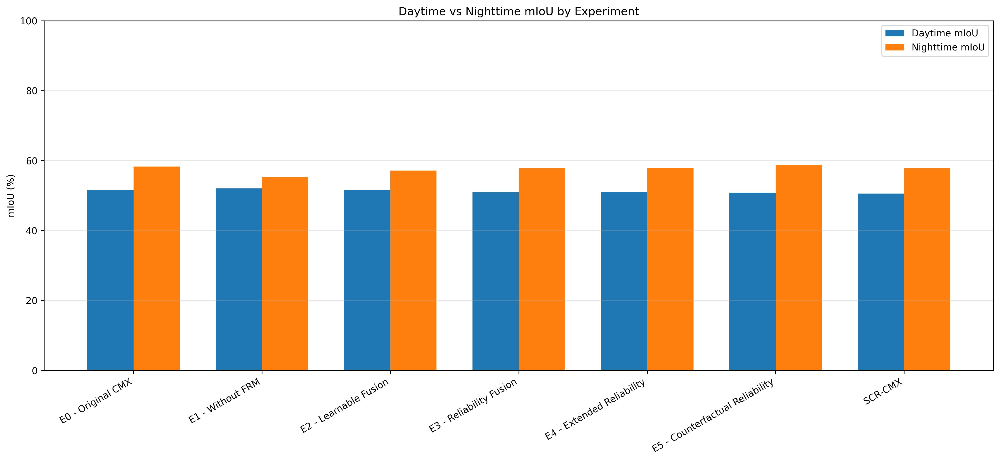

overall_miou_comparison.png


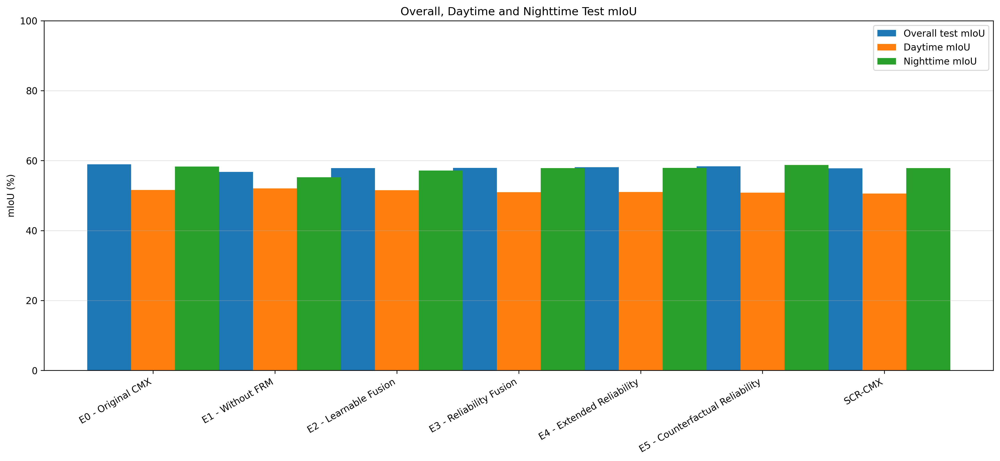

classwise_day_iou_comparison.png


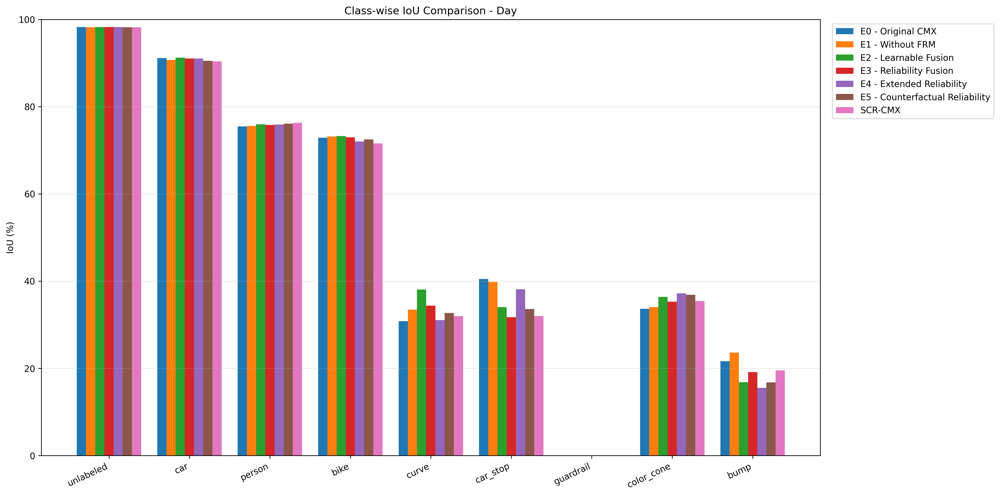

classwise_night_iou_comparison.png


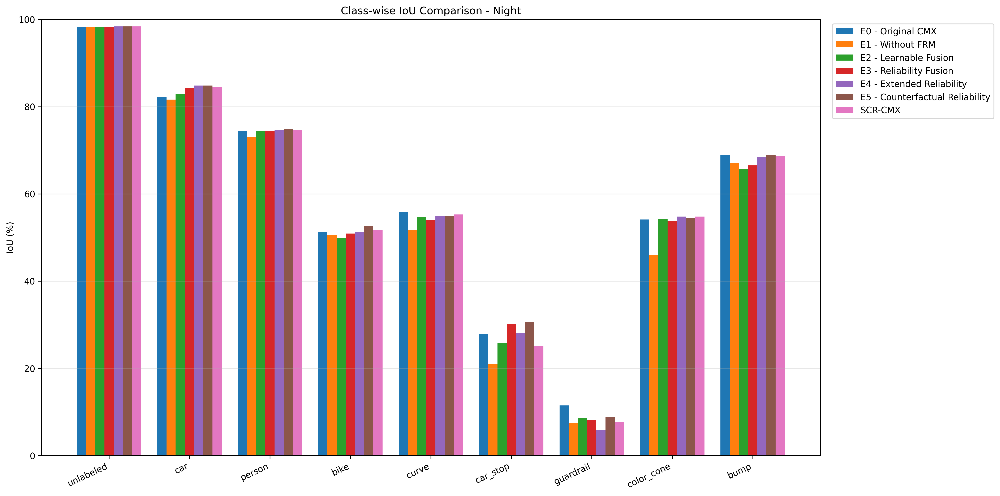

CRD-Net is not included yet. Its test prediction masks must be generated or located first.


In [181]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Results folder
RESULTS = Path("/home/cse-sdpl/Downloads/day_night_results")

# 1. Display the mIoU summary table
summary_file = RESULTS / "overall_summary.csv"

if summary_file.exists():
    summary = pd.read_csv(summary_file)
    display(summary)
else:
    print("Summary CSV not found:", summary_file)

# 2. Display the saved graphs inside Jupyter
graph_files = [
    "day_night_miou_comparison.png",
    "overall_miou_comparison.png",
    "classwise_day_iou_comparison.png",
    "classwise_night_iou_comparison.png",
]

for filename in graph_files:
    path = RESULTS / filename

    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print("Graph not found:", path)

# 3. Display CRD-Net results if available
if summary_file.exists():
    if "CRD-Net" in summary["experiment"].values:
        print("CRD-Net results:")
        display(summary[summary["experiment"] == "CRD-Net"])
    else:
        print(
            "CRD-Net is not included yet. "
            "Its test prediction masks must be generated or located first."
        )


In [182]:
from pathlib import Path

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")

for p in crd_root.rglob("evaluate_crd_test.py"):
    print("Evaluation script:", p)

for p in crd_root.rglob("crd_best_miou.pth"):
    print("Best checkpoint:", p)

Evaluation script: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py
Best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_best_miou.pth
Best checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth


In [184]:
from pathlib import Path

eval_script = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py"
)

print(eval_script.read_text())


import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module_from_path(
    "crd_validation_integration",
    C

In [186]:

from pathlib import Path

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")

eval_script = crd_root / "scripts" / "evaluate_crd_test.py"

print("=" * 80)
print("CRD-NET TEST EVALUATION SCRIPT")
print("=" * 80)

if eval_script.exists():
    source = eval_script.read_text()
    print(source)
else:
    print("Evaluation script not found:", eval_script)

print("\n" + "=" * 80)
print("PREDICTION / OUTPUT REFERENCES IN THE SCRIPT")
print("=" * 80)

for line_no, line in enumerate(source.splitlines(), 1):
    if any(term in line.lower() for term in (
        "save", "imwrite", "prediction", "pred_dir",
        "output_dir", "checkpoint", "split", "argmax"
    )):
        print(f"{line_no:4}: {line}")

print("\n" + "=" * 80)
print("POSSIBLE EXISTING PREDICTION DIRECTORIES")
print("=" * 80)

for folder in crd_root.rglob("*"):
    if folder.is_dir() and any(
        term in folder.name.lower()
        for term in ("prediction", "predictions", "test_output")
    ):
        print(folder)


CRD-NET TEST EVALUATION SCRIPT

import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module_from_path(
    "crd

In [187]:
from pathlib import Path

pred_dir = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/predictions/day_night_test"
)

files = list(pred_dir.glob("*.png"))
print("CRD-Net prediction masks:", len(files))
print("First five:", [p.name for p in files[:5]])

assert len(files) == 393, (
    f"Expected 393 prediction masks, got {len(files)}. "
    "Check the test ID order and evaluator output."
)

CRD-Net prediction masks: 0
First five: []


AssertionError: Expected 393 prediction masks, got 0. Check the test ID order and evaluator output.

In [188]:

from pathlib import Path
import traceback

crd_root = Path("/home/cse-sdpl/Downloads/CRD_Net")
pred_dir = crd_root / "predictions" / "day_night_test"
script = crd_root / "scripts" / "evaluate_crd_test_save_predictions.py"
log_file = crd_root / "logs" / "crd_test_best.log"

print("=" * 70)
print("1. EVALUATION SCRIPT")
print("=" * 70)
print("Script exists:", script.exists())

if script.exists():
    source = script.read_text()
    for i, line in enumerate(source.splitlines(), 1):
        if any(term in line.lower() for term in (
            "crd_pred_dir", "prediction_index", "test_ids",
            "save_path", "func_per_iteration", "def run"
        )):
            print(f"{i:4}: {line}")

print("\n" + "=" * 70)
print("2. PREDICTION DIRECTORIES")
print("=" * 70)

for folder in [crd_root / "predictions", pred_dir]:
    print(f"\n{folder}")
    print("Exists:", folder.exists())
    if folder.exists():
        items = list(folder.iterdir())
        print("Item count:", len(items))
        print("First items:", [p.name for p in items[:10]])

print("\n" + "=" * 70)
print("3. EVALUATION LOG")
print("=" * 70)

if log_file.exists():
    lines = log_file.read_text(errors="replace").splitlines()
    print("\n".join(lines[-60:]))
else:
    print("Log not found:", log_file)

print("\n" + "=" * 70)
print("4. TEST LIST LOCATIONS")
print("=" * 70)

for candidate in [
    crd_root / "datasets" / "TDD" / "test.txt",
    Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt"),
    Path("/home/cse-sdpl/Downloads/CMX_E5/datasets/TDD/test.txt"),
]:
    print(candidate, "exists:", candidate.exists())
    if candidate.exists():
        print("First 3 IDs:", candidate.read_text().splitlines()[:3])

print("\n" + "=" * 70)
print("5. EXISTING PREDICTION PNG FILES")
print("=" * 70)

for p in crd_root.rglob("*.png"):
    if "prediction" in str(p.parent).lower() or "test" in str(p.parent).lower():
        print(p)


1. EVALUATION SCRIPT
Script exists: False

2. PREDICTION DIRECTORIES

/home/cse-sdpl/Downloads/CRD_Net/predictions
Exists: True
Item count: 0
First items: []

/home/cse-sdpl/Downloads/CRD_Net/predictions/day_night_test
Exists: False

3. EVALUATION LOG
Model: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
(array([0.9827424 , 0.89406001, 0.75514838, 0.64318357, 0.46576521,
       0.24941176, 0.02279339, 0.52492343, 0.55944068]), np.float64(0.5663854269818961), np.float64(0.5143408054331635), np.float64(0.9672456801566963), np.float64(0.6419090597905129), np.float64(0.9820815690601145))


4. TEST LIST LOCATIONS
/home/cse-sdpl/Downloads/CRD_Net/datasets/TDD/test.txt exists: False
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt exists: True
First 3 IDs: ['01402D', '01403D', '01404D']
/home/cse-sdpl/Downloads/CMX_E5/datasets/TDD/test.txt exists: False

5. EXISTING PREDICTION PNG FILES


DISCOVERING EXPERIMENT LOGS

E0: 1 root(s), 35 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_Original

E1: 1 root(s), 36 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_E1

E2: 1 root(s), 42 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_E2

E3: 1 root(s), 47 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_E3

E4: 1 root(s), 51 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_E4

E5: 1 root(s), 18 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_E5

SCR-CMX: 1 root(s), 32 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CMX_SCR

CRD-Net: 1 root(s), 13 log/data file(s)
  Root: /home/cse-sdpl/Downloads/CRD_Net

EXPERIMENT SUMMARY


,Experiment,Train mIoU (%),Validation mIoU (%),Test mIoU (%),Test Metric Source,Parameters (M),Largest Checkpoint (GB),Logs with mIoU,Checkpoints Found,Experiment Directory
0,E0,NaN,NaN,58.9230,Previously recorded value; verify dataset/split,66.565521,0.744847,0,23,/home/cse-sdpl/Downloads/CMX_Original
1,E1,NaN,NaN,56.7860,Previously recorded value; verify dataset/split,66.565521,0.670168,0,23,/home/cse-sdpl/Downloads/CMX_E1
2,E2,NaN,NaN,57.8300,Previously recorded value; verify dataset/split,66.565529,0.744851,0,44,/home/cse-sdpl/Downloads/CMX_E2
3,E3,NaN,NaN,57.8940,Previously recorded value; verify dataset/split,66.662169,0.745945,0,65,/home/cse-sdpl/Downloads/CMX_E3
4,E4,NaN,NaN,58.0860,Previously recorded value; verify dataset/split,66.758817,0.747042,0,21,/home/cse-sdpl/Downloads/CMX_E4
5,E5,NaN,NaN,58.3790,Previously recorded value; verify dataset/split,NaN,0.747042,0,22,/home/cse-sdpl/Downloads/CMX_E5
6,SCR-CMX,NaN,NaN,57.7850,Previously recorded value; verify dataset/split,NaN,0.747042,0,65,/home/cse-sdpl/Downloads/CMX_SCR
7,CRD-Net,NaN,62.1004,56.6385,Previously recorded value; verify dataset/split,NaN,0.747100,5,8,/home/cse-sdpl/Downloads/CRD_Net


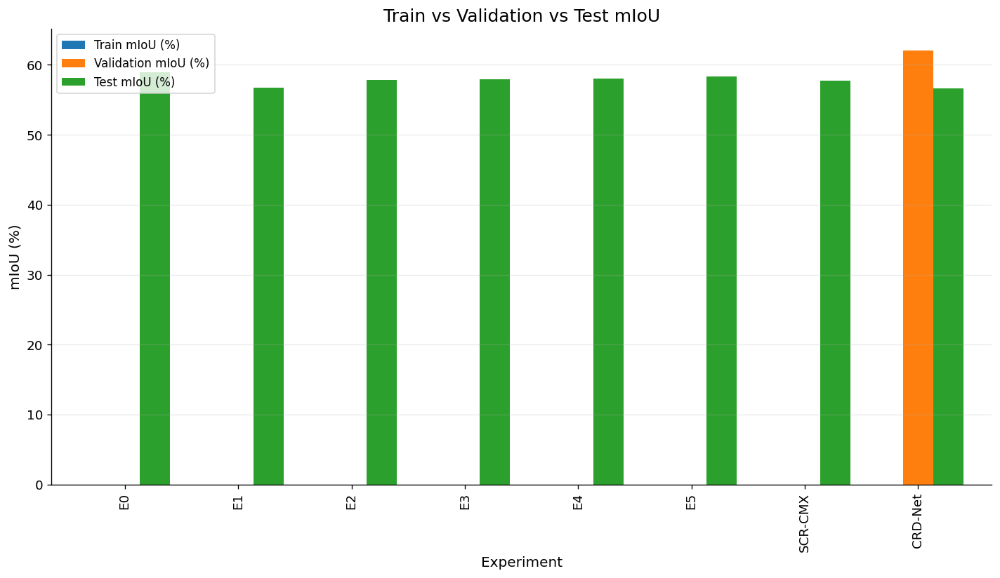

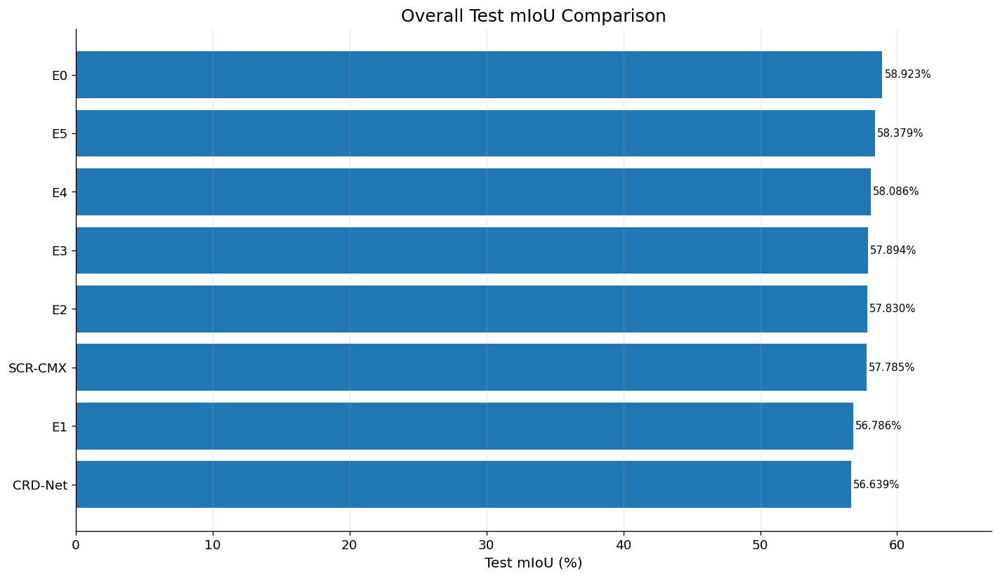

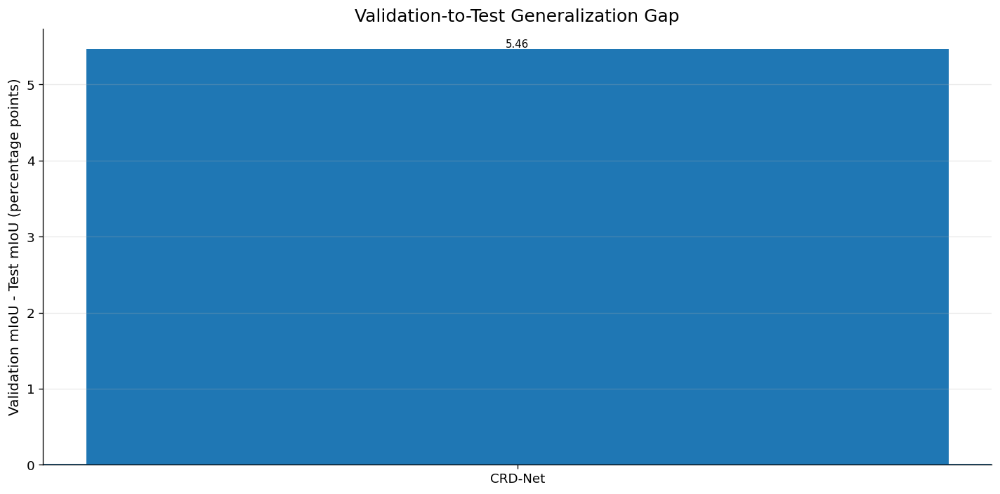

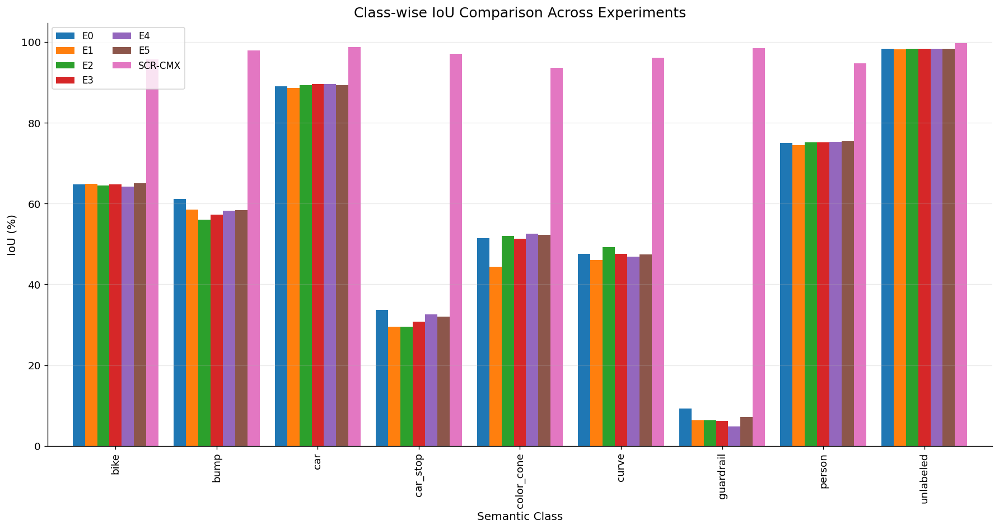


No epoch-wise mIoU CSV curves were found. This graph requires per-epoch training/validation metrics in logs or CSVs.


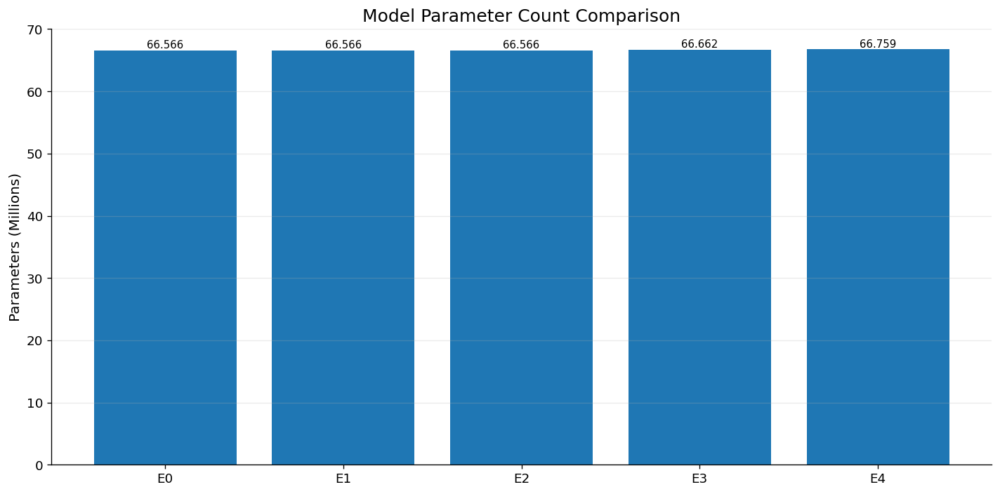


Day/night comparison not generated: no compatible summary CSV found. This is intentional; day/night scores should not be guessed from overall mIoU.

FINISHED
Output directory: /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS
Tables: /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/tables
Graphs: /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/graphs

Generated graph files:
  01_train_validation_test_miou.png
  02_test_miou_ranking.png
  03_validation_test_gap.png
  04_classwise_iou_comparison.png
  06_parameter_count_comparison.png

Important:
- Blank train/validation values mean no compatible metric was found.
- Previously recorded test values are marked in the summary source column.
- Verify MFNet vs TDD dataset consistency before presenting results.
- Day/night scores are only plotted if a compatible summary CSV exists.


In [189]:

# ================================================================
# CMX RESEARCH: COMPLETE EXPERIMENT COMPARISON & PRESENTATION GRAPHS
# E0-E5 + SCR-CMX + CRD-Net
# Run this entire cell in Jupyter on Ubuntu.
# ================================================================

from pathlib import Path
import re
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------- CONFIGURATION -------------------------

HOME = Path("/home/cse-sdpl/Downloads")
OUTPUT = HOME / "CMX_PRESENTATION_RESULTS"

OUTPUT.mkdir(parents=True, exist_ok=True)
(OUTPUT / "graphs").mkdir(exist_ok=True)
(OUTPUT / "tables").mkdir(exist_ok=True)

EXPERIMENTS = {
    "E0": [
        HOME / "CMX_Original",
    ],
    "E1": [
        HOME / "CMX_E1",
    ],
    "E2": [
        HOME / "CMX_E2",
    ],
    "E3": [
        HOME / "CMX_E3",
    ],
    "E4": [
        HOME / "CMX_E4",
    ],
    "E5": [
        HOME / "CMX_E5",
    ],
    "SCR-CMX": [
        HOME / "SCR_CMX",
        HOME / "SCR-CMX",
        HOME / "CMX_SCR",
    ],
    "CRD-Net": [
        HOME / "CRD_Net",
    ],
}

KNOWN_TEST_MIOU = {
    # Values recorded in previous experiment discussions.
    # They are only used if a matching experiment log is not found.
    # Confirm the dataset/split before using these in a publication.
    "E0": 58.923,
    "E1": 56.786,
    "E2": 57.830,
    "E3": 57.894,
    "E4": 58.086,
    "E5": 58.379,
    "SCR-CMX": 57.785,
    "CRD-Net": 56.6385,
}

KNOWN_PARAMETERS_M = {
    "E0": 66.565521,
    "E1": 66.565521,
    "E2": 66.565529,
    "E3": 66.662169,
    "E4": 66.758817,
    "E5": np.nan,
    "SCR-CMX": np.nan,
    "CRD-Net": np.nan,
}

CLASS_NAMES = [
    "unlabeled", "car", "person", "bike", "curve",
    "car_stop", "guardrail", "color_cone", "bump"
]

# ------------------------- HELPERS -------------------------------

def read_text(path):
    try:
        return path.read_text(errors="ignore")
    except Exception:
        return ""

def extract_metric(text, names):
    """Extract the last matching metric from a log."""
    for name in names:
        patterns = [
            rf"{re.escape(name)}\s*[:=]\s*([0-9]+(?:\.[0-9]+)?)\s*%",
            rf"{re.escape(name)}\s*[:=]\s*([0-9]+(?:\.[0-9]+)?)",
        ]
        matches = []
        for pattern in patterns:
            matches.extend(re.findall(pattern, text, flags=re.IGNORECASE))
        if matches:
            try:
                value = float(matches[-1])
                # Convert fractional values such as 0.566 to percentage.
                if value <= 1.0:
                    value *= 100
                return value
            except Exception:
                pass
    return np.nan

def find_experiment_roots(name):
    roots = [p for p in EXPERIMENTS[name] if p.exists()]
    if roots:
        return roots

    # Fallback: search only one directory level under Downloads.
    key = name.lower().replace("-", "").replace("_", "")
    matches = []
    try:
        for p in HOME.iterdir():
            if p.is_dir():
                normalized = p.name.lower().replace("-", "").replace("_", "")
                if key in normalized:
                    matches.append(p)
    except Exception:
        pass
    return matches

def discover_logs(roots):
    found = []
    for root in roots:
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in {
                ".log", ".txt", ".out", ".csv", ".json"
            }:
                # Avoid reading large datasets and prediction masks.
                if any(part.lower() in {
                    "rgb", "thermal", "label", "labels",
                    "predictions", "images"
                } for part in p.parts):
                    continue
                try:
                    if p.stat().st_size <= 30_000_000:
                        found.append(p)
                except Exception:
                    pass
    return sorted(set(found))

def classify_split(path, text):
    s = (str(path) + " " + text[:5000]).lower()
    if "validation" in s or "val_" in s or "/val/" in s or "val miou" in s:
        return "val"
    if "test" in s or "/test/" in s or "test miou" in s:
        return "test"
    if "train" in s or "training" in s:
        return "train"
    return "unknown"

def extract_miou(text):
    # Prefer the standard CMX output format, when present.
    value = extract_metric(text, [
        "mean_IoU", "mean IoU", "mIoU", "mean_iou", "miou"
    ])
    return value

def extract_epoch(text, path):
    vals = re.findall(
        r"(?:epoch|Epoch)\s*[-:= ]\s*(\d+)",
        text,
        flags=re.IGNORECASE
    )
    if vals:
        return int(vals[-1])
    m = re.search(r"epoch[-_](\d+)", str(path), re.IGNORECASE)
    return int(m.group(1)) if m else np.nan

# ------------------------- DISCOVERY -----------------------------

rows = []
curve_rows = []
class_rows = []
file_rows = []
root_summary = {}

print("=" * 78)
print("DISCOVERING EXPERIMENT LOGS")
print("=" * 78)

for exp_name in EXPERIMENTS:
    roots = find_experiment_roots(exp_name)
    root_summary[exp_name] = [str(p) for p in roots]
    logs = discover_logs(roots)

    print(f"\n{exp_name}: {len(roots)} root(s), {len(logs)} log/data file(s)")
    for r in roots:
        print("  Root:", r)

    exp_log_rows = []
    for log_path in logs:
        if log_path.suffix.lower() not in {".log", ".txt", ".out", ".json"}:
            continue

        content = read_text(log_path)
        if not content:
            continue

        split = classify_split(log_path, content)
        miou = extract_miou(content)
        freq_iou = extract_metric(content, ["freq_IoU", "frequency_IoU"])
        mean_pixel_acc = extract_metric(content, ["mean_pixel_acc", "mean_pixel_accuracy"])
        pixel_acc = extract_metric(content, ["pixel_acc", "pixel_accuracy"])
        epoch = extract_epoch(content, log_path)

        if not np.isnan(miou):
            rec = {
                "Experiment": exp_name,
                "Split": split,
                "mIoU (%)": miou,
                "Frequency IoU (%)": freq_iou,
                "Mean Pixel Accuracy (%)": mean_pixel_acc,
                "Pixel Accuracy (%)": pixel_acc,
                "Epoch": epoch,
                "Source File": str(log_path),
            }
            rows.append(rec)
            exp_log_rows.append(rec)

        # Extract class-wise IoU if logs contain the class labels.
        for class_name in CLASS_NAMES:
            patterns = [
                rf"{re.escape(class_name)}\s*[:=]\s*([0-9]+(?:\.[0-9]+)?)\s*%",
                rf"{re.escape(class_name)}\s+([0-9]+(?:\.[0-9]+)?)\s*%",
            ]
            vals = []
            for pattern in patterns:
                vals.extend(re.findall(pattern, content, re.IGNORECASE))
            if vals:
                try:
                    val = float(vals[-1])
                    class_rows.append({
                        "Experiment": exp_name,
                        "Class": class_name,
                        "IoU (%)": val,
                        "Source File": str(log_path),
                    })
                except Exception:
                    pass

    # Scan CSV files for epoch-wise training/validation curves.
    for root in roots:
        for csv_path in root.rglob("*.csv"):
            try:
                df = pd.read_csv(csv_path)
                if df.empty:
                    continue
                normalized = {str(c).strip().lower(): c for c in df.columns}
                epoch_col = next(
                    (normalized[k] for k in normalized
                     if k in {"epoch", "epochs", "iteration", "iter", "step"}),
                    None
                )
                metric_col = next(
                    (normalized[k] for k in normalized
                     if "miou" in k or "mean_iou" in k or "mean-iou" in k),
                    None
                )
                if epoch_col is not None and metric_col is not None:
                    for _, row in df.iterrows():
                        try:
                            val = float(row[metric_col])
                            if val <= 1.0:
                                val *= 100
                            curve_rows.append({
                                "Experiment": exp_name,
                                "Epoch": float(row[epoch_col]),
                                "mIoU (%)": val,
                                "Source File": str(csv_path),
                            })
                        except Exception:
                            pass
            except Exception:
                pass

# ------------------------- METRIC SUMMARY ------------------------

logs_df = pd.DataFrame(rows)
class_df = pd.DataFrame(class_rows)
curves_df = pd.DataFrame(curve_rows)

summary_rows = []

for exp_name in EXPERIMENTS:
    exp_logs = logs_df[logs_df["Experiment"] == exp_name] if not logs_df.empty else pd.DataFrame()

    def last_split_metric(split_name, col="mIoU (%)"):
        if exp_logs.empty:
            return np.nan
        sub = exp_logs[exp_logs["Split"] == split_name]
        if sub.empty:
            return np.nan
        # Prefer the highest/latest epoch if epoch is recorded.
        if "Epoch" in sub and sub["Epoch"].notna().any():
            sub = sub.sort_values("Epoch")
        return sub.iloc[-1][col]

    train_miou = last_split_metric("train")
    val_miou = last_split_metric("val")
    test_miou = last_split_metric("test")

    test_source = "Log"
    if np.isnan(test_miou) and exp_name in KNOWN_TEST_MIOU:
        test_miou = KNOWN_TEST_MIOU[exp_name]
        test_source = "Previously recorded value; verify dataset/split"

    roots = find_experiment_roots(exp_name)
    checkpoints = []
    for root in roots:
        for p in root.rglob("*.pth"):
            try:
                checkpoints.append(p)
            except Exception:
                pass

    largest_ckpt_gb = np.nan
    if checkpoints:
        largest_ckpt_gb = max(p.stat().st_size for p in checkpoints) / (1024 ** 3)

    summary_rows.append({
        "Experiment": exp_name,
        "Train mIoU (%)": train_miou,
        "Validation mIoU (%)": val_miou,
        "Test mIoU (%)": test_miou,
        "Test Metric Source": test_source,
        "Parameters (M)": KNOWN_PARAMETERS_M.get(exp_name, np.nan),
        "Largest Checkpoint (GB)": largest_ckpt_gb,
        "Logs with mIoU": len(exp_logs),
        "Checkpoints Found": len(checkpoints),
        "Experiment Directory": "; ".join(str(p) for p in roots),
    })

summary_df = pd.DataFrame(summary_rows)

# Save tables.
summary_df.to_csv(OUTPUT / "tables" / "experiment_summary.csv", index=False)
logs_df.to_csv(OUTPUT / "tables" / "all_extracted_log_metrics.csv", index=False)
class_df.to_csv(OUTPUT / "tables" / "classwise_iou_extracted.csv", index=False)
curves_df.to_csv(OUTPUT / "tables" / "epochwise_miou_curves.csv", index=False)

with open(OUTPUT / "tables" / "discovered_paths.json", "w") as f:
    json.dump(root_summary, f, indent=2)

print("\n" + "=" * 78)
print("EXPERIMENT SUMMARY")
print("=" * 78)
display(summary_df)

# ------------------------- GRAPH STYLE ---------------------------

plt.rcParams.update({
    "figure.figsize": (12, 7),
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

GRAPH = OUTPUT / "graphs"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(GRAPH / name, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

# 1. Overall train / validation / test mIoU comparison.
plot_df = summary_df.set_index("Experiment")[
    ["Train mIoU (%)", "Validation mIoU (%)", "Test mIoU (%)"]
]
if plot_df.notna().any().any():
    ax = plot_df.plot(kind="bar", width=0.8)
    ax.set_title("Train vs Validation vs Test mIoU")
    ax.set_ylabel("mIoU (%)")
    ax.set_xlabel("Experiment")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="best")
    save_fig("01_train_validation_test_miou.png")

# 2. Overall test mIoU ranking.
valid_test = summary_df.dropna(subset=["Test mIoU (%)"]).sort_values("Test mIoU (%)")
if not valid_test.empty:
    plt.figure(figsize=(12, 7))
    bars = plt.barh(valid_test["Experiment"], valid_test["Test mIoU (%)"])
    plt.xlabel("Test mIoU (%)")
    plt.title("Overall Test mIoU Comparison")
    plt.grid(axis="x", alpha=0.25)
    for bar, val in zip(bars, valid_test["Test mIoU (%)"]):
        plt.text(val + 0.15, bar.get_y() + bar.get_height()/2, f"{val:.3f}%",
                 va="center", fontsize=9)
    plt.xlim(0, min(100, valid_test["Test mIoU (%)"].max() + 8))
    save_fig("02_test_miou_ranking.png")

# 3. Validation versus test generalization gap.
gap_df = summary_df.dropna(subset=["Validation mIoU (%)", "Test mIoU (%)"]).copy()
if not gap_df.empty:
    gap_df["Val-Test Gap (pp)"] = (
        gap_df["Validation mIoU (%)"] - gap_df["Test mIoU (%)"]
    )
    gap_df.to_csv(OUTPUT / "tables" / "validation_test_gap.csv", index=False)
    plt.figure(figsize=(12, 6))
    bars = plt.bar(gap_df["Experiment"], gap_df["Val-Test Gap (pp)"])
    plt.axhline(0, linewidth=1)
    plt.ylabel("Validation mIoU - Test mIoU (percentage points)")
    plt.title("Validation-to-Test Generalization Gap")
    plt.grid(axis="y", alpha=0.25)
    for bar, val in zip(bars, gap_df["Val-Test Gap (pp)"]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f"{val:.2f}", ha="center",
                 va="bottom" if val >= 0 else "top", fontsize=9)
    save_fig("03_validation_test_gap.png")

# 4. Class-wise IoU comparison, only when class metrics were found.
if not class_df.empty:
    class_pivot = class_df.pivot_table(
        index="Class", columns="Experiment", values="IoU (%)", aggfunc="last"
    )
    class_pivot.to_csv(OUTPUT / "tables" / "classwise_iou_comparison.csv")
    ax = class_pivot.plot(kind="bar", figsize=(15, 8), width=0.85)
    ax.set_title("Class-wise IoU Comparison Across Experiments")
    ax.set_ylabel("IoU (%)")
    ax.set_xlabel("Semantic Class")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="best", ncol=2)
    save_fig("04_classwise_iou_comparison.png")

# 5. Epoch-wise training/validation mIoU curves if CSV data exists.
if not curves_df.empty:
    plt.figure(figsize=(13, 7))
    for exp_name, group in curves_df.groupby("Experiment"):
        group = group.sort_values("Epoch")
        plt.plot(group["Epoch"], group["mIoU (%)"], label=exp_name, linewidth=2)
    plt.xlabel("Epoch / recorded step")
    plt.ylabel("mIoU (%)")
    plt.title("Recorded Epoch-wise mIoU Curves")
    plt.grid(alpha=0.25)
    plt.legend(ncol=2)
    save_fig("05_epochwise_miou_curves.png")
else:
    print(
        "\nNo epoch-wise mIoU CSV curves were found. "
        "This graph requires per-epoch training/validation metrics in logs or CSVs."
    )

# 6. Parameter count comparison.
param_df = summary_df.dropna(subset=["Parameters (M)"])
if not param_df.empty:
    plt.figure(figsize=(12, 6))
    bars = plt.bar(param_df["Experiment"], param_df["Parameters (M)"])
    plt.ylabel("Parameters (Millions)")
    plt.title("Model Parameter Count Comparison")
    plt.grid(axis="y", alpha=0.25)
    for bar, val in zip(bars, param_df["Parameters (M)"]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f"{val:.3f}", ha="center", va="bottom", fontsize=9)
    save_fig("06_parameter_count_comparison.png")

# 7. Day/night results: only if a suitable existing results CSV is found.
daynight_candidates = [
    HOME / "day_night_results" / "overall_summary.csv",
    HOME / "day_night_results" / "classwise_day_night_iou.csv",
    OUTPUT / "tables" / "day_night_summary.csv",
]

daynight_loaded = False
for candidate in daynight_candidates:
    if not candidate.exists():
        continue
    try:
        dd = pd.read_csv(candidate)
        cols = {c.lower().replace(" ", "_"): c for c in dd.columns}
        day_col = next((cols[k] for k in cols if "day" in k and "miou" in k), None)
        night_col = next((cols[k] for k in cols if "night" in k and "miou" in k), None)
        exp_col = next((cols[k] for k in cols if "experiment" in k or "model" in k), None)
        if day_col and night_col and exp_col:
            dd = dd[[exp_col, day_col, night_col]].copy()
            dd.columns = ["Experiment", "Daytime mIoU (%)", "Nighttime mIoU (%)"]
            dd.to_csv(OUTPUT / "tables" / "day_night_summary.csv", index=False)
            ax = dd.set_index("Experiment").plot(kind="bar", figsize=(12, 7))
            ax.set_title("Daytime vs Nighttime Test mIoU")
            ax.set_ylabel("mIoU (%)")
            ax.set_xlabel("Experiment")
            ax.grid(axis="y", alpha=0.25)
            save_fig("07_day_vs_night_miou.png")
            daynight_loaded = True
            break
    except Exception:
        pass

if not daynight_loaded:
    print(
        "\nDay/night comparison not generated: no compatible summary CSV found. "
        "This is intentional; day/night scores should not be guessed from overall mIoU."
    )

# 8. Extracted metrics by log file.
if not logs_df.empty:
    logs_df.sort_values(["Experiment", "Split", "Epoch"], na_position="last").to_csv(
        OUTPUT / "tables" / "all_extracted_log_metrics.csv", index=False
    )

# 9. Create a text report for presentation preparation.
report_lines = [
    "EXPERIMENT COMPARISON REPORT",
    "=" * 60,
    "",
    "Included experiments: E0, E1, E2, E3, E4, E5, SCR-CMX, CRD-Net",
    "Metrics are extracted from available local logs and configured prior values.",
    "Confirm that all experiments use the same dataset, test split, label mapping,",
    "and evaluation implementation before making direct scientific comparisons.",
    "",
    "Missing metrics are left blank; no training or validation values are fabricated.",
    "",
    "SUMMARY TABLE",
    summary_df.to_string(index=False),
    "",
    "LOG FILES WITH EXTRACTED METRICS",
    logs_df.to_string(index=False) if not logs_df.empty else "No mIoU log values discovered.",
    "",
    "CLASS-WISE METRICS",
    class_df.to_string(index=False) if not class_df.empty else "No class-wise values discovered.",
    "",
    "EPOCH-WISE CURVES",
    curves_df.to_string(index=False) if not curves_df.empty else
    "No compatible epoch-wise mIoU CSV found.",
    "",
    "OUTPUT DIRECTORY",
    str(OUTPUT),
]
(OUTPUT / "presentation_notes.txt").write_text("\n".join(report_lines))

print("\n" + "=" * 78)
print("FINISHED")
print("=" * 78)
print("Output directory:", OUTPUT)
print("Tables:", OUTPUT / "tables")
print("Graphs:", GRAPH)
print("\nGenerated graph files:")
for p in sorted(GRAPH.glob("*.png")):
    print(" ", p.name)

print("\nImportant:")
print("- Blank train/validation values mean no compatible metric was found.")
print("- Previously recorded test values are marked in the summary source column.")
print("- Verify MFNet vs TDD dataset consistency before presenting results.")
print("- Day/night scores are only plotted if a compatible summary CSV exists.")


In [190]:

# ================================================================
# CRD-Net: TRAIN + TEST EVALUATION USING BEST CHECKPOINT
# Does NOT retrain or modify the checkpoint.
# ================================================================

from pathlib import Path
import subprocess
import sys
import re
import json
from datetime import datetime

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CONDA_ENV = "cmx"

CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
EVALUATOR = CRD_ROOT / "scripts" / "evaluate_crd_test.py"

# Search for dataset split files. We need the dataset actually used by CRD-Net.
SEARCH_ROOTS = [
    CRD_ROOT,
    Path("/home/cse-sdpl/Downloads/CMX_Original"),
    Path("/home/cse-sdpl/Downloads/CMX_E5"),
]

OUTPUT = CRD_ROOT / "evaluation_train_test"
OUTPUT.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"
assert EVALUATOR.exists(), f"Evaluator not found: {EVALUATOR}"

print("=" * 72)
print("CRD-Net checkpoint:", CHECKPOINT)
print("Checkpoint size (GB):", round(CHECKPOINT.stat().st_size / 1024**3, 3))
print("Evaluator:", EVALUATOR)
print("=" * 72)

# Discover split lists and dataset folders.
split_files = {"train": [], "val": [], "test": []}

for root in SEARCH_ROOTS:
    if not root.exists():
        continue
    for split in split_files:
        for p in root.rglob(f"{split}.txt"):
            if p.is_file() and p not in split_files[split]:
                split_files[split].append(p)

print("\nAvailable split files:")
for split, paths in split_files.items():
    print(f"\n{split.upper()}:")
    for p in paths:
        try:
            count = sum(1 for line in p.read_text(errors="ignore").splitlines()
                        if line.strip())
        except Exception:
            count = "?"
        print(f"  {p} | IDs: {count}")

# Check evaluator support before launching anything.
source = EVALUATOR.read_text(errors="ignore")
print("\nEvaluator split-related lines:")
for i, line in enumerate(source.splitlines(), 1):
    if any(x in line.lower() for x in [
        "split", "rgbxdataset", "validation", "test", "train"
    ]):
        print(f"{i:4}: {line[:220]}")

print("\n" + "=" * 72)
print("IMPORTANT")
print("=" * 72)
print(
    "The existing script is named evaluate_crd_test.py and may be hard-coded "
    "to the test split. Do not assume it evaluates training merely because "
    "a train.txt file exists."
)
print(
    "This cell will run the current test evaluator to confirm the test result. "
    "It will not run a training evaluation until the evaluator's split handling "
    "is verified."
)

# Run the existing official test evaluator.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
test_log = OUTPUT / f"crd_test_{timestamp}.log"

cmd = [
    "conda", "run", "--no-capture-output", "-n", CONDA_ENV,
    "python", str(EVALUATOR)
]

print("\nRunning CRD-Net test evaluation...")
print("Command:", " ".join(cmd))

with test_log.open("w") as log:
    process = subprocess.Popen(
        cmd,
        cwd=str(CRD_ROOT),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        print(line, end="")
        log.write(line)
    return_code = process.wait()

print("\nTest evaluation exit code:", return_code)
print("Test log saved:", test_log)

log_text = test_log.read_text(errors="ignore")

def find_metric(text, names):
    for name in names:
        matches = re.findall(
            rf"{re.escape(name)}\s*[:=]\s*([0-9]+(?:\.[0-9]+)?)\s*%?",
            text,
            flags=re.IGNORECASE,
        )
        if matches:
            val = float(matches[-1])
            # CMX compute_score often prints fractions such as 0.566385.
            if val <= 1.0:
                val *= 100
            return val
    return None

test_metrics = {
    "Test mIoU (%)": find_metric(log_text, ["mean_IoU", "mean IoU", "mIoU"]),
    "Test Frequency IoU (%)": find_metric(log_text, ["freq_IoU", "frequency_IoU"]),
    "Test Mean Pixel Accuracy (%)": find_metric(log_text, ["mean_pixel_acc"]),
    "Test Pixel Accuracy (%)": find_metric(log_text, ["pixel_acc"]),
}

print("\n" + "=" * 72)
print("CRD-Net TEST METRICS EXTRACTED FROM THIS RUN")
print("=" * 72)
print(json.dumps(test_metrics, indent=2))

# Save a machine-readable summary.
summary_file = OUTPUT / "crd_test_metrics.json"
summary_file.write_text(json.dumps({
    "checkpoint": str(CHECKPOINT),
    "evaluator": str(EVALUATOR),
    "exit_code": return_code,
    "log": str(test_log),
    "metrics": test_metrics,
    "known_best_validation_miou_percent": 62.6627,
    "known_best_validation_epoch": 61,
}, indent=2))

print("\nSaved summary:", summary_file)
print("\nTraining-split evaluation is NOT automatically run by this cell.")
print(
    "Next, we must confirm whether CRD-Net's dataset class and evaluator "
    "can select the training split without changing the model or checkpoint."
)


CRD-Net checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
Checkpoint size (GB): 0.747
Evaluator: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py

Available split files:

TRAIN:
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/train.txt | IDs: 1568

VAL:
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/val.txt | IDs: 392

TEST:
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt | IDs: 393

Evaluator split-related lines:
  17: from dataloader.RGBXDataset import RGBXDataset
  34:     "crd_validation_integration",
  39: class CRDValidationEvaluator(Evaluator):
  63:         print("\nCRD-Net TEST metrics")
  85:         "train_source": cfg.train_source,
  87:         "test_source": cfg.test_source,
  90:     dataset = RGBXDataset(setting, "test", ValPre())
 102:     print("CRD-Net TEST setup")
 106:     print("  Test images:", len(dataset))
 112:     evaluator = CRDValidationEvaluator(
 126:     log_path = CRD_ROOT / "logs" / "crd_te

 69%|██████▉   | 273/393 [00:28<00:12,  9.62it/s]


100%|██████████| 393/393 [00:41<00:00,  9.48it/s]
25 22:15:13 Evaluation Elapsed Time: 41.47s

CRD-Net TEST metrics
(array([0.9827424 , 0.89406001, 0.75514838, 0.64318357, 0.46576521,
       0.24941176, 0.02279339, 0.52492343, 0.55944068]), np.float64(0.5663854269818961), np.float64(0.5143408054331635), np.float64(0.9672456801566963), np.float64(0.6419090597905129), np.float64(0.9820815690601145))

Test evaluation complete.
Test log: /home/cse-sdpl/Downloads/CRD_Net/logs/crd_test_best.log

Test evaluation exit code: 0
Test log saved: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_test_20261025_221426.log

CRD-Net TEST METRICS EXTRACTED FROM THIS RUN
{
  "Test mIoU (%)": null,
  "Test Frequency IoU (%)": null,
  "Test Mean Pixel Accuracy (%)": null,
  "Test Pixel Accuracy (%)": null
}

Saved summary: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_test_metrics.json

Training-split evaluation is NOT automatically run by this cell.
Next, we must confirm whether CRD-

In [191]:

from pathlib import Path
import re
import json
import subprocess
import sys
from datetime import datetime

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
SCRIPT = ROOT / "scripts/evaluate_crd_test.py"
LOG_DIR = ROOT / "logs"
OUT_DIR = ROOT / "evaluation_train_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 1. Correct the test-metric summary from the NumPy tuple
# ---------------------------------------------------------
test_log = LOG_DIR / "crd_test_best.log"
if test_log.exists():
    text = test_log.read_text(errors="ignore")
else:
    candidates = sorted(
        OUT_DIR.glob("crd_test_*.log"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )
    text = candidates[0].read_text(errors="ignore") if candidates else ""

match = re.search(
    r"array\(\[([^\]]+)\]\)\s*,\s*"
    r"np\.float64\(([-+0-9.eE]+)\)\s*,\s*"
    r"np\.float64\(([-+0-9.eE]+)\)\s*,\s*"
    r"np\.float64\(([-+0-9.eE]+)\)\s*,\s*"
    r"np\.float64\(([-+0-9.eE]+)\)\s*,\s*"
    r"np\.float64\(([-+0-9.eE]+)\)",
    text,
    re.S
)

if match:
    class_iou = [
        float(x.strip())
        for x in match.group(1).replace("\n", " ").split(",")
    ]
    values = [float(match.group(i)) * 100 for i in range(2, 7)]
    summary = {
        "dataset_split": "test",
        "class_IoU_percent": [round(x * 100, 4) for x in class_iou],
        "mIoU_percent": round(values[0], 4),
        "mean_class_accuracy_percent": round(values[1], 4),
        "frequency_weighted_IoU_percent": round(values[2], 4),
        "mean_pixel_accuracy_percent": round(values[3], 4),
        "pixel_accuracy_percent": round(values[4], 4),
        "source": str(test_log)
    }
    out_json = OUT_DIR / "crd_test_metrics.json"
    out_json.write_text(json.dumps(summary, indent=2))
    print("Corrected test metrics:")
    print(json.dumps(summary, indent=2))
    print("\nSaved:", out_json)
else:
    print("Could not parse a NumPy tuple from the selected test log.")
    print("Selected log:", test_log)
    print("Check the evaluator output above before continuing.")

# ---------------------------------------------------------
# 2. Inspect dataset loader and evaluator split selection
# ---------------------------------------------------------
print("\n" + "=" * 70)
print("INSPECTING DATASET CONFIGURATION")
print("=" * 70)

dataset_candidates = [
    ROOT / "dataloader" / "RGBXDataset.py",
    ROOT / "dataloader" / "dataloader.py",
    ROOT / "config.py",
    ROOT / "scripts" / "evaluate_crd_test.py",
]

for path in dataset_candidates:
    if path.exists():
        print(f"\n--- {path} ---")
        lines = path.read_text(errors="ignore").splitlines()
        for i, line in enumerate(lines, 1):
            if re.search(
                r"train_source|test_source|val_source|RGBXDataset|"
                r"split|dataset_name|MFNet|TDD|data_root|"
                r"setting\s*=|dataset_path",
                line,
                re.I
            ):
                print(f"{i:4}: {line[:240]}")

# ---------------------------------------------------------
# 3. Prepare a separate train evaluator without touching
#    the original test evaluator
# ---------------------------------------------------------
if not SCRIPT.exists():
    raise FileNotFoundError(f"Evaluator not found: {SCRIPT}")

source = SCRIPT.read_text()
target_line = 'dataset = RGBXDataset(setting, "test", ValPre())'
replacement = 'dataset = RGBXDataset(setting, "train", ValPre())'

if target_line not in source:
    print(
        "\nSTOP: The exact test dataset constructor was not found. "
        "No training evaluator was created. Inspect the source lines above."
    )
else:
    train_script = OUT_DIR / "evaluate_crd_train.py"
    modified = source.replace(target_line, replacement, 1)

    # Keep the training evaluator's log separate from the test evaluator.
    modified = modified.replace(
        "crd_test_best.log",
        "crd_train_best.log"
    )
    modified = modified.replace(
        "CRD-Net TEST metrics",
        "CRD-Net TRAIN metrics"
    )
    modified = modified.replace(
        "Test evaluation complete.",
        "Training-split evaluation complete."
    )
    modified = modified.replace(
        "Test images:",
        "Training images:"
    )
    modified = modified.replace(
        "Test evaluation",
        "Training-split evaluation"
    )

    train_script.write_text(modified)
    print("\nCreated separate evaluator:", train_script)
    print("Original evaluator remains unchanged.")

    print("\nIMPORTANT:")
    print("1. Verify the printed dataset configuration matches MFNet.")
    print("2. If it points to TDD, do not treat these as MFNet results.")
    print("3. If the dataset paths and class mapping are correct, run this next:")
    print(
        f'\n!conda run --no-capture-output -n cmx python "{train_script}"'
    )


Corrected test metrics:
{
  "dataset_split": "test",
  "class_IoU_percent": [
    98.2742,
    89.406,
    75.5148,
    64.3184,
    46.5765,
    24.9412,
    2.2793,
    52.4923,
    55.9441
  ],
  "mIoU_percent": 56.6385,
  "mean_class_accuracy_percent": 51.4341,
  "frequency_weighted_IoU_percent": 96.7246,
  "mean_pixel_accuracy_percent": 64.1909,
  "pixel_accuracy_percent": 98.2082,
  "source": "/home/cse-sdpl/Downloads/CRD_Net/logs/crd_test_best.log"
}

Saved: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_test_metrics.json

INSPECTING DATASET CONFIGURATION

--- /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py ---
  17: from dataloader.RGBXDataset import RGBXDataset
  75:     setting = {
  85:         "train_source": cfg.train_source,
  86:         "eval_source": cfg.eval_source,
  87:         "test_source": cfg.test_source,
  90:     dataset = RGBXDataset(setting, "test", ValPre())

Created separate evaluator: /home/cse-sdpl/Downloads/CRD_Net/evaluation_t

In [192]:

from pathlib import Path
import torch
import re

BASE = Path("/home/cse-sdpl/Downloads")

# Known project directories
PROJECTS = {
    "E5": BASE / "CMX_E5",
    "SCR-CMX": None,  # Auto-discover below
    "CRD-Net": BASE / "CRD_Net",
}

# ---------------------------------------------------------
# Find SCR-CMX directory if its exact name is uncertain
# ---------------------------------------------------------
scr_candidates = [
    BASE / "SCR_CMX",
    BASE / "SCR-CMX",
    BASE / "CMX_SCR",
    BASE / "SCRCMX",
]

for p in scr_candidates:
    if p.is_dir():
        PROJECTS["SCR-CMX"] = p
        break

if PROJECTS["SCR-CMX"] is None and BASE.exists():
    for p in BASE.iterdir():
        if p.is_dir() and "scr" in p.name.lower() and "cmx" in p.name.lower():
            PROJECTS["SCR-CMX"] = p
            break

# ---------------------------------------------------------
# Extract parameter count from model state dictionaries
# ---------------------------------------------------------
def tensor_state_dicts(obj, prefix="checkpoint"):
    found = []

    if not isinstance(obj, dict):
        return found

    # A direct state dictionary: parameter names -> tensors
    tensor_items = {
        k: v for k, v in obj.items()
        if isinstance(k, str) and torch.is_tensor(v)
    }

    if tensor_items:
        found.append((prefix, tensor_items))

    # Look inside common checkpoint containers
    for key, value in obj.items():
        if isinstance(value, dict):
            found.extend(
                tensor_state_dicts(value, f"{prefix}.{key}")
            )

    return found


def count_parameters(state):
    # Count stored model tensors. This includes frozen parameters
    # if they are present in the saved state dictionary.
    total = sum(t.numel() for t in state.values())

    # Buffers (e.g. BatchNorm running statistics) are not parameters.
    # Exclude common running-statistics and tracking buffers.
    buffer_terms = (
        "running_mean",
        "running_var",
        "num_batches_tracked",
    )
    buffers = sum(
        t.numel()
        for k, t in state.items()
        if any(term in k.lower() for term in buffer_terms)
    )

    return total - buffers, total, buffers


def preferred_checkpoint(files):
    if not files:
        return None

    def score(p):
        name = p.name.lower()
        s = 0
        if "best" in name:
            s += 100
        if "epoch-100" in name or "epoch_100" in name:
            s += 90
        if "last" in name:
            s += 70
        if "final" in name:
            s += 60
        if "checkpoint" in str(p.parent).lower():
            s += 10
        return s

    return sorted(files, key=lambda p: (score(p), p.stat().st_mtime),
                  reverse=True)[0]


results = []

for name, root in PROJECTS.items():
    print("\n" + "=" * 80)
    print(f"PROJECT: {name}")
    print("=" * 80)

    if root is None or not root.exists():
        print("Project folder not found automatically.")
        print("Please set PROJECTS['SCR-CMX'] to the actual project directory.")
        continue

    print("Root:", root)

    checkpoints = []
    for pattern in ("*.pth", "*.pt", "*.ckpt"):
        checkpoints.extend(root.rglob(pattern))

    # Skip duplicate paths
    checkpoints = list({p.resolve(): p for p in checkpoints}.values())

    if not checkpoints:
        print("No checkpoint files found.")
        continue

    print(f"Checkpoint files found: {len(checkpoints)}")
    for p in sorted(checkpoints, key=lambda x: x.stat().st_size, reverse=True)[:8]:
        print(f"  {p}  ({p.stat().st_size / (1024**3):.3f} GB)")

    selected = preferred_checkpoint(checkpoints)
    print("\nSelected checkpoint:", selected)

    try:
        checkpoint = torch.load(
            selected,
            map_location="cpu",
            weights_only=False
        )

        candidates = tensor_state_dicts(checkpoint)

        if not candidates:
            print("No model tensor state dictionary could be identified.")
            print("Top-level keys:",
                  list(checkpoint.keys())[:30]
                  if isinstance(checkpoint, dict) else type(checkpoint))
            continue

        # Prefer conventional model-state keys; otherwise use the
        # candidate with the most tensor elements.
        def candidate_score(item):
            key, state = item
            k = key.lower()
            score = sum(t.numel() for t in state.values())
            if any(s in k for s in (
                "model_state_dict", ".state_dict", ".model",
                ".net", ".network", ".module"
            )):
                score += 1_000_000
            return score

        candidate_name, state = max(candidates, key=candidate_score)
        parameter_count, all_tensor_count, buffer_count = count_parameters(state)

        row = {
            "project": name,
            "checkpoint": str(selected),
            "state_dict_key": candidate_name,
            "tensor_entries": len(state),
            "parameter_count_estimate": parameter_count,
            "parameter_count_millions": parameter_count / 1e6,
            "all_tensor_elements": all_tensor_count,
            "excluded_buffer_elements": buffer_count,
        }
        results.append(row)

        print("\nSelected tensor mapping:", candidate_name)
        print("Tensor entries:", len(state))
        print(f"Estimated parameters: {parameter_count:,}")
        print(f"Parameters (millions): {parameter_count / 1e6:.6f} M")
        print(f"Excluded buffer elements: {buffer_count:,}")

        # Show alternative nested state dictionaries for cross-checking
        alternatives = []
        for key, candidate in candidates:
            if key == candidate_name:
                continue
            n = sum(t.numel() for t in candidate.values())
            alternatives.append((key, len(candidate), n))

        if alternatives:
            print("\nOther nested tensor mappings:")
            for key, entries, n in alternatives[:10]:
                print(f"  {key}: {entries} tensors, {n:,} tensor elements")

    except Exception as e:
        print("Could not read checkpoint:", repr(e))

# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------
print("\n" + "=" * 80)
print("PARAMETER COUNT SUMMARY")
print("=" * 80)

for row in results:
    print(
        f"{row['project']:10s} | "
        f"{row['parameter_count_millions']:.6f} M | "
        f"{row['checkpoint']}"
    )

if results:
    import pandas as pd
    output = BASE / "CMX_PRESENTATION_RESULTS"
    output.mkdir(parents=True, exist_ok=True)

    csv_path = output / "E5_SCR_CMX_CRD_Net_parameter_counts.csv"
    pd.DataFrame(results).to_csv(csv_path, index=False)
    print("\nCSV saved to:", csv_path)



PROJECT: E5
Root: /home/cse-sdpl/Downloads/CMX_E5
Checkpoint files found: 21
  /home/cse-sdpl/Downloads/CMX_E5/pretraining_backups/e4_epoch-100_initialization.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-last.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-75.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-65.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-60.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-90.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-35.pth  (0.747 GB)
  /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-25.pth  (0.747 GB)

Selected checkpoint: /home/cse-sdpl/Downloads/CMX_E5/pretraining_backups/e4_epoch-100_initialization.pth

Selected tensor mapping: checkpoint.model
Tensor entries: 869
Estimated parameters: 66,758,817
Para

In [193]:

from pathlib import Path

base = Path("/home/cse-sdpl/Downloads")

searches = {
    "E5": base / "CMX_E5",
    "SCR-CMX": base / "CMX_SCR",
    "CRD-Net": base / "CRD_Net",
}

for name, root in searches.items():
    print(f"\n{'=' * 75}\n{name}\n{'=' * 75}")

    if not root.exists():
        print("Directory not found:", root)
        continue

    files = []
    for pattern in ("*.pth", "*.pt", "*.ckpt"):
        files.extend(root.rglob(pattern))

    files = sorted(
        set(files),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    for p in files[:20]:
        relative = p.relative_to(root)
        size_mb = p.stat().st_size / (1024 ** 2)
        print(f"{relative} | {size_mb:.2f} MB")



E5
log_TDD_mit_b2_e5/checkpoint/epoch-last.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-100.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-95.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-90.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-85.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-80.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-75.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-70.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-65.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-60.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-55.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-50.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-45.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-40.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-35.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-30.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-25.pth | 764.97 MB
log_TDD_mit_b2_e5/checkpoint/epoch-20.pth | 764.97 MB
log_TDD_mit_b2_e5/che

In [194]:

from pathlib import Path
import torch
import pandas as pd

BASE = Path("/home/cse-sdpl/Downloads")

CHECKPOINTS = {
    "E5": BASE / "CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth",
    "SCR-CMX": BASE / "CMX_SCR/log_TDD_mit_b2_scr/checkpoint/epoch-100.pth",
    "CRD-Net": BASE / "CRD_Net/checkpoints/crd_best_miou.pth",
}

def find_state_dicts(obj, prefix="root"):
    found = []
    if not isinstance(obj, dict):
        return found

    tensors = {
        k: v for k, v in obj.items()
        if isinstance(k, str) and torch.is_tensor(v)
    }
    if tensors:
        found.append((prefix, tensors))

    for key, value in obj.items():
        if isinstance(value, dict):
            found.extend(find_state_dicts(value, f"{prefix}.{key}"))
    return found

def count_state(state):
    # This estimates model parameters from stored tensors.
    # Non-parameter buffers such as running means/variances are excluded.
    buffer_tokens = (
        "running_mean",
        "running_var",
        "num_batches_tracked",
    )
    all_elements = sum(t.numel() for t in state.values())
    buffers = sum(
        t.numel()
        for key, t in state.items()
        if any(token in key.lower() for token in buffer_tokens)
    )
    return all_elements - buffers, all_elements, buffers

results = {}
for name, path in CHECKPOINTS.items():
    print("\n" + "=" * 75)
    print(name, "|", path)
    print("=" * 75)

    if not path.exists():
        print("CHECKPOINT NOT FOUND")
        continue

    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    candidates = find_state_dicts(checkpoint)

    if not candidates:
        print("No tensor state dictionary found.")
        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys())[:30])
        continue

    # Prefer the largest tensor mapping, usually the full model weights.
    key, state = max(candidates, key=lambda item: sum(
        tensor.numel() for tensor in item[1].values()
    ))

    params, all_elements, buffers = count_state(state)
    results[name] = {
        "checkpoint": str(path),
        "state_key": key,
        "tensor_names": set(state.keys()),
        "shapes": {k: tuple(v.shape) for k, v in state.items()},
        "parameters_estimate": params,
        "parameters_M": params / 1e6,
        "all_tensor_elements": all_elements,
        "excluded_buffers": buffers,
    }

    print("State dictionary:", key)
    print("Tensor entries:", len(state))
    print(f"Estimated parameters: {params:,}")
    print(f"Estimated parameters (M): {params / 1e6:.6f}")
    print(f"All tensor elements: {all_elements:,}")
    print(f"Excluded buffer elements: {buffers:,}")

print("\n" + "=" * 75)
print("FINAL CHECKPOINT PARAMETER COMPARISON")
print("=" * 75)

rows = []
for name, result in results.items():
    rows.append({
        "Experiment": name,
        "Parameters (M)": round(result["parameters_M"], 6),
        "Parameter estimate": result["parameters_estimate"],
        "Tensor entries": len(result["tensor_names"]),
        "Checkpoint": result["checkpoint"],
        "State dictionary": result["state_key"],
    })

if rows:
    display(pd.DataFrame(rows))

# Compare state dictionary names and shapes
names = list(results.keys())
if len(names) >= 2:
    print("\nState-dictionary structure comparison:")
    reference = results[names[0]]
    for name in names[1:]:
        current = results[name]
        same_names = reference["tensor_names"] == current["tensor_names"]
        same_shapes = (
            same_names
            and reference["shapes"] == current["shapes"]
        )
        print(f"{names[0]} vs {name}:")
        print("  Same tensor names:", same_names)
        print("  Same tensor shapes:", same_shapes)

# Save report
out_dir = BASE / "CMX_PRESENTATION_RESULTS"
out_dir.mkdir(parents=True, exist_ok=True)
if rows:
    csv_path = out_dir / "verified_final_checkpoint_parameter_counts.csv"
    pd.DataFrame(rows).to_csv(csv_path, index=False)
    print("\nSaved report:", csv_path)



E5 | /home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2_e5/checkpoint/epoch-100.pth
State dictionary: root.model
Tensor entries: 869
Estimated parameters: 66,758,817
Estimated parameters (M): 66.758817
All tensor elements: 66,763,946
Excluded buffer elements: 5,129

SCR-CMX | /home/cse-sdpl/Downloads/CMX_SCR/log_TDD_mit_b2_scr/checkpoint/epoch-100.pth
State dictionary: root.model
Tensor entries: 853
Estimated parameters: 66,662,169
Estimated parameters (M): 66.662169
All tensor elements: 66,667,298
Excluded buffer elements: 5,129

CRD-Net | /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
State dictionary: root.model
Tensor entries: 869
Estimated parameters: 66,758,817
Estimated parameters (M): 66.758817
All tensor elements: 66,763,946
Excluded buffer elements: 5,129

FINAL CHECKPOINT PARAMETER COMPARISON


,Experiment,Parameters (M),Parameter estimate,Tensor entries,Checkpoint,State dictionary
0,E5,66.758817,66758817,869,/home/cse-sdpl/Downloads/CMX_E5/log_TDD_mit_b2...,root.model
1,SCR-CMX,66.662169,66662169,853,/home/cse-sdpl/Downloads/CMX_SCR/log_TDD_mit_b...,root.model
2,CRD-Net,66.758817,66758817,869,/home/cse-sdpl/Downloads/CRD_Net/checkpoints/c...,root.model



State-dictionary structure comparison:
E5 vs SCR-CMX:
  Same tensor names: False
  Same tensor shapes: False
E5 vs CRD-Net:
  Same tensor names: True
  Same tensor shapes: True

Saved report: /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/verified_final_checkpoint_parameter_counts.csv



MASTER METRICS


,train_miou,val_miou,test_miou,train_pa,val_pa,test_pa,train_mpa,val_mpa,test_mpa,train_fwiou,val_fwiou,test_fwiou,parameters
Model,,,,,,,,,,,,,
E0,92.720,62.7260,58.9230,99.535,97.732,98.2270,96.772,72.982,70.8410,99.092,95.784,96.7770,66.5655
E1,93.043,60.9440,56.7860,99.557,97.684,98.1760,96.913,70.880,65.9790,99.134,95.678,96.6640,66.5655
E2,92.646,62.3250,57.8300,99.528,97.731,98.2240,96.752,72.627,67.8920,99.080,95.773,96.7680,66.5655
E3,94.915,61.9610,57.8940,99.670,97.723,98.2470,97.607,71.182,67.0300,99.351,95.739,96.7920,66.6622
E4,96.011,62.2110,58.0860,99.738,97.758,98.2580,98.149,71.387,66.6170,99.483,95.808,96.8160,66.7588
E5,96.611,61.9470,58.3790,99.776,97.716,98.2500,98.424,70.970,67.8200,99.557,95.732,96.7950,66.7588
SCR-CMX,96.913,61.3320,57.7850,99.797,97.670,98.2240,98.520,70.304,67.1020,99.598,95.648,96.7560,66.6622
CRD-Net,NaN,62.6627,56.6385,NaN,NaN,98.2082,NaN,NaN,64.1909,NaN,NaN,96.7246,66.7588


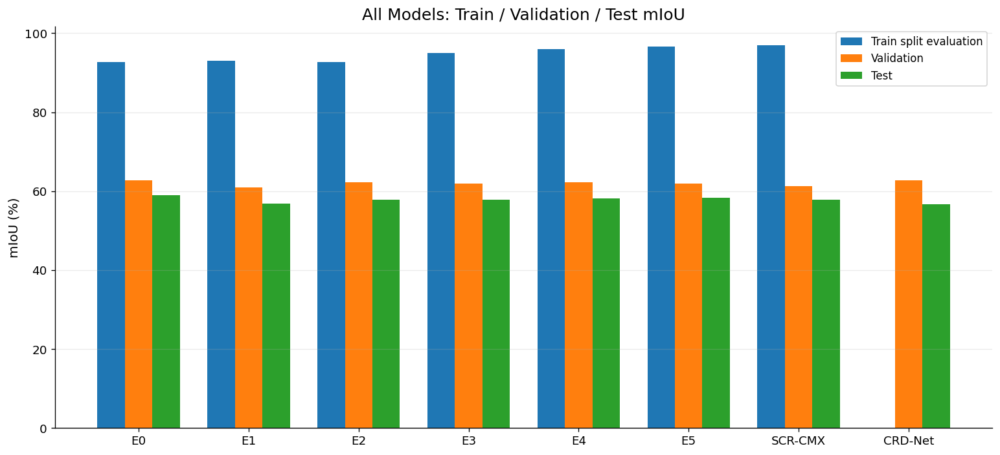

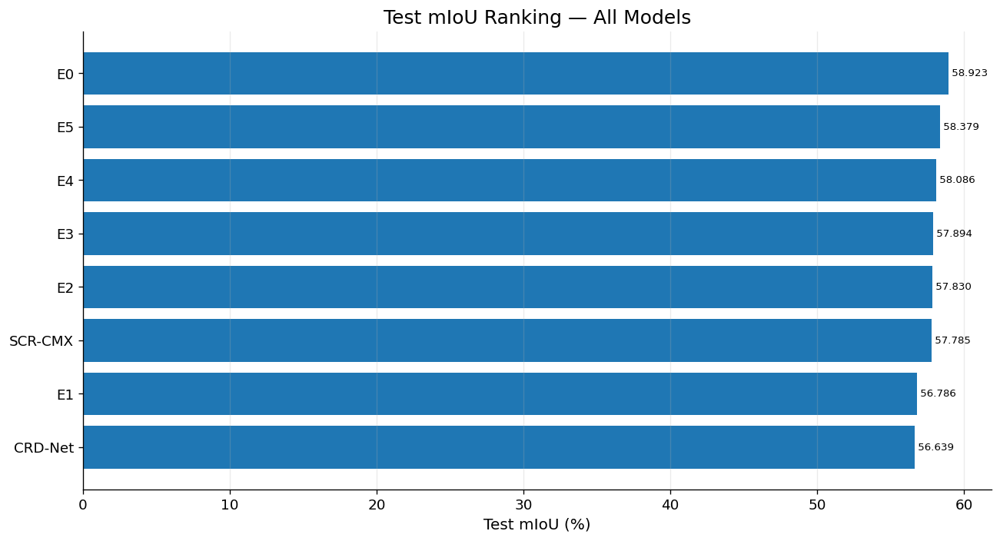

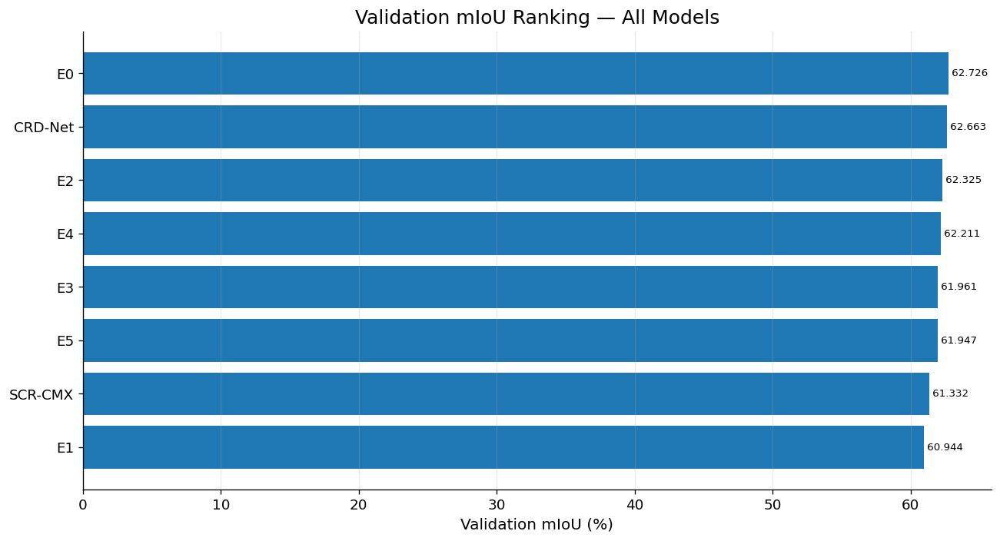

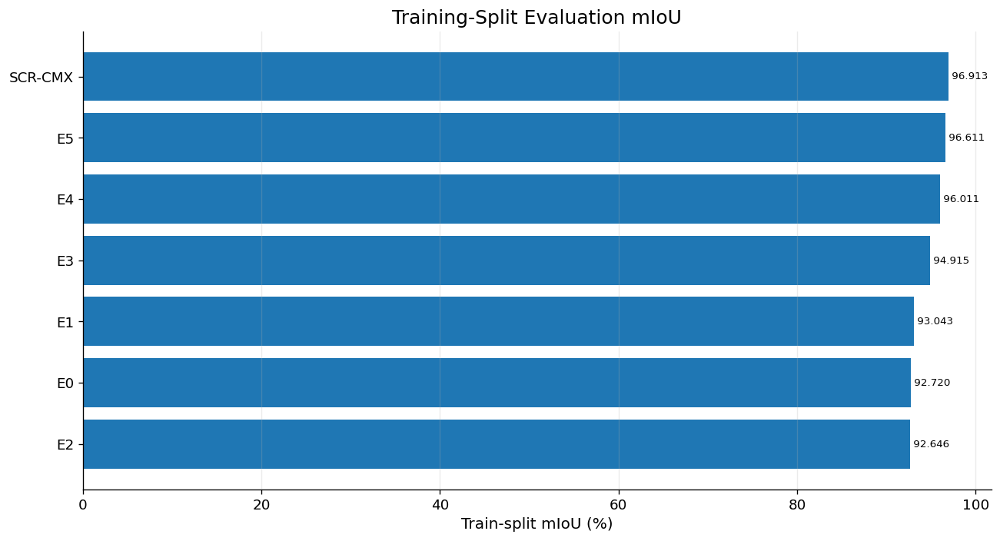

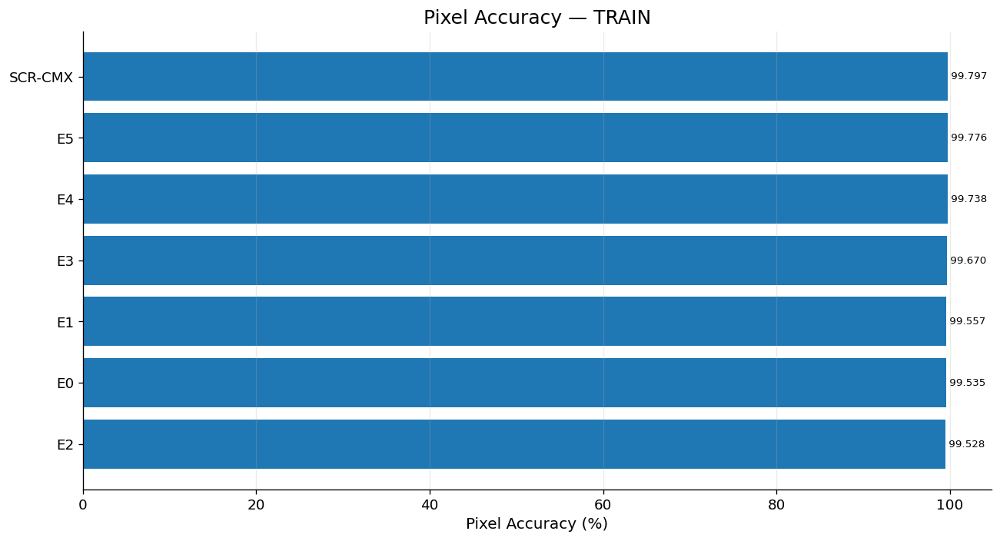

...

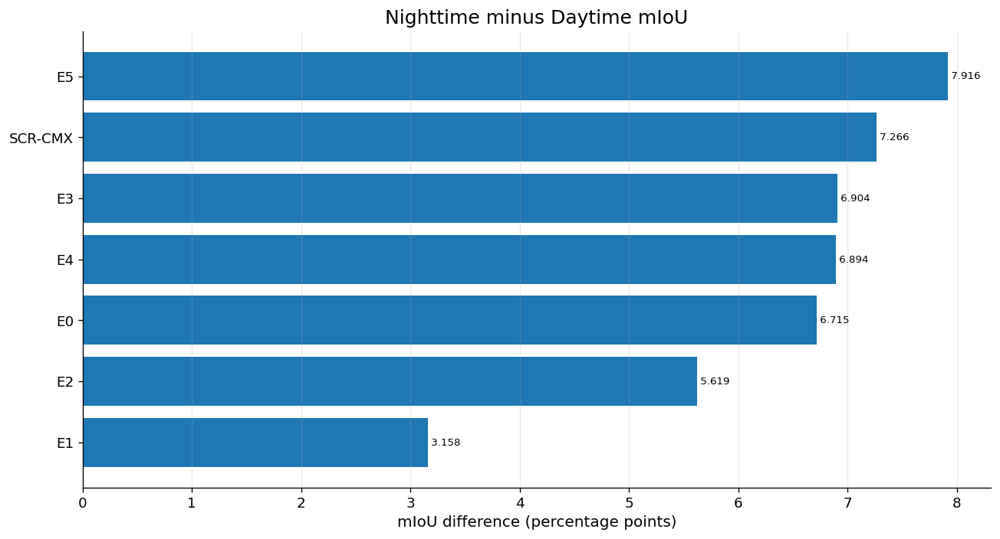

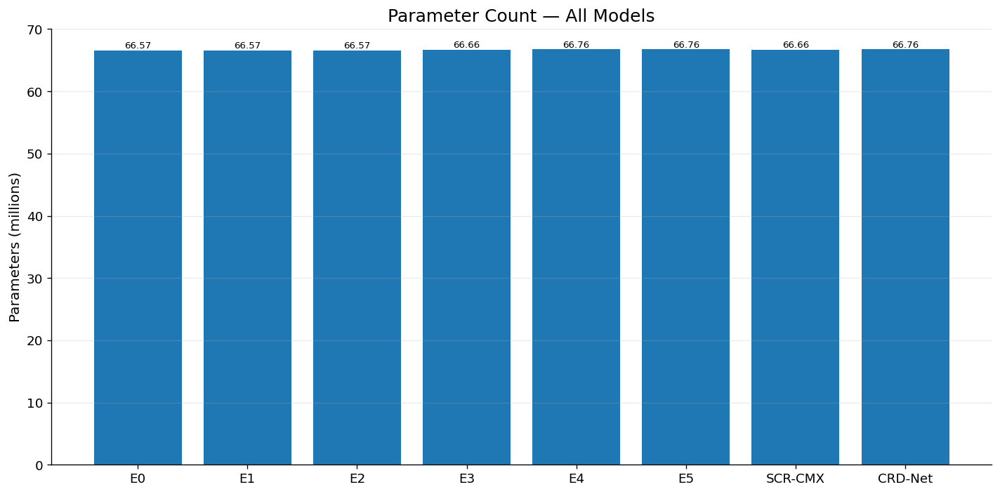

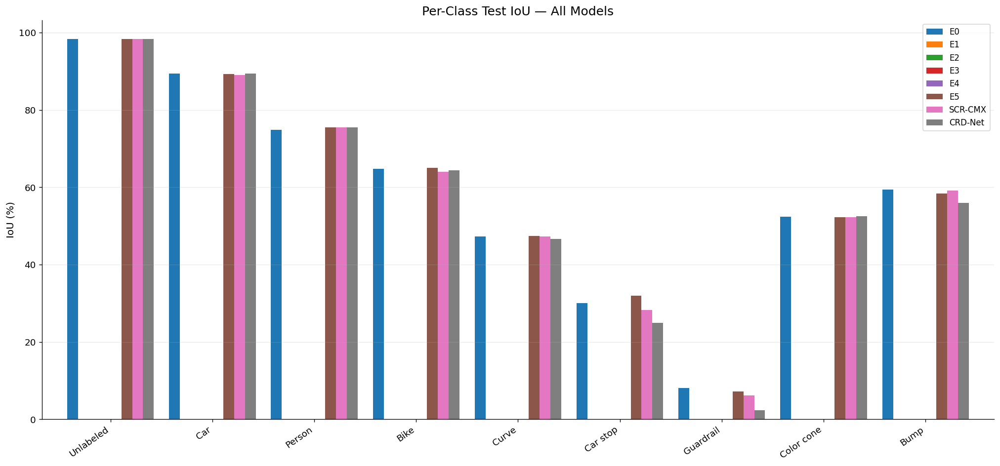

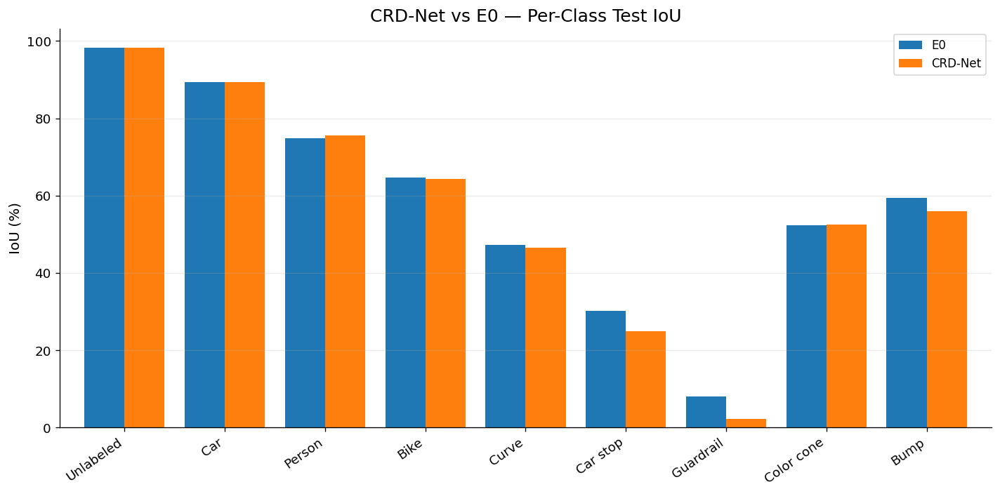

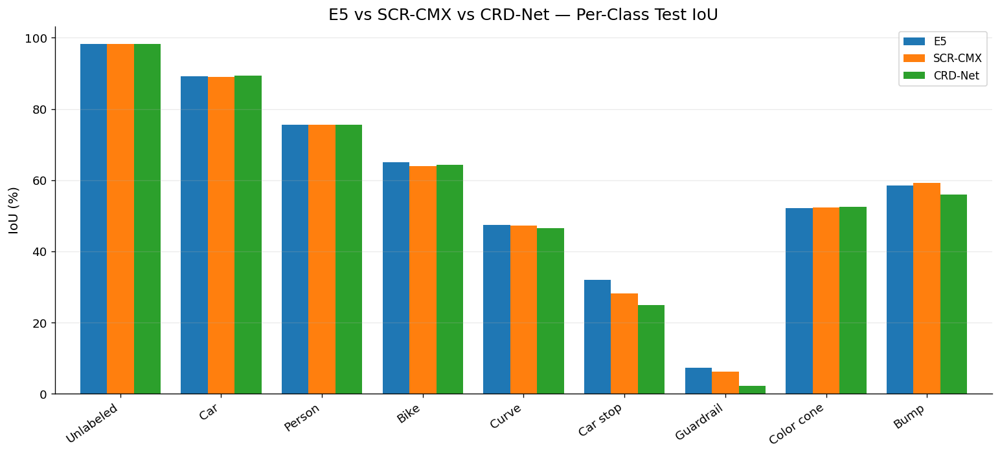


CRD-NET VS E0


,Metric,E0,CRD-Net,CRD-Net minus E0
0,Test mIoU,58.9230,56.6385,-2.2845
1,Validation mIoU,62.7260,62.6627,-0.0633
2,Test pixel accuracy,98.2270,98.2082,-0.0188
3,Test mean pixel accuracy,70.8410,64.1909,-6.6501
4,Test FWIoU,96.7770,96.7246,-0.0524
5,Parameters (M),66.5655,66.7588,0.1933


CRD-Net minus E0 test mIoU: -2.2845 percentage points


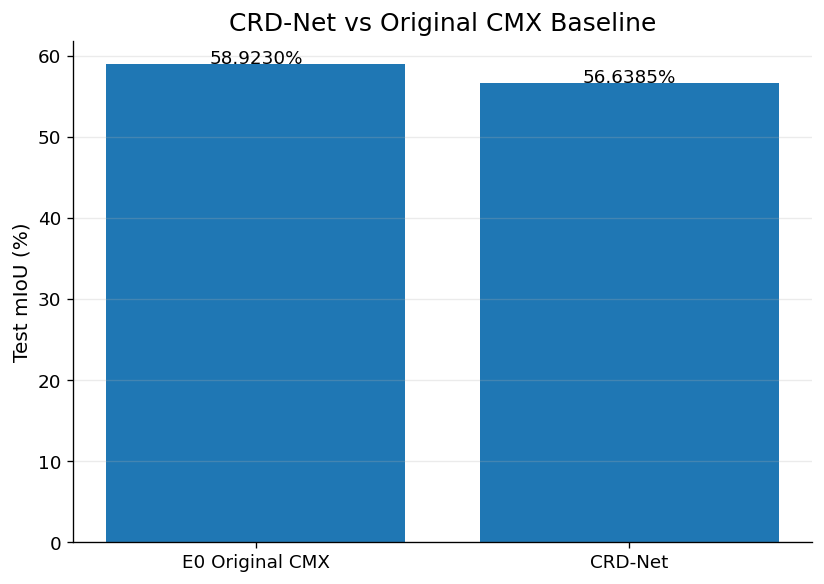

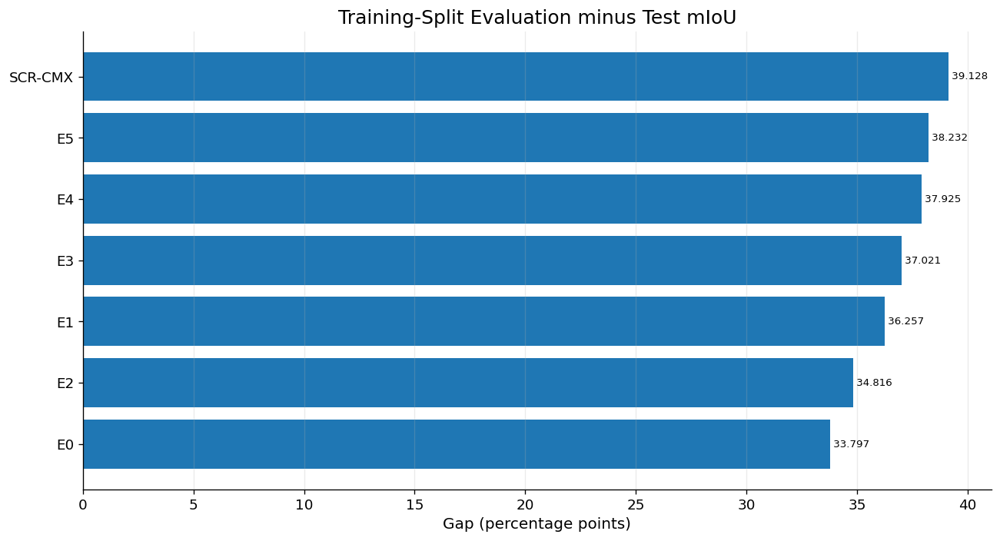

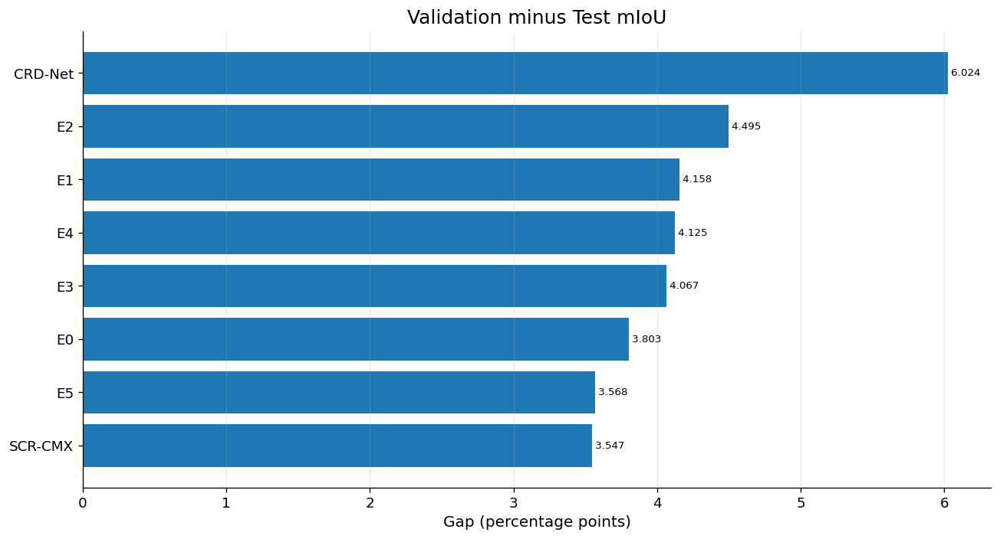


TEST RANKING


,test_miou,val_miou,train_miou,parameters,Test_Rank
Model,,,,,
E0,58.9230,62.7260,92.720,66.5655,1.0
E5,58.3790,61.9470,96.611,66.7588,2.0
E4,58.0860,62.2110,96.011,66.7588,3.0
E3,57.8940,61.9610,94.915,66.6622,4.0
E2,57.8300,62.3250,92.646,66.5655,5.0
SCR-CMX,57.7850,61.3320,96.913,66.6622,6.0
E1,56.7860,60.9440,93.043,66.5655,7.0
CRD-Net,56.6385,62.6627,NaN,66.7588,8.0


ModuleNotFoundError: No module named 'openpyxl'

In [195]:

# =====================================================================
# COMPLETE ALL-MODEL COMPARISON AND VISUALIZATION
# E0, E1, E2, E3, E4, E5, SCR-CMX, CRD-Net
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

OUT = Path("/home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/ALL_MODEL_COMPARISON")
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["E0", "E1", "E2", "E3", "E4", "E5", "SCR-CMX", "CRD-Net"]

# ---------------------------------------------------------------------
# 1. MASTER METRICS
# E0-E5: transcribed from your comparison screenshot.
# SCR-CMX: previously supplied evaluation metrics.
# CRD-Net: previously supplied evaluation metrics.
# All metrics are percentages, except parameter counts in millions.
# ---------------------------------------------------------------------

data = {
    "E0": {
        "train_miou": 92.720, "val_miou": 62.726, "test_miou": 58.923,
        "train_pa": 99.535, "val_pa": 97.732, "test_pa": 98.227,
        "train_mpa": 96.772, "val_mpa": 72.982, "test_mpa": 70.841,
        "train_fwiou": 99.092, "val_fwiou": 95.784, "test_fwiou": 96.777,
        "parameters": 66.565521
    },
    "E1": {
        "train_miou": 93.043, "val_miou": 60.944, "test_miou": 56.786,
        "train_pa": 99.557, "val_pa": 97.684, "test_pa": 98.176,
        "train_mpa": 96.913, "val_mpa": 70.880, "test_mpa": 65.979,
        "train_fwiou": 99.134, "val_fwiou": 95.678, "test_fwiou": 96.664,
        "parameters": 66.565521
    },
    "E2": {
        "train_miou": 92.646, "val_miou": 62.325, "test_miou": 57.830,
        "train_pa": 99.528, "val_pa": 97.731, "test_pa": 98.224,
        "train_mpa": 96.752, "val_mpa": 72.627, "test_mpa": 67.892,
        "train_fwiou": 99.080, "val_fwiou": 95.773, "test_fwiou": 96.768,
        "parameters": 66.565529
    },
    "E3": {
        "train_miou": 94.915, "val_miou": 61.961, "test_miou": 57.894,
        "train_pa": 99.670, "val_pa": 97.723, "test_pa": 98.247,
        "train_mpa": 97.607, "val_mpa": 71.182, "test_mpa": 67.030,
        "train_fwiou": 99.351, "val_fwiou": 95.739, "test_fwiou": 96.792,
        "parameters": 66.662169
    },
    "E4": {
        "train_miou": 96.011, "val_miou": 62.211, "test_miou": 58.086,
        "train_pa": 99.738, "val_pa": 97.758, "test_pa": 98.258,
        "train_mpa": 98.149, "val_mpa": 71.387, "test_mpa": 66.617,
        "train_fwiou": 99.483, "val_fwiou": 95.808, "test_fwiou": 96.816,
        "parameters": 66.758817
    },
    "E5": {
        "train_miou": 96.611, "val_miou": 61.947, "test_miou": 58.379,
        "train_pa": 99.776, "val_pa": 97.716, "test_pa": 98.250,
        "train_mpa": 98.424, "val_mpa": 70.970, "test_mpa": 67.820,
        "train_fwiou": 99.557, "val_fwiou": 95.732, "test_fwiou": 96.795,
        "parameters": 66.758817
    },
    "SCR-CMX": {
        "train_miou": 96.913, "val_miou": 61.332, "test_miou": 57.785,
        "train_pa": 99.797, "val_pa": 97.670, "test_pa": 98.224,
        "train_mpa": 98.520, "val_mpa": 70.304, "test_mpa": 67.102,
        "train_fwiou": 99.598, "val_fwiou": 95.648, "test_fwiou": 96.756,
        "parameters": 66.662169
    },
    "CRD-Net": {
        "train_miou": np.nan, "val_miou": 62.6627, "test_miou": 56.6385,
        "train_pa": np.nan, "val_pa": np.nan, "test_pa": 98.2082,
        "train_mpa": np.nan, "val_mpa": np.nan, "test_mpa": 64.1909,
        "train_fwiou": np.nan, "val_fwiou": np.nan, "test_fwiou": 96.7246,
        "parameters": 66.758817
    }
}

df = pd.DataFrame.from_dict(data, orient="index").reindex(MODELS)
df.index.name = "Model"

# Save master metrics
df.to_csv(OUT / "all_models_master_metrics.csv")

print("\nMASTER METRICS")
display(df.round(4))

# ---------------------------------------------------------------------
# 2. DAY/NIGHT METRICS
# Previously calculated estimates based on RGB brightness thresholds.
# Keep these provisional until the evaluation protocol is verified.
# ---------------------------------------------------------------------

daynight = pd.DataFrame({
    "Model": MODELS,
    "Day_mIoU": [
        51.592, 52.064, 51.558, 50.959,
        51.026, 50.818, 50.598, np.nan
    ],
    "Night_mIoU": [
        58.307, 55.222, 57.177, 57.863,
        57.920, 58.734, 57.864, np.nan
    ]
}).set_index("Model")

daynight.to_csv(OUT / "day_night_metrics_provisional.csv")

# ---------------------------------------------------------------------
# 3. CLASSWISE TEST IoU
# These are recorded values, not newly recomputed evaluations.
# Unknown classwise values remain NaN.
# ---------------------------------------------------------------------

CLASSES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

classwise = pd.DataFrame(index=CLASSES, columns=MODELS, dtype=float)

# E0 values from the paper/table previously shared.
classwise["E0"] = [
    98.3, 89.4, 74.8, 64.7, 47.3, 30.1, 8.1, 52.4, 59.4
]

# E5 recorded test values
classwise["E5"] = [
    98.318, 89.264, 75.482, 65.006, 47.410,
    32.014, 7.243, 52.236, 58.436
]

# SCR-CMX recorded test values
classwise["SCR-CMX"] = [
    98.307, 89.046, 75.508, 64.010, 47.270,
    28.214, 6.214, 52.291, 59.205
]

# CRD-Net recorded test values from the evaluator tuple
classwise["CRD-Net"] = [
    98.2742, 89.4060, 75.5148, 64.3184, 46.5765,
    24.9412, 2.2793, 52.4923, 55.9441
]

classwise.to_csv(OUT / "classwise_test_iou.csv")

# ---------------------------------------------------------------------
# 4. PLOT HELPER
# ---------------------------------------------------------------------

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def bar_chart(series, title, ylabel, filename, horizontal=False):
    series = series.dropna()

    if horizontal:
        series = series.sort_values()
        plt.figure(figsize=(11, 6))
        bars = plt.barh(series.index, series.values)
        plt.xlabel(ylabel)
        plt.title(title)
        plt.grid(axis="x", alpha=0.25)
        for bar, val in zip(bars, series.values):
            plt.text(
                val, bar.get_y() + bar.get_height()/2,
                f" {val:.3f}", va="center", fontsize=8
            )
    else:
        plt.figure(figsize=(12, 6))
        bars = plt.bar(series.index, series.values)
        plt.ylabel(ylabel)
        plt.title(title)
        plt.grid(axis="y", alpha=0.25)
        for bar, val in zip(bars, series.values):
            plt.text(
                bar.get_x() + bar.get_width()/2,
                val, f"{val:.2f}",
                ha="center", va="bottom", fontsize=8
            )

    save_plot(filename)

# ---------------------------------------------------------------------
# 5. TRAIN / VALIDATION / TEST MIOU
# ---------------------------------------------------------------------

x = np.arange(len(MODELS))
width = 0.25

plt.figure(figsize=(13, 6))
for offset, metric, label in [
    (-width, "train_miou", "Train split evaluation"),
    (0, "val_miou", "Validation"),
    (width, "test_miou", "Test")
]:
    plt.bar(x + offset, df[metric], width, label=label)

plt.xticks(x, MODELS)
plt.ylabel("mIoU (%)")
plt.title("All Models: Train / Validation / Test mIoU")
plt.legend()
plt.grid(axis="y", alpha=0.25)
save_plot("01_train_validation_test_miou.png")

# ---------------------------------------------------------------------
# 6. TEST AND VALIDATION MIOU RANKING
# ---------------------------------------------------------------------

bar_chart(
    df["test_miou"],
    "Test mIoU Ranking — All Models",
    "Test mIoU (%)",
    "02_test_miou_ranking.png",
    horizontal=True
)

bar_chart(
    df["val_miou"],
    "Validation mIoU Ranking — All Models",
    "Validation mIoU (%)",
    "03_validation_miou_ranking.png",
    horizontal=True
)

bar_chart(
    df["train_miou"],
    "Training-Split Evaluation mIoU",
    "Train-split mIoU (%)",
    "04_train_miou_ranking.png",
    horizontal=True
)

# ---------------------------------------------------------------------
# 7. PIXEL ACCURACY, MEAN PIXEL ACCURACY, FWIoU
# ---------------------------------------------------------------------

metric_groups = [
    ("pa", "Pixel Accuracy", "05_pixel_accuracy"),
    ("mpa", "Mean Pixel Accuracy", "06_mean_pixel_accuracy"),
    ("fwiou", "Frequency-Weighted IoU", "07_frequency_weighted_iou")
]

for suffix, label, filename_prefix in metric_groups:
    for split in ["train", "val", "test"]:
        column = f"{split}_{suffix}"
        bar_chart(
            df[column],
            f"{label} — {split.upper()}",
            f"{label} (%)",
            f"{filename_prefix}_{split}.png",
            horizontal=True
        )

# ---------------------------------------------------------------------
# 8. DAY / NIGHT COMPARISON (PROVISIONAL)
# ---------------------------------------------------------------------

x = np.arange(len(MODELS))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(
    x - width/2, daynight["Day_mIoU"], width,
    label="Daytime (provisional)"
)
plt.bar(
    x + width/2, daynight["Night_mIoU"], width,
    label="Nighttime (provisional)"
)
plt.xticks(x, MODELS)
plt.ylabel("mIoU (%)")
plt.title("Day vs Night mIoU — Provisional Estimates")
plt.legend()
plt.grid(axis="y", alpha=0.25)
save_plot("08_day_night_miou_provisional.png")

# Day-night gap
daynight["Night_minus_Day"] = (
    daynight["Night_mIoU"] - daynight["Day_mIoU"]
)
bar_chart(
    daynight["Night_minus_Day"],
    "Nighttime minus Daytime mIoU",
    "mIoU difference (percentage points)",
    "09_day_night_gap_provisional.png",
    horizontal=True
)

# ---------------------------------------------------------------------
# 9. PARAMETER COUNTS
# ---------------------------------------------------------------------

bar_chart(
    df["parameters"],
    "Parameter Count — All Models",
    "Parameters (millions)",
    "10_parameter_count.png"
)

# ---------------------------------------------------------------------
# 10. CLASSWISE TEST IoU
# ---------------------------------------------------------------------

ax = classwise.plot(kind="bar", figsize=(17, 8), width=0.85)
ax.set_ylabel("IoU (%)")
ax.set_title("Per-Class Test IoU — All Models")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
save_plot("11_classwise_test_iou_all_models.png")

# CRD-Net vs E0
ax = classwise[["E0", "CRD-Net"]].plot(
    kind="bar", figsize=(12, 6), width=0.8
)
ax.set_ylabel("IoU (%)")
ax.set_title("CRD-Net vs E0 — Per-Class Test IoU")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
save_plot("12_CRD_Net_vs_E0_classwise.png")

# E5 vs SCR-CMX vs CRD-Net
ax = classwise[["E5", "SCR-CMX", "CRD-Net"]].plot(
    kind="bar", figsize=(13, 6), width=0.8
)
ax.set_ylabel("IoU (%)")
ax.set_title("E5 vs SCR-CMX vs CRD-Net — Per-Class Test IoU")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=35, ha="right")
save_plot("13_E5_SCR_CRD_classwise.png")

# ---------------------------------------------------------------------
# 11. CRD-NET VS E0 BASELINE
# ---------------------------------------------------------------------

baseline = df.loc["E0"]
crd = df.loc["CRD-Net"]

baseline_table = pd.DataFrame({
    "Metric": [
        "Test mIoU", "Validation mIoU", "Test pixel accuracy",
        "Test mean pixel accuracy", "Test FWIoU", "Parameters (M)"
    ],
    "E0": [
        baseline["test_miou"], baseline["val_miou"], baseline["test_pa"],
        baseline["test_mpa"], baseline["test_fwiou"], baseline["parameters"]
    ],
    "CRD-Net": [
        crd["test_miou"], crd["val_miou"], crd["test_pa"],
        crd["test_mpa"], crd["test_fwiou"], crd["parameters"]
    ]
})
baseline_table["CRD-Net minus E0"] = (
    baseline_table["CRD-Net"] - baseline_table["E0"]
)

baseline_table.to_csv(OUT / "CRD_Net_vs_E0_comparison.csv")

print("\nCRD-NET VS E0")
display(baseline_table.round(4))

delta = crd["test_miou"] - baseline["test_miou"]
print(f"CRD-Net minus E0 test mIoU: {delta:+.4f} percentage points")

# CRD-Net vs E0 mIoU plot
plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["E0 Original CMX", "CRD-Net"],
    [baseline["test_miou"], crd["test_miou"]]
)
plt.ylabel("Test mIoU (%)")
plt.title("CRD-Net vs Original CMX Baseline")
plt.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, [baseline["test_miou"], crd["test_miou"]]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.08,
        f"{value:.4f}%",
        ha="center"
    )
save_plot("14_CRD_Net_vs_E0_miou.png")

# ---------------------------------------------------------------------
# 12. GENERALIZATION GAP AND RANKING
# ---------------------------------------------------------------------

gaps = df[["train_miou", "val_miou", "test_miou"]].copy()
gaps["Train_minus_Test"] = gaps["train_miou"] - gaps["test_miou"]
gaps["Validation_minus_Test"] = gaps["val_miou"] - gaps["test_miou"]
gaps.to_csv(OUT / "generalization_gaps.csv")

bar_chart(
    gaps["Train_minus_Test"],
    "Training-Split Evaluation minus Test mIoU",
    "Gap (percentage points)",
    "15_train_test_generalization_gap.png",
    horizontal=True
)

bar_chart(
    gaps["Validation_minus_Test"],
    "Validation minus Test mIoU",
    "Gap (percentage points)",
    "16_validation_test_gap.png",
    horizontal=True
)

ranking = df[["test_miou", "val_miou", "train_miou", "parameters"]].copy()
ranking["Test_Rank"] = ranking["test_miou"].rank(
    ascending=False, method="min"
)
ranking = ranking.sort_values("test_miou", ascending=False)
ranking.to_csv(OUT / "test_ranking.csv")

print("\nTEST RANKING")
display(ranking.round(4))

# ---------------------------------------------------------------------
# 13. EXPORT TABLES TO EXCEL
# ---------------------------------------------------------------------

xlsx_path = OUT / "complete_all_model_comparison.xlsx"

with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="All Metrics")
    daynight.to_excel(writer, sheet_name="Day Night Provisional")
    classwise.to_excel(writer, sheet_name="Classwise Test IoU")
    baseline_table.to_excel(writer, sheet_name="CRD vs E0", index=False)
    gaps.to_excel(writer, sheet_name="Generalization Gaps")
    ranking.to_excel(writer, sheet_name="Test Ranking")

print("\n" + "=" * 80)
print("ALL-MODEL PLOTTING COMPLETED")
print("=" * 80)
print("Output directory:", OUT)
print("Excel workbook:", xlsx_path)
print("CSV tables and 16+ high-resolution plots are saved in this folder.")

print("\nIMPORTANT DATA NOTES:")
print("- E0-E5 metrics are taken from your comparison screenshot.")
print("- SCR-CMX metrics are taken from your previously supplied evaluations.")
print("- CRD-Net validation mIoU is the best recorded validation result.")
print("- CRD-Net train-split metrics remain unavailable until evaluated.")
print("- Day/night estimates are provisional, not verified final results.")
print("- Per-class IoU is only populated where values are available.")
print("- Confirm MFNet dataset and identical evaluation splits before publication.")


In [196]:

from pathlib import Path
import subprocess
import re
import json
import pandas as pd
from datetime import datetime

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
EVAL_DIR = ROOT / "evaluation_train_test"
TRAIN_EVALUATOR = EVAL_DIR / "evaluate_crd_train.py"
TEST_LOG = ROOT / "logs" / "crd_test_best.log"

OUT = EVAL_DIR
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("CRD-NET: RECOVER MISSING TRAINING METRICS")
print("=" * 75)

# 1. Verify evaluator exists
if not TRAIN_EVALUATOR.exists():
    raise FileNotFoundError(
        f"Training evaluator not found: {TRAIN_EVALUATOR}\n"
        "Create evaluate_crd_train.py by copying evaluate_crd_test.py "
        "and changing the dataset split from 'test' to 'train'."
    )

# 2. Inspect dataset configuration and split selection
print("\n--- Dataset/evaluator configuration ---")
for file_path in [
    ROOT / "config.py",
    ROOT / "scripts" / "evaluate_crd_train.py",
    TRAIN_EVALUATOR,
]:
    if file_path.exists():
        text = file_path.read_text(errors="ignore")
        print(f"\nFILE: {file_path}")
        for i, line in enumerate(text.splitlines(), 1):
            if any(k in line.lower() for k in [
                "train_source", "eval_source", "test_source",
                "dataset", "mfnet", "tdd", "rgbx", '"train"',
                "'train'", "crd_best_miou"
            ]):
                print(f"{i:4}: {line[:240]}")

# 3. Report available split files
print("\n--- Available split files ---")
for p in ROOT.rglob("*.txt"):
    if p.name.lower() in {"train.txt", "val.txt", "test.txt"}:
        try:
            n = sum(1 for line in p.read_text(errors="ignore").splitlines()
                    if line.strip())
            print(f"{p} | {n} entries")
        except Exception:
            pass

# 4. Run training-split evaluation
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
run_log = OUT / f"crd_train_evaluation_{timestamp}.log"

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(TRAIN_EVALUATOR)
]

print("\n--- Running training evaluation ---")
print("Command:", " ".join(cmd))
print("Log:", run_log)

result = subprocess.run(
    cmd,
    cwd=str(ROOT),
    capture_output=True,
    text=True
)

full_output = (result.stdout or "") + "\n" + (result.stderr or "")
run_log.write_text(full_output, errors="ignore")

print(full_output[-14000:])
print("\nEvaluator exit code:", result.returncode)

if result.returncode != 0:
    raise RuntimeError(
        f"Training evaluation failed. Inspect log: {run_log}"
    )

# 5. Extract the NumPy tuple.
# Expected order:
# (class_IoU_array, mIoU, mean_class_accuracy,
#  frequency_weighted_IoU, mean_pixel_accuracy, pixel_accuracy)

pattern = re.compile(
    r"array\s*\(\s*\[([^\]]+)\]\s*\)\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?",
    re.S
)

matches = list(pattern.finditer(full_output))
if not matches:
    raise ValueError(
        "Could not parse the evaluator's metric tuple automatically.\n"
        f"Full output is saved at: {run_log}\n"
        "Inspect the tuple printed near 'CRD-Net TRAIN metrics'."
    )

match = matches[-1]
class_iou_raw = [
    float(x) for x in re.findall(
        r"[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?",
        match.group(1)
    )
]
values = [float(match.group(i)) for i in range(2, 7)]

if len(class_iou_raw) != 9:
    raise ValueError(
        f"Expected 9 class IoUs, extracted {len(class_iou_raw)}. "
        f"Inspect log: {run_log}"
    )

# Evaluator metrics are fractions; convert to percentages.
metrics = {
    "dataset_split": "train",
    "class_IoU_percent": [round(v * 100, 4) for v in class_iou_raw],
    "mIoU_percent": round(values[0] * 100, 4),
    "mean_class_accuracy_percent": round(values[1] * 100, 4),
    "frequency_weighted_IoU_percent": round(values[2] * 100, 4),
    "mean_pixel_accuracy_percent": round(values[3] * 100, 4),
    "pixel_accuracy_percent": round(values[4] * 100, 4),
    "source_log": str(run_log)
}

classes = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

classwise_df = pd.DataFrame({
    "Class": classes,
    "Train IoU (%)": metrics["class_IoU_percent"]
})

metrics_json = OUT / "crd_train_metrics.json"
classwise_csv = OUT / "crd_train_classwise_iou.csv"
summary_csv = OUT / "crd_train_summary_metrics.csv"

metrics_json.write_text(json.dumps(metrics, indent=2))
classwise_df.to_csv(classwise_csv, index=False)

pd.DataFrame([{
    "Train mIoU (%)": metrics["mIoU_percent"],
    "Train mean class accuracy (%)": metrics["mean_class_accuracy_percent"],
    "Train frequency-weighted IoU (%)":
        metrics["frequency_weighted_IoU_percent"],
    "Train mean pixel accuracy (%)": metrics["mean_pixel_accuracy_percent"],
    "Train pixel accuracy (%)": metrics["pixel_accuracy_percent"]
}]).to_csv(summary_csv, index=False)

print("\n" + "=" * 75)
print("CRD-NET TRAINING-SPLIT METRICS")
print("=" * 75)
print(json.dumps(metrics, indent=2))
display(classwise_df)

print("\nSaved files:")
print(metrics_json)
print(classwise_csv)
print(summary_csv)
print(run_log)


CRD-NET: RECOVER MISSING TRAINING METRICS

--- Dataset/evaluator configuration ---

FILE: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/evaluate_crd_train.py
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
  17: from dataloader.RGBXDataset import RGBXDataset
  45:         prediction = self.sliding_eval_rgbX(
  85:         "train_source": cfg.train_source,
  86:         "eval_source": cfg.eval_source,
  87:         "test_source": cfg.test_source,
  90:     dataset = RGBXDataset(setting, "train", ValPre())
 106:     print("  Training images:", len(dataset))
 113:         dataset,

--- Available split files ---

--- Running training evaluation ---
Command: conda run --no-capture-output -n cmx python /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/evaluate_crd_train.py
Log: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_train_evaluation_20261025_223514.log
9.96it/s]
100%|██████████| 1568/1568 [02:38<00:00,  9.88it/s]
25 22:37:58 Evaluation 

,Class,Train IoU (%)
0,Unlabeled,99.7270
1,Car,98.4204
2,Person,93.7767
3,Bike,94.3015
4,Curve,94.4068
5,Car stop,96.1521
6,Guardrail,96.9695
7,Color cone,92.1760
8,Bump,95.6066



Saved files:
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_train_metrics.json
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_train_classwise_iou.csv
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_train_summary_metrics.csv
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_train_evaluation_20261025_223514.log


In [199]:

from pathlib import Path
import subprocess
import re
import json
import pandas as pd
from datetime import datetime

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
OUT = ROOT / "evaluation_train_test"
OUT.mkdir(parents=True, exist_ok=True)

SOURCE = ROOT / "scripts" / "evaluate_crd_test.py"
VAL_EVALUATOR = OUT / "evaluate_crd_val.py"

# ------------------------------------------------------------
# 1. Create a separate validation evaluator.
# Keep the original test evaluator unchanged.
# ------------------------------------------------------------
if not SOURCE.exists():
    raise FileNotFoundError(f"Original evaluator not found: {SOURCE}")

code = SOURCE.read_text()

old = 'dataset = RGBXDataset(setting, "test", ValPre())'
new = 'dataset = RGBXDataset(setting, "val", ValPre())'

if old not in code:
    raise ValueError(
        "Could not find the expected test dataset constructor. "
        "Inspect evaluate_crd_test.py and adjust the split constructor."
    )

code = code.replace(old, new)
code = code.replace("CRD-Net TEST metrics", "CRD-Net VALIDATION metrics")
code = code.replace("Test images:", "Validation images:")
code = code.replace("test evaluation", "validation evaluation")
code = code.replace("crd_test_best.log", "crd_val_best.log")

VAL_EVALUATOR.write_text(code)

print("Validation evaluator created:", VAL_EVALUATOR)

# ------------------------------------------------------------
# 2. Inspect configuration to check dataset paths.
# ------------------------------------------------------------
config = ROOT / "config.py"
if config.exists():
    print("\nDataset configuration:")
    for i, line in enumerate(config.read_text(errors="ignore").splitlines(), 1):
        if any(term in line.lower() for term in [
            "train_source", "eval_source", "test_source", "mfnet", "tdd"
        ]):
            print(f"{i:4}: {line}")

# ------------------------------------------------------------
# 3. Run validation evaluation.
# ------------------------------------------------------------
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
log_path = OUT / f"crd_val_evaluation_{stamp}.log"

cmd = [
    "conda", "run", "--no-capture-output", "-n", "cmx",
    "python", str(VAL_EVALUATOR)
]

print("\nRunning CRD-Net validation evaluation...")
result = subprocess.run(
    cmd,
    cwd=str(ROOT),
    capture_output=True,
    text=True
)

output = (result.stdout or "") + "\n" + (result.stderr or "")
log_path.write_text(output, errors="ignore")
print(output[-12000:])

if result.returncode != 0:
    raise RuntimeError(
        f"Validation evaluation failed. See: {log_path}"
    )

# ------------------------------------------------------------
# 4. Parse the evaluation tuple.
# Expected:
# (class IoU array, mIoU, mean class accuracy,
#  frequency-weighted IoU, mean pixel accuracy, pixel accuracy)
# ------------------------------------------------------------
pattern = re.compile(
    r"array\s*\(\s*\[([^\]]+)\]\s*\)\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?\s*,\s*"
    r"(?:np\.float64\()?([0-9.eE+-]+)\)?",
    re.S
)

matches = list(pattern.finditer(output))
if not matches:
    raise ValueError(
        "Could not parse the metric tuple automatically. "
        f"Inspect the log: {log_path}"
    )

m = matches[-1]
class_iou = [
    float(v) for v in re.findall(
        r"[-+]?(?:\d+\.\d*|\.\d+|\d+)(?:[eE][-+]?\d+)?",
        m.group(1)
    )
]
values = [float(m.group(i)) for i in range(2, 7)]

if len(class_iou) != 9:
    raise ValueError(
        f"Expected 9 class IoU values; found {len(class_iou)}. "
        f"Inspect {log_path}"
    )

classes = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

metrics = {
    "dataset_split": "val",
    "class_IoU_percent": [round(v * 100, 4) for v in class_iou],
    "mIoU_percent": round(values[0] * 100, 4),
    "mean_class_accuracy_percent": round(values[1] * 100, 4),
    "frequency_weighted_IoU_percent": round(values[2] * 100, 4),
    "mean_pixel_accuracy_percent": round(values[3] * 100, 4),
    "pixel_accuracy_percent": round(values[4] * 100, 4),
    "source_log": str(log_path)
}

# ------------------------------------------------------------
# 5. Save validation metrics.
# ------------------------------------------------------------
json_path = OUT / "crd_val_metrics.json"
summary_path = OUT / "crd_val_summary_metrics.csv"
classwise_path = OUT / "crd_val_classwise_iou.csv"

json_path.write_text(json.dumps(metrics, indent=2))

pd.DataFrame([{
    "Validation mIoU (%)": metrics["mIoU_percent"],
    "Validation mean class accuracy (%)":
        metrics["mean_class_accuracy_percent"],
    "Validation frequency-weighted IoU (%)":
        metrics["frequency_weighted_IoU_percent"],
    "Validation mean pixel accuracy (%)":
        metrics["mean_pixel_accuracy_percent"],
    "Validation pixel accuracy (%)":
        metrics["pixel_accuracy_percent"]
}]).to_csv(summary_path, index=False)

pd.DataFrame({
    "Class": classes,
    "Validation IoU (%)": metrics["class_IoU_percent"]
}).to_csv(classwise_path, index=False)

print("\n" + "=" * 70)
print("CRD-NET VALIDATION METRICS")
print("=" * 70)
print(json.dumps(metrics, indent=2))
display(pd.DataFrame({
    "Class": classes,
    "Validation IoU (%)": metrics["class_IoU_percent"]
}))

print("\nSaved:")
print(json_path)
print(summary_path)
print(classwise_path)
print(log_path)


Validation evaluator created: /home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/evaluate_crd_val.py

Running CRD-Net validation evaluation...
%|███▏      | 127/392 [00:13<00:26,  9.83it/s]
100%|██████████| 392/392 [00:40<00:00,  9.70it/s]
25 22:42:10 Evaluation Elapsed Time: 40.43s


CRD-NET VALIDATION METRICS
{
  "dataset_split": "val",
  "class_IoU_percent": [
    97.7872,
    86.9194,
    72.2516,
    73.2014,
    40.0828,
    32.0333,
    48.2677,
    60.8986,
    52.5222
  ],
  "mIoU_percent": 62.6627,
  "mean_class_accuracy_percent": 58.2721,
  "frequency_weighted_IoU_percent": 95.7972,
  "mean_pixel_accuracy_percent": 72.0432,
  "pixel_accuracy_percent": 97.7523,
  "source_log": "/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_val_evaluation_20261025_224124.log"
}


,Class,Validation IoU (%)
0,Unlabeled,97.7872
1,Car,86.9194
2,Person,72.2516
3,Bike,73.2014
4,Curve,40.0828
5,Car stop,32.0333
6,Guardrail,48.2677
7,Color cone,60.8986
8,Bump,52.5222



Saved:
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_val_metrics.json
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_val_summary_metrics.csv
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_val_classwise_iou.csv
/home/cse-sdpl/Downloads/CRD_Net/evaluation_train_test/crd_val_evaluation_20261025_224124.log


ALL-MODEL COMPARISON TABLE


,Model,mIoU_test,mIoU_train,mIoU_val,PA_test,PA_train,PA_val,mPA_test,mPA_train,mPA_val,FWIoU_test,FWIoU_train,FWIoU_val
0,E0,58.9230,92.7200,62.7260,98.2270,99.5350,97.7320,70.8410,96.7720,72.9820,96.7770,99.0920,95.7840
1,E1,56.7860,93.0430,60.9440,98.1760,99.5570,97.6840,65.9790,96.9130,70.8800,96.6640,99.1340,95.6780
2,E2,57.8300,92.6460,62.3250,98.2240,99.5280,97.7310,67.8920,96.7520,72.6270,96.7680,99.0800,95.7730
3,E3,57.8940,94.9150,61.9610,98.2470,99.6700,97.7230,67.0300,97.6070,71.1820,96.7920,99.3510,95.7390
4,E4,58.0860,96.0110,62.2110,98.2580,99.7380,97.7580,66.6170,98.1490,71.3870,96.8160,99.4830,95.8080
5,E5,58.3790,96.6110,61.9470,98.2500,99.7760,97.7160,67.8200,98.4240,70.9700,96.7950,99.5570,95.7320
6,SCR-CMX,57.7850,96.9130,61.3320,98.2240,99.7970,97.6700,67.1020,98.5200,70.3040,96.7560,99.5980,95.6480
7,CRD-Net,56.6385,95.7263,62.6627,98.2082,99.7362,97.7523,64.1909,98.2928,72.0432,96.7246,99.4796,95.7972


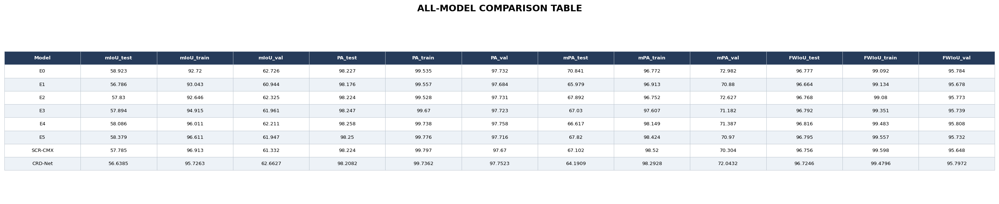


MODEL PARAMETER COUNTS


,Model,Parameters_M
0,E0,66.565521 M
1,E1,66.565521 M
2,E2,66.565529 M
3,E3,66.662169 M
4,SCR-CMX,66.662169 M
5,E4,66.758817 M
6,E5,66.758817 M
7,CRD-Net,66.758817 M



BEST MODEL BY EACH METRIC
Highest Test mIoU: E0 = 58.9230%
Highest Validation mIoU: E0 = 62.7260%
Highest Training mIoU: SCR-CMX = 96.9130%
Highest Test Pixel Accuracy: E4 = 98.2580%
Highest Test Mean Pixel Accuracy: E0 = 70.8410%
Highest Test FWIoU: E4 = 96.8160%

GENERALIZATION GAP TABLE


,Model,mIoU_train,mIoU_val,mIoU_test,Train-Test Gap (pp),Val-Test Gap (pp)
0,E0,92.7200,62.7260,58.9230,33.7970,3.8030
1,E1,93.0430,60.9440,56.7860,36.2570,4.1580
2,E2,92.6460,62.3250,57.8300,34.8160,4.4950
3,E3,94.9150,61.9610,57.8940,37.0210,4.0670
4,E4,96.0110,62.2110,58.0860,37.9250,4.1250
5,E5,96.6110,61.9470,58.3790,38.2320,3.5680
6,SCR-CMX,96.9130,61.3320,57.7850,39.1280,3.5470
7,CRD-Net,95.7263,62.6627,56.6385,39.0878,6.0242



FILES SAVED SUCCESSFULLY:
CSV table:       /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/ALL_MODEL_COMPARISON/all_model_comparison.csv
Excel workbook:  /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/ALL_MODEL_COMPARISON/all_model_comparison.xlsx
PNG table:       /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/ALL_MODEL_COMPARISON/all_model_comparison_table.png
Gap analysis:    /home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/ALL_MODEL_COMPARISON/model_generalization_gaps.csv


In [202]:

# ================================================================
# ALL-MODEL COMPARISON TABLE
# E0-E5 + SCR-CMX + CRD-Net
# ================================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------
OUTPUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_PRESENTATION_RESULTS/"
    "ALL_MODEL_COMPARISON"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. ALL MODEL METRICS
# All values are percentages except parameters (M).
# ------------------------------------------------
data = [
    {
        "Model": "E0",
        "mIoU_test": 58.9230,
        "mIoU_train": 92.7200,
        "mIoU_val": 62.7260,
        "PA_test": 98.2270,
        "PA_train": 99.5350,
        "PA_val": 97.7320,
        "mPA_test": 70.8410,
        "mPA_train": 96.7720,
        "mPA_val": 72.9820,
        "FWIoU_test": 96.7770,
        "FWIoU_train": 99.0920,
        "FWIoU_val": 95.7840,
        "Parameters_M": 66.565521,
    },
    {
        "Model": "E1",
        "mIoU_test": 56.7860,
        "mIoU_train": 93.0430,
        "mIoU_val": 60.9440,
        "PA_test": 98.1760,
        "PA_train": 99.5570,
        "PA_val": 97.6840,
        "mPA_test": 65.9790,
        "mPA_train": 96.9130,
        "mPA_val": 70.8800,
        "FWIoU_test": 96.6640,
        "FWIoU_train": 99.1340,
        "FWIoU_val": 95.6780,
        "Parameters_M": 66.565521,
    },
    {
        "Model": "E2",
        "mIoU_test": 57.8300,
        "mIoU_train": 92.6460,
        "mIoU_val": 62.3250,
        "PA_test": 98.2240,
        "PA_train": 99.5280,
        "PA_val": 97.7310,
        "mPA_test": 67.8920,
        "mPA_train": 96.7520,
        "mPA_val": 72.6270,
        "FWIoU_test": 96.7680,
        "FWIoU_train": 99.0800,
        "FWIoU_val": 95.7730,
        "Parameters_M": 66.565529,
    },
    {
        "Model": "E3",
        "mIoU_test": 57.8940,
        "mIoU_train": 94.9150,
        "mIoU_val": 61.9610,
        "PA_test": 98.2470,
        "PA_train": 99.6700,
        "PA_val": 97.7230,
        "mPA_test": 67.0300,
        "mPA_train": 97.6070,
        "mPA_val": 71.1820,
        "FWIoU_test": 96.7920,
        "FWIoU_train": 99.3510,
        "FWIoU_val": 95.7390,
        "Parameters_M": 66.662169,
    },
    {
        "Model": "E4",
        "mIoU_test": 58.0860,
        "mIoU_train": 96.0110,
        "mIoU_val": 62.2110,
        "PA_test": 98.2580,
        "PA_train": 99.7380,
        "PA_val": 97.7580,
        "mPA_test": 66.6170,
        "mPA_train": 98.1490,
        "mPA_val": 71.3870,
        "FWIoU_test": 96.8160,
        "FWIoU_train": 99.4830,
        "FWIoU_val": 95.8080,
        "Parameters_M": 66.758817,
    },
    {
        "Model": "E5",
        "mIoU_test": 58.3790,
        "mIoU_train": 96.6110,
        "mIoU_val": 61.9470,
        "PA_test": 98.2500,
        "PA_train": 99.7760,
        "PA_val": 97.7160,
        "mPA_test": 67.8200,
        "mPA_train": 98.4240,
        "mPA_val": 70.9700,
        "FWIoU_test": 96.7950,
        "FWIoU_train": 99.5570,
        "FWIoU_val": 95.7320,
        "Parameters_M": 66.758817,
    },
    {
        "Model": "SCR-CMX",
        "mIoU_test": 57.7850,
        "mIoU_train": 96.9130,
        "mIoU_val": 61.3320,
        "PA_test": 98.2240,
        "PA_train": 99.7970,
        "PA_val": 97.6700,
        "mPA_test": 67.1020,
        "mPA_train": 98.5200,
        "mPA_val": 70.3040,
        "FWIoU_test": 96.7560,
        "FWIoU_train": 99.5980,
        "FWIoU_val": 95.6480,
        "Parameters_M": 66.662169,
    },
    {
        "Model": "CRD-Net",
        "mIoU_test": 56.6385,
        "mIoU_train": 95.7263,
        "mIoU_val": 62.6627,
        "PA_test": 98.2082,
        "PA_train": 99.7362,
        "PA_val": 97.7523,
        "mPA_test": 64.1909,
        "mPA_train": 98.2928,
        "mPA_val": 72.0432,
        "FWIoU_test": 96.7246,
        "FWIoU_train": 99.4796,
        "FWIoU_val": 95.7972,
        "Parameters_M": 66.758817,
    },
]

df = pd.DataFrame(data)

# ------------------------------------------------
# 3. TABLE IN THE SAME COLUMN ORDER AS YOUR IMAGE
# ------------------------------------------------
comparison_columns = [
    "Model",
    "mIoU_test", "mIoU_train", "mIoU_val",
    "PA_test", "PA_train", "PA_val",
    "mPA_test", "mPA_train", "mPA_val",
    "FWIoU_test", "FWIoU_train", "FWIoU_val",
]

comparison_df = df[comparison_columns].copy()

print("=" * 140)
print("ALL-MODEL COMPARISON TABLE")
print("=" * 140)

display(
    comparison_df.style
    .format({
        col: "{:.4f}" for col in comparison_columns
        if col != "Model"
    })
    .set_caption("ALL-MODEL COMPARISON TABLE")
    .set_properties(**{
        "text-align": "center",
        "padding": "6px",
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "10px"),
            ],
        },
        {
            "selector": "th",
            "props": [
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("background-color", "#e8edf3"),
            ],
        },
    ])
)

# ------------------------------------------------
# 4. SAVE CSV AND EXCEL
# ------------------------------------------------
csv_path = OUTPUT_DIR / "all_model_comparison.csv"
excel_path = OUTPUT_DIR / "all_model_comparison.xlsx"

comparison_df.to_csv(csv_path, index=False)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    comparison_df.to_excel(
        writer, sheet_name="All Model Comparison", index=False
    )
    df[["Model", "Parameters_M"]].to_excel(
        writer, sheet_name="Parameters", index=False
    )

    # Format Excel columns
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.utils import get_column_letter

    for ws in writer.book.worksheets:
        ws.freeze_panes = "B2"
        ws.auto_filter.ref = ws.dimensions

        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill(
                "solid", fgColor="263B5A"
            )
            cell.alignment = Alignment(
                horizontal="center", vertical="center"
            )

        for col_idx in range(1, ws.max_column + 1):
            max_length = max(
                len(str(ws.cell(row=r, column=col_idx).value or ""))
                for r in range(1, ws.max_row + 1)
            )
            ws.column_dimensions[
                get_column_letter(col_idx)
            ].width = min(max_length + 3, 22)

# ------------------------------------------------
# 5. SAVE A HIGH-RESOLUTION TABLE IMAGE
# ------------------------------------------------
fig, ax = plt.subplots(figsize=(23, 4.8))
ax.axis("off")

table = ax.table(
    cellText=comparison_df.round(4).values,
    colLabels=comparison_df.columns,
    rowLabels=None,
    cellLoc="center",
    colLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.0, 1.65)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#263B5A")
    else:
        cell.set_facecolor(
            "#EDF2F7" if row % 2 == 0 else "white"
        )

    cell.set_edgecolor("#B8C2CC")
    cell.set_linewidth(0.5)

ax.set_title(
    "ALL-MODEL COMPARISON TABLE",
    fontsize=15,
    fontweight="bold",
    pad=18,
)

plt.tight_layout()

png_path = OUTPUT_DIR / "all_model_comparison_table.png"
plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. PARAMETER COUNT TABLE
# ------------------------------------------------
print("\nMODEL PARAMETER COUNTS")
display(
    df[["Model", "Parameters_M"]]
    .sort_values("Parameters_M")
    .reset_index(drop=True)
    .style.format({"Parameters_M": "{:.6f} M"})
)

# ------------------------------------------------
# 7. BEST MODEL SUMMARY
# ------------------------------------------------
print("\nBEST MODEL BY EACH METRIC")
best_metrics = {
    "Highest Test mIoU": ("mIoU_test", "max"),
    "Highest Validation mIoU": ("mIoU_val", "max"),
    "Highest Training mIoU": ("mIoU_train", "max"),
    "Highest Test Pixel Accuracy": ("PA_test", "max"),
    "Highest Test Mean Pixel Accuracy": ("mPA_test", "max"),
    "Highest Test FWIoU": ("FWIoU_test", "max"),
}

for title, (metric, operation) in best_metrics.items():
    idx = df[metric].idxmax()
    print(f"{title}: {df.loc[idx, 'Model']} = {df.loc[idx, metric]:.4f}%")

# ------------------------------------------------
# 8. TEST VS VALIDATION GENERALIZATION GAP
# ------------------------------------------------
gap_df = df[["Model", "mIoU_train", "mIoU_val", "mIoU_test"]].copy()
gap_df["Train-Test Gap (pp)"] = (
    gap_df["mIoU_train"] - gap_df["mIoU_test"]
)
gap_df["Val-Test Gap (pp)"] = (
    gap_df["mIoU_val"] - gap_df["mIoU_test"]
)

gap_path = OUTPUT_DIR / "model_generalization_gaps.csv"
gap_df.to_csv(gap_path, index=False)

print("\nGENERALIZATION GAP TABLE")
display(gap_df.round(4))

# ------------------------------------------------
# 9. FILE LOCATIONS
# ------------------------------------------------
print("\nFILES SAVED SUCCESSFULLY:")
print("CSV table:      ", csv_path)
print("Excel workbook: ", excel_path)
print("PNG table:      ", png_path)
print("Gap analysis:   ", gap_path)


In [201]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]━━ 1/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.


In [203]:

from pathlib import Path

# Project directories
DOWNLOADS = Path("/home/cse-sdpl/Downloads")

E0_DIR = DOWNLOADS / "CMX_Original"
CRD_DIR = DOWNLOADS / "CRD_Net"

# Checkpoints
E0_CHECKPOINT = (
    E0_DIR / "log_TDD_mit_b2" / "checkpoint" / "epoch-100.pth"
)
CRD_CHECKPOINT = CRD_DIR / "checkpoints" / "crd_best_miou.pth"

# Enter the paths to the SAME scene in both modalities
RGB_PATH = Path("/path/to/rgb_image.png")
THERMAL_PATH = Path("/path/to/thermal_image.png")

# Optional ground truth label; leave None if unavailable
LABEL_PATH = None
# Example:
# LABEL_PATH = Path("/path/to/label.png")

print("E0 checkpoint exists:", E0_CHECKPOINT.exists(), E0_CHECKPOINT)
print("CRD checkpoint exists:", CRD_CHECKPOINT.exists(), CRD_CHECKPOINT)
print("RGB image exists:", RGB_PATH.exists(), RGB_PATH)
print("Thermal image exists:", THERMAL_PATH.exists(), THERMAL_PATH)


E0 checkpoint exists: True /home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/checkpoint/epoch-100.pth
CRD checkpoint exists: True /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
RGB image exists: False /path/to/rgb_image.png
Thermal image exists: False /path/to/thermal_image.png


In [204]:

from pathlib import Path

ROOTS = [
    Path("/home/cse-sdpl/Downloads/CMX_Original"),
    Path("/home/cse-sdpl/Downloads/CRD_Net"),
]

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

for root in ROOTS:
    print(f"\n{'=' * 75}\nSearching: {root}\n{'=' * 75}")

    if not root.exists():
        print("Folder not found.")
        continue

    found = 0
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in IMAGE_EXTS:
            continue

        parts = [x.lower() for x in p.parts]
        if any(word in part for part in parts for word in
               ["rgb", "visible", "thermal", "infrared", "label", "annotation"]):
            print(p)
            found += 1
            if found >= 35:
                print("...more files exist; showing first 35 matches.")
                break

    if found == 0:
        print("No images found with RGB/thermal/label-like folder names.")



Searching: /home/cse-sdpl/Downloads/CMX_Original
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01088N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00811N_flip.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01252N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00755N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00979N_flip.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00557D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01266N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00458D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00167D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01215N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00822N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01425D.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00970N_flip.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/00425D_flip.png
/home/

In [205]:

from pathlib import Path

DATASET = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
IMAGE_ID = "01088N"

print("Dataset folders:")
for p in DATASET.iterdir():
    if p.is_dir():
        print(" ", p.name)

print(f"\nFiles matching {IMAGE_ID}:\n")
for p in DATASET.rglob("*"):
    if p.is_file() and IMAGE_ID in p.stem:
        print(p)


Dataset folders:
  RGB
  Thermal
  Label

Files matching 01088N:

/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB/01088N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal/01088N.png
/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label/01088N.png


In [206]:

from pathlib import Path

FILES_TO_INSPECT = [
    Path("/home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py"),
    Path("/home/cse-sdpl/Downloads/CRD_Net/config.py"),
    Path("/home/cse-sdpl/Downloads/CMX_Original/eval.py"),
    Path("/home/cse-sdpl/Downloads/CMX_Original/config.py"),
]

for file in FILES_TO_INSPECT:
    print("\n" + "=" * 90)
    print("FILE:", file)
    print("=" * 90)

    if file.exists():
        lines = file.read_text(errors="ignore").splitlines()
        keywords = (
            "checkpoint", "load_state_dict", "build_model",
            "get_model", "RGBXDataset", "DataLoader",
            "pretrained", "inference", "predict", "softmax",
            "argmax", "image_height", "image_width", "modal_x"
        )

        matched = [
            (i, line) for i, line in enumerate(lines, 1)
            if any(word.lower() in line.lower() for word in keywords)
        ]

        for i, line in matched[:45]:
            print(f"{i:4}: {line}")
    else:
        print("File not found.")



FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  43:         thermal = data["modal_x"]
  45:         prediction = self.sliding_eval_rgbX(
  49:         hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
  69:     if not CRD_CHECKPOINT.is_file():
  70:         raise FileNotFoundError(f"CRD checkpoint not found: {CRD_CHECKPOINT}")
  90:     dataset = RGBXDataset(setting, "test", ValPre())
  95:     # Verify CRD checkpoint structure before evaluation.
  96:     checkpoint = torch.load(CRD_CHECKPOINT, map_location="cpu", weights_only=False)
  97:     state = checkpoint["model"]
  98:     incompatible = model.load_state_dict(state, strict=True)
 100:         raise RuntimeError(f"Checkpoint mismatch: {incompatible}")
 104:     print("  Checkpoint:", CRD_CHECKPOINT)
 105:     print(" 

RGB size: (640, 480)
Thermal size: (640, 480)
Label size: (640, 480)
Label pixel values: [0 1 2 3]


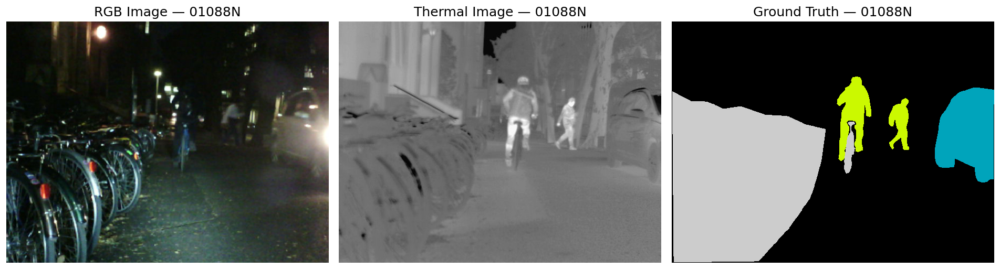

In [207]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

DATASET = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_PATH = DATASET / "RGB" / "01088N.png"
THERMAL_PATH = DATASET / "Thermal" / "01088N.png"
LABEL_PATH = DATASET / "Label" / "01088N.png"

rgb = Image.open(RGB_PATH).convert("RGB")
thermal = Image.open(THERMAL_PATH)
label = Image.open(LABEL_PATH)

print("RGB size:", rgb.size)
print("Thermal size:", thermal.size)
print("Label size:", label.size)
print("Label pixel values:", np.unique(np.array(label))[:30])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb)
axes[0].set_title("RGB Image — 01088N")
axes[1].imshow(thermal, cmap="gray")
axes[1].set_title("Thermal Image — 01088N")
axes[2].imshow(label, cmap="nipy_spectral", interpolation="nearest")
axes[2].set_title("Ground Truth — 01088N")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [208]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. PATHS — STTDD / TDD DATASET
# ============================================================
DOWNLOADS = Path("/home/cse-sdpl/Downloads")

E0_ROOT = DOWNLOADS / "CMX_Original"
CRD_ROOT = DOWNLOADS / "CRD_Net"
DATA = E0_ROOT / "datasets" / "TDD"

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"
TEST_FILE = DATA / "test.txt"

E0_CHECKPOINT = (
    E0_ROOT / "log_TDD_mit_b2" / "checkpoint" / "epoch-100.pth"
)
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"

# Output folder
OUT_DIR = DOWNLOADS / "CRD_Net" / "qualitative_comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. VERIFY PATHS
# ============================================================
for name, path in {
    "RGB directory": RGB_DIR,
    "Thermal directory": THERMAL_DIR,
    "Label directory": LABEL_DIR,
    "Validation split": VAL_FILE,
    "E0 checkpoint": E0_CHECKPOINT,
    "CRD-Net checkpoint": CRD_CHECKPOINT,
}.items():
    print(f"{name}: {'OK' if path.exists() else 'NOT FOUND'} — {path}")

# ============================================================
# 3. FIND PREDICTION DIRECTORIES
# ============================================================
# Add or change these paths if your evaluation scripts save
# predictions in a different location.
E0_PREDICTION_CANDIDATES = [
    E0_ROOT / "predictions_E0_test",
    E0_ROOT / "predictions_TDD_epoch100",
    E0_ROOT / "predictions_E0_val",
    E0_ROOT / "predictions",
]

CRD_PREDICTION_CANDIDATES = [
    CRD_ROOT / "predictions_CRD_test",
    CRD_ROOT / "predictions_crd_test",
    CRD_ROOT / "predictions_CRD_val",
    CRD_ROOT / "predictions",
    CRD_ROOT / "evaluation_train_test" / "predictions",
]

def choose_prediction_dir(candidates, model_name):
    existing = [p for p in candidates if p.is_dir()]

    if not existing:
        raise FileNotFoundError(
            f"No prediction folder found for {model_name}.\n"
            "Run the model's evaluation/inference script first, "
            "or add its actual prediction folder to the candidate list."
        )

    # Prefer the folder containing the most PNG masks.
    existing.sort(
        key=lambda p: sum(1 for _ in p.rglob("*.png")),
        reverse=True
    )
    selected = existing[0]

    print(
        f"{model_name} prediction folder: {selected} "
        f"({sum(1 for _ in selected.rglob('*.png'))} PNG files)"
    )
    return selected

E0_DIR = choose_prediction_dir(E0_PREDICTION_CANDIDATES, "E0")
CRD_DIR = choose_prediction_dir(CRD_PREDICTION_CANDIDATES, "CRD-Net")

# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================
def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {image_id}.png under {folder}"
        )
    return matches[0]

def read_rgb(image_id):
    return np.asarray(
        Image.open(find_png(RGB_DIR, image_id)).convert("RGB")
    )

def read_thermal(image_id):
    return np.asarray(
        Image.open(find_png(THERMAL_DIR, image_id)).convert("L")
    )

def read_mask(folder, image_id):
    return np.asarray(Image.open(find_png(folder, image_id)))

def available_ids(folder):
    return {p.stem for p in folder.rglob("*.png")}

def read_split(file_path):
    return [
        line.strip().split()[0].replace(".png", "")
        for line in file_path.read_text().splitlines()
        if line.strip()
    ]

# ============================================================
# 5. SELECT THREE COMMON IMAGES
# ============================================================
# Prefer validation images for qualitative visualization.
# Change to TEST_FILE if you want test-set examples.
SPLIT_FILE = VAL_FILE

split_ids = read_split(SPLIT_FILE)

common_ids = (
    set(split_ids)
    & available_ids(RGB_DIR)
    & available_ids(THERMAL_DIR)
    & available_ids(LABEL_DIR)
    & available_ids(E0_DIR)
    & available_ids(CRD_DIR)
)

# Prefer 01088N if it exists in the selected split and both
# models have predictions; otherwise use the first three common IDs.
preferred_id = "01088N"

if preferred_id in common_ids:
    IMAGE_IDS = [preferred_id]
    IMAGE_IDS += [
        image_id for image_id in sorted(common_ids)
        if image_id != preferred_id
    ][:2]
else:
    IMAGE_IDS = sorted(common_ids)[:3]

if len(IMAGE_IDS) == 0:
    raise RuntimeError(
        "No common image IDs found. Verify the prediction directories "
        "and that their mask filenames match the dataset image IDs."
    )

print("\nSelected images:", IMAGE_IDS)

# ============================================================
# 6. CLASS COLORS AND NAMES
# ============================================================
class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

# Consistent colors across all segmentation masks.
colors = list(plt.get_cmap("tab10").colors[:9])
mask_cmap = ListedColormap(colors)

titles = [
    "(a) RGB Input",
    "(b) Thermal Input",
    "(c) Original CMX (E0)",
    "(d) CRD-Net",
    "(e) Ground Truth",
]

# ============================================================
# 7. DRAW RED REGION BOXES USING GROUND TRUTH
# ============================================================
def find_object_boxes(gt, min_area=40, max_boxes=20, margin=3):
    boxes = []
    H, W = gt.shape[:2]

    for class_id in np.unique(gt):
        if class_id == 0:
            continue

        binary = (gt == class_id).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for i in range(1, count):
            x, y, w, h, area = stats[i]

            if area < min_area:
                continue

            if w >= 0.95 * W and h >= 0.95 * H:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(W, x + w + margin)
            y2 = min(H, y + h + margin)

            boxes.append(
                (x1, y1, x2 - x1, y2 - y1, int(class_id))
            )

    boxes.sort(key=lambda b: b[2] * b[3], reverse=True)
    return boxes[:max_boxes]

# ============================================================
# 8. PUBLICATION-STYLE COMPARISON GRID
# ============================================================
nrows = len(IMAGE_IDS)
fig, axes = plt.subplots(
    nrows=nrows,
    ncols=5,
    figsize=(18, 3.7 * nrows),
    squeeze=False
)

for r, image_id in enumerate(IMAGE_IDS):
    rgb = read_rgb(image_id)
    thermal = read_thermal(image_id)
    e0 = read_mask(E0_DIR, image_id)
    crd = read_mask(CRD_DIR, image_id)
    gt = read_mask(LABEL_DIR, image_id)

    shapes = {
        rgb.shape[:2],
        thermal.shape[:2],
        e0.shape[:2],
        crd.shape[:2],
        gt.shape[:2],
    }

    if len(shapes) != 1:
        raise ValueError(
            f"Image dimensions differ for {image_id}: {shapes}. "
            "Check that prediction masks were saved at the original "
            "dataset resolution."
        )

    # The label map should use IDs 0–8.
    for name, mask in [("E0", e0), ("CRD-Net", crd), ("GT", gt)]:
        unique = np.unique(mask)
        if not np.all(np.isin(unique, np.arange(9))):
            print(
                f"WARNING: {image_id} {name} contains values "
                f"outside 0–8: {unique[:20]}. "
                "Verify whether this file is a class-index mask "
                "or a colorized visualization."
            )

    boxes = find_object_boxes(gt)

    panels = [
        (rgb, "rgb"),
        (thermal, "thermal"),
        (e0, "mask"),
        (crd, "mask"),
        (gt, "mask"),
    ]

    for c, (image, kind) in enumerate(panels):
        ax = axes[r, c]

        if kind == "rgb":
            ax.imshow(image)
        elif kind == "thermal":
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(
                image,
                cmap=mask_cmap,
                vmin=0,
                vmax=8,
                interpolation="nearest"
            )

        # Same ground-truth-derived red boxes on both input modalities.
        if c in (0, 1):
            for x, y, w, h, class_id in boxes:
                ax.add_patch(
                    Rectangle(
                        (x, y), w, h,
                        linewidth=1.3,
                        edgecolor="red",
                        facecolor="none"
                    )
                )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if r == 0:
            ax.set_title(
                titles[c],
                fontsize=10,
                fontweight="semibold",
                pad=8
            )

        if c == 0:
            ax.set_ylabel(
                image_id,
                fontsize=10,
                fontweight="bold",
                labelpad=8
            )

# ============================================================
# 9. SHARED LEGEND
# ============================================================
legend_handles = [
    Patch(facecolor=colors[i], label=f"{i}: {class_names[i]}")
    for i in range(9)
]

fig.suptitle(
    "RGB-T Semantic Segmentation: E0 vs CRD-Net on TDD",
    fontsize=15,
    fontweight="bold",
    y=0.99
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, 0.005)
)

plt.subplots_adjust(
    left=0.07,
    right=0.995,
    top=0.92,
    bottom=0.12,
    wspace=0.035,
    hspace=0.12
)

# ============================================================
# 10. SAVE HIGH-RESOLUTION FIGURE
# ============================================================
output_file = OUT_DIR / "E0_vs_CRDNet_TDD_comparison.png"

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nSaved publication-style comparison to:")
print(output_file)


RGB directory: OK — /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB
Thermal directory: OK — /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal
Label directory: OK — /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label
Validation split: OK — /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/val.txt
E0 checkpoint: OK — /home/cse-sdpl/Downloads/CMX_Original/log_TDD_mit_b2/checkpoint/epoch-100.pth
CRD-Net checkpoint: OK — /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
E0 prediction folder: /home/cse-sdpl/Downloads/CMX_Original/predictions_E0_test (393 PNG files)
CRD-Net prediction folder: /home/cse-sdpl/Downloads/CRD_Net/predictions (0 PNG files)


RuntimeError: No common image IDs found. Verify the prediction directories and that their mask filenames match the dataset image IDs.

In [209]:

from pathlib import Path

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

print("CRD-Net Python scripts:\n")
for p in sorted(CRD_ROOT.rglob("*.py")):
    if any(part in p.parts for part in [
        ".git", "__pycache__", "venv", ".venv"
    ]):
        continue
    print(p.relative_to(CRD_ROOT))

print("\n" + "=" * 90)
FILES_TO_CHECK = [
    CRD_ROOT / "scripts" / "evaluate_crd_test.py",
    CRD_ROOT / "config.py",
    CRD_ROOT / "evaluation_train_test" / "evaluate_crd_train.py",
]

KEYWORDS = (
    "argparse", "checkpoint", "load_state_dict", "torch.load",
    "build_model", "model =", "model(", "DataLoader",
    "RGBXDataset", "test.txt", "val.txt", "save", "imwrite",
    "Image.save", "predictions", "argmax", "softmax",
    "image_height", "image_width", "modal_x"
)

for file in FILES_TO_CHECK:
    print("\n" + "=" * 90)
    print("FILE:", file)
    print("=" * 90)

    if not file.exists():
        print("File not found.")
        continue

    lines = file.read_text(errors="ignore").splitlines()

    for i, line in enumerate(lines, 1):
        if any(k.lower() in line.lower() for k in KEYWORDS):
            print(f"{i:4}: {line}")


CRD-Net Python scripts:

evaluation_train_test/evaluate_crd_train.py
evaluation_train_test/evaluate_crd_val.py
models/counterfactual_reliability.py
models/crd_integration.py
models/reliability_fusion.py
scripts/diagnose_crd_predictions.py
scripts/evaluate_crd.py
scripts/evaluate_crd_test.py
scripts/train_crd.py
scripts/train_crd_before_100_epoch_setup.py
scripts/train_crd_before_distillation_validation.py
scripts/train_crd_before_evaluator_fix.py
scripts/train_crd_before_teacher_integration.py
scripts/train_crd_before_validation.py


FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  43:         thermal = data["modal_x"]
  69:     if not CRD_CHECKPOINT.is_file():
  70:         raise FileNotFoundError(f"CRD checkpoint not found: {CRD_CHECKPOINT}")
  90:     dataset = RGBXDataset(setting, "test", ValPr

In [210]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

FILES = [
    ROOT / "scripts" / "evaluate_crd_test.py",
    ROOT / "scripts" / "evaluate_crd.py",
    ROOT / "evaluation_train_test" / "evaluate_crd_val.py",
    ROOT / "scripts" / "diagnose_crd_predictions.py",
]

for path in FILES:
    print("\n" + "=" * 100)
    print("FILE:", path)
    print("=" * 100)

    if not path.exists():
        print("NOT FOUND")
        continue

    lines = path.read_text(errors="ignore").splitlines()
    print("\n".join(
        f"{i + 1:4}: {line}" for i, line in enumerate(lines)
    ))

print("\n" + "=" * 100)
print("CONFIGURATION / MODEL FILES")
print("=" * 100)

for path in sorted(ROOT.rglob("*.py")):
    if any(k in path.parts for k in [
        ".git", "__pycache__", "venv", ".venv"
    ]):
        continue

    if (
        path.name.lower() in {
            "config.py", "builder.py", "encoder_decoder.py",
            "dataloader.py", "rgbxdataset.py"
        }
        or "config" in path.parts
    ):
        print(path)



FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd_test.py
   1: 
   2: import sys
   3: import importlib.util
   4: from pathlib import Path
   5: 
   6: import torch
   7: import torch.nn as nn
   8: 
   9: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  10: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
  12: 
  13: sys.path.insert(0, str(E5_ROOT))
  14: 
  15: from config import config as cfg
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from models.builder import EncoderDecoder
  19: from engine.evaluator import Evaluator
  20: from utils.metric import hist_info, compute_score
  21: 
  22: 
  23: def load_module_from_path(module_name, path):
  24:     spec = importlib.util.spec_from_file_location(module_name, str(path))
  25:     if spec is None or spec.loader is None:
  26:         raise RuntimeError(f"Cannot import module from {path

In [211]:

from pathlib import Path
import subprocess
import sys

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

# Print the official CRD-Net test evaluator.
script = ROOT / "scripts" / "evaluate_crd_test.py"

print("=" * 90)
print("CRD-NET TEST EVALUATOR")
print("=" * 90)
print(script.read_text(errors="ignore"))

# Show the supported command-line arguments.
print("\n" + "=" * 90)
print("EVALUATOR HELP")
print("=" * 90)

result = subprocess.run(
    [
        "conda", "run", "--no-capture-output", "-n", "cmx",
        "python", str(script), "--help"
    ],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
    timeout=60
)

print(result.stdout)
if result.stderr:
    print("STDERR:\n", result.stderr)
print("Exit code:", result.returncode)


CRD-NET TEST EVALUATOR

import sys
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator
from utils.metric import hist_info, compute_score


def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module from {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module


integration = load_module_from_path(
    "crd_validat

In [212]:

from pathlib import Path
import sys
import torch

CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset

setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "transform_gt": cfg.gt_transform,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_is_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

dataset = RGBXDataset(setting, "test", ValPre())
sample = dataset[0]

print("Dataset size:", len(dataset))
print("Sample keys:", list(sample.keys()))

for key, value in sample.items():
    if torch.is_tensor(value):
        print(f"{key}: tensor shape={tuple(value.shape)}, dtype={value.dtype}")
    elif hasattr(value, "shape"):
        print(f"{key}: shape={value.shape}")
    else:
        print(f"{key}: {value!r}")

print("\nDataset attributes that may identify image filenames:")
for attr in dir(dataset):
    if any(word in attr.lower() for word in ("file", "name", "id", "source", "list")):
        try:
            value = getattr(dataset, attr)
            if isinstance(value, (str, list, tuple, Path)):
                print(attr, "=", str(value)[:300])
        except Exception:
            pass


Dataset size: 393
Sample keys: ['data', 'label', 'modal_x', 'fn', 'n']
data: shape=(480, 640, 3)
label: shape=(480, 640)
modal_x: shape=(480, 640, 3)
fn: '01402D'
n: 393

Dataset attributes that may identify image filenames:
_eval_source = /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/val.txt
_file_names = ['01402D', '01403D', '01404D', '01405D', '01406D', '01407D', '01408D', '01409D', '01410D', '01411D', '01412D', '01413D', '01414D', '01415D', '01416D', '01417D', '01418D', '01419D', '01420D', '01421D', '01422D', '01423D', '01424D', '01425D', '01426D', '01427D', '01428D', '01429D', '01430D', '01431D',
_split_name = test
_test_source = /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/test.txt
_train_source = /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/train.txt
class_names = ['unlabeled', 'car', 'person', 'bike', 'curve', 'car_stop', 'guardrail', 'color_cone', 'bump']


In [214]:
from pathlib import Path
import numpy as np
from PIL import Image

CRD_PRED_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/predictions_CRD_test"
)
CRD_PRED_DIR.mkdir(parents=True, exist_ok=True)


class CRDMaskSavingEvaluator(Evaluator):
    def func_per_iteration(self, data, device):
        image = data["data"]
        label = data["label"]
        thermal = data["modal_x"]

        # Use the same inference function as your successful evaluator
        prediction = self.sliding_eval_rgbX(
            image,
            thermal,
            cfg.eval_crop_size,
            cfg.eval_stride_rate,
            device
        )

        # Save this image's predicted segmentation mask
        fn = data["fn"]
        if isinstance(fn, (list, tuple)):
            fn = fn[0]

        pred = prediction
        if hasattr(pred, "detach"):
            pred = pred.detach().cpu().numpy()

        pred = np.asarray(pred).squeeze()
        if pred.ndim != 2:
            raise ValueError(
                f"Unexpected prediction shape for {fn}: {pred.shape}"
            )

        Image.fromarray(pred.astype(np.uint8)).save(
            CRD_PRED_DIR / f"{Path(str(fn)).stem}.png"
        )

        hist, labeled, correct = hist_info(
            cfg.num_classes, prediction, label
        )
        return hist, labeled, correct

In [221]:

import inspect
print(inspect.getsource(RGBXDataset.__init__))


    def __init__(self, setting, split_name, preprocess=None, file_length=None):
        super(RGBXDataset, self).__init__()
        self._split_name = split_name
        self._rgb_path = setting['rgb_root']
        self._rgb_format = setting['rgb_format']
        self._gt_path = setting['gt_root']
        self._gt_format = setting['gt_format']
        self._transform_gt = setting['transform_gt']
        self._x_path = setting['x_root']
        self._x_format = setting['x_format']
        self._x_single_channel = setting['x_single_channel']
        self._train_source = setting['train_source']
        self._eval_source = setting['eval_source']
        self._test_source = setting['test_source']
        self.class_names = setting['class_names']
        self._file_names = self._get_file_names(split_name)
        self._file_length = file_length
        self.preprocess = preprocess



In [222]:

# ================================================================
# ONE-IMAGE PPT COMPARISON: E0 vs CRD-Net
# RGB + GT boxes | Thermal + GT boxes | GT | E0 | CRD-Net
# Existing checkpoint only — no training
# ================================================================

import sys
import inspect
import importlib.util
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image

import torch
import torch.nn as nn
import cv2

# ---------------- PATHS ----------------
ROOT = Path("/home/cse-sdpl/Downloads")
CMX_ROOT = ROOT / "CMX_Original"
E5_ROOT = ROOT / "CMX_E5"
CRD_ROOT = ROOT / "CRD_Net"
DATA_ROOT = CMX_ROOT / "datasets" / "TDD"

CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
E0_DIR = CMX_ROOT / "predictions_E0_test"
RGB_DIR = DATA_ROOT / "RGB"
THERMAL_DIR = DATA_ROOT / "Thermal"
LABEL_DIR = DATA_ROOT / "Label"

CRD_PRED_DIR = CRD_ROOT / "predictions_CRD_test"
OUT_DIR = CRD_ROOT / "qualitative_comparison"
OUT_FILE = OUT_DIR / "E0_vs_CRDNet_single_image_PPT.png"

for path in [
    CMX_ROOT, E5_ROOT, CRD_ROOT, DATA_ROOT,
    CHECKPOINT, E0_DIR, RGB_DIR, THERMAL_DIR, LABEL_DIR
]:
    if not path.exists():
        raise FileNotFoundError(f"Required path missing: {path}")

CRD_PRED_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- IMPORT PROJECT CODE ----------------
# The working CRD evaluation previously used CMX_E5 config/model code.
sys.path.insert(0, str(E5_ROOT))
sys.path.insert(0, str(CRD_ROOT))
sys.path.insert(0, str(CMX_ROOT))

import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder

# Load CRD integration explicitly
integration_path = CRD_ROOT / "models" / "crd_integration.py"
spec = importlib.util.spec_from_file_location(
    "crd_integration_ppt", integration_path
)
integration = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration)

cfg.backbone = "mit_b2_e5"
cfg.num_classes = 9

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Checkpoint:", CHECKPOINT)


# ---------------- DATASET SETTING: FIXED ----------------

setting = {
    "rgb_root": str(RGB_DIR),
    "rgb_format": ".png",

    "gt_root": str(LABEL_DIR),
    "gt_format": ".png",
    "transform_gt": None,

    "x_root": str(THERMAL_DIR),
    "x_format": ".png",
    "x_single_channel": False,

    "train_source": str(DATA_ROOT / "train.txt"),
    "eval_source": str(DATA_ROOT / "test.txt"),
    "test_source": str(DATA_ROOT / "test.txt"),
}

dataset = RGBXDataset(setting, "test", ValPre())

print("Test dataset size:", len(dataset))

sample = dataset[0]
print("Sample ID:", sample["fn"])
print("RGB shape:", np.asarray(sample["data"]).shape)
print("Thermal shape:", np.asarray(sample["modal_x"]).shape)
print("Label shape:", np.asarray(sample["label"]).shape)

# ---------------- BUILD AND LOAD CRD-NET ----------------
model = EncoderDecoder(
    cfg=cfg,
    criterion=None,
    norm_layer=nn.BatchNorm2d
)

integration.replace_fusion_modules(model)

checkpoint = torch.load(
    str(CHECKPOINT),
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["model"] if (
    isinstance(checkpoint, dict) and "model" in checkpoint
) else checkpoint

model.load_state_dict(state_dict, strict=True)
model.to(device)
model.eval()

print("CRD-Net checkpoint loaded successfully.")

# ---------------- INFERENCE FUNCTION ----------------
# Uses the same sliding-window inference method as the working
# CRD-Net evaluation. No separate manual normalization is introduced.
def predict_one(sample):
    # Instantiate the repository evaluator without depending on an
    # existing notebook evaluator variable. The evaluator constructor
    # varies between CMX code versions, so inspect its signature first.
    from engine.evaluator import Evaluator

    sig = inspect.signature(Evaluator.__init__)
    print("Evaluator constructor:", sig)

    # Try to instantiate using the common CMX constructor argument names.
    available = {
        "dataset": dataset,
        "dataloader": dataset,
        "model": model,
        "n_classes": cfg.num_classes,
        "num_classes": cfg.num_classes,
        "cfg": cfg,
        "config": cfg,
        "norm_mean": getattr(cfg, "norm_mean", None),
        "norm_std": getattr(cfg, "norm_std", None),
        "eval_scale_array": getattr(cfg, "eval_scale_array", None),
        "eval_flip": getattr(cfg, "eval_flip", False),
        "eval_crop_size": getattr(cfg, "eval_crop_size", None),
        "eval_stride_rate": getattr(cfg, "eval_stride_rate", None),
        "device": device,
        "gpu": getattr(cfg, "gpu", 0),
        "save_path": None,
    }

    kwargs = {}
    missing = []
    for name, param in list(sig.parameters.items())[1:]:
        if name in available and available[name] is not None:
            kwargs[name] = available[name]
        elif param.default is inspect.Parameter.empty:
            missing.append(name)

    if missing:
        raise RuntimeError(
            "Your Evaluator constructor requires arguments not covered "
            f"by this generic initializer: {missing}\n"
            f"Constructor: {sig}\n\n"
            "Use the same Evaluator(...) constructor line from your "
            "previous successful CRD-Net evaluation script."
        )

    evaluator = Evaluator(**kwargs)

    with torch.no_grad():
        result = evaluator.sliding_eval_rgbX(
            sample["data"],
            sample["modal_x"],
            cfg.eval_crop_size,
            cfg.eval_stride_rate,
            device
        )

    if hasattr(result, "detach"):
        result = result.detach().cpu().numpy()

    result = np.asarray(result).squeeze()

    if result.ndim != 2:
        raise RuntimeError(
            f"Expected a 2D segmentation mask; got shape {result.shape}"
        )

    return result.astype(np.uint8)

# ---------------- FIND A MATCHING TEST IMAGE ----------------
def build_file_map(folder):
    valid_extensions = {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
    }
    return {
        p.stem: p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in valid_extensions
    }

e0_files = build_file_map(E0_DIR)
rgb_files = build_file_map(RGB_DIR)
thermal_files = build_file_map(THERMAL_DIR)
label_files = build_file_map(LABEL_DIR)

if not e0_files:
    raise RuntimeError(f"No E0 prediction PNGs found in {E0_DIR}")

chosen_sample = None
image_id = None

for i in range(len(dataset)):
    sample = dataset[i]
    fn = sample["fn"]
    if isinstance(fn, (list, tuple, np.ndarray)):
        fn = fn[0]
    candidate_id = Path(str(fn)).stem

    if all(candidate_id in mapping for mapping in [
        e0_files, rgb_files, thermal_files, label_files
    ]):
        chosen_sample = sample
        image_id = candidate_id
        break

if chosen_sample is None:
    print("Example E0 IDs:", list(e0_files)[:10])
    print("Example dataset IDs:", [
        Path(str(dataset[i]["fn"])).stem for i in range(min(10, len(dataset)))
    ])
    raise RuntimeError(
        "No matching test image found across dataset and E0 predictions."
    )

print("Selected test image:", image_id)

# ---------------- PREDICT ONLY THIS IMAGE ----------------
crd_mask = predict_one(chosen_sample)

crd_mask_path = CRD_PRED_DIR / f"{image_id}.png"
Image.fromarray(crd_mask).save(crd_mask_path)

# ---------------- LOAD IMAGE INPUTS AND MASKS ----------------
rgb = np.asarray(Image.open(rgb_files[image_id]).convert("RGB"))
thermal = np.asarray(Image.open(thermal_files[image_id]).convert("RGB"))
gt = np.asarray(Image.open(label_files[image_id])).squeeze().astype(np.uint8)
e0 = np.asarray(Image.open(e0_files[image_id])).squeeze().astype(np.uint8)

H, W = rgb.shape[:2]

def fit_mask(mask):
    if mask.shape != (H, W):
        mask = np.asarray(
            Image.fromarray(mask.astype(np.uint8)).resize(
                (W, H), Image.Resampling.NEAREST
            )
        )
    return mask

gt = fit_mask(gt)
e0 = fit_mask(e0)
crd_mask = fit_mask(crd_mask)

thermal = np.asarray(
    Image.fromarray(thermal).resize(
        (W, H), Image.Resampling.BILINEAR
    )
)

# ---------------- BOUNDING BOXES FROM GROUND TRUTH ----------------
CLASS_NAMES = [
    "unlabeled", "car", "person", "bike", "curve",
    "car_stop", "guardrail", "color_cone", "bump"
]
NUM_CLASSES = len(CLASS_NAMES)

colors = plt.get_cmap("tab10")(np.arange(NUM_CLASSES))
mask_cmap = ListedColormap(colors)

boxes = []
MIN_AREA = 30

for class_id in range(1, NUM_CLASSES):
    binary = (gt == class_id).astype(np.uint8)
    count, component_map, stats, centers = cv2.connectedComponentsWithStats(
        binary, connectivity=8
    )

    for component_id in range(1, count):
        x, y, bw, bh, area = stats[component_id]
        if area >= MIN_AREA:
            boxes.append((x, y, bw, bh, class_id))

# ---------------- PUBLICATION-STYLE PPT FIGURE ----------------
fig, axes = plt.subplots(1, 5, figsize=(23, 6))

titles = [
    "RGB Input + GT Boxes",
    "Thermal Input + GT Boxes",
    "Ground Truth",
    "E0 — Original CMX",
    "CRD-Net"
]

for ax, title in zip(axes, titles):
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.axis("off")

axes[0].imshow(rgb)
axes[1].imshow(thermal)

# Same GT-derived boxes on RGB and thermal
for ax in axes[:2]:
    for x, y, bw, bh, class_id in boxes:
        color = colors[class_id]

        ax.add_patch(
            patches.Rectangle(
                (x, y), bw, bh,
                linewidth=1.8,
                edgecolor=color,
                facecolor="none"
            )
        )

        ax.text(
            x, max(0, y - 3),
            CLASS_NAMES[class_id],
            color="white",
            fontsize=7,
            fontweight="bold",
            bbox=dict(
                facecolor=color,
                alpha=0.9,
                pad=1,
                edgecolor="none"
            )
        )

for ax, mask in zip(axes[2:], [gt, e0, crd_mask]):
    ax.imshow(
        mask,
        cmap=mask_cmap,
        vmin=0,
        vmax=NUM_CLASSES - 1,
        interpolation="nearest"
    )

legend_handles = [
    Patch(
        facecolor=colors[i],
        edgecolor="black",
        label=CLASS_NAMES[i]
    )
    for i in range(NUM_CLASSES)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=NUM_CLASSES,
    bbox_to_anchor=(0.5, -0.025),
    frameon=False,
    fontsize=9
)

fig.suptitle(
    f"E0 vs CRD-Net — TDD Test Image {image_id}",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])
fig.savefig(
    OUT_FILE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)

print("\n================ COMPLETE ================")
print("Image ID:", image_id)
print("Ground-truth boxes:", len(boxes))
print("CRD-Net mask:", crd_mask_path)
print("PPT figure:", OUT_FILE)


Device: cuda
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth


KeyError: 'class_names'

Number of test samples: 393
First 10 test IDs: ['01402D', '01403D', '01404D', '01405D', '01406D', '01407D', '01408D', '01409D', '01410D', '01411D']

Selected sample: 01402D
RGB size: (640, 480)
Thermal size: (640, 480)
Ground-truth size: (640, 480)


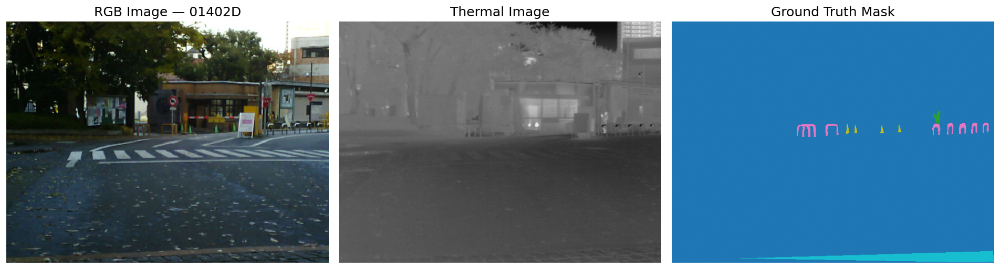

In [223]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# Dataset paths
DATA_ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = DATA_ROOT / "RGB"
THERMAL_DIR = DATA_ROOT / "Thermal"
LABEL_DIR = DATA_ROOT / "Label"

# Choose one test image
TEST_FILE = DATA_ROOT / "test.txt"

with open(TEST_FILE, "r") as f:
    test_ids = [line.strip().split()[0] for line in f if line.strip()]

print("Number of test samples:", len(test_ids))
print("First 10 test IDs:", test_ids[:10])

# Find a matching RGB, thermal and ground-truth image
sample_id = None

for sid in test_ids:
    candidates = [
        RGB_DIR / f"{sid}.png",
        THERMAL_DIR / f"{sid}.png",
        LABEL_DIR / f"{sid}.png",
    ]

    if all(p.exists() for p in candidates):
        sample_id = sid
        break

if sample_id is None:
    raise FileNotFoundError(
        "No matching RGB, thermal and label PNG files found. "
        "Check the filenames and extensions in the dataset folders."
    )

rgb_path = RGB_DIR / f"{sample_id}.png"
thermal_path = THERMAL_DIR / f"{sample_id}.png"
label_path = LABEL_DIR / f"{sample_id}.png"

rgb = Image.open(rgb_path).convert("RGB")
thermal = Image.open(thermal_path).convert("RGB")
label = Image.open(label_path)

print("\nSelected sample:", sample_id)
print("RGB size:", rgb.size)
print("Thermal size:", thermal.size)
print("Ground-truth size:", label.size)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb)
axes[0].set_title(f"RGB Image — {sample_id}")

axes[1].imshow(thermal)
axes[1].set_title("Thermal Image")

axes[2].imshow(label, cmap="tab10", vmin=0, vmax=8)
axes[2].set_title("Ground Truth Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [224]:

from pathlib import Path
import torch

# ===================== CONFIGURATION =====================
ROOT = Path("/home/cse-sdpl/Downloads")
PROJECT_HINT = "CRD"  # Change if your project has another name
# =========================================================

print("=" * 65)
print("CRD-NET SINGLE IMAGE TEST — ENVIRONMENT CHECK")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Find CRD-related projects
projects = [
    p for p in ROOT.iterdir()
    if p.is_dir() and PROJECT_HINT.lower() in p.name.lower()
]

if not projects:
    print("\nNo CRD-named folder found. Available project folders:")
    for p in ROOT.iterdir():
        if p.is_dir() and ("CMX" in p.name.upper()):
            print(" ", p)
    raise FileNotFoundError(
        "Set ROOT and PROJECT_HINT to your actual CRD-Net project folder."
    )

for i, p in enumerate(projects, 1):
    print(f"\n{i}. Project:", p)
    checkpoints = list(p.rglob("*.pth")) + list(p.rglob("*.pt"))
    for ckpt in checkpoints:
        print(f"   Checkpoint: {ckpt} ({ckpt.stat().st_size / 1024**2:.1f} MB)")

    for split in p.rglob("test.txt"):
        print("   Test split:", split)
        with open(split, "r") as f:
            ids = [line.strip() for line in f if line.strip()]
        print("   Test images listed:", len(ids))
        if ids:
            print("   First test entry:", ids[0])

    pyfiles = list(p.glob("*.py"))
    print("   Python files:", [x.name for x in pyfiles])

print("\n" + "=" * 65)
print("Send me this cell's output if the model architecture/checkpoint")
print("isn't clearly identified. Then we can run actual inference.")
print("=" * 65)


CRD-NET SINGLE IMAGE TEST — ENVIRONMENT CHECK
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation

1. Project: /home/cse-sdpl/Downloads/CRD_Net
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_after_failed_smoke_test.pth (765.0 MB)
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_epoch-last_before_restart.pth (765.0 MB)
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_epoch-last_before_fresh_restart.pth (765.0 MB)
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_after_3_epochs_reference.pth (765.0 MB)
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_best_miou.pth (765.0 MB)
   Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints_backup_before_fresh_run_20261024_181703/crd_epoch-last.pt

In [225]:

from pathlib import Path
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
CKPT = ROOT / "checkpoints" / "crd_best_miou.pth"

print("=" * 75)
print("CRD-NET SINGLE-IMAGE INFERENCE PREPARATION")
print("=" * 75)

# 1. Find source code and configuration
print("\n[1] CRD-NET SOURCE FILES")
source_files = [
    p for p in ROOT.rglob("*")
    if p.is_file()
    and p.suffix in (".py", ".yaml", ".yml", ".json")
    and not any(x in p.parts for x in
                [".git", "__pycache__", "node_modules"])
]

for p in source_files[:100]:
    print(p.relative_to(ROOT))
if not source_files:
    print("No source/config files found inside CRD_Net.")

# 2. Inspect checkpoint keys without loading optimizer tensors
print("\n[2] CHECKPOINT STRUCTURE")
if CKPT.exists():
    checkpoint = torch.load(
        CKPT, map_location="cpu", weights_only=False
    )
    print("Checkpoint:", CKPT)
    print("Top-level type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:40])

        state = None
        for key in ("model", "state_dict", "model_state_dict",
                    "net", "network"):
            if key in checkpoint and isinstance(checkpoint[key], dict):
                state = checkpoint[key]
                print("Model weights stored under:", key)
                break

        if state is None and checkpoint and all(
            isinstance(v, torch.Tensor) for v in checkpoint.values()
        ):
            state = checkpoint

        if state is not None:
            print("Parameter tensors:", len(state))
            for key, value in list(state.items())[:20]:
                print(" ", key, tuple(value.shape))
        else:
            print("Could not automatically identify the model state dict.")
    del checkpoint
else:
    print("Checkpoint not found:", CKPT)

# 3. Find dataset splits and image directories
print("\n[3] TDD DATASET")
print("Dataset directory exists:", DATA.exists())

if DATA.exists():
    for p in DATA.rglob("test.txt"):
        print("\nTest split:", p)
        lines = [x.strip() for x in p.read_text().splitlines()
                 if x.strip()]
        print("Number of test entries:", len(lines))
        print("First 3 entries:", lines[:3])

    print("\nDirectories:")
    for p in DATA.iterdir():
        if p.is_dir():
            print(" ", p.name)

# 4. Find model builder and inference scripts in nearby CMX projects
print("\n[4] NEARBY MODEL/INFERENCE FILES")
for folder in [
    ROOT,
    Path("/home/cse-sdpl/Downloads/CMX_Original"),
]:
    if folder.exists():
        for name in ("builder.py", "eval.py", "config.py",
                     "test.py", "inference.py", "train.py"):
            for p in folder.rglob(name):
                print(p)

print("\nInspection complete. No training was started.")


CRD-NET SINGLE-IMAGE INFERENCE PREPARATION

[1] CRD-NET SOURCE FILES
configs/crd_net_design.json
scripts/evaluate_crd.py
scripts/diagnose_crd_predictions.py
scripts/train_crd_before_distillation_validation.py
scripts/evaluate_crd_test.py
scripts/train_crd_before_100_epoch_setup.py
scripts/train_crd_before_evaluator_fix.py
scripts/train_crd.py
scripts/train_crd_before_validation.py
scripts/train_crd_before_teacher_integration.py
evaluation_train_test/crd_train_metrics.json
evaluation_train_test/crd_test_metrics.json
evaluation_train_test/evaluate_crd_train.py
evaluation_train_test/evaluate_crd_val.py
evaluation_train_test/crd_val_metrics.json
models/counterfactual_reliability.py
models/crd_integration.py
models/reliability_fusion.py

[2] CHECKPOINT STRUCTURE
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
Top-level type: dict
Top-level keys: ['epoch', 'model', 'optimizer', 'scheduler', 'metrics', 'validation_miou', 'best_miou', 'source_checkpoint']
Model weigh

In [226]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. DATASET, CHECKPOINT AND PREDICTION PATHS
# ============================================================
DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
CRD_DIR = Path("/home/cse-sdpl/Downloads/CRD_Net")

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = Path("/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100")
E1_DIR = Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions")
E2_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100")

# Change this to the folder containing CRD-Net's actual predicted masks.
CRD_PRED_DIR = CRD_DIR / "predictions"

OUT_DIR = CRD_DIR / "comparison_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# CRD checkpoint used for this experiment
CRD_CHECKPOINT = CRD_DIR / "checkpoints" / "crd_best_miou.pth"

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================
def find_png(folder, image_id):
    matches = list(folder.rglob(f"{image_id}.png"))
    if not matches:
        raise FileNotFoundError(
            f"Cannot find {image_id}.png in {folder}"
        )
    return matches[0]

def read_rgb(image_id):
    return np.asarray(
        Image.open(find_png(RGB_DIR, image_id)).convert("RGB")
    )

def read_thermal(image_id):
    return np.asarray(
        Image.open(find_png(THERMAL_DIR, image_id)).convert("L")
    )

def read_mask(folder, image_id):
    mask = np.asarray(Image.open(find_png(folder, image_id)))
    if mask.ndim == 3:
        mask = mask[:, :, 0]
    return mask.astype(np.uint8)

def available_ids(folder):
    if not folder.exists():
        return set()
    return {p.stem for p in folder.rglob("*.png")}

# ============================================================
# 3. REGION BOXES FROM GROUND-TRUTH SEMANTIC MASK
# ============================================================
def find_object_boxes(gt, min_area=40, max_boxes=20, margin=3):
    boxes = []
    H, W = gt.shape

    for class_id in np.unique(gt):
        if class_id == 0:
            continue

        binary = (gt == class_id).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for i in range(1, count):
            x, y, w, h, area = stats[i]

            if area < min_area:
                continue
            if w >= 0.95 * W and h >= 0.95 * H:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(W, x + w + margin)
            y2 = min(H, y + h + margin)

            boxes.append(
                (x1, y1, x2 - x1, y2 - y1, int(class_id))
            )

    boxes.sort(key=lambda b: b[2] * b[3], reverse=True)
    return boxes[:max_boxes]

# ============================================================
# 4. VALIDATE PATHS AND SELECT THREE COMMON VALIDATION IMAGES
# ============================================================
required = {
    "RGB": RGB_DIR,
    "Thermal": THERMAL_DIR,
    "Labels": LABEL_DIR,
    "Validation split": VAL_FILE,
    "E0 predictions": E0_DIR,
    "E1 predictions": E1_DIR,
    "E2 predictions": E2_DIR,
    "CRD-Net predictions": CRD_PRED_DIR,
    "CRD-Net checkpoint": CRD_CHECKPOINT,
}

print("PATH CHECK")
for name, path in required.items():
    print(f"{name:25s}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

if not CRD_CHECKPOINT.exists():
    raise FileNotFoundError("CRD-Net checkpoint not found.")

if not CRD_PRED_DIR.exists():
    raise FileNotFoundError(
        "\nCRD-Net prediction directory does not exist yet.\n"
        "Run CRD-Net inference first and save predicted masks as "
        "one PNG per image ID in:\n"
        f"{CRD_PRED_DIR}\n"
        "This visualization cell does not run model inference."
    )

val_ids = [
    line.strip().split()[0].replace(".png", "")
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

common_ids = (
    set(val_ids)
    & available_ids(E0_DIR)
    & available_ids(E1_DIR)
    & available_ids(E2_DIR)
    & available_ids(CRD_PRED_DIR)
    & available_ids(RGB_DIR)
    & available_ids(THERMAL_DIR)
    & available_ids(LABEL_DIR)
)

# Preserve validation split order and avoid the previously excluded scene.
IMAGE_IDS = [
    image_id for image_id in val_ids
    if image_id in common_ids and image_id != "00498D"
][:3]

if len(IMAGE_IDS) != 3:
    raise RuntimeError(
        f"Found only {len(IMAGE_IDS)} common images. "
        "Check prediction filenames and directories."
    )

print("\nSelected validation scenes:", IMAGE_IDS)

# ============================================================
# 5. CLASS COLORS AND PANEL TITLES
# ============================================================
class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

colors = list(plt.get_cmap("tab10").colors[:9])
mask_cmap = ListedColormap(colors)

titles = [
    "(a) RGB",
    "(b) Thermal",
    "(c) Original CMX (E0)",
    "(d) FRM removed (E1)",
    "(e) Weighted fusion (E2)",
    "(f) CRD-Net",
    "(g) Ground Truth"
]

# ============================================================
# 6. CREATE COMPARISON FIGURE
# ============================================================
fig, axes = plt.subplots(
    nrows=3,
    ncols=7,
    figsize=(24, 11)
)

for r, image_id in enumerate(IMAGE_IDS):
    rgb = read_rgb(image_id)
    thermal = read_thermal(image_id)

    e0 = read_mask(E0_DIR, image_id)
    e1 = read_mask(E1_DIR, image_id)
    e2 = read_mask(E2_DIR, image_id)
    crd = read_mask(CRD_PRED_DIR, image_id)
    gt = read_mask(LABEL_DIR, image_id)

    shapes = {
        rgb.shape[:2], thermal.shape, e0.shape, e1.shape,
        e2.shape, crd.shape, gt.shape
    }

    if len(shapes) != 1:
        raise ValueError(
            f"Image size mismatch for {image_id}: {shapes}"
        )

    # Ground-truth boxes are drawn on RGB and thermal only.
    boxes = find_object_boxes(
        gt, min_area=40, max_boxes=20, margin=3
    )

    print(f"{image_id}: {len(boxes)} ground-truth regions")

    panels = [
        (rgb, "rgb"),
        (thermal, "thermal"),
        (e0, "mask"),
        (e1, "mask"),
        (e2, "mask"),
        (crd, "mask"),
        (gt, "mask")
    ]

    for c, (image, kind) in enumerate(panels):
        ax = axes[r, c]

        if kind == "rgb":
            ax.imshow(image)
        elif kind == "thermal":
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(
                image,
                cmap=mask_cmap,
                vmin=0,
                vmax=8,
                interpolation="nearest"
            )

        if c in (0, 1):
            for x, y, w, h, class_id in boxes:
                ax.add_patch(
                    Rectangle(
                        (x, y), w, h,
                        linewidth=1.4,
                        edgecolor="red",
                        facecolor="none"
                    )
                )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

        if r == 0:
            ax.set_title(
                titles[c],
                fontsize=10,
                fontweight="semibold",
                pad=8
            )

        if c == 0:
            ax.set_ylabel(
                image_id,
                fontsize=10,
                fontweight="bold",
                labelpad=8
            )

# ============================================================
# 7. SHARED CLASS LEGEND
# ============================================================
legend_handles = [
    Patch(facecolor=colors[i], label=f"{i}: {class_names[i]}")
    for i in range(9)
]

fig.suptitle(
    "RGB-T Semantic Segmentation: CMX vs CRD-Net on TDD",
    fontsize=15,
    fontweight="bold",
    y=0.975
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=9,
    frameon=False,
    bbox_to_anchor=(0.5, 0.015)
)

plt.subplots_adjust(
    left=0.065,
    right=0.995,
    top=0.91,
    bottom=0.13,
    wspace=0.035,
    hspace=0.12
)

# ============================================================
# 8. SAVE HIGH-RESOLUTION FIGURE
# ============================================================
output_file = OUT_DIR / "CMX_vs_CRDNet_publication_comparison.png"

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nComparison figure saved to:")
print(output_file)


PATH CHECK
RGB                      : FOUND
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB
Thermal                  : FOUND
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal
Labels                   : FOUND
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label
Validation split         : FOUND
  /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/val.txt
E0 predictions           : FOUND
  /home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100
E1 predictions           : FOUND
  /home/cse-sdpl/Downloads/CMX_E1/e1_predictions
E2 predictions           : FOUND
  /home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100
CRD-Net predictions      : FOUND
  /home/cse-sdpl/Downloads/CRD_Net/predictions
CRD-Net checkpoint       : FOUND
  /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth


RuntimeError: Found only 0 common images. Check prediction filenames and directories.

In [227]:

from pathlib import Path

DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

folders = {
    "RGB": DATA / "RGB",
    "Thermal": DATA / "Thermal",
    "Ground Truth": DATA / "Label",
    "E0": Path("/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"),
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"),
    "CRD-Net predictions": Path("/home/cse-sdpl/Downloads/CRD_Net/predictions"),
}

def png_files(folder):
    return sorted(folder.rglob("*.png")) if folder.exists() else []

print("=" * 70)
print("PREDICTION DIRECTORY DIAGNOSTICS")
print("=" * 70)

id_sets = {}

for name, folder in folders.items():
    files = png_files(folder)
    ids = {p.stem for p in files}
    id_sets[name] = ids

    print(f"\n{name}")
    print("Directory:", folder)
    print("Exists:", folder.exists())
    print("PNG count:", len(files))
    print("Sample filenames:", [p.name for p in files[:5]])

val_file = DATA / "val.txt"
if val_file.exists():
    val_ids = [
        line.strip().split()[0].replace(".png", "")
        for line in val_file.read_text().splitlines()
        if line.strip()
    ]
    print("\nValidation IDs:", len(val_ids))

    for name in ("E0", "E1", "E2", "CRD-Net predictions"):
        matched = set(val_ids) & id_sets[name]
        print(f"Validation matches in {name}: {len(matched)}")
        print("  Sample matches:", sorted(matched)[:5])

    available = (
        set(val_ids)
        & id_sets["RGB"]
        & id_sets["Thermal"]
        & id_sets["Ground Truth"]
    )
    print("\nImages with RGB, thermal and ground truth:", len(available))
    print("Sample IDs:", sorted(available)[:10])

print("\nDiagnostics complete.")


PREDICTION DIRECTORY DIAGNOSTICS

RGB
Directory: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/RGB
Exists: True
PNG count: 2353
Sample filenames: ['00001D.png', '00001D_flip.png', '00002D.png', '00002D_flip.png', '00003N.png']

Thermal
Directory: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Thermal
Exists: True
PNG count: 2353
Sample filenames: ['00001D.png', '00001D_flip.png', '00002D.png', '00002D_flip.png', '00003N.png']

Ground Truth
Directory: /home/cse-sdpl/Downloads/CMX_Original/datasets/TDD/Label
Exists: True
PNG count: 2353
Sample filenames: ['00001D.png', '00001D_flip.png', '00002D.png', '00002D_flip.png', '00003N.png']

E0
Directory: /home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100
Exists: True
PNG count: 392
Sample filenames: ['00498D.png', '00499D.png', '00500D.png', '00501D.png', '00502D.png']

E1
Directory: /home/cse-sdpl/Downloads/CMX_E1/e1_predictions
Exists: True
PNG count: 392
Sample filenames: ['00498D.png', '00499D.png', '00500D.png', '0050

In [228]:

from pathlib import Path
import ast
import torch

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
CKPT = ROOT / "checkpoints" / "crd_best_miou.pth"

print("=" * 70)
print("CRD-NET INFERENCE INSPECTION")
print("=" * 70)

# 1. Find Python files, including nested model definitions
pyfiles = [
    p for p in ROOT.rglob("*.py")
    if not any(x in p.parts for x in
               [".git", "__pycache__", "site-packages"])
]

print("\n[1] Python source files:", len(pyfiles))
for p in pyfiles:
    print(" ", p.relative_to(ROOT))

# 2. Find model creation, inference and preprocessing definitions
keywords = (
    "class ", "def build", "def get_model", "def evaluate",
    "def inference", "def forward", "DataLoader",
    "load_state_dict", "backbone", "num_classes",
    "FeatureRectifyModule", "FeatureFusionModule"
)

print("\n[2] Relevant source lines")
for p in pyfiles:
    try:
        lines = p.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    hits = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(k.lower() in line.lower() for k in keywords)
    ]

    if hits:
        print(f"\n--- {p.relative_to(ROOT)} ---")
        for lineno, line in hits[:35]:
            print(f"{lineno:4}: {line[:180]}")

# 3. Inspect checkpoint structure
print("\n[3] Checkpoint")
print("Exists:", CKPT.exists())

if CKPT.exists():
    checkpoint = torch.load(
        CKPT, map_location="cpu", weights_only=False
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:50])

        state = None
        for key in (
            "model", "state_dict", "model_state_dict",
            "net", "network", "model_state"
        ):
            if isinstance(checkpoint.get(key), dict):
                state = checkpoint[key]
                print("State dictionary key:", key)
                break

        if state is None and checkpoint and all(
            isinstance(v, torch.Tensor)
            for v in checkpoint.values()
        ):
            state = checkpoint
            print("Checkpoint itself is a state dictionary.")

        if state is not None:
            print("Tensor count:", len(state))
            print("First parameter names and shapes:")
            for key, value in list(state.items())[:35]:
                if isinstance(value, torch.Tensor):
                    print(f"  {key}: {tuple(value.shape)}")
        else:
            print("No obvious state dictionary found.")

    del checkpoint

print("\nInspection finished. No training or checkpoint changes made.")


CRD-NET INFERENCE INSPECTION

[1] Python source files: 14
  scripts/evaluate_crd.py
  scripts/diagnose_crd_predictions.py
  scripts/train_crd_before_distillation_validation.py
  scripts/evaluate_crd_test.py
  scripts/train_crd_before_100_epoch_setup.py
  scripts/train_crd_before_evaluator_fix.py
  scripts/train_crd.py
  scripts/train_crd_before_validation.py
  scripts/train_crd_before_teacher_integration.py
  evaluation_train_test/evaluate_crd_train.py
  evaluation_train_test/evaluate_crd_val.py
  models/counterfactual_reliability.py
  models/crd_integration.py
  models/reliability_fusion.py

[2] Relevant source lines

--- scripts/evaluate_crd.py ---
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  39: class CRDValidationEvaluator(Evaluator):
  49: hist, labeled, correct = hist_info(cfg.num_classes, prediction, label)
  73: cfg.backbone = "mit_b2_e5"
  98: incompatible = model.load_state_dict(state, strict=True)
 114: cfg.num_classes

In [229]:

from pathlib import Path

ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")

files_to_inspect = [
    ROOT / "scripts/evaluate_crd.py",
    ROOT / "scripts/diagnose_crd_predictions.py",
    ROOT / "models/crd_integration.py",
]

for path in files_to_inspect:
    print("\n" + "=" * 90)
    print("FILE:", path)
    print("=" * 90)

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text().splitlines()

    # Print the evaluator/model setup and prediction-related sections.
    keywords = (
        "def ", "class ", "prediction", "imwrite", "save",
        "output", "Evaluator(", "cfg.", "load_state_dict",
        "model(", "argmax", "DataLoader", "dataset",
        "eval_mode", "pretrained", "CRD"
    )

    selected = set()
    for i, line in enumerate(lines):
        if any(k.lower() in line.lower() for k in keywords):
            selected.update(range(max(0, i - 2), min(len(lines), i + 4)))

    for i in sorted(selected):
        print(f"{i+1:4}: {lines[i]}")

print("\nInspection complete.")



FILE: /home/cse-sdpl/Downloads/CRD_Net/scripts/evaluate_crd.py
   7: import torch.nn as nn
   8: 
   9: CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
  10: E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")
  11: CRD_CHECKPOINT = CRD_ROOT / "checkpoints" / "crd_epoch-last.pth"
  12: 
  13: sys.path.insert(0, str(E5_ROOT))
  14: 
  15: from config import config as cfg
  16: from dataloader.dataloader import ValPre
  17: from dataloader.RGBXDataset import RGBXDataset
  18: from models.builder import EncoderDecoder
  19: from engine.evaluator import Evaluator
  20: from utils.metric import hist_info, compute_score
  21: 
  22: 
  23: def load_module_from_path(module_name, path):
  24:     spec = importlib.util.spec_from_file_location(module_name, str(path))
  25:     if spec is None or spec.loader is None:
  26:         raise RuntimeError(f"Cannot import module from {path}")
  32: 
  33: integration = load_module_from_path(
  34:     "crd_validation_integration",
  35:     CRD_ROOT 

In [230]:

from pathlib import Path
import sys
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import importlib.util

# ============================================================
# 1. PATHS
# ============================================================
CRD_ROOT = Path("/home/cse-sdpl/Downloads/CRD_Net")
E5_ROOT = Path("/home/cse-sdpl/Downloads/CMX_E5")

CHECKPOINT_PATH = CRD_ROOT / "checkpoints" / "crd_best_miou.pth"
PRED_DIR = CRD_ROOT / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. ENVIRONMENT AND IMPORTS
# ============================================================
if str(E5_ROOT) not in sys.path:
    sys.path.insert(0, str(E5_ROOT))

from config import config as cfg
from dataloader.dataloader import ValPre
from dataloader.RGBXDataset import RGBXDataset
from models.builder import EncoderDecoder
from engine.evaluator import Evaluator

def load_module_from_path(module_name, path):
    spec = importlib.util.spec_from_file_location(module_name, str(path))
    if spec is None or spec.loader is None:
        raise RuntimeError(f"Cannot import module: {path}")
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

integration = load_module_from_path(
    "crd_inference_integration",
    CRD_ROOT / "models" / "crd_integration.py"
)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}\n"
        "Update CHECKPOINT_PATH to the checkpoint you want to evaluate."
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cfg.backbone = "mit_b2_e5"

print("=" * 70)
print("CRD-NET VALIDATION INFERENCE")
print("=" * 70)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT_PATH)

# ============================================================
# 3. CREATE THE SAME VALIDATION DATASET AS THE CRD EVALUATOR
# ============================================================
setting = {
    "rgb_root": cfg.rgb_root_folder,
    "rgb_format": cfg.rgb_format,
    "gt_root": cfg.gt_root_folder,
    "gt_format": cfg.gt_format,
    "transform_gt": cfg.gt_transform,
    "x_root": cfg.x_root_folder,
    "x_format": cfg.x_format,
    "x_single_channel": cfg.x_is_single_channel,
    "class_names": cfg.class_names,
    "train_source": cfg.train_source,
    "eval_source": cfg.eval_source,
    "test_source": cfg.test_source,
}

dataset = RGBXDataset(setting, "val", ValPre())
print("Validation dataset size:", len(dataset))

# ============================================================
# 4. CREATE MODEL AND LOAD CHECKPOINT STRICTLY
# ============================================================
model = EncoderDecoder(
    cfg=cfg,
    criterion=None,
    norm_layer=nn.BatchNorm2d
)

integration.replace_fusion_modules(model)
model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model"]
incompatible = model.load_state_dict(state, strict=True)

if incompatible.missing_keys or incompatible.unexpected_keys:
    raise RuntimeError(f"Checkpoint mismatch: {incompatible}")

model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Checkpoint validation mIoU:", checkpoint.get("validation_miou", "not stored"))
print("Checkpoint best mIoU:", checkpoint.get("best_miou", "not stored"))
print("Strict checkpoint loading: successful")

# ============================================================
# 5. CREATE THE EXISTING EVALUATOR FOR SLIDING-WINDOW INFERENCE
# ============================================================
evaluator = Evaluator(
    dataset,
    cfg.num_classes,
    cfg.norm_mean,
    cfg.norm_std,
    model,
    cfg.eval_scale_array,
    cfg.eval_flip,
    [0] if device.type == "cuda" else [],
    verbose=False,
    save_path=None,
    show_image=False,
)

# Follow the setup used in the existing CRD diagnostic script.
evaluator.val_func = model

# ============================================================
# 6. VALIDATION IMAGE NAMES
# ============================================================
VAL_FILE = Path(cfg.eval_source)

if not VAL_FILE.is_absolute():
    # CMX configs commonly store a validation-list path relative
    # to the E5 project directory.
    candidate = E5_ROOT / VAL_FILE
    if candidate.is_file():
        VAL_FILE = candidate

if VAL_FILE.is_file():
    image_ids = [
        Path(line.strip().split()[0]).stem
        for line in VAL_FILE.read_text().splitlines()
        if line.strip()
    ]
else:
    image_ids = []

if len(image_ids) != len(dataset):
    print(
        "Note: validation-list names do not match dataset length exactly. "
        "Will try to use the filename returned by each dataset item."
    )

# ============================================================
# 7. RUN INFERENCE AND SAVE MASKS
# ============================================================
loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

saved = 0
errors = []

with torch.inference_mode():
    for index, data in enumerate(loader):
        try:
            rgb = data["data"].to(device, non_blocking=True)
            thermal = data["modal_x"].to(device, non_blocking=True)

            prediction = evaluator.sliding_eval_rgbX(
                rgb,
                thermal,
                cfg.eval_crop_size,
                cfg.eval_stride_rate,
                device,
            )

            pred = np.asarray(prediction)
            pred = np.squeeze(pred)

            if pred.ndim != 2:
                raise ValueError(
                    f"Unexpected prediction shape at index {index}: "
                    f"{pred.shape}"
                )

            # Use the validation-list order when available.
            image_id = (
                image_ids[index]
                if index < len(image_ids)
                else None
            )

            # Fallback to filename metadata provided by the dataset.
            if not image_id:
                fn = data.get("fn", None)
                if fn is not None:
                    if isinstance(fn, (list, tuple)):
                        fn = fn[0]
                    image_id = Path(str(fn)).stem

            if not image_id:
                raise RuntimeError(
                    f"Could not determine the image ID for index {index}."
                )

            # Save the categorical class IDs, not a colorized visualization.
            pred = pred.astype(np.uint8)
            out_path = PRED_DIR / f"{image_id}.png"
            Image.fromarray(pred, mode="L").save(out_path)
            saved += 1

            if saved == 1 or saved % 25 == 0 or saved == len(dataset):
                print(f"[{saved:>3}/{len(dataset)}] Saved {out_path.name}")

        except Exception as exc:
            errors.append((index, str(exc)))
            print(f"ERROR at validation index {index}: {exc}")
            raise

# ============================================================
# 8. VERIFY OUTPUT
# ============================================================
prediction_files = sorted(PRED_DIR.glob("*.png"))

print("\n" + "=" * 70)
print("CRD-NET INFERENCE SUMMARY")
print("=" * 70)
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print("Validation dataset size:", len(dataset))
print("Predictions saved this run:", saved)
print("Total PNG masks in output directory:", len(prediction_files))
print("Output directory:", PRED_DIR)

if prediction_files:
    sample = np.array(Image.open(prediction_files[0]))
    print("Example prediction:", prediction_files[0].name)
    print("Example mask shape:", sample.shape)
    print("Class IDs in example:", np.unique(sample).tolist())

if saved == len(dataset):
    print("\nSUCCESS: All validation predictions were generated.")
else:
    print(f"\nWARNING: Expected {len(dataset)} predictions but saved {saved}.")


25 23:49:13 Using E5: SegFormer-B2 with counterfactual reliability


CRD-NET VALIDATION INFERENCE
Device: cuda
GPU: NVIDIA RTX 2000 Ada Generation
Checkpoint: /home/cse-sdpl/Downloads/CRD_Net/checkpoints/crd_best_miou.pth
Validation dataset size: 392


25 23:49:14 Using MLP Decoder


Checkpoint epoch: 61
Checkpoint validation mIoU: 0.6266267934605243
Checkpoint best mIoU: 0.6266267934605243
Strict checkpoint loading: successful
ERROR at validation index 0: too many values to unpack (expected 3)


ValueError: too many values to unpack (expected 3)

In [231]:

from pathlib import Path
import numpy as np
import torch
from PIL import Image

PRED_DIR = Path("/home/cse-sdpl/Downloads/CRD_Net/predictions")
PRED_DIR.mkdir(parents=True, exist_ok=True)

# Remove old PNG outputs so the final count reflects this run.
for old_file in PRED_DIR.glob("*.png"):
    old_file.unlink()

# Read validation IDs in the same order as the dataset.
VAL_FILE = Path(cfg.eval_source)
if not VAL_FILE.is_absolute():
    candidate = E5_ROOT / VAL_FILE
    if candidate.is_file():
        VAL_FILE = candidate

image_ids = []
if VAL_FILE.is_file():
    image_ids = [
        Path(line.strip().split()[0]).stem
        for line in VAL_FILE.read_text().splitlines()
        if line.strip()
    ]

def to_numpy_image(value):
    """Convert one dataset image to a 3D NumPy array without a batch axis."""
    if isinstance(value, torch.Tensor):
        value = value.detach().cpu().numpy()

    value = np.asarray(value)

    # Remove only a singleton batch dimension, if present.
    if value.ndim == 4 and value.shape[0] == 1:
        value = value[0]

    # Convert CHW to HWC only when the layout clearly looks channel-first.
    if value.ndim == 3 and value.shape[0] in (1, 3, 4) and value.shape[-1] not in (1, 3, 4):
        value = np.transpose(value, (1, 2, 0))

    if value.ndim != 3:
        raise ValueError(f"Expected a 3D image array, got shape {value.shape}")

    return value

# Inspect the first sample before starting the full run.
sample = dataset[0]
print("Dataset sample keys:", list(sample.keys()))
print("RGB sample shape:", np.asarray(sample["data"]).shape)
print("Thermal sample shape:", np.asarray(sample["modal_x"]).shape)

saved = 0

model.eval()
evaluator.val_func = model

with torch.inference_mode():
    for index in range(len(dataset)):
        data = dataset[index]

        # sliding_eval_rgbX expects H x W x C inputs, not BCHW tensors.
        rgb = to_numpy_image(data["data"])
        thermal = to_numpy_image(data["modal_x"])

        prediction = evaluator.sliding_eval_rgbX(
            rgb,
            thermal,
            cfg.eval_crop_size,
            cfg.eval_stride_rate,
            device,
        )

        pred = np.asarray(prediction)
        pred = np.squeeze(pred)

        if pred.ndim != 2:
            raise ValueError(
                f"Prediction at index {index} has unexpected shape {pred.shape}"
            )

        if index < len(image_ids):
            image_id = image_ids[index]
        else:
            fn = data.get("fn", None)
            if isinstance(fn, (list, tuple)):
                fn = fn[0]
            if fn is None:
                raise RuntimeError(
                    f"Cannot determine filename for dataset index {index}"
                )
            image_id = Path(str(fn)).stem

        # Store integer class labels, not a colored visualization.
        if pred.min() < 0 or pred.max() >= cfg.num_classes:
            raise ValueError(
                f"Invalid class IDs for {image_id}: "
                f"{pred.min()} to {pred.max()}"
            )

        out_path = PRED_DIR / f"{image_id}.png"
        Image.fromarray(pred.astype(np.uint8)).save(out_path)
        saved += 1

        if saved == 1 or saved % 25 == 0 or saved == len(dataset):
            print(f"[{saved}/{len(dataset)}] Saved {out_path.name}")

print("\nInference finished.")
print("Dataset size:", len(dataset))
print("Predictions saved:", saved)
print("PNG files present:", len(list(PRED_DIR.glob("*.png"))))
print("Output directory:", PRED_DIR)


Dataset sample keys: ['data', 'label', 'modal_x', 'fn', 'n']
RGB sample shape: (480, 640, 3)
Thermal sample shape: (480, 640, 3)
[1/392] Saved 00498D.png
[25/392] Saved 00522D.png
[50/392] Saved 00547D.png
[75/392] Saved 00572D.png
[100/392] Saved 00597D.png
[125/392] Saved 00622D.png
[150/392] Saved 00647D.png
[175/392] Saved 00672D.png
[200/392] Saved 01396D.png
[225/392] Saved 01021N.png
[250/392] Saved 01046N.png
[275/392] Saved 01071N.png
[300/392] Saved 01096N.png
[325/392] Saved 01121N.png
[350/392] Saved 01146N.png
[375/392] Saved 01171N.png
[392/392] Saved 01188N.png

Inference finished.
Dataset size: 392
Predictions saved: 392
PNG files present: 392
Output directory: /home/cse-sdpl/Downloads/CRD_Net/predictions


Validation IDs: 392
Common images available for every panel: 392
Selected images: ['00499D', '00500D', '00501D']


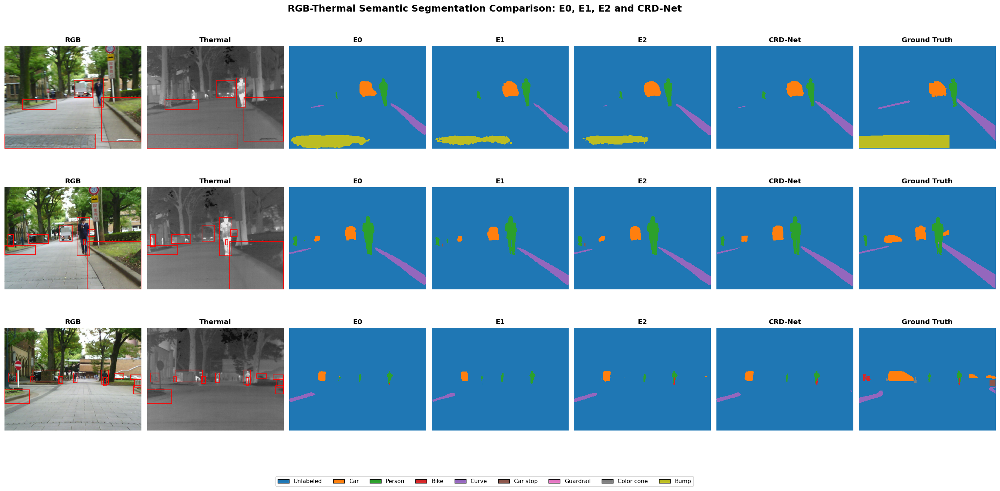


Figure saved successfully:
/home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_publication_comparison.png
Resolution: 300 DPI
Images displayed: 3


In [232]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# PATHS
# ============================================================
DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"

E0_DIR = Path("/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100")
E1_DIR = Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions")
E2_DIR = Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100")
CRD_DIR = Path("/home/cse-sdpl/Downloads/CRD_Net/predictions")

VAL_FILE = DATA / "val.txt"

OUT_DIR = Path("/home/cse-sdpl/Downloads/CRD_Net/comparison_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# CLASS NAMES AND COLORS
# ============================================================
CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

base_colors = plt.get_cmap("tab10").colors[:9]
CMAP = ListedColormap(base_colors)

# ============================================================
# HELPERS
# ============================================================
def find_png(directory, image_id):
    candidates = [
        directory / f"{image_id}.png",
        directory / f"{image_id}.PNG"
    ]
    for path in candidates:
        if path.is_file():
            return path

    # Case-insensitive fallback
    if directory.is_dir():
        target = f"{image_id}.png".lower()
        for path in directory.iterdir():
            if path.name.lower() == target:
                return path
    return None


def read_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))


def read_thermal(path):
    return np.asarray(Image.open(path).convert("RGB"))


def read_mask(path):
    return np.asarray(Image.open(path)).squeeze().astype(np.uint8)


def available_ids(directory):
    if not directory.is_dir():
        return set()
    return {p.stem for p in directory.glob("*.png")}


def find_object_boxes(gt, min_area=40, max_boxes=20, margin=3):
    boxes = []

    for class_id in range(1, len(CLASS_NAMES)):
        binary = (gt == class_id).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for component in range(1, count):
            x, y, w, h, area = stats[component]

            if area < min_area:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(gt.shape[1] - 1, x + w - 1 + margin)
            y2 = min(gt.shape[0] - 1, y + h - 1 + margin)

            boxes.append((x1, y1, x2, y2, area, class_id))

    boxes.sort(key=lambda item: item[4], reverse=True)
    return boxes[:max_boxes]


def draw_boxes(ax, boxes, linewidth=1.0):
    for x1, y1, x2, y2, _, _ in boxes:
        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="red",
                linewidth=linewidth
            )
        )


# ============================================================
# VALIDATION IDS
# ============================================================
if not VAL_FILE.is_file():
    raise FileNotFoundError(f"Validation file not found: {VAL_FILE}")

val_ids = [
    Path(line.strip().split()[0]).stem
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

directories = {
    "RGB": RGB_DIR,
    "Thermal": THERMAL_DIR,
    "Ground Truth": LABEL_DIR,
    "E0": E0_DIR,
    "E1": E1_DIR,
    "E2": E2_DIR,
    "CRD-Net": CRD_DIR,
}

common_ids = set(val_ids)
for directory in directories.values():
    common_ids &= available_ids(directory)

ordered_ids = [image_id for image_id in val_ids if image_id in common_ids]

print("Validation IDs:", len(val_ids))
print("Common images available for every panel:", len(ordered_ids))

if not ordered_ids:
    raise RuntimeError(
        "No common validation IDs found. Check the directory paths and filenames."
    )

# Keep the original first-three-image selection while avoiding 00498D.
selected_ids = [
    image_id for image_id in ordered_ids if image_id != "00498D"
][:3]

if len(selected_ids) < 3:
    selected_ids = ordered_ids[:3]

print("Selected images:", selected_ids)

# ============================================================
# CREATE FIGURE
# ============================================================
panel_names = [
    "RGB", "Thermal", "E0", "E1", "E2", "CRD-Net", "Ground Truth"
]

fig, axes = plt.subplots(
    nrows=len(selected_ids),
    ncols=7,
    figsize=(23, 3.7 * len(selected_ids)),
    constrained_layout=False
)

if len(selected_ids) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, image_id in enumerate(selected_ids):
    rgb = read_rgb(find_png(RGB_DIR, image_id))
    thermal = read_thermal(find_png(THERMAL_DIR, image_id))
    gt = read_mask(find_png(LABEL_DIR, image_id))

    masks = {
        "E0": read_mask(find_png(E0_DIR, image_id)),
        "E1": read_mask(find_png(E1_DIR, image_id)),
        "E2": read_mask(find_png(E2_DIR, image_id)),
        "CRD-Net": read_mask(find_png(CRD_DIR, image_id)),
        "Ground Truth": gt,
    }

    # Resize RGB/thermal only if a source image unexpectedly differs in size.
    height, width = gt.shape[:2]
    if rgb.shape[:2] != (height, width):
        rgb = cv2.resize(rgb, (width, height), interpolation=cv2.INTER_LINEAR)
    if thermal.shape[:2] != (height, width):
        thermal = cv2.resize(
            thermal, (width, height), interpolation=cv2.INTER_LINEAR
        )

    boxes = find_object_boxes(gt)

    # RGB and thermal source images with GT-derived red boxes.
    ax = axes[row, 0]
    ax.imshow(rgb)
    draw_boxes(ax, boxes)
    ax.set_title("RGB", fontsize=11, fontweight="bold")

    ax = axes[row, 1]
    ax.imshow(thermal)
    draw_boxes(ax, boxes)
    ax.set_title("Thermal", fontsize=11, fontweight="bold")

    # Predicted and ground-truth segmentation masks.
    for col, name in enumerate(
        ["E0", "E1", "E2", "CRD-Net", "Ground Truth"], start=2
    ):
        ax = axes[row, col]
        mask = masks[name]

        if mask.shape != (height, width):
            mask = cv2.resize(
                mask, (width, height), interpolation=cv2.INTER_NEAREST
            )

        ax.imshow(
            mask,
            cmap=CMAP,
            vmin=0,
            vmax=len(CLASS_NAMES) - 1,
            interpolation="nearest"
        )
        ax.set_title(name, fontsize=11, fontweight="bold")

    for ax in axes[row]:
        ax.axis("off")

    axes[row, 0].set_ylabel(
        image_id,
        fontsize=10,
        fontweight="bold",
        rotation=90,
        labelpad=12
    )

# Shared class legend
legend_handles = [
    Patch(facecolor=base_colors[i], edgecolor="black", label=CLASS_NAMES[i])
    for i in range(len(CLASS_NAMES))
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=9,
    frameon=True,
    fontsize=9,
    bbox_to_anchor=(0.5, 0.015)
)

fig.suptitle(
    "RGB-Thermal Semantic Segmentation Comparison: E0, E1, E2 and CRD-Net",
    fontsize=15,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.035,
    right=0.995,
    top=0.93,
    bottom=0.11,
    wspace=0.04,
    hspace=0.12
)

output_path = OUT_DIR / "CRD_publication_comparison.png"
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFigure saved successfully:")
print(output_path)
print("Resolution: 300 DPI")
print("Images displayed:", len(selected_ids))


In [233]:

import random

# Choose different validation images each time you run this cell.
random.seed()  # Different selection on each run

available_for_display = [
    image_id for image_id in ordered_ids
    if image_id != "00498D"
]

selected_ids = random.sample(
    available_for_display,
    k=min(3, len(available_for_display))
)

print("New images selected:", selected_ids)


New images selected: ['00673D', '01188N', '01081N']


CRD-NET RANDOM VALIDATION COMPARISON
Validation IDs: 392
Images available in every panel: 392
CRD-Net prediction PNG count: 392

Randomly selected images:
   01395D
   01166N
   01151N


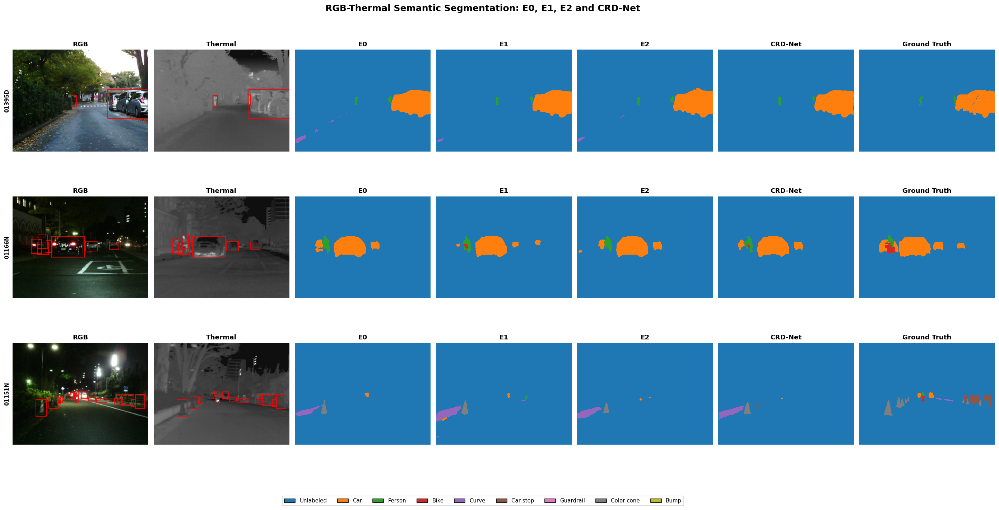


COMPARISON COMPLETE
Images compared: 3
Selected IDs: ['01395D', '01166N', '01151N']
Saved figure: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_random_comparison_01395D_01166N_01151N.png
Resolution: 300 DPI


In [234]:

# ============================================================
# CRD-NET: RANDOM IMAGE PREDICTION COMPARISON
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# ============================================================

from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. PATHS
# ============================================================

DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
)
E1_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
)
E2_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
)
CRD_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/predictions"
)

OUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. SETTINGS
# ============================================================

NUM_RANDOM_IMAGES = 3

# Set to an integer, e.g. 42, to reproduce the same selection.
# Set to None for a different random selection each run.
RANDOM_SEED = None

CLASS_NAMES = [
    "Unlabeled",
    "Car",
    "Person",
    "Bike",
    "Curve",
    "Car stop",
    "Guardrail",
    "Color cone",
    "Bump",
]

COLORS = plt.get_cmap("tab10").colors[:len(CLASS_NAMES)]
CMAP = ListedColormap(COLORS)

# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def find_png(directory, image_id):
    """Find a PNG using the validation image ID."""
    path = directory / f"{image_id}.png"
    if path.is_file():
        return path

    if directory.is_dir():
        target = f"{image_id}.png".lower()
        for candidate in directory.iterdir():
            if candidate.name.lower() == target:
                return candidate

    return None


def read_rgb(path):
    if path is None:
        raise FileNotFoundError("RGB image not found.")
    return np.asarray(Image.open(path).convert("RGB"))


def read_thermal(path):
    if path is None:
        raise FileNotFoundError("Thermal image not found.")
    return np.asarray(Image.open(path).convert("RGB"))


def read_mask(path):
    if path is None:
        raise FileNotFoundError("Segmentation mask not found.")
    return np.asarray(Image.open(path)).squeeze().astype(np.uint8)


def png_ids(directory):
    if not directory.is_dir():
        return set()
    return {path.stem for path in directory.glob("*.png")}


def get_object_boxes(gt, min_area=40, max_boxes=20, margin=3):
    """Find connected foreground regions from ground truth."""
    boxes = []

    for class_id in range(1, len(CLASS_NAMES)):
        binary = (gt == class_id).astype(np.uint8)

        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary,
            connectivity=8,
        )

        for component_id in range(1, count):
            x, y, w, h, area = stats[component_id]

            if area < min_area:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(gt.shape[1] - 1, x + w - 1 + margin)
            y2 = min(gt.shape[0] - 1, y + h - 1 + margin)

            boxes.append((x1, y1, x2, y2, area, class_id))

    boxes.sort(key=lambda box: box[4], reverse=True)
    return boxes[:max_boxes]


def draw_boxes(ax, boxes):
    for x1, y1, x2, y2, _, _ in boxes:
        ax.add_patch(
            Rectangle(
                (x1, y1),
                max(1, x2 - x1),
                max(1, y2 - y1),
                fill=False,
                edgecolor="red",
                linewidth=1.0,
            )
        )


def resize_mask_if_needed(mask, target_shape):
    """Resize categorical masks with nearest-neighbor interpolation."""
    if mask.shape != target_shape:
        mask = cv2.resize(
            mask,
            (target_shape[1], target_shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )
    return mask


# ============================================================
# 4. VALIDATE DIRECTORIES
# ============================================================

required_dirs = {
    "RGB": RGB_DIR,
    "Thermal": THERMAL_DIR,
    "Ground Truth": LABEL_DIR,
    "E0": E0_DIR,
    "E1": E1_DIR,
    "E2": E2_DIR,
    "CRD-Net": CRD_DIR,
}

for name, directory in required_dirs.items():
    if not directory.is_dir():
        raise FileNotFoundError(
            f"{name} directory does not exist:\n{directory}"
        )

if not VAL_FILE.is_file():
    raise FileNotFoundError(
        f"Validation list not found:\n{VAL_FILE}"
    )

# ============================================================
# 5. FIND IMAGES AVAILABLE IN ALL SEVEN PANELS
# ============================================================

val_ids = [
    Path(line.strip().split()[0]).stem
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

common_ids = set(val_ids)

for directory in required_dirs.values():
    common_ids &= png_ids(directory)

ordered_ids = [
    image_id for image_id in val_ids
    if image_id in common_ids
]

print("=" * 75)
print("CRD-NET RANDOM VALIDATION COMPARISON")
print("=" * 75)
print("Validation IDs:", len(val_ids))
print("Images available in every panel:", len(ordered_ids))
print("CRD-Net prediction PNG count:", len(png_ids(CRD_DIR)))

if not ordered_ids:
    raise RuntimeError(
        "No common validation images found. Check the paths and filenames."
    )

# ============================================================
# 6. RANDOM IMAGE SELECTION
# ============================================================

if RANDOM_SEED is not None:
    random.seed(RANDOM_SEED)

num_images = min(NUM_RANDOM_IMAGES, len(ordered_ids))
selected_ids = random.sample(ordered_ids, num_images)

print("\nRandomly selected images:")
for image_id in selected_ids:
    print("  ", image_id)

# ============================================================
# 7. CREATE THE COMPARISON FIGURE
# ============================================================

panel_names = [
    "RGB",
    "Thermal",
    "E0",
    "E1",
    "E2",
    "CRD-Net",
    "Ground Truth",
]

fig, axes = plt.subplots(
    nrows=num_images,
    ncols=len(panel_names),
    figsize=(24, 4.0 * num_images),
    squeeze=False,
)

for row, image_id in enumerate(selected_ids):

    # --------------------------------------------------------
    # Load RGB, thermal, ground truth and model predictions
    # --------------------------------------------------------

    rgb = read_rgb(find_png(RGB_DIR, image_id))
    thermal = read_thermal(find_png(THERMAL_DIR, image_id))
    gt = read_mask(find_png(LABEL_DIR, image_id))

    masks = {
        "E0": read_mask(find_png(E0_DIR, image_id)),
        "E1": read_mask(find_png(E1_DIR, image_id)),
        "E2": read_mask(find_png(E2_DIR, image_id)),
        "CRD-Net": read_mask(find_png(CRD_DIR, image_id)),
        "Ground Truth": gt,
    }

    height, width = gt.shape[:2]

    # Ensure source images match ground-truth resolution.
    if rgb.shape[:2] != (height, width):
        rgb = cv2.resize(
            rgb, (width, height), interpolation=cv2.INTER_LINEAR
        )

    if thermal.shape[:2] != (height, width):
        thermal = cv2.resize(
            thermal, (width, height), interpolation=cv2.INTER_LINEAR
        )

    boxes = get_object_boxes(gt)

    # --------------------------------------------------------
    # Panel 1: RGB
    # --------------------------------------------------------

    ax = axes[row, 0]
    ax.imshow(rgb)
    draw_boxes(ax, boxes)
    ax.set_title("RGB", fontsize=11, fontweight="bold")

    # --------------------------------------------------------
    # Panel 2: Thermal
    # --------------------------------------------------------

    ax = axes[row, 1]
    ax.imshow(thermal)
    draw_boxes(ax, boxes)
    ax.set_title("Thermal", fontsize=11, fontweight="bold")

    # --------------------------------------------------------
    # Panels 3-7: segmentation masks
    # --------------------------------------------------------

    for col, name in enumerate(
        ["E0", "E1", "E2", "CRD-Net", "Ground Truth"],
        start=2,
    ):
        ax = axes[row, col]

        mask = resize_mask_if_needed(
            masks[name],
            (height, width),
        )

        ax.imshow(
            mask,
            cmap=CMAP,
            vmin=0,
            vmax=len(CLASS_NAMES) - 1,
            interpolation="nearest",
        )

        ax.set_title(name, fontsize=11, fontweight="bold")

    # Hide axes and label each row by image ID.
    for ax in axes[row]:
        ax.axis("off")

    axes[row, 0].text(
        -0.04,
        0.5,
        image_id,
        transform=axes[row, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=9,
        fontweight="bold",
    )

# ============================================================
# 8. CLASS LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor=COLORS[i],
        edgecolor="black",
        label=CLASS_NAMES[i],
    )
    for i in range(len(CLASS_NAMES))
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=9,
    fontsize=9,
    frameon=True,
    bbox_to_anchor=(0.5, 0.015),
)

fig.suptitle(
    "RGB-Thermal Semantic Segmentation: E0, E1, E2 and CRD-Net",
    fontsize=15,
    fontweight="bold",
    y=0.99,
)

fig.subplots_adjust(
    left=0.045,
    right=0.995,
    top=0.93,
    bottom=0.11,
    wspace=0.04,
    hspace=0.12,
)

# ============================================================
# 9. SAVE HIGH-RESOLUTION FIGURE
# ============================================================

image_tag = "_".join(selected_ids)
output_path = OUT_DIR / f"CRD_random_comparison_{image_tag}.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print("\n" + "=" * 75)
print("COMPARISON COMPLETE")
print("=" * 75)
print("Images compared:", num_images)
print("Selected IDs:", selected_ids)
print("Saved figure:", output_path)
print("Resolution: 300 DPI")


Randomly selected images: ['01031N', '01127N', '00531D']


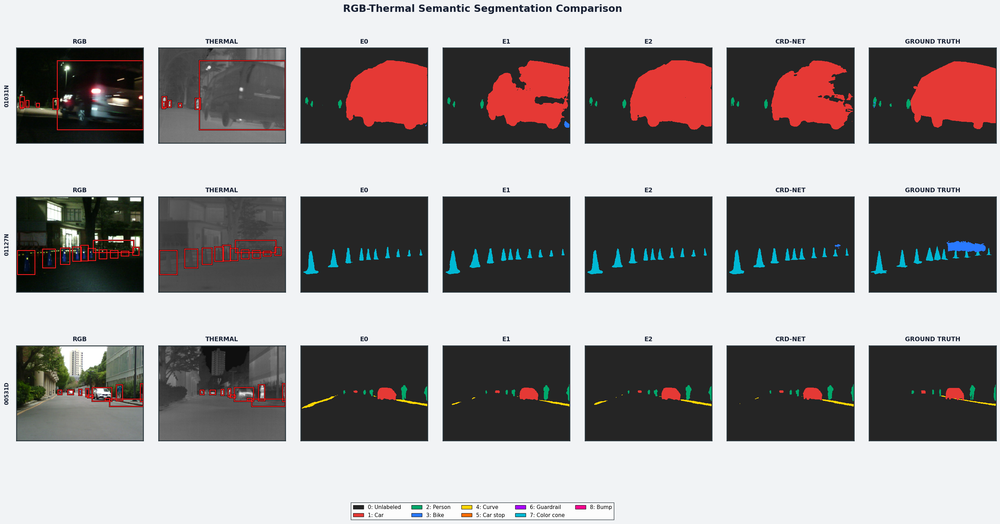


PROFESSIONAL COMPARISON GENERATED
Images: ['01031N', '01127N', '00531D']
Panels per image: 7
Output: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_styled_comparison_01031N_01127N_00531D.png
Resolution: 300 DPI


In [235]:

# ============================================================
# CRD-NET PUBLICATION COMPARISON — PROFESSIONAL DARKER STYLE
# Random images | Strong colors | Clear panel borders
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# ============================================================

from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from PIL import Image
import cv2

# ============================================================
# 1. PATHS
# ============================================================

DATA = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = DATA / "RGB"
THERMAL_DIR = DATA / "Thermal"
LABEL_DIR = DATA / "Label"
VAL_FILE = DATA / "val.txt"

E0_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
)
E1_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
)
E2_DIR = Path(
    "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
)
CRD_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/predictions"
)

OUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. SETTINGS
# ============================================================

NUM_RANDOM_IMAGES = 3
RANDOM_SEED = None       # None = different images each run
MIN_OBJECT_AREA = 40
MAX_BOXES = 20

CLASS_NAMES = [
    "Unlabeled",
    "Car",
    "Person",
    "Bike",
    "Curve",
    "Car stop",
    "Guardrail",
    "Color cone",
    "Bump",
]

# Stronger, more saturated categorical colors.
# The same mapping is applied to E0, E1, E2, CRD-Net and GT.
CLASS_COLORS = [
    "#252525",  # Unlabeled - charcoal
    "#E53935",  # Car - strong red
    "#00A86B",  # Person - emerald green
    "#2979FF",  # Bike - vivid blue
    "#FFD600",  # Curve - yellow
    "#FF6D00",  # Car stop - orange
    "#AA00FF",  # Guardrail - purple
    "#00B8D4",  # Color cone - cyan
    "#F5008F",  # Bump - magenta
]

CMAP = ListedColormap(CLASS_COLORS)

# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def find_png(directory, image_id):
    path = directory / f"{image_id}.png"

    if path.is_file():
        return path

    target = f"{image_id}.png".lower()

    for candidate in directory.glob("*.png"):
        if candidate.name.lower() == target:
            return candidate

    return None


def read_rgb(path):
    if path is None:
        raise FileNotFoundError("RGB image not found.")
    return np.asarray(Image.open(path).convert("RGB"))


def read_thermal(path):
    if path is None:
        raise FileNotFoundError("Thermal image not found.")
    return np.asarray(Image.open(path).convert("RGB"))


def read_mask(path):
    if path is None:
        raise FileNotFoundError("Segmentation mask not found.")
    return np.asarray(Image.open(path)).squeeze().astype(np.uint8)


def png_ids(directory):
    if not directory.is_dir():
        return set()
    return {p.stem for p in directory.glob("*.png")}


def find_object_boxes(gt, min_area=MIN_OBJECT_AREA,
                      max_boxes=MAX_BOXES, margin=3):
    boxes = []

    for class_id in range(1, len(CLASS_NAMES)):
        binary = (gt == class_id).astype(np.uint8)

        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for component_id in range(1, count):
            x, y, w, h, area = stats[component_id]

            if area < min_area:
                continue

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(gt.shape[1] - 1, x + w - 1 + margin)
            y2 = min(gt.shape[0] - 1, y + h - 1 + margin)

            boxes.append((x1, y1, x2, y2, area, class_id))

    boxes.sort(key=lambda item: item[4], reverse=True)
    return boxes[:max_boxes]


def draw_boxes(ax, boxes):
    for x1, y1, x2, y2, _, _ in boxes:
        # Dark outer stroke makes the red box easier to see.
        ax.add_patch(
            Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False,
                edgecolor="black",
                linewidth=2.4,
                zorder=5,
            )
        )

        ax.add_patch(
            Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False,
                edgecolor="#FF2020",
                linewidth=1.4,
                zorder=6,
            )
        )


def style_panel(ax, title):
    ax.set_title(
        title,
        fontsize=10.5,
        fontweight="bold",
        color="#172033",
        pad=8,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Clear dark border around every image panel.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#263238")
        spine.set_linewidth(1.5)

    ax.set_facecolor("white")


def resize_mask(mask, target_shape):
    if mask.shape != target_shape:
        mask = cv2.resize(
            mask,
            (target_shape[1], target_shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )
    return mask


# ============================================================
# 4. VALIDATE PATHS
# ============================================================

required_dirs = {
    "RGB": RGB_DIR,
    "Thermal": THERMAL_DIR,
    "Ground Truth": LABEL_DIR,
    "E0": E0_DIR,
    "E1": E1_DIR,
    "E2": E2_DIR,
    "CRD-Net": CRD_DIR,
}

for name, directory in required_dirs.items():
    if not directory.is_dir():
        raise FileNotFoundError(
            f"{name} directory does not exist:\n{directory}"
        )

if not VAL_FILE.is_file():
    raise FileNotFoundError(f"Validation file not found: {VAL_FILE}")

# ============================================================
# 5. COMMON VALIDATION IMAGES
# ============================================================

val_ids = [
    Path(line.strip().split()[0]).stem
    for line in VAL_FILE.read_text().splitlines()
    if line.strip()
]

common_ids = set(val_ids)

for directory in required_dirs.values():
    common_ids &= png_ids(directory)

ordered_ids = [
    image_id for image_id in val_ids
    if image_id in common_ids
]

if not ordered_ids:
    raise RuntimeError(
        "No common validation IDs found across all seven panels."
    )

# ============================================================
# 6. RANDOM IMAGE SELECTION
# ============================================================

if RANDOM_SEED is not None:
    random.seed(RANDOM_SEED)

selected_ids = random.sample(
    ordered_ids,
    min(NUM_RANDOM_IMAGES, len(ordered_ids)),
)

print("Randomly selected images:", selected_ids)

# ============================================================
# 7. FIGURE DESIGN
# ============================================================

panel_names = [
    "RGB", "Thermal", "E0", "E1", "E2", "CRD-Net", "Ground Truth"
]

nrows = len(selected_ids)
ncols = len(panel_names)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(25, 4.3 * nrows),
    squeeze=False,
    facecolor="#F1F3F5",
)

for row, image_id in enumerate(selected_ids):

    rgb = read_rgb(find_png(RGB_DIR, image_id))
    thermal = read_thermal(find_png(THERMAL_DIR, image_id))
    gt = read_mask(find_png(LABEL_DIR, image_id))

    masks = {
        "E0": read_mask(find_png(E0_DIR, image_id)),
        "E1": read_mask(find_png(E1_DIR, image_id)),
        "E2": read_mask(find_png(E2_DIR, image_id)),
        "CRD-Net": read_mask(find_png(CRD_DIR, image_id)),
        "Ground Truth": gt,
    }

    height, width = gt.shape[:2]

    if rgb.shape[:2] != (height, width):
        rgb = cv2.resize(
            rgb, (width, height), interpolation=cv2.INTER_LINEAR
        )

    if thermal.shape[:2] != (height, width):
        thermal = cv2.resize(
            thermal, (width, height), interpolation=cv2.INTER_LINEAR
        )

    boxes = find_object_boxes(gt)

    # RGB
    ax = axes[row, 0]
    ax.imshow(rgb)
    draw_boxes(ax, boxes)
    style_panel(ax, "RGB")

    # Thermal
    ax = axes[row, 1]
    ax.imshow(thermal)
    draw_boxes(ax, boxes)
    style_panel(ax, "THERMAL")

    # E0, E1, E2, CRD-Net, Ground Truth
    for col, name in enumerate(
        ["E0", "E1", "E2", "CRD-Net", "Ground Truth"],
        start=2,
    ):
        ax = axes[row, col]
        mask = resize_mask(masks[name], (height, width))

        ax.imshow(
            mask,
            cmap=CMAP,
            vmin=0,
            vmax=len(CLASS_NAMES) - 1,
            interpolation="nearest",
        )

        style_panel(ax, name.upper())

    # Image ID strip on the left of each row
    axes[row, 0].text(
        -0.075,
        0.5,
        image_id,
        transform=axes[row, 0].transAxes,
        rotation=90,
        va="center",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#172033",
    )

# ============================================================
# 8. LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor=CLASS_COLORS[i],
        edgecolor="#202020",
        linewidth=0.8,
        label=f"{i}: {CLASS_NAMES[i]}",
    )
    for i in range(len(CLASS_NAMES))
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=9,
    frameon=True,
    fancybox=False,
    edgecolor="#263238",
    facecolor="white",
    bbox_to_anchor=(0.5, 0.025),
)

fig.suptitle(
    "RGB-Thermal Semantic Segmentation Comparison",
    fontsize=17,
    fontweight="bold",
    color="#172033",
    y=0.985,
)

# Strong separation between rows and columns.
fig.subplots_adjust(
    left=0.055,
    right=0.99,
    top=0.92,
    bottom=0.16,
    wspace=0.12,
    hspace=0.32,
)

# ============================================================
# 9. SAVE HIGH-RESOLUTION OUTPUT
# ============================================================

image_tag = "_".join(selected_ids)
output_path = OUT_DIR / f"CRD_styled_comparison_{image_tag}.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    pad_inches=0.2,
)

plt.show()

print("\n" + "=" * 65)
print("PROFESSIONAL COMPARISON GENERATED")
print("=" * 65)
print("Images:", selected_ids)
print("Panels per image:", len(panel_names))
print("Output:", output_path)
print("Resolution: 300 DPI")


Selected 5 validation images:
   01142N
   01103N
   01154N
   01037N
   00570D


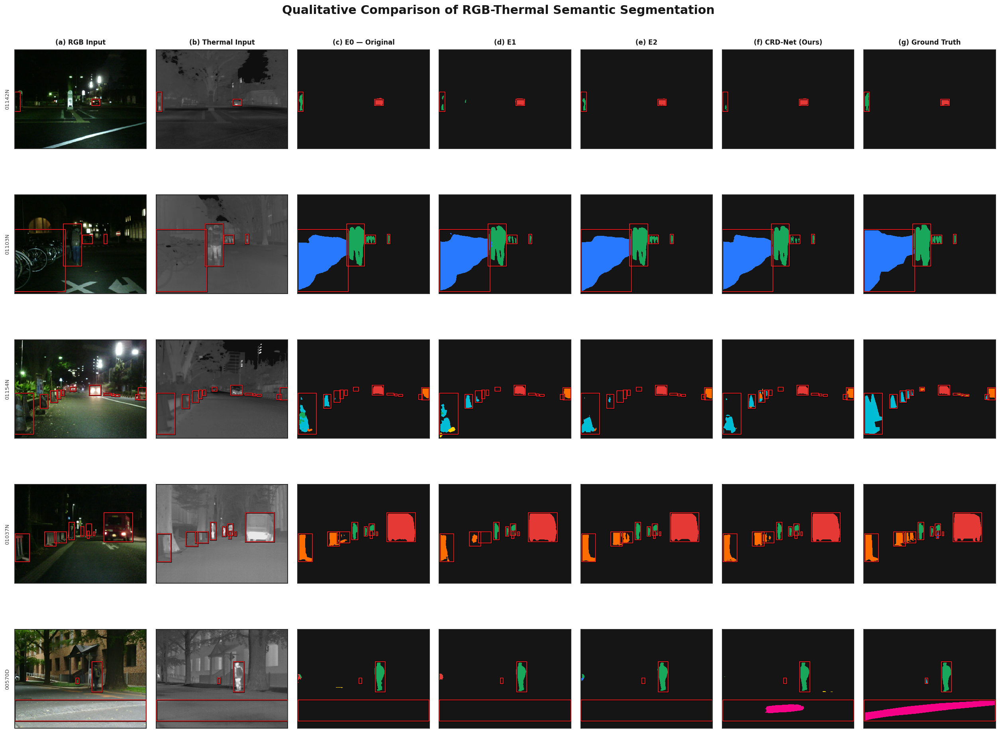


PUBLICATION-STYLE COMPARISON GENERATED
PNG: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_01142N_01103N_01154N_01037N_00570D.png
PDF: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_01142N_01103N_01154N_01037N_00570D.pdf
Rows: 5
Columns: 7
Every subplot has an individual border.
All model masks use the same class-color palette.
Bounding boxes are derived from ground truth.


In [236]:

# ================================================================
# CRD-Net Research Paper Visualization
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# ================================================================

from pathlib import Path
import random
import warnings

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib import colors as mcolors

# ------------------------- PATHS -------------------------
DATASET_DIR = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = DATASET_DIR / "RGB"
THERMAL_DIR = DATASET_DIR / "Thermal"
LABEL_DIR = DATASET_DIR / "Label"
VAL_FILE = DATASET_DIR / "val.txt"

PREDICTION_DIRS = {
    "E0 — Original CMX": Path(
        "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
    ),
    "E1": Path(
        "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
    ),
    "E2": Path(
        "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
    ),
    "CRD-Net (Ours)": Path(
        "/home/cse-sdpl/Downloads/CRD_Net/predictions"
    ),
}

OUTPUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------- CONFIGURATION ---------------------
NUM_IMAGES = 5
RANDOM_SEED = 42           # Change to None for different random images
DPI = 300
DRAW_GT_BOXES = True
MIN_BOX_AREA = 80
MAX_BOXES_PER_IMAGE = 12

CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

# High-contrast, consistent colors across every model
CLASS_COLORS = [
    "#151515",  # Unlabeled
    "#E53935",  # Car
    "#19A85B",  # Person
    "#2979FF",  # Bike
    "#FFD600",  # Curve
    "#FF6D00",  # Car stop
    "#8E24AA",  # Guardrail
    "#00BCD4",  # Color cone
    "#F50087",  # Bump
]

NUM_CLASSES = len(CLASS_NAMES)
COLOR_ARRAY = np.array(
    [mcolors.to_rgb(c) for c in CLASS_COLORS],
    dtype=np.float32
)

# ---------------------- FILE HELPERS ----------------------
def find_image(folder, image_id):
    """Find an image by ID, allowing common image extensions."""
    folder = Path(folder)
    image_id = Path(str(image_id)).stem

    for ext in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
        p = folder / (image_id + ext)
        if p.exists():
            return p

    # Case-insensitive fallback
    if folder.exists():
        matches = [
            p for p in folder.iterdir()
            if p.is_file()
            and p.stem.lower() == image_id.lower()
            and p.suffix.lower() in {
                ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
            }
        ]
        if matches:
            return matches[0]

    return None


def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_class_mask(path):
    """
    Read a class-index mask.
    Supports grayscale/indexed masks and RGB masks whose channels
    all contain the same class index.
    """
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if img is None:
        raise FileNotFoundError(f"Cannot read mask: {path}")

    if img.ndim == 2:
        mask = img
    elif img.ndim == 3 and img.shape[2] == 1:
        mask = img[:, :, 0]
    elif img.ndim == 3:
        # Handle RGB files that actually store class IDs in each channel.
        if np.array_equal(img[:, :, 0], img[:, :, 1]) and \
           np.array_equal(img[:, :, 1], img[:, :, 2]):
            mask = img[:, :, 0]
        else:
            raise ValueError(
                f"{path} appears to be a color-encoded mask, not a "
                "class-index mask. Do not convert arbitrary RGB colors "
                "to grayscale; the class-color mapping is needed."
            )
    else:
        raise ValueError(f"Unexpected mask shape: {img.shape}")

    return mask.astype(np.int32)


def colorize_mask(mask):
    """Convert class-index segmentation mask to consistent RGB colors."""
    valid = (mask >= 0) & (mask < NUM_CLASSES)
    safe_mask = np.where(valid, mask, 0)
    rgb = COLOR_ARRAY[safe_mask]
    rgb[~valid] = (0.05, 0.05, 0.05)
    return rgb


def find_gt_boxes(mask):
    """Find connected components in GT, excluding unlabeled pixels."""
    boxes = []

    for class_id in range(1, NUM_CLASSES):
        binary = (mask == class_id).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for idx in range(1, count):
            x, y, w, h, area = stats[idx]

            if area < MIN_BOX_AREA or w < 5 or h < 5:
                continue

            boxes.append((int(x), int(y), int(w), int(h), int(area)))

    # Largest components first; limit clutter
    boxes.sort(key=lambda b: b[4], reverse=True)
    return boxes[:MAX_BOXES_PER_IMAGE]


def draw_gt_boxes(ax, boxes, image_shape):
    """Draw a clean double-stroke red rectangle on an individual panel."""
    height, width = image_shape[:2]

    for x, y, w, h, _ in boxes:
        x = max(0, x)
        y = max(0, y)
        w = min(w, width - x)
        h = min(h, height - y)

        # Dark outer edge for contrast
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False, edgecolor="black",
            linewidth=2.0, zorder=10
        ))
        # Bright red inner edge
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False, edgecolor="#FF2020",
            linewidth=1.0, zorder=11
        ))


def resolve_triplet(image_id):
    rgb_path = find_image(RGB_DIR, image_id)
    thermal_path = find_image(THERMAL_DIR, image_id)
    gt_path = find_image(LABEL_DIR, image_id)

    missing = [
        str(p) for p in [rgb_path, thermal_path, gt_path] if p is None
    ]
    if missing:
        raise FileNotFoundError(
            f"Missing RGB, thermal, or ground-truth file for {image_id}"
        )

    return rgb_path, thermal_path, gt_path


def resolve_prediction(folder, image_id):
    p = find_image(folder, image_id)
    if p is None:
        raise FileNotFoundError(
            f"Prediction missing for {image_id} in {folder}"
        )
    return p


# --------------------- VALIDATION IDS ---------------------
if not VAL_FILE.exists():
    raise FileNotFoundError(f"Validation list not found: {VAL_FILE}")

with open(VAL_FILE, "r") as f:
    validation_ids = [
        line.strip().split()[0]
        for line in f
        if line.strip()
    ]

if RANDOM_SEED is not None:
    random.seed(RANDOM_SEED)

random.shuffle(validation_ids)

# Keep only IDs with all required model predictions available
selected_ids = []
for image_id in validation_ids:
    try:
        resolve_triplet(image_id)
        for folder in PREDICTION_DIRS.values():
            resolve_prediction(folder, image_id)
        selected_ids.append(image_id)
    except (FileNotFoundError, ValueError):
        continue

    if len(selected_ids) >= NUM_IMAGES:
        break

if not selected_ids:
    raise RuntimeError(
        "No complete validation examples found. Check the prediction "
        "folder paths and the image filename conventions."
    )

print(f"Selected {len(selected_ids)} validation images:")
for image_id in selected_ids:
    print("  ", image_id)

# ---------------------- FIGURE DESIGN ----------------------
column_titles = [
    "(a) RGB Input",
    "(b) Thermal Input",
    "(c) E0 — Original",
    "(d) E1",
    "(e) E2",
    "(f) CRD-Net (Ours)",
    "(g) Ground Truth",
]

nrows = len(selected_ids)
ncols = len(column_titles)

# Wide landscape canvas for a paper-style comparison
fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(21, 3.35 * nrows),
    squeeze=False,
    facecolor="white"
)

# Clear spacing between every individual rectangular panel
fig.subplots_adjust(
    left=0.018,
    right=0.995,
    top=0.935,
    bottom=0.055,
    wspace=0.075,
    hspace=0.16
)

fig.suptitle(
    "Qualitative Comparison of RGB-Thermal Semantic Segmentation",
    fontsize=18,
    fontweight="bold",
    y=0.975,
    color="#171717"
)

for row_idx, image_id in enumerate(selected_ids):
    rgb_path, thermal_path, gt_path = resolve_triplet(image_id)

    rgb = read_rgb(rgb_path)
    thermal = read_rgb(thermal_path)
    gt_mask = read_class_mask(gt_path)

    # Align the source modalities and labels if necessary
    h, w = gt_mask.shape
    if rgb.shape[:2] != (h, w):
        rgb = cv2.resize(rgb, (w, h), interpolation=cv2.INTER_LINEAR)
    if thermal.shape[:2] != (h, w):
        thermal = cv2.resize(
            thermal, (w, h), interpolation=cv2.INTER_LINEAR
        )

    gt_boxes = find_gt_boxes(gt_mask) if DRAW_GT_BOXES else []

    panels = [
        ("rgb", rgb),
        ("thermal", thermal),
    ]

    # Prediction panels in fixed experiment order
    for model_name, folder in PREDICTION_DIRS.items():
        pred_path = resolve_prediction(folder, image_id)
        pred_mask = read_class_mask(pred_path)

        if pred_mask.shape != (h, w):
            pred_mask = cv2.resize(
                pred_mask.astype(np.float32),
                (w, h),
                interpolation=cv2.INTER_NEAREST
            ).astype(np.int32)

        panels.append(("mask", colorize_mask(pred_mask)))

    panels.append(("mask", colorize_mask(gt_mask)))

    for col_idx, (kind, image) in enumerate(panels):
        ax = axes[row_idx, col_idx]

        if kind == "rgb" or kind == "thermal":
            ax.imshow(image, interpolation="nearest")
        else:
            ax.imshow(image, interpolation="nearest")

        if DRAW_GT_BOXES:
            draw_gt_boxes(ax, gt_boxes, (h, w))

        # Individual panel border — not just a figure-level outline
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#202020")
            spine.set_linewidth(1.15)

        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_facecolor("white")

        # Column headings only on the first row
        if row_idx == 0:
            ax.set_title(
                column_titles[col_idx],
                fontsize=10,
                fontweight="bold",
                pad=8,
                color="#171717"
            )

        # Small image ID label at left, without cluttering the image
        if col_idx == 0:
            ax.set_ylabel(
                image_id,
                fontsize=8,
                rotation=90,
                labelpad=7,
                color="#444444"
            )

# ----------------------- SAVE FIGURES -----------------------
safe_ids = "_".join(Path(x).stem for x in selected_ids)
png_path = OUTPUT_DIR / f"CRD_paper_comparison_{safe_ids}.png"
pdf_path = OUTPUT_DIR / f"CRD_paper_comparison_{safe_ids}.pdf"

fig.savefig(
    png_path,
    dpi=DPI,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.12
)
fig.savefig(
    pdf_path,
    facecolor="white",
    bbox_inches="tight",
    pad_inches=0.12
)

plt.show()

print("\n" + "=" * 65)
print("PUBLICATION-STYLE COMPARISON GENERATED")
print("=" * 65)
print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")
print(f"Rows: {nrows}")
print(f"Columns: {ncols}")
print("Every subplot has an individual border.")
print("All model masks use the same class-color palette.")
print("Bounding boxes are derived from ground truth.")


In [237]:

from pathlib import Path
import cv2
import numpy as np

root = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

folders = {
    "Ground Truth": root / "Label",
    "E0": Path("/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"),
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"),
    "CRD-Net": Path("/home/cse-sdpl/Downloads/CRD_Net/predictions"),
}

class_names = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

with open(root / "val.txt") as f:
    ids = [line.strip().split()[0] for line in f if line.strip()]

sample_id = ids[0]
print("Sample:", sample_id)

for name, folder in folders.items():
    path = next(
        (folder / (Path(sample_id).stem + ext)
         for ext in [".png", ".jpg", ".jpeg", ".bmp"]
         if (folder / (Path(sample_id).stem + ext)).exists()),
        None
    )

    if path is None:
        print(f"\n{name}: FILE NOT FOUND in {folder}")
        continue

    mask = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if mask is None:
        print(f"\n{name}: unable to read file")
        continue

    if mask.ndim == 3:
        print(f"\n{name}: RGB/multichannel mask, shape={mask.shape}")
        print("Unique colors (first 10):", np.unique(
            mask.reshape(-1, mask.shape[-1]), axis=0
        )[:10])
        continue

    values, counts = np.unique(mask, return_counts=True)
    total = counts.sum()

    print(f"\n{name}: shape={mask.shape}, dtype={mask.dtype}")
    for value, count in zip(values, counts):
        label = (
            class_names[int(value)]
            if 0 <= int(value) < len(class_names)
            else "UNKNOWN CLASS ID"
        )
        print(f"  ID {value:3}: {label:15} {100 * count / total:7.3f}%")


Sample: 00498D

Ground Truth: shape=(480, 640), dtype=uint8
  ID   0: Unlabeled        87.470%
  ID   1: Car               4.061%
  ID   2: Person            0.569%
  ID   3: Bike              1.767%
  ID   4: Curve             2.451%
  ID   8: Bump              3.681%

E0: shape=(480, 640), dtype=uint8
  ID   0: Unlabeled        92.955%
  ID   1: Car               1.489%
  ID   2: Person            0.538%
  ID   3: Bike              1.564%
  ID   8: Bump              3.453%

E1: shape=(480, 640), dtype=uint8
  ID   0: Unlabeled        93.642%
  ID   1: Car               1.709%
  ID   2: Person            0.544%
  ID   3: Bike              1.380%
  ID   8: Bump              2.726%

E2: shape=(480, 640), dtype=uint8
  ID   0: Unlabeled        92.553%
  ID   1: Car               1.396%
  ID   2: Person            0.557%
  ID   3: Bike              1.542%
  ID   4: Curve             0.002%
  ID   8: Bump              3.950%

CRD-Net: shape=(480, 640), dtype=uint8
  ID   0: Unlabeled      

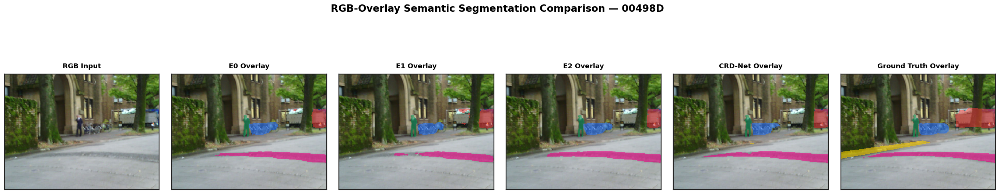

Saved PNG: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_overlay_comparison_00498D.png
Saved PDF: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_overlay_comparison_00498D.pdf


In [238]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# Existing TDD paths
ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
RGB_DIR = ROOT / "RGB"
THERMAL_DIR = ROOT / "Thermal"
LABEL_DIR = ROOT / "Label"

PRED_DIRS = {
    "E0": Path("/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"),
    "E1": Path("/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"),
    "E2": Path("/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"),
    "CRD-Net": Path("/home/cse-sdpl/Downloads/CRD_Net/predictions"),
}

OUT = Path("/home/cse-sdpl/Downloads/CRD_Net/comparison_results")
OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

# Same palette for every experiment
PALETTE = np.array([
    [25, 25, 25],       # Unlabeled
    [229, 57, 53],      # Car
    [25, 168, 91],      # Person
    [41, 121, 255],     # Bike
    [255, 214, 0],      # Curve
    [255, 109, 0],      # Car stop
    [142, 36, 170],     # Guardrail
    [0, 188, 212],      # Color cone
    [245, 0, 135],      # Bump
], dtype=np.uint8)

ALPHA = 0.58  # Increase to 0.70 for stronger segmentation colors

def locate(folder, image_id):
    stem = Path(image_id).stem
    for ext in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
        p = folder / (stem + ext)
        if p.exists():
            return p
    return None

def read_rgb(path):
    im = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def read_mask(path):
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if im is None:
        raise FileNotFoundError(path)
    if im.ndim == 3:
        if np.all(im[:, :, 0] == im[:, :, 1]) and np.all(im[:, :, 1] == im[:, :, 2]):
            im = im[:, :, 0]
        else:
            raise ValueError(
                f"{path} is color-encoded. Its class-color mapping is needed."
            )
    return im.astype(np.int32)

def colorize(mask):
    valid = (mask >= 0) & (mask < len(PALETTE))
    safe = np.where(valid, mask, 0)
    colors = PALETTE[safe].copy()
    colors[~valid] = [0, 0, 0]
    return colors

def overlay(rgb, mask):
    # Keep unlabeled/unknown pixels transparent.
    colored = colorize(mask)
    valid = (mask > 0) & (mask < len(PALETTE))
    result = rgb.astype(np.float32).copy()
    result[valid] = (
        (1 - ALPHA) * result[valid]
        + ALPHA * colored[valid].astype(np.float32)
    )
    return np.clip(result, 0, 255).astype(np.uint8)

with open(ROOT / "val.txt") as f:
    ids = [line.strip().split()[0] for line in f if line.strip()]

# Use the same sample as your diagnostic if available.
preferred_id = "00498D"
image_id = preferred_id if preferred_id in [Path(x).stem for x in ids] else ids[0]

rgb_path = locate(RGB_DIR, image_id)
gt_path = locate(LABEL_DIR, image_id)

if rgb_path is None or gt_path is None:
    raise FileNotFoundError(f"Missing RGB or GT for {image_id}")

rgb = read_rgb(rgb_path)
gt = read_mask(gt_path)

panels = [("RGB Input", rgb)]

for name, folder in PRED_DIRS.items():
    p = locate(folder, image_id)
    if p is None:
        raise FileNotFoundError(f"Missing {name} prediction for {image_id}")
    pred = read_mask(p)

    if pred.shape != gt.shape:
        pred = cv2.resize(
            pred.astype(np.float32),
            (gt.shape[1], gt.shape[0]),
            interpolation=cv2.INTER_NEAREST
        ).astype(np.int32)

    panels.append((f"{name} Overlay", overlay(rgb, pred)))

panels.append(("Ground Truth Overlay", overlay(rgb, gt)))

fig, axes = plt.subplots(
    1, len(panels),
    figsize=(23, 5),
    facecolor="white",
    squeeze=False
)
axes = axes[0]

for ax, (title, image) in zip(axes, panels):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#202020")
        spine.set_linewidth(1.4)

fig.suptitle(
    f"RGB-Overlay Semantic Segmentation Comparison — {image_id}",
    fontsize=16,
    fontweight="bold",
    y=1.02
)
fig.subplots_adjust(left=0.015, right=0.99, bottom=0.04, top=0.84, wspace=0.08)

png = OUT / f"CRD_overlay_comparison_{Path(image_id).stem}.png"
pdf = OUT / f"CRD_overlay_comparison_{Path(image_id).stem}.pdf"

fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(pdf, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved PNG:", png)
print("Saved PDF:", pdf)


Selected validation images:
 • 01057N
 • 00516D
 • 01041N
 • 01107N
 • 00524D


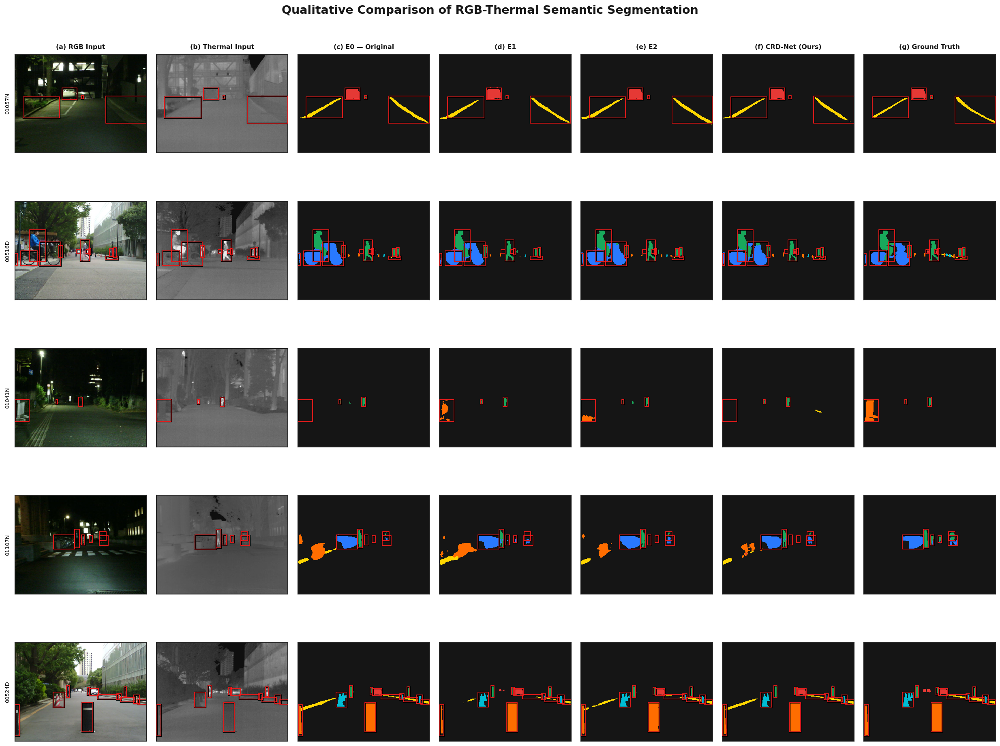


Figure saved successfully:
PNG: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_new_01057N_00516D_01041N_01107N_00524D.png
PDF: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_new_01057N_00516D_01041N_01107N_00524D.pdf


In [239]:

# ============================================================
# NEW PAPER FIGURE — DIFFERENT VALIDATION IMAGES
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# ============================================================

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")
RGB_DIR = ROOT / "RGB"
THERMAL_DIR = ROOT / "Thermal"
LABEL_DIR = ROOT / "Label"

PRED_DIRS = {
    "E0 — Original": Path(
        "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
    ),
    "E1": Path(
        "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
    ),
    "E2": Path(
        "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
    ),
    "CRD-Net (Ours)": Path(
        "/home/cse-sdpl/Downloads/CRD_Net/predictions"
    ),
}

OUT = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUT.mkdir(parents=True, exist_ok=True)

NUM_IMAGES = 5
RANDOM_SEED = 123  # Change this number to select another set
DPI = 300

CLASS_NAMES = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

# Keep this palette identical across every experiment
CLASS_COLORS = [
    "#151515", "#E53935", "#19A85B", "#2979FF", "#FFD600",
    "#FF6D00", "#8E24AA", "#00BCD4", "#F50087"
]

def locate(folder, image_id):
    stem = Path(image_id).stem
    for ext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        p = folder / (stem + ext)
        if p.exists():
            return p
    return None

def read_rgb(path):
    im = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def read_mask(path):
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if im is None:
        raise FileNotFoundError(path)

    if im.ndim == 3:
        if np.array_equal(im[:, :, 0], im[:, :, 1]) and \
           np.array_equal(im[:, :, 1], im[:, :, 2]):
            im = im[:, :, 0]
        else:
            raise ValueError(
                f"Color-encoded mask found at {path}. "
                "A class-color mapping is required."
            )
    return im.astype(np.int32)

def colorize(mask):
    palette = np.array(
        [[int(CLASS_COLORS[i].lstrip("#")[j:j+2], 16)
          for j in (0, 2, 4)] for i in range(len(CLASS_COLORS))],
        dtype=np.uint8
    )
    valid = (mask >= 0) & (mask < len(palette))
    safe = np.where(valid, mask, 0)
    result = palette[safe].copy()
    result[~valid] = [15, 15, 15]
    return result

def gt_boxes(mask):
    boxes = []
    for cls in range(1, len(CLASS_NAMES)):
        binary = (mask == cls).astype(np.uint8)
        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, 8
        )
        for i in range(1, count):
            x, y, w, h, area = stats[i]
            if area >= 80 and w >= 5 and h >= 5:
                boxes.append((x, y, w, h, area))
    boxes.sort(key=lambda b: b[4], reverse=True)
    return boxes[:12]

def add_boxes(ax, boxes):
    for x, y, w, h, _ in boxes:
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False, edgecolor="black",
            linewidth=2.0, zorder=10
        ))
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False, edgecolor="#FF2020",
            linewidth=1.0, zorder=11
        ))

with open(ROOT / "val.txt") as f:
    all_ids = [line.strip().split()[0] for line in f if line.strip()]

# Only use IDs available in every prediction folder
available = []
for image_id in all_ids:
    if not all(locate(folder, image_id) is not None
               for folder in [RGB_DIR, THERMAL_DIR, LABEL_DIR,
                              *PRED_DIRS.values()]):
        continue
    available.append(image_id)

# Exclude images used in the previous figure if known.
# Add any other previous image IDs to this set if desired.
PREVIOUS_IDS = {"00498D"}

candidates = [x for x in available if Path(x).stem not in PREVIOUS_IDS]

rng = random.Random(RANDOM_SEED)
rng.shuffle(candidates)
selected = candidates[:NUM_IMAGES]

if not selected:
    raise RuntimeError("No new complete validation images were found.")

print("Selected validation images:")
for image_id in selected:
    print(" •", image_id)

titles = [
    "(a) RGB Input",
    "(b) Thermal Input",
    "(c) E0 — Original",
    "(d) E1",
    "(e) E2",
    "(f) CRD-Net (Ours)",
    "(g) Ground Truth",
]

fig, axes = plt.subplots(
    len(selected), 7,
    figsize=(21, 3.25 * len(selected)),
    squeeze=False,
    facecolor="white"
)

fig.suptitle(
    "Qualitative Comparison of RGB-Thermal Semantic Segmentation",
    fontsize=17,
    fontweight="bold",
    y=0.985,
    color="#171717"
)

fig.subplots_adjust(
    left=0.035, right=0.995,
    top=0.94, bottom=0.035,
    wspace=0.075, hspace=0.16
)

for r, image_id in enumerate(selected):
    rgb = read_rgb(locate(RGB_DIR, image_id))
    thermal = read_rgb(locate(THERMAL_DIR, image_id))
    gt = read_mask(locate(LABEL_DIR, image_id))

    h, w = gt.shape

    if rgb.shape[:2] != (h, w):
        rgb = cv2.resize(rgb, (w, h), interpolation=cv2.INTER_LINEAR)
    if thermal.shape[:2] != (h, w):
        thermal = cv2.resize(
            thermal, (w, h), interpolation=cv2.INTER_LINEAR
        )

    boxes = gt_boxes(gt)

    panels = [rgb, thermal]

    for model_name, folder in PRED_DIRS.items():
        pred = read_mask(locate(folder, image_id))
        if pred.shape != (h, w):
            pred = cv2.resize(
                pred.astype(np.float32), (w, h),
                interpolation=cv2.INTER_NEAREST
            ).astype(np.int32)
        panels.append(colorize(pred))

    panels.append(colorize(gt))

    for c, panel in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(panel, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#222222")
            spine.set_linewidth(1.25)

        if r == 0:
            ax.set_title(
                titles[c],
                fontsize=9.5,
                fontweight="bold",
                pad=8,
                color="#171717"
            )

        if c == 0:
            ax.set_ylabel(
                Path(image_id).stem,
                fontsize=8,
                rotation=90,
                labelpad=7
            )

        # Use the same GT-derived boxes on all panels in this row
        add_boxes(ax, boxes)

# Save high-resolution image and vector PDF
id_tag = "_".join(Path(x).stem for x in selected)
png_path = OUT / f"CRD_paper_comparison_new_{id_tag}.png"
pdf_path = OUT / f"CRD_paper_comparison_new_{id_tag}.pdf"

fig.savefig(
    png_path, dpi=DPI, bbox_inches="tight",
    facecolor="white", pad_inches=0.12
)
fig.savefig(
    pdf_path, bbox_inches="tight",
    facecolor="white", pad_inches=0.12
)

plt.show()

print("\nFigure saved successfully:")
print("PNG:", png_path)
print("PDF:", pdf_path)


SELECTED VALIDATION IMAGES
   01057N
   00516D
   01041N
   01107N
   00524D


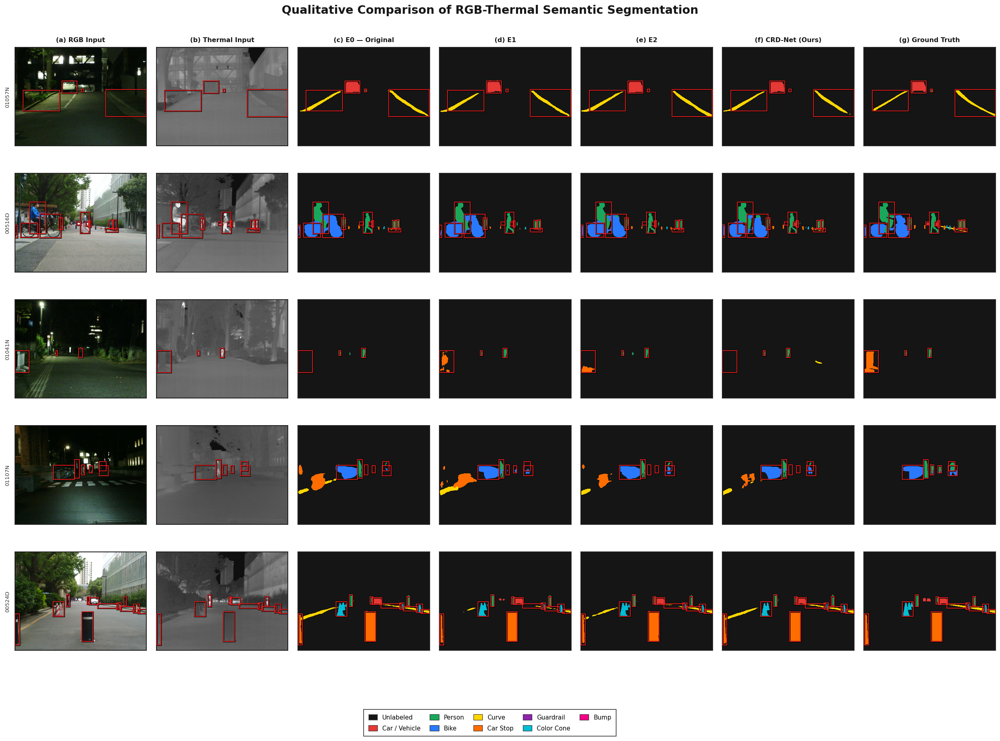


PUBLICATION FIGURE GENERATED
Images displayed : 5
Model columns    : 4
Total columns    : 7
PNG output       : /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_legend_01057N_00516D_01041N_01107N_00524D.png
PDF output       : /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_comparison_legend_01057N_00516D_01041N_01107N_00524D.pdf

Class-color legend included.
Each panel has its own border.
GT-derived bounding boxes are shared across each row.
All segmentation panels use the same class palette.

Note: Unlabeled is not a separate building class.


In [240]:

# =====================================================================
# PUBLICATION-STYLE RGB-THERMAL SEMANTIC SEGMENTATION COMPARISON
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# Includes: separate panel borders, GT boxes, class legend, PNG + PDF
# =====================================================================

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# ============================ PATHS ==================================

ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = ROOT / "RGB"
THERMAL_DIR = ROOT / "Thermal"
LABEL_DIR = ROOT / "Label"
VAL_FILE = ROOT / "val.txt"

PRED_DIRS = {
    "E0 — Original": Path(
        "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
    ),
    "E1": Path(
        "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
    ),
    "E2": Path(
        "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
    ),
    "CRD-Net (Ours)": Path(
        "/home/cse-sdpl/Downloads/CRD_Net/predictions"
    ),
}

OUTPUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ======================= DISPLAY SETTINGS ============================

NUM_IMAGES = 5
RANDOM_SEED = 123       # Change this value for a different image set
DPI = 300

DRAW_GT_BOXES = True
MIN_BOX_AREA = 80
MAX_BOXES_PER_IMAGE = 12

# Previously used image IDs to exclude from this new figure.
# Add more IDs here if you want to avoid previously generated samples.
PREVIOUS_IDS = {"00498D"}

# ========================== CLASS COLORS =============================

CLASS_NAMES = [
    "Unlabeled",
    "Car",
    "Person",
    "Bike",
    "Curve",
    "Car stop",
    "Guardrail",
    "Color cone",
    "Bump",
]

# Fixed palette shared by all experiments and the ground truth.
CLASS_COLORS = [
    "#151515",  # 0 - Unlabeled
    "#E53935",  # 1 - Car
    "#19A85B",  # 2 - Person
    "#2979FF",  # 3 - Bike
    "#FFD600",  # 4 - Curve
    "#FF6D00",  # 5 - Car stop
    "#8E24AA",  # 6 - Guardrail
    "#00BCD4",  # 7 - Color cone
    "#F50087",  # 8 - Bump
]

NUM_CLASSES = len(CLASS_NAMES)

PALETTE_RGB = np.array([
    [int(CLASS_COLORS[i].lstrip("#")[j:j+2], 16)
     for j in (0, 2, 4)]
    for i in range(NUM_CLASSES)
], dtype=np.uint8)

# ========================== FILE HELPERS =============================

def locate(folder, image_id):
    """Find an image using its stem and common extensions."""
    folder = Path(folder)
    stem = Path(str(image_id)).stem

    for ext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            return candidate

    # Case-insensitive fallback
    if folder.exists():
        for candidate in folder.iterdir():
            if (
                candidate.is_file()
                and candidate.stem.lower() == stem.lower()
                and candidate.suffix.lower() in {
                    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
                }
            ):
                return candidate

    return None


def read_rgb(path):
    """Read an image as RGB."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def read_mask(path):
    """
    Read a class-index mask.
    Multichannel masks are accepted only when all channels are identical.
    """
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise FileNotFoundError(f"Could not read mask: {path}")

    if image.ndim == 2:
        mask = image

    elif image.ndim == 3 and image.shape[2] == 1:
        mask = image[:, :, 0]

    elif image.ndim == 3:
        if (
            np.array_equal(image[:, :, 0], image[:, :, 1])
            and np.array_equal(image[:, :, 1], image[:, :, 2])
        ):
            mask = image[:, :, 0]
        else:
            raise ValueError(
                f"Mask is color-encoded rather than class-indexed:\n{path}\n"
                "A source-specific color-to-class mapping is required."
            )
    else:
        raise ValueError(f"Unexpected mask shape: {image.shape}")

    return mask.astype(np.int32)


def colorize_mask(mask):
    """Map class IDs to the fixed RGB palette."""
    valid = (mask >= 0) & (mask < NUM_CLASSES)
    safe_mask = np.where(valid, mask, 0)

    colored = PALETTE_RGB[safe_mask].copy()
    colored[~valid] = [15, 15, 15]

    return colored


def resize_mask_nearest(mask, target_shape):
    """Resize labels without creating artificial intermediate classes."""
    target_h, target_w = target_shape

    if mask.shape != (target_h, target_w):
        mask = cv2.resize(
            mask.astype(np.float32),
            (target_w, target_h),
            interpolation=cv2.INTER_NEAREST
        ).astype(np.int32)

    return mask


# ======================= GROUND-TRUTH BOXES ==========================

def find_gt_boxes(mask):
    """
    Find connected components from labeled ground-truth classes.
    Unlabeled pixels are excluded. Boxes are reused across every panel.
    """
    boxes = []

    for class_id in range(1, NUM_CLASSES):
        binary = (mask == class_id).astype(np.uint8)

        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for idx in range(1, count):
            x, y, w, h, area = stats[idx]

            if area < MIN_BOX_AREA or w < 5 or h < 5:
                continue

            boxes.append((
                int(x), int(y), int(w), int(h), int(area)
            ))

    boxes.sort(key=lambda item: item[4], reverse=True)

    return boxes[:MAX_BOXES_PER_IMAGE]


def draw_boxes(ax, boxes, image_shape):
    """Draw clear double-stroke red boxes on a panel."""
    height, width = image_shape[:2]

    for x, y, w, h, _ in boxes:
        x = max(0, x)
        y = max(0, y)
        w = min(w, width - x)
        h = min(h, height - y)

        if w <= 0 or h <= 0:
            continue

        # Dark outline helps the red box remain visible on bright colors.
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="black",
            linewidth=2.0,
            zorder=10
        ))

        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="#FF2020",
            linewidth=1.0,
            zorder=11
        ))


# ====================== VALIDATION IMAGE SELECTION ===================

if not VAL_FILE.exists():
    raise FileNotFoundError(f"Validation file not found: {VAL_FILE}")

with open(VAL_FILE, "r") as file:
    validation_ids = [
        line.strip().split()[0]
        for line in file
        if line.strip()
    ]

available_ids = []

for image_id in validation_ids:
    if Path(image_id).stem in PREVIOUS_IDS:
        continue

    required_files = [
        locate(RGB_DIR, image_id),
        locate(THERMAL_DIR, image_id),
        locate(LABEL_DIR, image_id),
    ]

    required_files += [
        locate(folder, image_id)
        for folder in PRED_DIRS.values()
    ]

    if all(path is not None for path in required_files):
        available_ids.append(image_id)

if len(available_ids) < NUM_IMAGES:
    raise RuntimeError(
        f"Only {len(available_ids)} complete images are available "
        f"after exclusions, but NUM_IMAGES={NUM_IMAGES}. "
        "Reduce NUM_IMAGES or remove some IDs from PREVIOUS_IDS."
    )

rng = random.Random(RANDOM_SEED)
rng.shuffle(available_ids)
selected_ids = available_ids[:NUM_IMAGES]

print("=" * 72)
print("SELECTED VALIDATION IMAGES")
print("=" * 72)

for image_id in selected_ids:
    print("  ", image_id)

# ======================== FIGURE LAYOUT ==============================

COLUMN_TITLES = [
    "(a) RGB Input",
    "(b) Thermal Input",
    "(c) E0 — Original",
    "(d) E1",
    "(e) E2",
    "(f) CRD-Net (Ours)",
    "(g) Ground Truth",
]

num_rows = len(selected_ids)
num_cols = len(COLUMN_TITLES)

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(21, 3.15 * num_rows),
    squeeze=False,
    facecolor="white"
)

fig.suptitle(
    "Qualitative Comparison of RGB-Thermal Semantic Segmentation",
    fontsize=17,
    fontweight="bold",
    color="#171717",
    y=0.985
)

# Reserve bottom space for the class legend.
fig.subplots_adjust(
    left=0.035,
    right=0.995,
    top=0.935,
    bottom=0.135,
    wspace=0.075,
    hspace=0.17
)

# ========================== DRAW PANELS ===============================

for row_idx, image_id in enumerate(selected_ids):

    # Load source modalities and ground truth.
    rgb = read_rgb(locate(RGB_DIR, image_id))
    thermal = read_rgb(locate(THERMAL_DIR, image_id))
    gt_mask = read_mask(locate(LABEL_DIR, image_id))

    height, width = gt_mask.shape

    if rgb.shape[:2] != (height, width):
        rgb = cv2.resize(
            rgb, (width, height), interpolation=cv2.INTER_LINEAR
        )

    if thermal.shape[:2] != (height, width):
        thermal = cv2.resize(
            thermal, (width, height), interpolation=cv2.INTER_LINEAR
        )

    # Use the same GT-derived boxes across every panel in this row.
    boxes = find_gt_boxes(gt_mask) if DRAW_GT_BOXES else []

    panels = [
        ("rgb", rgb),
        ("thermal", thermal),
    ]

    # Model prediction panels in fixed order.
    for model_name, prediction_folder in PRED_DIRS.items():
        pred_path = locate(prediction_folder, image_id)
        pred_mask = read_mask(pred_path)
        pred_mask = resize_mask_nearest(pred_mask, (height, width))

        panels.append(("segmentation", colorize_mask(pred_mask)))

    # Ground-truth segmentation panel.
    panels.append(("segmentation", colorize_mask(gt_mask)))

    for col_idx, (panel_type, panel_image) in enumerate(panels):
        ax = axes[row_idx, col_idx]

        ax.imshow(panel_image, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_facecolor("white")

        # Individual rectangular border for every panel.
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#202020")
            spine.set_linewidth(1.25)

        # Column titles only on the top row.
        if row_idx == 0:
            ax.set_title(
                COLUMN_TITLES[col_idx],
                fontsize=9.5,
                fontweight="bold",
                color="#171717",
                pad=8
            )

        # Image ID at the left side of each row.
        if col_idx == 0:
            ax.set_ylabel(
                Path(image_id).stem,
                fontsize=8,
                rotation=90,
                labelpad=7,
                color="#333333"
            )

        if DRAW_GT_BOXES:
            draw_boxes(ax, boxes, (height, width))

# =========================== CLASS LEGEND ============================

legend_labels = [
    "Unlabeled",
    "Car / Vehicle",
    "Person",
    "Bike",
    "Curve",
    "Car Stop",
    "Guardrail",
    "Color Cone",
    "Bump",
]

legend_handles = []

for color, label in zip(CLASS_COLORS, legend_labels):
    # The unlabeled class is black; white edge makes its swatch visible.
    legend_handles.append(
        Patch(
            facecolor=color,
            edgecolor="#777777" if label == "Unlabeled" else "#333333",
            linewidth=0.7,
            label=label
        )
    )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=5,
    fontsize=9,
    frameon=True,
    fancybox=False,
    edgecolor="#333333",
    facecolor="white",
    framealpha=1.0,
    handlelength=1.5,
    handleheight=1.0,
    columnspacing=1.5,
    labelspacing=0.8,
    borderpad=0.8
)

# ============================ SAVE ===================================

id_tag = "_".join(Path(image_id).stem for image_id in selected_ids)

png_path = OUTPUT_DIR / f"CRD_paper_comparison_legend_{id_tag}.png"
pdf_path = OUTPUT_DIR / f"CRD_paper_comparison_legend_{id_tag}.pdf"

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.15
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.15
)

plt.show()

print("\n" + "=" * 72)
print("PUBLICATION FIGURE GENERATED")
print("=" * 72)
print(f"Images displayed : {len(selected_ids)}")
print(f"Model columns    : {len(PRED_DIRS)}")
print(f"Total columns    : {num_cols}")
print(f"PNG output       : {png_path}")
print(f"PDF output       : {pdf_path}")
print("\nClass-color legend included.")
print("Each panel has its own border.")
print("GT-derived bounding boxes are shared across each row.")
print("All segmentation panels use the same class palette.")
print("\nNote: Unlabeled is not a separate building class.")


NEW VALIDATION IMAGE SET
   00564D
   01093N
   00599D
   01118N
   00654D


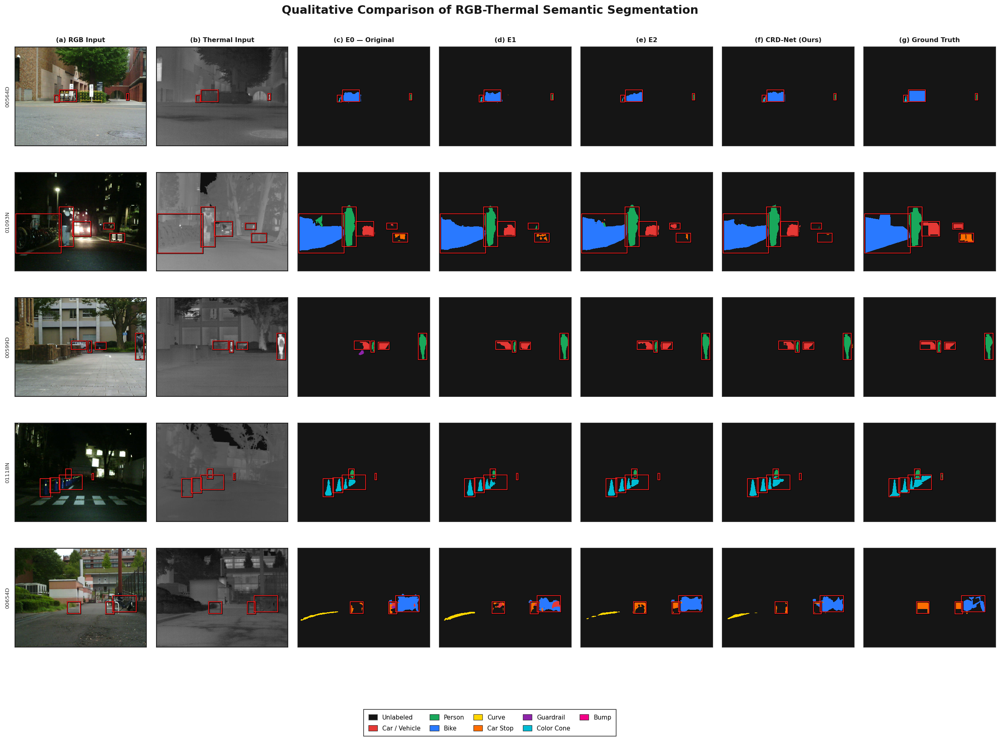


NEW RESEARCH-PAPER FIGURE GENERATED
Number of images : 5
Number of columns: 7
Random seed      : 456

Selected image IDs:
   00564D
   01093N
   00599D
   01118N
   00654D

Saved files:
PNG: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_new_images_00564D_01093N_00599D_01118N_00654D.png
PDF: /home/cse-sdpl/Downloads/CRD_Net/comparison_results/CRD_paper_new_images_00564D_01093N_00599D_01118N_00654D.pdf

Included:
  - RGB and thermal inputs
  - E0, E1, E2, and CRD-Net predictions
  - Ground-truth segmentation
  - Individual panel borders
  - Ground-truth-derived bounding boxes
  - Nine-class color legend
  - 300 DPI PNG and vector PDF

Reminder: Unlabeled is not a building class.


In [241]:

# =====================================================================
# RESEARCH-PAPER FIGURE: NEW VALIDATION IMAGES
# RGB | Thermal | E0 | E1 | E2 | CRD-Net | Ground Truth
# Individual borders + GT boxes + class legend + PNG/PDF export
# =====================================================================

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# ============================= PATHS ================================

ROOT = Path("/home/cse-sdpl/Downloads/CMX_Original/datasets/TDD")

RGB_DIR = ROOT / "RGB"
THERMAL_DIR = ROOT / "Thermal"
LABEL_DIR = ROOT / "Label"
VAL_FILE = ROOT / "val.txt"

PRED_DIRS = {
    "E0 — Original": Path(
        "/home/cse-sdpl/Downloads/CMX_Original/predictions_TDD_epoch100"
    ),
    "E1": Path(
        "/home/cse-sdpl/Downloads/CMX_E1/e1_predictions"
    ),
    "E2": Path(
        "/home/cse-sdpl/Downloads/CMX_E2/predictions_TDD_E2_epoch100"
    ),
    "CRD-Net (Ours)": Path(
        "/home/cse-sdpl/Downloads/CRD_Net/predictions"
    ),
}

OUTPUT_DIR = Path(
    "/home/cse-sdpl/Downloads/CRD_Net/comparison_results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ======================== FIGURE SETTINGS ===========================

NUM_IMAGES = 5
RANDOM_SEED = 456
DPI = 300

DRAW_GT_BOXES = True
MIN_BOX_AREA = 80
MAX_BOXES_PER_IMAGE = 12

# IMPORTANT:
# Add IDs printed by any earlier figure to prevent reuse.
# These are image IDs, not prediction filenames.
PREVIOUS_IDS = {
    "00498D",
    # Add IDs from your previous figures here, for example:
    # "00623D",
    # "01154M",
    # "00311M",
    # "00570D",
}

# =========================== CLASS COLORS ===========================

CLASS_NAMES = [
    "Unlabeled",
    "Car",
    "Person",
    "Bike",
    "Curve",
    "Car stop",
    "Guardrail",
    "Color cone",
    "Bump",
]

CLASS_COLORS = [
    "#151515",  # 0 - Unlabeled
    "#E53935",  # 1 - Car
    "#19A85B",  # 2 - Person
    "#2979FF",  # 3 - Bike
    "#FFD600",  # 4 - Curve
    "#FF6D00",  # 5 - Car stop
    "#8E24AA",  # 6 - Guardrail
    "#00BCD4",  # 7 - Color cone
    "#F50087",  # 8 - Bump
]

NUM_CLASSES = len(CLASS_NAMES)

PALETTE_RGB = np.array([
    [int(CLASS_COLORS[i].lstrip("#")[j:j + 2], 16)
     for j in (0, 2, 4)]
    for i in range(NUM_CLASSES)
], dtype=np.uint8)

# =========================== FILE HELPERS ===========================

def locate(folder, image_id):
    """Locate a file by image ID, supporting common extensions."""
    folder = Path(folder)
    stem = Path(str(image_id)).stem

    for ext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        candidate = folder / f"{stem}{ext}"
        if candidate.exists():
            return candidate

    if folder.exists():
        for candidate in folder.iterdir():
            if (
                candidate.is_file()
                and candidate.stem.lower() == stem.lower()
                and candidate.suffix.lower() in {
                    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
                }
            ):
                return candidate

    return None


def read_rgb(path):
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def read_mask(path):
    """
    Read an indexed segmentation mask.
    RGB-encoded masks require an explicit color-to-class mapping.
    """
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise FileNotFoundError(f"Could not read mask: {path}")

    if image.ndim == 2:
        mask = image

    elif image.ndim == 3 and image.shape[2] == 1:
        mask = image[:, :, 0]

    elif image.ndim == 3:
        if (
            np.array_equal(image[:, :, 0], image[:, :, 1])
            and np.array_equal(image[:, :, 1], image[:, :, 2])
        ):
            mask = image[:, :, 0]
        else:
            raise ValueError(
                f"Color-encoded mask encountered: {path}\n"
                "A class-color mapping is required before visualization."
            )

    else:
        raise ValueError(f"Unexpected mask shape: {image.shape}")

    return mask.astype(np.int32)


def resize_mask(mask, target_shape):
    """Resize masks with nearest-neighbor interpolation."""
    height, width = target_shape

    if mask.shape != (height, width):
        mask = cv2.resize(
            mask.astype(np.float32),
            (width, height),
            interpolation=cv2.INTER_NEAREST
        ).astype(np.int32)

    return mask


def colorize_mask(mask):
    """Convert class IDs into the fixed class-color palette."""
    valid = (mask >= 0) & (mask < NUM_CLASSES)
    safe = np.where(valid, mask, 0)

    colored = PALETTE_RGB[safe].copy()
    colored[~valid] = [15, 15, 15]

    return colored


# ======================= GROUND-TRUTH BOXES =========================

def find_gt_boxes(mask):
    """
    Derive bounding boxes from ground-truth connected components.
    The same boxes will be displayed on every panel in the row.
    """
    boxes = []

    for class_id in range(1, NUM_CLASSES):
        binary = (mask == class_id).astype(np.uint8)

        count, _, stats, _ = cv2.connectedComponentsWithStats(
            binary, connectivity=8
        )

        for idx in range(1, count):
            x, y, w, h, area = stats[idx]

            if area < MIN_BOX_AREA or w < 5 or h < 5:
                continue

            boxes.append((
                int(x), int(y), int(w), int(h), int(area)
            ))

    boxes.sort(key=lambda item: item[4], reverse=True)

    return boxes[:MAX_BOXES_PER_IMAGE]


def draw_boxes(ax, boxes, image_shape):
    """Draw visible double-stroke red boxes."""
    height, width = image_shape[:2]

    for x, y, w, h, _ in boxes:
        x = max(0, x)
        y = max(0, y)
        w = min(w, width - x)
        h = min(h, height - y)

        if w <= 0 or h <= 0:
            continue

        # Black outer outline
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="black",
            linewidth=2.0,
            zorder=10
        ))

        # Red inner outline
        ax.add_patch(Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="#FF2020",
            linewidth=1.0,
            zorder=11
        ))


# ========================= SELECT NEW IMAGES ========================

if not VAL_FILE.exists():
    raise FileNotFoundError(f"Validation list missing: {VAL_FILE}")

with open(VAL_FILE, "r") as file:
    validation_ids = [
        line.strip().split()[0]
        for line in file
        if line.strip()
    ]

previous_stems = {Path(x).stem for x in PREVIOUS_IDS}
available_ids = []

for image_id in validation_ids:
    stem = Path(image_id).stem

    if stem in previous_stems:
        continue

    # Require all source files and all four model predictions.
    required_paths = [
        locate(RGB_DIR, image_id),
        locate(THERMAL_DIR, image_id),
        locate(LABEL_DIR, image_id),
    ]

    required_paths.extend(
        locate(folder, image_id)
        for folder in PRED_DIRS.values()
    )

    if all(path is not None for path in required_paths):
        available_ids.append(image_id)

if len(available_ids) < NUM_IMAGES:
    raise RuntimeError(
        f"Only {len(available_ids)} unused complete samples remain. "
        f"Requested {NUM_IMAGES}. Remove some entries from PREVIOUS_IDS "
        "or reduce NUM_IMAGES."
    )

rng = random.Random(RANDOM_SEED)
rng.shuffle(available_ids)

selected_ids = available_ids[:NUM_IMAGES]

print("=" * 70)
print("NEW VALIDATION IMAGE SET")
print("=" * 70)

for image_id in selected_ids:
    print("  ", image_id)

# ========================== FIGURE LAYOUT ===========================

COLUMN_TITLES = [
    "(a) RGB Input",
    "(b) Thermal Input",
    "(c) E0 — Original",
    "(d) E1",
    "(e) E2",
    "(f) CRD-Net (Ours)",
    "(g) Ground Truth",
]

num_rows = len(selected_ids)
num_cols = len(COLUMN_TITLES)

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(21, 3.15 * num_rows),
    squeeze=False,
    facecolor="white"
)

fig.suptitle(
    "Qualitative Comparison of RGB-Thermal Semantic Segmentation",
    fontsize=17,
    fontweight="bold",
    color="#171717",
    y=0.985
)

# Leave space at the bottom for the class legend.
fig.subplots_adjust(
    left=0.035,
    right=0.995,
    top=0.935,
    bottom=0.14,
    wspace=0.075,
    hspace=0.17
)

# ============================= DRAW =================================

for row_idx, image_id in enumerate(selected_ids):

    rgb = read_rgb(locate(RGB_DIR, image_id))
    thermal = read_rgb(locate(THERMAL_DIR, image_id))
    gt_mask = read_mask(locate(LABEL_DIR, image_id))

    height, width = gt_mask.shape

    if rgb.shape[:2] != (height, width):
        rgb = cv2.resize(
            rgb, (width, height), interpolation=cv2.INTER_LINEAR
        )

    if thermal.shape[:2] != (height, width):
        thermal = cv2.resize(
            thermal, (width, height), interpolation=cv2.INTER_LINEAR
        )

    boxes = find_gt_boxes(gt_mask) if DRAW_GT_BOXES else []

    # Source modality panels.
    panels = [rgb, thermal]

    # Prediction panels in fixed order.
    for model_name, folder in PRED_DIRS.items():
        pred_path = locate(folder, image_id)
        pred_mask = read_mask(pred_path)
        pred_mask = resize_mask(pred_mask, (height, width))
        panels.append(colorize_mask(pred_mask))

    # Ground truth panel.
    panels.append(colorize_mask(gt_mask))

    for col_idx, panel_image in enumerate(panels):
        ax = axes[row_idx, col_idx]

        ax.imshow(panel_image, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_facecolor("white")

        # Individual border for every image panel.
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("#202020")
            spine.set_linewidth(1.25)

        # Column headings on the first row.
        if row_idx == 0:
            ax.set_title(
                COLUMN_TITLES[col_idx],
                fontsize=9.5,
                fontweight="bold",
                color="#171717",
                pad=8
            )

        # Sample ID beside the row.
        if col_idx == 0:
            ax.set_ylabel(
                Path(image_id).stem,
                fontsize=8,
                rotation=90,
                labelpad=7,
                color="#333333"
            )

        if DRAW_GT_BOXES:
            draw_boxes(ax, boxes, (height, width))

# ========================== CLASS LEGEND ============================

LEGEND_LABELS = [
    "Unlabeled",
    "Car / Vehicle",
    "Person",
    "Bike",
    "Curve",
    "Car Stop",
    "Guardrail",
    "Color Cone",
    "Bump",
]

legend_handles = []

for color, label in zip(CLASS_COLORS, LEGEND_LABELS):
    edge = "#777777" if label == "Unlabeled" else "#333333"

    legend_handles.append(
        Patch(
            facecolor=color,
            edgecolor=edge,
            linewidth=0.7,
            label=label
        )
    )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=5,
    fontsize=9,
    frameon=True,
    fancybox=False,
    edgecolor="#333333",
    facecolor="white",
    framealpha=1.0,
    handlelength=1.5,
    handleheight=1.0,
    columnspacing=1.5,
    labelspacing=0.8,
    borderpad=0.8
)

# ============================= SAVE =================================

id_tag = "_".join(Path(x).stem for x in selected_ids)

png_path = OUTPUT_DIR / f"CRD_paper_new_images_{id_tag}.png"
pdf_path = OUTPUT_DIR / f"CRD_paper_new_images_{id_tag}.pdf"

fig.savefig(
    png_path,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.15
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.15
)

plt.show()

# ============================ SUMMARY ================================

print("\n" + "=" * 70)
print("NEW RESEARCH-PAPER FIGURE GENERATED")
print("=" * 70)
print(f"Number of images : {len(selected_ids)}")
print(f"Number of columns: {num_cols}")
print(f"Random seed      : {RANDOM_SEED}")
print("\nSelected image IDs:")
for image_id in selected_ids:
    print("  ", image_id)

print("\nSaved files:")
print("PNG:", png_path)
print("PDF:", pdf_path)

print("\nIncluded:")
print("  - RGB and thermal inputs")
print("  - E0, E1, E2, and CRD-Net predictions")
print("  - Ground-truth segmentation")
print("  - Individual panel borders")
print("  - Ground-truth-derived bounding boxes")
print("  - Nine-class color legend")
print("  - 300 DPI PNG and vector PDF")
print("\nReminder: Unlabeled is not a building class.")
